# VedgeSat driver: New Zealand (default vs NZ classifier)

A copy of the VedgeSat driver for comparing the **default** vegetation classifier (`MLPClassifier_Veg_L5L8S2.pkl`) with the retrained **NZ** classifiers on the same site, dates and settings. No VedgeSat (`Toolshed`) file is edited; the original driver is left as it was.

**How runs are kept apart.** Every run writes to its own folder, `Data/<SITE>_<PERIOD>_<MODEL>`, e.g. `Data/Pakiri_2015-2025_default` and `Data/Pakiri_2015-2025_NZ`. The classifier (`MODEL`) is the only thing that changes between runs of the same `SITE` and `PERIOD`. Cells added or changed for the NZ workflow are marked **(NZ)**.

**Workflow for one site**

1. In <font color='red'>User requirements</font>, set `SITE`, `PERIOD`, the dates and `MODEL = 'default'`. Run from the top to **Save Veglines as Local Shapefiles**, using Option 1 extraction. In `check_detection`, reject an image only for problems with the image itself (cloud, shadow, a bad scene), never because the edge looks worse.
2. Set `MODEL = 'NZ'` and run the same cells again. Nothing else changes.
3. Run **Compare runs (NZ)**. It checks the settings match, lists images kept in one run but not the other, and saves the images common to both.
4. For each model in turn, **default first**: set `MODEL`, run the setup cells down to the reference line load-in, skip Option 1, run **Option 2** load-in, then transects, intersections, plots and validation. Every run uses the default run's transects and only the common images, so the models are compared like for like.

---

**To run a code block, click in a cell, hold down shift, and press enter.** The order in which you execute the code blocks matters. If the heading above a cell is <font color='red'>IN RED</font>, edit that cell with your own requirements and settings. Lines starting with `#` are comments.


### Import Python packages/modules
Load in the packages we'll need for running the tool.

In [1]:
%load_ext autoreload
%autoreload 2
import os
import glob
import pickle
import pandas as pd
import warnings
warnings.filterwarnings("ignore")
import matplotlib
matplotlib.use('Qt5Agg')
import matplotlib.pyplot as plt
plt.ion()
from datetime import datetime
from Toolshed import Download, Toolbox, VegetationLine, Plotting, PlottingSeaborn, Transects
import ee
import geopandas as gpd
import geemap

ee.Initialize(project='civic-ripsaw-454707-c4')
#ee.Authenticate() # should only need to be run the first time after installation
%gui qt5

In [14]:
# =====================================================================================
# (NZ) Pakiri sparse-vegetation zone runs: the closest S2 and L8 image to the 2023-04-04 NZCCD line x 6 scenarios (6 runs)
# =====================================================================================
# A stand-alone copy of the batch cell for the southern sparse zone at Pakiri only. It uses its own
# reference line (PakiriSparse_refLine.shp, in Data/referenceLines) and the same images and NZCCD lines
# as Pakiri's 2023-04-04 line, the only NZCCD line that traces the sparse front. Only these 6 runs are
# processed: the main batch runs and their outputs are not touched.
# The images are fetched for this smaller AOI (new pixel-cache entries) and classified in each run,
# as in any run.
#
# Paste into a new cell after the "Import Python packages/modules" cell and run it on its own.
# Outputs:
#   run folders  Data/BatchS_PakiriSparse_<NZCCD date>_<scenario>   (new folders; VedgeSat keeps run
#                folders directly in Data)
#   run log      Data/Extra_analyses/PakiriSparse_log.csv
# Weighted Peaks is seeded exactly as in the batch, so results are reproducible; no extra draws are
# recorded. A run whose output already exists is skipped, so if the kernel stops, run the cell again.
# Score the runs with PakiriSparse_comparison_cell.py.

import time, traceback, hashlib, glob, shutil
import numpy as np
from importlib import reload
import image_lists; reload(image_lists)
from image_lists import IMAGES
# the 2023 line's image closest in time to the NZCCD date, per satellite (S2 2023-04-13, +9 days;
# L8 2023-05-16, +42 days): the sparse front is a mobile, post-Cyclone Gabrielle sand bar
BUFFER = 200            # m, reference-line buffer (max_dist_ref). Set the SAME value in the runs, comparison and
                        # violin cells. Rerunning replaces the previous results (one set of files only).
SITE = 'PakiriSparse'
IMAGES = {SITE: {'2023-04-04': {sat: [min(lst, key=lambda i: abs(i[2]))]
                                         for sat, lst in IMAGES['Pakiri']['2023-04-04'].items()}}}
from Toolshed import Image_Processing, VegetationLine, Toolbox

# ---------------- EDIT ME ----------------
TAG = 'BatchS'                      # prefix for every run folder (no spaces); 'S' = seeded
SEED = 0                            # fixed seed for VedgeSat's random class balancing (see below)
N_DRAWS = 0                         # extra Weighted Peaks thresholds per image with seeds 1..N_DRAWS, recorded
                                    # in the _WP runs only, to measure how much the random step moves the
                                    # threshold. Doesn't change the edges. Set 0 to skip (faster).
PIXEL_CACHE = os.path.join('Data', 'pixel_cache')   # each image's pixels are fetched from Earth Engine once and
                                    # reused by every scenario, so all six scenarios see identical data
TEST_RUN = False                     # True: do ONE run only (first site, first line, VedgeSat WP) and stop,
                                    # so you can check its edges in QGIS. Then set False for the full batch.
SITES = {                           # reference line (in Data/referenceLines) and buffer (max_dist_ref, m)
    SITE: {'refline': 'PakiriSparse_refLine.shp', 'max_dist_ref': BUFFER},
}
SCENARIOS = [                       # (label used in folder names, classifier file or None, local threshold?)
    ('default_WP',     None,                                  False),
    ('default_local',  None,                                  True),
    ('NZ_WP',          'MLPClassifier_Veg_L8S2_NZ.pkl',       False),
    ('NZ_local',       'MLPClassifier_Veg_L8S2_NZ.pkl',       True),
    ('NZsparse_WP',    'MLPClassifier_Veg_L8S2_NZsparse.pkl', False),
    ('NZsparse_local', 'MLPClassifier_Veg_L8S2_NZsparse.pkl', True),
]
LOCAL_STRIP_M = 60                  # local threshold strip half-width (m); set before validation, not tuned
CLOUD_THRESH = 1.0                  # images were checked by eye; VedgeSat's scene-wide cloud filter would reject clear AOIs
RETRIES = 2                         # retries per run after a failure (e.g. an Earth Engine timeout)
RETRY_WAIT_S = 60                   # seconds to wait before each retry
WINDOW_DAYS = 90                    # recorded as the run's date range only; the images come from image_lists.py
# ------------------------------------------
EXTRA = os.path.join('Data', 'Extra_analyses')
os.makedirs(EXTRA, exist_ok=True)

# Classifier switch (same wrapper as the "Vegetation classifier (NZ)" cell): settings['veg_clf_model']
# decides the L8/S2 classifier; None keeps VedgeSat's default.
for _, clf, _ in SCENARIOS:
    if clf:
        assert os.path.isfile(os.path.join(os.getcwd(), 'Classification', 'models', clf)), f'Model not found: {clf}'
if not hasattr(Image_Processing, '_vedgesat_InitialiseImgs'):
    Image_Processing._vedgesat_InitialiseImgs = Image_Processing.InitialiseImgs
def _init_with_chosen_model(metadata, settings, satname, imgs):
    pixel_size, clf_model, ImgColl, init_georef = Image_Processing._vedgesat_InitialiseImgs(metadata, settings, satname, imgs)
    if satname in ['L8', 'S2'] and settings.get('veg_clf_model'):
        clf_model = settings['veg_clf_model']
    print(f'{satname}: vegetation classifier = {clf_model}')
    return pixel_size, clf_model, ImgColl, init_georef
Image_Processing.InitialiseImgs = _init_with_chosen_model

# Pixel cache: Earth Engine can return very slightly different pixel values for the same image on
# different requests, which is enough to tip VedgeSat's Weighted Peaks peak choice. Fetching each
# image once and reusing the saved array makes every scenario (and any rerun) use identical pixels.
os.makedirs(PIXEL_CACHE, exist_ok=True)
if not hasattr(Image_Processing, '_vedgesat_GetGridPixels'):
    Image_Processing._vedgesat_GetGridPixels = Image_Processing.GetGridPixels
def _cached_GetGridPixels(img, bands, georef, settings, scale):
    img_id = ee.Image(img).id().getInfo()
    bounds = [round(float(v), 1) for v in Toolbox.AOIBoundsUTM(settings)]
    key = f"{img_id}|{','.join(bands)}|{scale}|{[round(float(v), 3) for v in georef]}|{bounds}"
    fn = os.path.join(PIXEL_CACHE, hashlib.md5(key.encode()).hexdigest() + '.npy')
    if os.path.isfile(fn):
        return np.load(fn)
    im = Image_Processing._vedgesat_GetGridPixels(img, bands, georef, settings, scale)
    np.save(fn, im)
    return im
Image_Processing.GetGridPixels = _cached_GetGridPixels

# Reproducible Weighted Peaks. Before thresholding, VedgeSat's ClipIndexVec balances the two classes by
# randomly subsampling the larger one (np.random.choice, unseeded), so the same image can get a different
# Weighted Peaks threshold each time it is processed. The method is unchanged here; the random draw is just
# seeded so every scenario and rerun uses the same draw. The _WP runs also record N_DRAWS extra draws
# per image (Data/<TAG>_wp_draws.csv) to quantify how sensitive the threshold is to that random step.
CURRENT = {'run': None, 'record': False, 'sat': None, 'date': None, 'filename': None}
WP_DRAWS = []
if not hasattr(Image_Processing, '_vedgesat_preprocess_single'):
    Image_Processing._vedgesat_preprocess_single = Image_Processing.preprocess_single
def _preprocess_tracking(ImgColl, georef, fn, datelist, filenames, satname, *args, **kwargs):
    CURRENT.update(sat=satname, date=datelist[fn], filename=filenames[fn])
    return Image_Processing._vedgesat_preprocess_single(ImgColl, georef, fn, datelist, filenames, satname, *args, **kwargs)
Image_Processing.preprocess_single = _preprocess_tracking

if not hasattr(VegetationLine, '_vedgesat_FindShoreContours_WP'):
    VegetationLine._vedgesat_FindShoreContours_WP = VegetationLine.FindShoreContours_WP
def _seeded_WP(im_ndi, im_labels, cloud_mask, im_ref_buffer):
    if CURRENT['record'] and N_DRAWS:
        for s in range(1, N_DRAWS + 1):
            np.random.seed(s)
            iv, inv = Image_Processing.ClipIndexVec(cloud_mask, im_ndi, im_labels, im_ref_buffer)
            if iv is None or inv is None:
                break
            t, pk = Toolbox.FindWPThresh(iv, inv)
            WP_DRAWS.append({'run': CURRENT['run'], 'sat': CURRENT['sat'], 'date': CURRENT['date'],
                             'filename': CURRENT['filename'], 'seed': s, 'threshold': t,
                             'veg_peak': pk[0], 'nonveg_peak': pk[1]})
    np.random.seed(SEED)
    return VegetationLine._vedgesat_FindShoreContours_WP(im_ndi, im_labels, cloud_mask, im_ref_buffer)
VegetationLine.FindShoreContours_WP = _seeded_WP

def retrieve_images_by_id(inputs, image_ids):
    '''Validation only: build the per-satellite ImageCollections from fixed image IDs, in the same
    format and order as Download.RetrieveImages, so every run uses exactly the same images.'''
    cols = {'L8': 'LANDSAT/LC08/C02/T1_TOA', 'L9': 'LANDSAT/LC09/C02/T1_TOA', 'S2': 'COPERNICUS/S2_HARMONIZED'}
    Sat = []
    for satname in list(inputs['sat_list']):
        ids = [i.split('/')[-1] for i in image_ids.get(satname, [])]
        if not ids:
            inputs['sat_list'].remove(satname)
            continue
        col = ee.ImageCollection(cols[satname]).filter(ee.Filter.inList('system:index', ids))
        found = col.aggregate_array('system:index').getInfo()
        missing = sorted(set(ids) - set(found))
        if missing:
            print(f'{satname}: not found in {cols[satname]}: {missing}')
        print(f'{satname}: using {len(found)} of {len(ids)} listed images')
        Sat.append(col)
    return Sat

def one_run(site, nz_date, scen):
    label, clf, local = scen
    cfg = SITES[site]
    imgs = IMAGES[site][nz_date]
    sat_list = [s for s in ['L8', 'S2'] if imgs.get(s)]          # Landsat before Sentinel-2, as VedgeSat expects
    image_ids = {s: [i[0] for i in imgs[s]] for s in sat_list}
    sitename = f'{TAG}_{site}_{nz_date}_{label}'
    d0 = datetime.strptime(nz_date, '%Y-%m-%d')
    dates = [(d0 - pd.Timedelta(days=WINDOW_DAYS)).strftime('%Y-%m-%d'),
             (d0 + pd.Timedelta(days=WINDOW_DAYS)).strftime('%Y-%m-%d')]

    filepath = Toolbox.CreateFileStructure(sitename, sat_list)
    # AOI from the reference line, exactly as the driver's Option 1
    refpath = os.path.join(filepath, 'referenceLines', cfg['refline'])
    ref4326 = refpath.replace('.shp', '_4326.shp')
    # (re)write the WGS84 copy only if it's missing or older than the reference line, so an edited
    # reference line is always picked up (and an unchanged one isn't rewritten while open in QGIS)
    if not os.path.isfile(ref4326) or os.path.getmtime(ref4326) < os.path.getmtime(refpath):
        gpd.read_file(refpath).to_crs(epsg=4326).to_file(ref4326)
    polygon, point, lonmin, lonmax, latmin, latmax = Toolbox.AOIfromLine(ref4326, cfg['max_dist_ref'], sitename)
    polygon = Toolbox.smallest_rectangle(polygon)

    inputs = {'polygon': polygon, 'dates': dates, 'daterange': 'yes', 'sat_list': list(sat_list),
              'sitename': sitename, 'filepath': filepath}
    Sat = retrieve_images_by_id(inputs, image_ids)
    metadata = Download.CollectMetadata(inputs, Sat)
    for s in sat_list:
        got = len(metadata[s]['filenames']) if s in metadata else 0
        assert got == len(image_ids[s]), f'{sitename} {s}: {got} of {len(image_ids[s])} listed images found'

    BasePath = os.path.join('Data', sitename, 'lines')
    os.makedirs(BasePath, exist_ok=True)
    projection_epsg, _ = Toolbox.FindUTM(polygon[0][0][1], polygon[0][0][0])
    settings = {
        'cloud_thresh': CLOUD_THRESH,
        'output_epsg': projection_epsg,
        'wetdry': False,
        'check_detection': False,       # no prompts
        'adjust_detection': False,
        'save_figure': True,            # detection figures saved to Data/<run>/img_files/detection for checking
        'min_beach_area': 200, 'buffer_size': 250, 'min_length_sl': 500, 'cloud_mask_issue': False,
        'veg_clf_model': clf,
        'inputs': inputs,
        'projection_epsg': projection_epsg,
        'year_list': list(Toolbox.daterange(datetime.strptime(dates[0], '%Y-%m-%d'), datetime.strptime(dates[-1], '%Y-%m-%d'))),
        'local_thresh': local,
        'local_strip_m': LOCAL_STRIP_M,
    }
    referenceLine, ref_epsg = Toolbox.ProcessRefline(refpath, settings)
    settings['reference_shoreline'] = referenceLine
    settings['ref_epsg'] = ref_epsg
    settings['max_dist_ref'] = cfg['max_dist_ref']
    settings['reference_coreg_im'] = None

    CURRENT.update(run=sitename, record=not local)
    n0 = len(WP_DRAWS)
    VegetationLine.extract_veglines(metadata, settings, polygon, dates)
    if len(WP_DRAWS) > n0:                       # append this run's draws (a resumed run records none)
        dp = os.path.join(EXTRA, f'{SITE}_wp_draws.csv')
        prev = pd.read_csv(dp) if os.path.isfile(dp) else pd.DataFrame()
        if len(prev):
            prev = prev[prev.run != sitename]
        pd.concat([prev, pd.DataFrame(WP_DRAWS[n0:])]).to_csv(dp, index=False)
    plt.close('all')
    # Read the saved output back in the merged format. (When a run already exists, extract_veglines
    # returns VedgeSat's per-satellite format instead, which SaveConvShapefiles can't read.)
    output, output_latlon, output_proj = Toolbox.ReadOutput(inputs)
    Toolbox.SaveConvShapefiles(output, BasePath, sitename, settings['output_epsg'])

    edges = {s: sum(1 for x in output.get('satname', []) if x == s) for s in sat_list}
    return sitename, {s: len(image_ids[s]) for s in sat_list}, edges

# ---------------- run ----------------
# Overwrite: delete this cell's previous run folders (Data/BatchS_PakiriSparse_*) so every run is redone with the
# current settings. Only these folders are touched; the main Pakiri and Muriwai runs are not.
for _f in glob.glob(os.path.join('Data', f'{TAG}_{SITE}_*')):
    shutil.rmtree(_f)
    print('removed previous run', _f)
jobs = [(site, nz, scen) for site in SITES for nz in IMAGES[site] for scen in SCENARIOS]
if TEST_RUN:
    jobs = jobs[:1]
log_path = os.path.join(EXTRA, f'{SITE}_log.csv')
log = pd.read_csv(log_path).to_dict('records') if os.path.isfile(log_path) else []
t_all = time.time()
for k, (site, nz, scen) in enumerate(jobs, 1):
    print(f'\n========== Run {k}/{len(jobs)}: {site} {nz} {scen[0]} ==========')
    t0 = time.time()
    for attempt in range(1, RETRIES + 2):          # retry transient failures (e.g. Earth Engine timeouts)
        try:
            sitename, asked, edges = one_run(site, nz, scen)
            row = {'run': sitename, 'site': site, 'nzccd_date': nz, 'scenario': scen[0], 'status': 'ok',
                   'S2_images': asked.get('S2', 0), 'S2_edges': edges.get('S2', 0),
                   'L8_images': asked.get('L8', 0), 'L8_edges': edges.get('L8', 0), 'error': ''}
            break
        except Exception as e:
            traceback.print_exc()
            row = {'run': f'{TAG}_{site}_{nz}_{scen[0]}', 'site': site, 'nzccd_date': nz, 'scenario': scen[0],
                   'status': 'FAILED', 'error': repr(e)}
            if attempt <= RETRIES:
                print(f'Attempt {attempt} failed; waiting {RETRY_WAIT_S} s and retrying (finished satellites are kept)...')
                time.sleep(RETRY_WAIT_S)
    row['minutes'] = round((time.time() - t0) / 60, 1)
    log = [r for r in log if r.get('run') != row['run']] + [row]
    pd.DataFrame(log).to_csv(log_path, index=False)
    print(f"-> {row['status']}  S2 edges {row.get('S2_edges', '-')}/{row.get('S2_images', '-')}  "
          f"L8 edges {row.get('L8_edges', '-')}/{row.get('L8_images', '-')}  ({row['minutes']} min)")

print(f'\nDone: {len(jobs)} run(s) in {round((time.time() - t_all) / 60, 1)} min. Log: {log_path}')
print(pd.DataFrame(log).reindex(columns=['run', 'status', 'S2_edges', 'S2_images', 'L8_edges', 'L8_images', 'minutes', 'error']).to_string(index=False))
if TEST_RUN:
    site, nz, scen = jobs[0]
    print(f'\nTEST RUN: open Data/{TAG}_{site}_{nz}_{scen[0]}/lines in QGIS with the {site} {nz} NZCCD line and the '
          'detection figures in img_files/detection. If the edges look right, set TEST_RUN = False and run the cell again.')

removed previous run Data/BatchS_PakiriSparse_2023-04-04_NZsparse_local
removed previous run Data/BatchS_PakiriSparse_2023-04-04_default_WP
removed previous run Data/BatchS_PakiriSparse_2023-04-04_NZsparse_WP
removed previous run Data/BatchS_PakiriSparse_2023-04-04_NZ_WP
removed previous run Data/BatchS_PakiriSparse_2023-04-04_NZ_local
removed previous run Data/BatchS_PakiriSparse_2023-04-04_default_local

========== Run 1/6: PakiriSparse 2023-04-04 default_WP ==========
L8: using 1 of 1 listed images
S2: using 1 of 1 listed images
making metadata dictionary...
L8 :  100 %   Done
S2 :  100 %   Done
Mapping veglines:
Using initial georef: [294862.5, 15, 0, 5987477.5, 0, -15]
L8: vegetation classifier = MLPClassifier_Veg_L5L8S2.pkl
L8:   100.000 %  
saving LANDSAT/LC08/C02/T1_TOA/LC08_074085_20230516
 
saving classified LANDSAT/LC08/C02/T1_TOA/LC08_074085_20230516
 
saving transition zone of LANDSAT/LC08/C02/T1_TOA/LC08_074085_20230516
No tide data exists - skipping GetWaterElevs.

Using

In [15]:
# =====================================================================================
# (NZ) Edge accuracy for the Pakiri sparse-zone runs, scored against NZCCD
# =====================================================================================
# A stand-alone copy of the batch comparison cell for the 6 PakiriSparse runs only (made by
# PakiriSparse_runs_cell.py), scored against the sparse-front part of the 2023-04-04 NZCCD line
# (pakiri_sparse_nzccd.shp). Same scoring as the main comparison: NZCCD kept within MAX_DIST_REF of the
# sparse-zone reference line, transects every SPACING m, HALF_LEN m either side, signed error
# (+ = satellite edge seaward of NZCCD), several crossings on one transect -> median.
# Reads only the saved veglines shapefiles; nothing in VedgeSat is run. The main comparison folder
# (NZCCD_comparison_batch) is not touched.
# Outputs (replaced on every run), in Data/Extra_analyses/NZCCD_comparison_PakiriSparse/:
#   errors_all.csv (read by PakiriSparse_violins_cell.py),
#   metrics_by_site.csv, metrics_by_line.csv, metrics_per_image.csv, image_spread.csv, coverage.csv,
#   transects_PakiriSparse_<date>.shp

import os, glob, time, numpy as np, pandas as pd, geopandas as gpd
from shapely.geometry import LineString, Point, MultiLineString
from shapely.ops import linemerge, unary_union
from image_lists import IMAGES
# the 2023 line's image closest in time to the NZCCD date, per satellite (S2 2023-04-13, +9 days;
# L8 2023-05-16, +42 days): the sparse front is a mobile, post-Cyclone Gabrielle sand bar
BUFFER = 200            # m, reference-line buffer (max_dist_ref). Set the SAME value in the runs, comparison and
                        # violin cells. Rerunning replaces the previous results (one set of files only).
SITE = 'PakiriSparse'
IMAGES = {SITE: {'2023-04-04': {sat: [min(lst, key=lambda i: abs(i[2]))]
                                         for sat, lst in IMAGES['Pakiri']['2023-04-04'].items()}}}

# ---------------- EDIT ME ----------------
DATA = os.path.join(os.getcwd(), 'Data')
TAG = 'BatchS'
NZCCD_FILE = os.path.join(DATA, 'NZCCD_Lines_Pakiri_Muriwai', 'pakiri_sparse', 'pakiri_sparse_nzccd.shp')
                        # the sparse-front segments of the 2023-04-04 NZCCD line
REFLINES = {SITE: 'PakiriSparse_refLine.shp'}   # in Data/referenceLines
MAX_DIST_REF = BUFFER   # m; the runs' buffer: NZCCD beyond this from the reference line is not scored
SEA_POINT = {SITE: (-36.15, 174.80)}   # (lat, lon) offshore, to tell seaward
SPACING = 10            # m between transects
HALF_LEN = 150          # m either side of NZCCD (as in the earlier comparisons). Longer transects also cross edge
                        # pieces far inland or in the surf, and the median of those crossings gives spurious errors
WITHIN = 10             # m, the accuracy target
EXCLUDE = {}            # optional stretches not scored, e.g. {'Muriwai': 'Muriwai_exclude.shp'}: polygon(s) drawn in
                        # QGIS (any CRS) and saved in Data/referenceLines; NZCCD inside them gets no transects
OUT = os.path.join(DATA, 'Extra_analyses', f'NZCCD_comparison_{SITE}')
# ------------------------------------------

CRS = 'EPSG:2193'
SCEN = {'default_WP': 'Default (WP)', 'default_local': 'Default (local)', 'NZ_WP': 'NZ (WP)',
        'NZ_local': 'NZ (local)', 'NZsparse_WP': 'NZsparse (WP)', 'NZsparse_local': 'NZsparse (local)'}
ORDER = list(SCEN.values())
os.makedirs(OUT, exist_ok=True)

def short_path(f):
    if os.name == 'nt' and len(f) > 240:
        import ctypes
        buf = ctypes.create_unicode_buffer(1024)
        if ctypes.windll.kernel32.GetShortPathNameW('\\\\?\\' + f, buf, 1024):
            s = buf.value
            return s[4:] if s.startswith('\\\\?\\') else s
    return f

def save(write, path, tries=6, wait=10):
    """Write a file, retrying if the write times out (OneDrive can block a file briefly while it syncs)."""
    for i in range(1, tries + 1):
        try:
            return write(path)
        except Exception as e:
            if i == tries:
                raise
            print(f'Writing {os.path.basename(path)} failed ({type(e).__name__}); OneDrive may be syncing. '
                  f'Retrying in {wait} s ({i}/{tries - 1})...')
            time.sleep(wait)

TRANS = {}   # transects per line, kept in memory (no need to read the shapefiles back)
DIAG = []    # per run and satellite: was an edge saved, how long, how far from NZCCD

def find_veglines(run):
    hits = [f for f in glob.glob(os.path.join(DATA, run, 'lines', '*.shp'))
            if 'vegline' in os.path.basename(f).lower() and 'water' not in os.path.basename(f).lower()]
    if not hits:
        raise FileNotFoundError(f'No veglines shapefile in {os.path.join(DATA, run, "lines")}')
    return short_path(sorted(hits, key=len)[0])

def make_transects(nzccd, sea_xy):
    merged = linemerge(unary_union(list(nzccd.geometry)))
    parts = list(merged.geoms) if isinstance(merged, MultiLineString) else [merged]
    rows, tid = [], 0
    for part in parts:
        if part.length < 4 * SPACING:
            continue
        for s in np.arange(SPACING, part.length - SPACING, SPACING):
            p = np.array(part.interpolate(s).coords[0])
            a, b = np.array(part.interpolate(s - SPACING).coords[0]), np.array(part.interpolate(s + SPACING).coords[0])
            t = (b - a) / np.linalg.norm(b - a)
            n = np.array([-t[1], t[0]])
            if np.linalg.norm(p + n * HALF_LEN - sea_xy) > np.linalg.norm(p - n * HALF_LEN - sea_xy):
                n = -n
            rows.append({'TransectID': tid, 'px': p[0], 'py': p[1], 'nx': n[0], 'ny': n[1],
                         'geometry': LineString([p - n * HALF_LEN, p + n * HALF_LEN])})
            tid += 1
    return rows

def chunks(geom, n=50):
    out = []
    for p in getattr(geom, 'geoms', [geom]):
        if p.geom_type != 'LineString':
            continue
        c = np.asarray(p.coords)
        for i in range(0, len(c) - 1, n):
            if len(c[i:i + n + 1]) >= 2:
                out.append(LineString(c[i:i + n + 1]))
    return out

def crossings(line, T):
    '''All signed crossing distances (m, + seaward) of an edge on each transect.'''
    ch = chunks(line)
    if not ch:
        return {}
    tree = gpd.GeoSeries(ch).sindex
    out = {}
    for tid, tr, px, py, nx, ny in zip(T.TransectID, T.geometry, T.px, T.py, T.nx, T.ny):
        pts = []
        for j in tree.query(tr, predicate='intersects'):
            x = tr.intersection(ch[j])
            pts += [g for g in getattr(x, 'geoms', [x]) if g.geom_type == 'Point']
        if pts:
            out[int(tid)] = [(q.x - px) * nx + (q.y - py) * ny for q in pts]
    return out

# ---------------- score every run ----------------
records, translog = [], []
for site in IMAGES:
    ref = gpd.read_file(short_path(os.path.join(DATA, 'referenceLines', REFLINES[site]))).to_crs(CRS)
    zone = ref.buffer(MAX_DIST_REF).unary_union
    sea = gpd.GeoSeries([Point(SEA_POINT[site][1], SEA_POINT[site][0])], crs=4326).to_crs(CRS).iloc[0]
    for nz_date in IMAGES[site]:
        f = NZCCD_FILE
        nz_all = gpd.read_file(short_path(f)).to_crs(CRS)
        nz = gpd.clip(nz_all, zone)
        nz = nz[nz.geometry.notna() & ~nz.geometry.is_empty]
        if site in EXCLUDE:
            ex = gpd.read_file(short_path(os.path.join(DATA, 'referenceLines', EXCLUDE[site]))).to_crs(CRS).unary_union
            km0 = nz.length.sum() / 1000
            nz = nz.assign(geometry=nz.geometry.difference(ex))
            nz = nz[nz.geometry.notna() & ~nz.geometry.is_empty]
            print(f'{site} {nz_date}: {km0 - nz.length.sum()/1000:.2f} km of NZCCD inside {EXCLUDE[site]} not scored')
        T = gpd.GeoDataFrame(make_transects(nz, np.array(sea.coords[0])), crs=CRS)
        # NZCCD uncertainty of the segment each transect starts on (for the limitations section)
        if 'Total_UNCY' in nz.columns:
            T['nzccd_uncy'] = [float(nz.iloc[int(np.argmin(nz.distance(Point(x, y))))]['Total_UNCY'])
                               for x, y in zip(T.px, T.py)]
        else:
            T['nzccd_uncy'] = np.nan
        TRANS[(site, nz_date)] = T
        save(T.to_file, os.path.join(OUT, f'transects_{site}_{nz_date}.shp'))
        translog.append({'site': site, 'nzccd_date': nz_date, 'nzccd_km_total': round(nz_all.length.sum() / 1000, 2),
                         'nzccd_km_scored': round(nz.length.sum() / 1000, 2), 'transects': len(T)})
        print(f'{site} {nz_date}: {len(T)} transects along {nz.length.sum()/1000:.1f} of '
              f'{nz_all.length.sum()/1000:.1f} km of NZCCD; intersecting...', flush=True)
        uncy = dict(zip(T.TransectID, T.nzccd_uncy))
        for key, label in SCEN.items():
            run = f'{TAG}_{site}_{nz_date}_{key}'
            g = gpd.read_file(find_veglines(run)).to_crs(CRS)
            g = g[g.geometry.notna() & ~g.geometry.is_empty]
            origins = [Point(x, y) for x, y in zip(T.px, T.py)]
            for sat in ['S2', 'L8']:
                gs = g[g.satname == sat]
                if gs.empty:
                    DIAG.append({'satname': sat, 'run': label, 'edge_saved': 'no', 'edge_length_m': 0.0,
                                 'median_dist_NZCCD_to_edge_m': np.nan})
                    continue
                edge = unary_union(list(gs.geometry))
                DIAG.append({'satname': sat, 'run': label, 'edge_saved': 'yes', 'edge_length_m': round(edge.length, 0),
                             'median_dist_NZCCD_to_edge_m': round(float(np.median([o.distance(edge) for o in origins])), 1)})
            for _, r in g.iterrows():
                if r.geometry is None or r.geometry.is_empty:
                    continue
                for tid, ds in crossings(r.geometry, T).items():
                    for d in ds:
                        records.append({'site': site, 'nzccd_date': nz_date, 'run': label, 'satname': r.satname,
                                        'date': str(r.dates)[:10], 'TransectID': tid, 'd': d})

E = pd.DataFrame(records)
# one value per image and transect: median of all crossings (pieces and loops of the same edge)
E = E.groupby(['site', 'nzccd_date', 'run', 'satname', 'date', 'TransectID'], as_index=False)['d'].median()
E = E.rename(columns={'d': 'error_m'})
E['gap_days'] = (pd.to_datetime(E.date) - pd.to_datetime(E.nzccd_date)).dt.days
E['nzccd_uncy'] = [np.nan] * len(E)
for (site, nz), idx in E.groupby(['site', 'nzccd_date']).groups.items():
    T = TRANS[(site, nz)]
    E.loc[idx, 'nzccd_uncy'] = E.loc[idx, 'TransectID'].map(dict(zip(T.TransectID, T.nzccd_uncy)))
save(lambda f: E.to_csv(f, index=False), os.path.join(OUT, 'errors_all.csv'))
save(lambda f: pd.DataFrame(translog).to_csv(f, index=False), os.path.join(OUT, 'transects_per_line.csv'))

# ---------------- metrics ----------------
def stats(e):
    e = np.asarray(e)
    return {'n': len(e), 'median_bias_m': np.median(e), 'MedAE_m': np.median(np.abs(e)),
            'MAE_m': np.mean(np.abs(e)), 'RMSE_m': np.sqrt(np.mean(e**2)),
            'p90_abs_m': np.percentile(np.abs(e), 90), f'within_{WITHIN}m_%': 100 * np.mean(np.abs(e) <= WITHIN)}

def table(df, keys):
    rows = []
    for k, g in df.groupby(keys):
        k = k if isinstance(k, tuple) else (k,)
        imgs = g[['site', 'nzccd_date', 'date']].drop_duplicates()
        possible = sum(NT[(r.site, r.nzccd_date)] for r in imgs.itertuples())
        rows.append({**dict(zip(keys, k)), 'images': len(imgs), **stats(g.error_m),
                     'coverage_%': 100 * len(g) / possible if possible else np.nan})
    M = pd.DataFrame(rows)
    M['run'] = pd.Categorical(M.run, ORDER, ordered=True)
    M = M.sort_values([c for c in keys if c != 'run'] + ['run']).reset_index(drop=True)
    M['run'] = M.run.astype(str)
    return M.round(1)

NT = {(t['site'], t['nzccd_date']): t['transects'] for t in translog}   # transects per line, for coverage
M = table(E, ['satname', 'run']) if len(E) else pd.DataFrame(columns=['satname', 'run'])
D = pd.DataFrame(DIAG)
# every scenario on both satellites, including those whose edge crossed no transect (blank metrics)
R = D.merge(M, on=['satname', 'run'], how='left')
R['n'] = R['n'].fillna(0).astype(int)
R['coverage_%'] = R['coverage_%'].fillna(0.0)
R['satname'] = pd.Categorical(R.satname, ['S2', 'L8'], ordered=True)
R['run'] = pd.Categorical(R.run, ORDER, ordered=True)
R = R.sort_values(['satname', 'run']).reset_index(drop=True)
cov = E.pivot_table(index=['satname', 'date'], columns='run', values='TransectID', aggfunc='count') if len(E) else pd.DataFrame()
cov = cov.reindex(columns=ORDER).fillna(0).astype(int) if len(cov) else cov
save(lambda f: R.to_csv(f, index=False), os.path.join(OUT, 'metrics_by_scenario.csv'))
save(cov.to_csv, os.path.join(OUT, 'coverage.csv'))

pd.set_option('display.width', 250)
n_tr = translog[0]['transects']
dates = {sat: sorted(E[E.satname == sat].date.unique()) for sat in ['S2', 'L8']}
print(f'\nPakiri sparse zone, NZCCD 2023-04-04: {n_tr} transects along {translog[0]["nzccd_km_scored"]} km '
      f'(+ = satellite edge seaward of NZCCD; {BUFFER} m buffer)')
cols = ['run', 'edge_saved', 'edge_length_m', 'median_dist_NZCCD_to_edge_m', 'n', 'coverage_%',
        'median_bias_m', 'MedAE_m', 'RMSE_m', 'p90_abs_m', f'within_{WITHIN}m_%']
for sat, name in [('S2', 'Sentinel-2'), ('L8', 'Landsat 8')]:
    img = IMAGES[SITE]['2023-04-04'][sat][0]
    print(f'\n=== {name}, {img[1]} ({img[2]:+d} days) ===')
    print(R[R.satname == sat][cols].to_string(index=False, na_rep='-'))
print('\nedge_saved = VedgeSat saved an edge for that image; median_dist_NZCCD_to_edge_m = median distance from the '
      'NZCCD line to the nearest part of that edge (shows how far off an edge is even where it crosses no transect); '
      'n = transects the edge crossed within ±150 m.')
print(f'\nSaved to {OUT}')

Writing transects_PakiriSparse_2023-04-04.shp failed (FeatureError); OneDrive may be syncing. Retrying in 10 s (1/5)...
PakiriSparse 2023-04-04: 65 transects along 0.7 of 0.7 km of NZCCD; intersecting...

Pakiri sparse zone, NZCCD 2023-04-04: 65 transects along 0.69 km (+ = satellite edge seaward of NZCCD; 200 m buffer)

=== Sentinel-2, 2023-04-13 (+9 days) ===
             run edge_saved  edge_length_m  median_dist_NZCCD_to_edge_m  n  coverage_%  median_bias_m  MedAE_m  RMSE_m  p90_abs_m  within_10m_%
    Default (WP)        yes         1188.0                         88.0 40        61.5          -85.4     85.4    89.0      138.5          27.5
 Default (local)        yes          892.0                        140.5 26        40.0         -131.0    131.0   121.7      147.8           0.0
         NZ (WP)        yes         1188.0                         88.0 40        61.5          -85.4     85.4    89.0      138.5          27.5
      NZ (local)        yes         1009.0                  

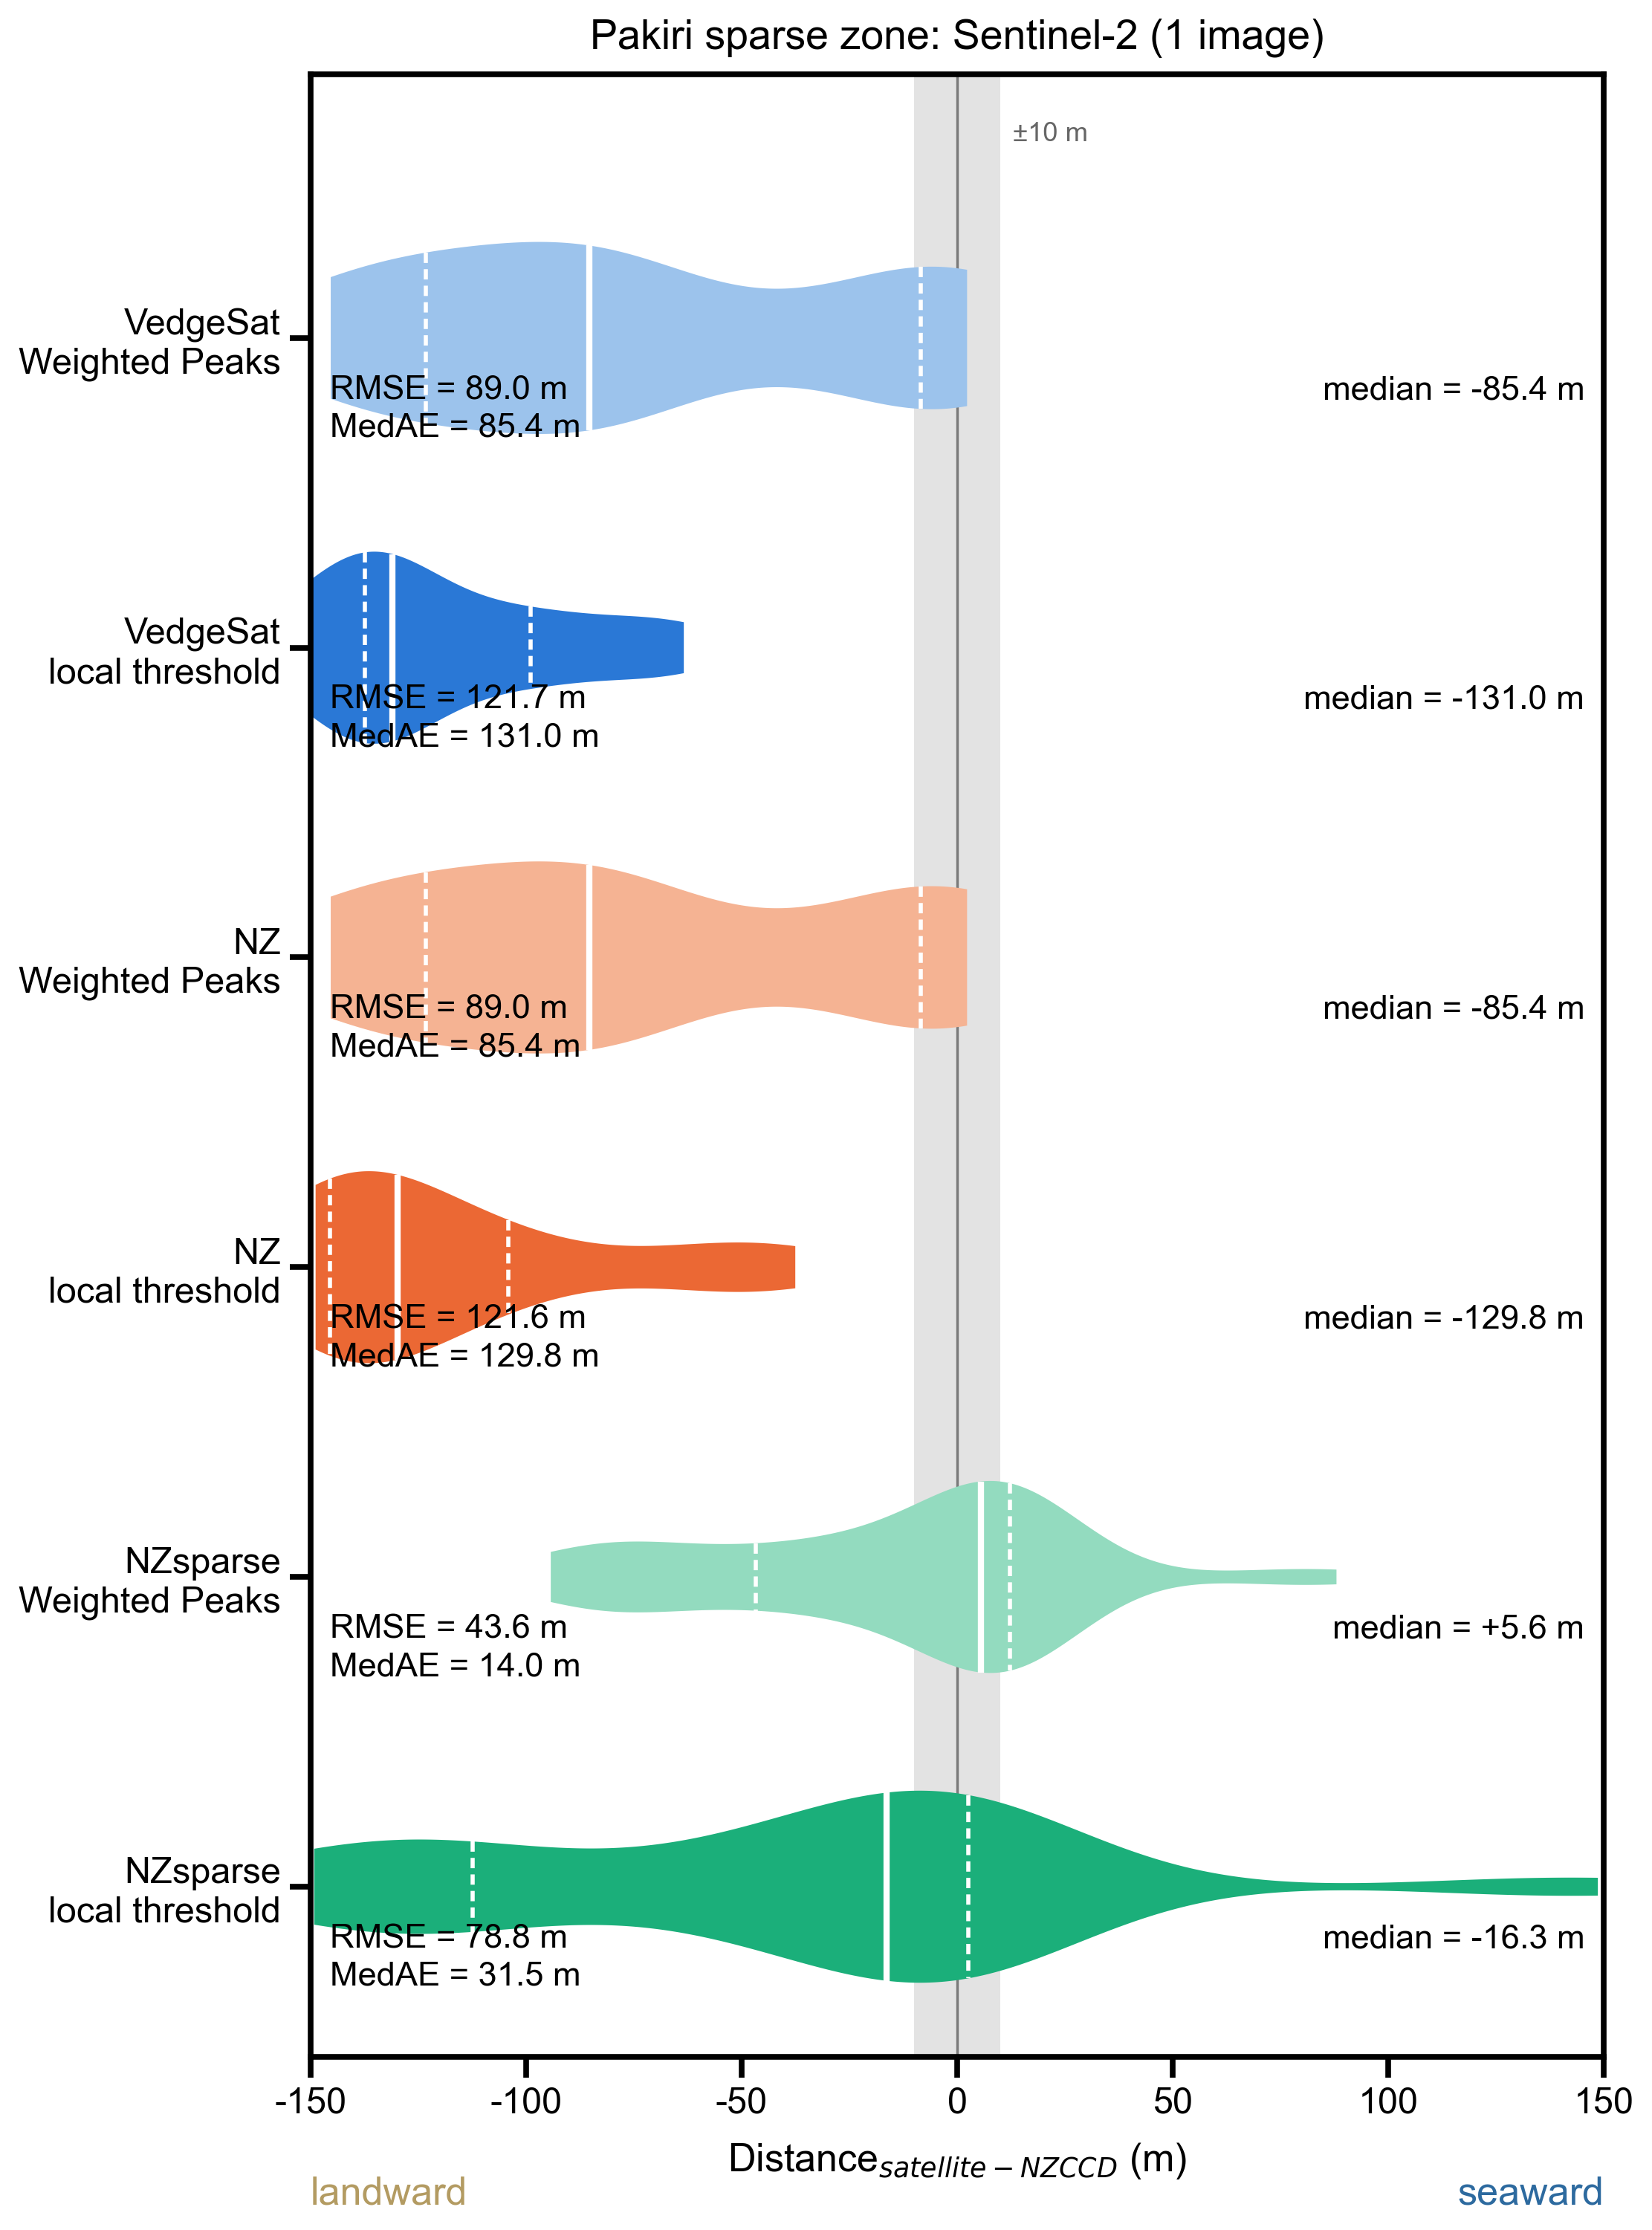

saved /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Extra_analyses/NZCCD_comparison_PakiriSparse/violins_PakiriSparse_S2.png


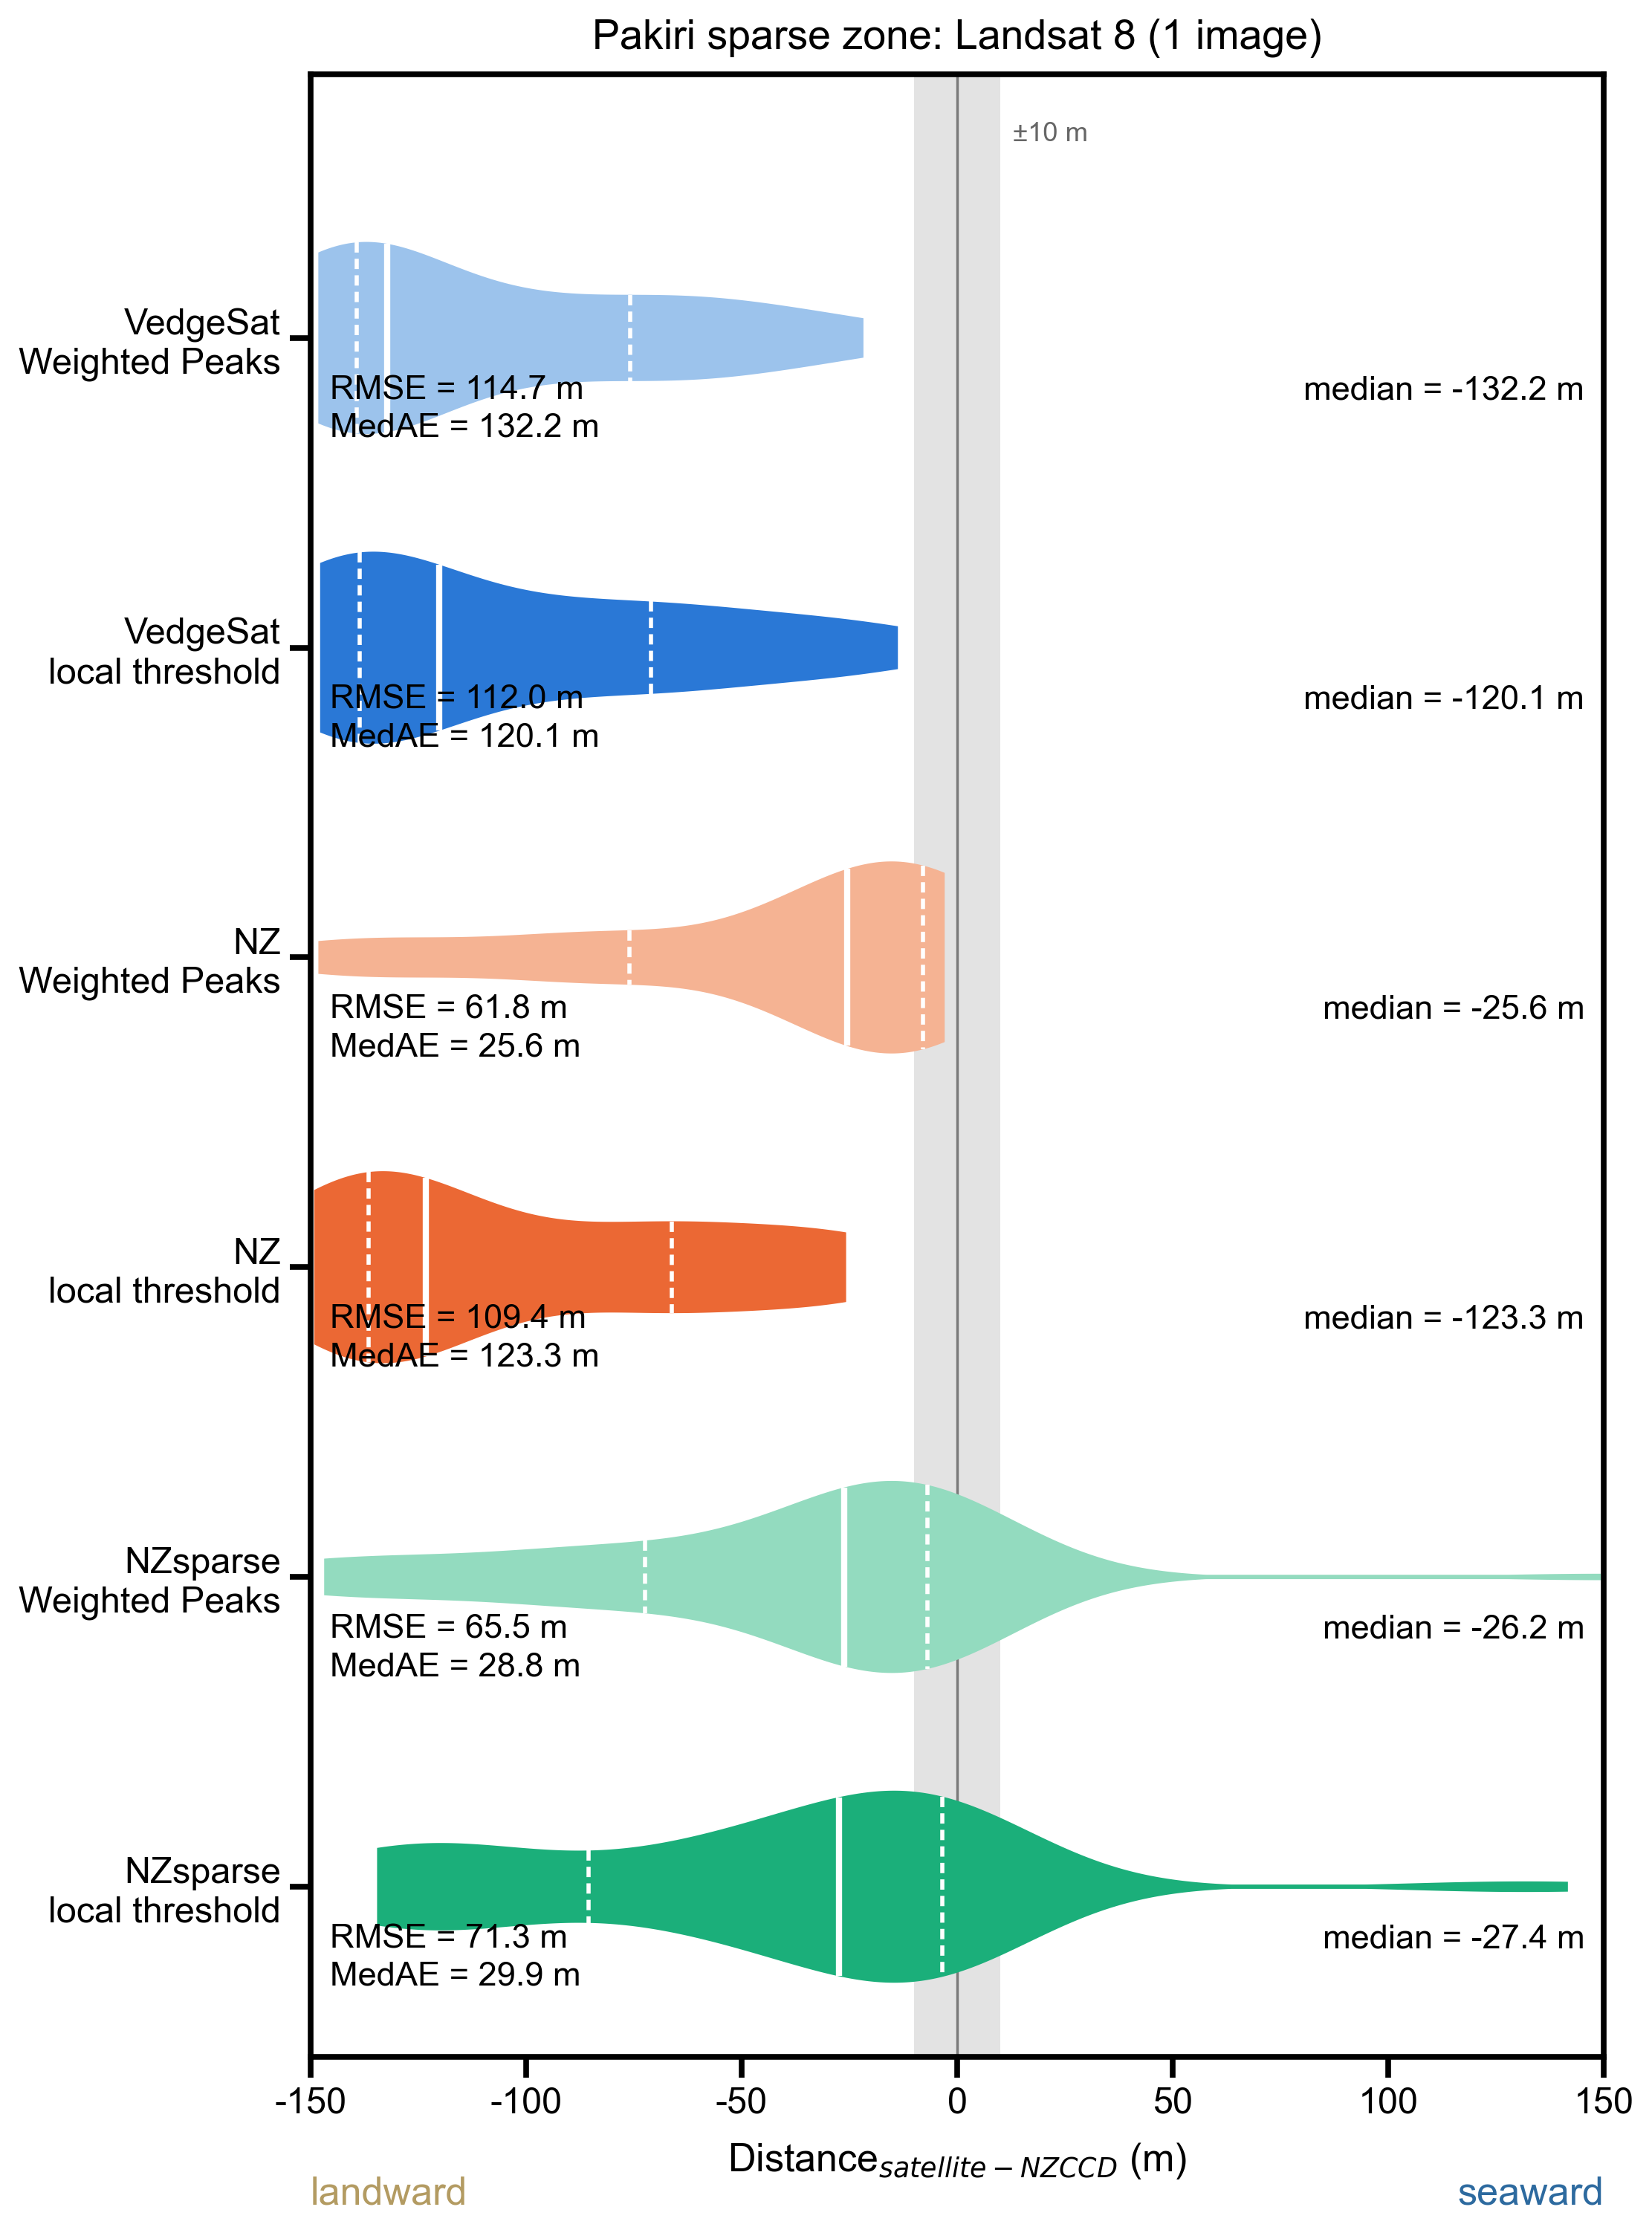

saved /Users/benmclean/Library/CloudStorage/OneDrive-TheUniversityofAuckland/Postgrad Papers/Project/COASTGUARD/COASTGUARD-master/Data/Extra_analyses/NZCCD_comparison_PakiriSparse/violins_PakiriSparse_L8.png


In [6]:
# =====================================================================================
# Edge error vs NZCCD: violins for the Pakiri sparse-vegetation zone (PakiriSparse runs)
# =====================================================================================
# Same figure style as the main violin cell. Reads errors_all.csv saved by
# PakiriSparse_comparison_cell.py and draws one figure per satellite (S2, L8), each from one image.
# Figures are saved (replacing the previous ones) next to that CSV (Data/Extra_analyses/NZCCD_comparison_PakiriSparse); the main
# violins are not touched.
# All six scenarios are drawn; delete a line from RUNS to drop a scenario from every figure.
# In each violin: white solid line = median, white dashed lines = 25th and 75th percentiles.
# Positive distance = satellite edge seaward of NZCCD. Saves violins_<site>_<sat>.png next to the CSV.

import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook, mlab, transforms
from IPython.display import Image, display

# ---------------- EDIT ME ----------------
BUFFER = 100            # m, reference-line buffer (max_dist_ref). Set the SAME value in the runs, comparison and
                        # violin cells. Rerunning replaces the previous results (one set of files only).
SITE = 'PakiriSparse'
CSV = os.path.join(os.getcwd(), 'Data', 'Extra_analyses', f'NZCCD_comparison_{SITE}', 'errors_all.csv')
OUT = os.path.dirname(CSV)
SITES = [SITE]
TITLE = {SITE: f'Pakiri sparse zone, {BUFFER} m buffer'}   # figure title
SATS = ['S2', 'L8']
# run in errors_all.csv -> label on the plot (top to bottom); leave a run out to drop it
RUNS = {
    'Default (WP)':     'VedgeSat\nWeighted Peaks',
    'Default (local)':  'VedgeSat\nlocal threshold',
    'NZ (WP)':          'NZ\nWeighted Peaks',
    'NZ (local)':       'NZ\nlocal threshold',
    'NZsparse (WP)':    'NZsparse\nWeighted Peaks',
    'NZsparse (local)': 'NZsparse\nlocal threshold',
}
COLOUR = {'Default (WP)': '#9cc3ec', 'Default (local)': '#2a78d6',     # VedgeSat: light / full blue
          'NZ (WP)': '#f5b393', 'NZ (local)': '#eb6834',               # NZ: light / full orange
          'NZsparse (WP)': '#93dbbf', 'NZsparse (local)': '#1baf7a'}   # NZsparse: light / full green
EXTRA = ['MedAE']          # extra values printed under RMSE: any of 'MedAE', 'within', 'MAE'
XLIM = 150          # m either side of NZCCD = the full transect length, so every error is shown
CORE = 150          # m either side drawn at full scale (per site as a dict if ever needed)
OUTER = 1           # 1 = plain linear axis (no compression). Below 1: beyond ±CORE the axis is compressed to this fraction, so the tails fit without
                    # squeezing the main body (shaded and marked on the plot); 1 = plain linear axis
WITHIN = 10         # m, the accuracy target (grey band)
COMBINE = False     # one site only, so nothing to pool
# ------------------------------------------

SAT_NAME = {'S2': 'Sentinel-2', 'L8': 'Landsat 8', 'L9': 'Landsat 9'}
WIDTH, TAIL = 0.62, 0.007   # violin height (row units) and minimum half-height so sparse tails stay visible

def common_only(E):
    keep = []
    E = E.assign(img=E.nzccd_date.astype(str) + '|' + E.date.astype(str))
    for (site, sat), g in E.groupby(['site', 'satname']):
        shared = set.intersection(*[set(gg.img) for _, gg in g[g.run.isin(RUNS)].groupby('run')])
        dropped = sorted(set(g.img) - shared)
        if dropped:
            print(f'{site} {sat}: images not in every run, left out: {dropped}')
        keep.append(g[g.img.isin(shared)])
    return pd.concat(keep)

def draw_violin(ax, e, y, colour, xl):
    kde = lambda X, coords: mlab.GaussianKDE(X, 'scott').evaluate(coords)
    st = cbook.violin_stats(np.clip(e, -xl, xl), kde, points=500)[0]
    xs, half = st['coords'], st['vals']
    half = np.maximum(0.5 * WIDTH * half / half.max(), TAIL)
    ax.fill_between(xs, y - half, y + half, facecolor=colour, edgecolor='none', zorder=2)
    for q, ls, lw in [(25, (0, (2.5, 1.5)), 1.6), (50, '-', 2.4), (75, (0, (2.5, 1.5)), 1.6)]:
        xq = np.percentile(e, q)
        if -xl < xq < xl:
            h = np.interp(xq, xs, half)
            ax.plot([xq, xq], [y - h, y + h], color='white', lw=lw, ls=ls, zorder=3, solid_capstyle='butt')
    return xs, half

def axis_scale(core):
    """Linear inside ±core, compressed by OUTER beyond it (a piecewise-linear axis)."""
    fwd = lambda x: np.where(np.abs(x) <= core, x, np.sign(x) * (core + (np.abs(x) - core) * OUTER))
    inv = lambda y: np.where(np.abs(y) <= core, y, np.sign(y) * (core + (np.abs(y) - core) / OUTER))
    return fwd, inv

def figure(E, site, sat, title=None, tag=''):
    d = E[(E.site == site) & (E.satname == sat)]
    runs = [r for r in RUNS if (d.run == r).any()]
    fig, ax = plt.subplots(figsize=(9, 1.75 * len(runs) + 1.6))
    xl = XLIM.get(site, 300) if isinstance(XLIM, dict) else XLIM
    core = min(CORE.get(site, 100) if isinstance(CORE, dict) else CORE, xl)
    if OUTER < 1 and core < xl:
        ax.set_xscale('function', functions=axis_scale(core))
        for sgn in (-1, 1):                      # mark the compressed part of the axis
            ax.axvspan(sgn * core, sgn * xl, color='#f3f3f3', zorder=0, lw=0)
            ax.axvline(sgn * core, color='#bdbdbd', lw=1, ls=(0, (3, 2)), zorder=1)
    ax.axvspan(-WITHIN, WITHIN, color='#e3e3e3', zorder=0, lw=0)
    ax.axvline(0, color='#7a7a7a', lw=1, zorder=1)
    side = transforms.blended_transform_factory(ax.transAxes, ax.transData)   # x in axes fraction, y in rows
    for i, run in enumerate(runs):
        e = d[d.run == run].error_m.values
        draw_violin(ax, e, i, COLOUR[run], xl)
        med, rmse = np.median(e), np.sqrt(np.mean(e**2))
        # RMSE (and any extras) bottom-left of the row, just below the tail; median bottom-right
        lines = [f'RMSE = {rmse:.1f} m']
        for k in EXTRA:
            lines.append({'MedAE': f'MedAE = {np.median(np.abs(e)):.1f} m',
                          'MAE': f'MAE = {np.mean(np.abs(e)):.1f} m',
                          'within': f'{100*np.mean(np.abs(e) <= WITHIN):.0f}% within {WITHIN} m'}[k])
        ax.text(0.015, i + 0.12, '\n'.join(lines), fontsize=13, ha='left', va='top', linespacing=1.3, transform=side)
        ax.text(0.985, i + 0.12, f'median = {med:+.1f} m', fontsize=13, ha='right', va='top', transform=side)
        lo, hi = int(np.sum(e < -xl)), int(np.sum(e > xl))
        if lo:
            ax.text(0.01, i - 0.06, f'< {lo} beyond −{xl} m', fontsize=10, color='#555', va='bottom', transform=side)
        if hi:
            ax.text(0.99, i - 0.06, f'{hi} beyond {xl} m >', fontsize=10, color='#555', va='bottom', ha='right', transform=side)
    ax.text(WITHIN * 1.3, -0.62, f'±{WITHIN} m', fontsize=10.5, color='#666', ha='left', va='bottom')
    if OUTER < 1 and core < xl:
        ax.text(0.985, 0.985, f'axis compressed\nbeyond ±{core} m (shaded)', transform=ax.transAxes,
                fontsize=10, color='#777', ha='right', va='top')
    ax.set_yticks(range(len(runs)))
    ax.set_yticklabels([RUNS[r] for r in runs], fontsize=13)
    ax.set_ylim(len(runs) - 0.45, -0.85)   # inverted: first run at the top
    ax.set_xlim(-xl, xl)
    step = 25 if core <= 50 else 50
    ticks = list(np.arange(-core, core + 1, step))
    ticks = sorted(set(ticks + ([-xl, xl] if core < xl else [])))   # only the ends in the compressed part
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'{t:g}' for t in ticks])
    ax.tick_params(axis='both', labelsize=14, width=2.2, length=8)
    for sp in ax.spines.values():
        sp.set_linewidth(2.2)
    ax.set_xlabel('Distance$_{satellite-NZCCD}$ (m)', fontsize=15, labelpad=8)
    ax.annotate('landward', xy=(0, 0), xycoords='axes fraction', xytext=(0, -46), textcoords='offset points',
                color='#b39b62', fontsize=15, ha='left', va='top')
    ax.annotate('seaward', xy=(1, 0), xycoords='axes fraction', xytext=(0, -46), textcoords='offset points',
                color='#2d6a9f', fontsize=15, ha='right', va='top')
    n_img = d[d.run == runs[0]][['nzccd_date', 'date']].drop_duplicates().shape[0]
    ax.set_title(f'{title or site}: {SAT_NAME.get(sat, sat)} ({n_img} image{"s" if n_img != 1 else ""})', fontsize=16, pad=10)
    fig.tight_layout()
    png = os.path.join(OUT, f'violins_{site}_{sat}{tag}.png')
    fig.savefig(png, dpi=250, bbox_inches='tight')
    plt.close(fig)                 # no plt.show(): with a window backend it waits until the window is closed
    display(Image(png, width=650))  # shown inline from the saved file instead
    print('saved', png)

E = common_only(pd.read_csv(CSV))
E = E[E.run.isin(RUNS)]
E['month'] = pd.to_datetime(E.date).dt.month

def draw_all(E, label=None):
    tag = f'_{label}' if label else ''
    for site in SITES:
        for sat in SATS:
            if ((E.site == site) & (E.satname == sat)).any():
                figure(E, site, sat, title=f'{TITLE.get(site, site)}, {label}' if label else TITLE.get(site), tag=tag)
    if COMBINE:
        for sat in SATS:
            C = E[(E.satname == sat) & E.site.isin(SITES)].copy()
            if C.empty:
                continue
            n = C[C.run == next(iter(RUNS))].groupby('site').size()
            print(f'\nCombined {sat}{" " + label if label else ""}: transects per site (first run) '
                  + ', '.join(f'{k} {v}' for k, v in n.items()))
            C['site'] = 'Combined'
            figure(C, 'Combined', sat, title=' + '.join(SITES) + (f', {label}' if label else ''), tag=tag)

draw_all(E)

In [3]:
# =====================================================================================
# (NZ) Batch consistency check: run after the batch has finished
# =====================================================================================
# Every image gets a Weighted Peaks threshold twice per classifier: once in the "_WP" run
# (its final threshold) and once in the "_local" run (its first pass, saved as vthresh_wp).
# Same image + same classifier should give the same value, so any mismatch flags a run whose
# result wasn't reproducible. Delete (or rename) the flagged run folders and run the batch
# cell again: it redoes only the missing runs. Also lists Weighted Peaks thresholds above
# SUSPECT, for reporting how often the threshold jumps onto dense vegetation.
import pickle

TAG = 'BatchS'
TOL = 0.005          # threshold difference treated as a mismatch
SUSPECT = 0.3        # Weighted Peaks thresholds above this are listed for the write-up

def load_out(run):
    p = os.path.join('Data', run, f'{run}_output.pkl')
    if not os.path.isfile(p):
        return None
    with open(p, 'rb') as f:
        return pickle.load(f)

rows = []
for site in IMAGES:
    for nz in IMAGES[site]:
        for clf in ['default', 'NZ', 'NZsparse']:
            wp, loc = (f'{TAG}_{site}_{nz}_{clf}_WP', f'{TAG}_{site}_{nz}_{clf}_local')
            ow, ol = load_out(wp), load_out(loc)
            if ow is None or ol is None:
                rows.append({'site': site, 'nzccd': nz, 'classifier': clf, 'sat': '-', 'date': '-',
                             'WP_run': None, 'local_run_first_pass': None, 'status': 'MISSING RUN'})
                continue
            for sat in ['L8', 'S2']:
                a = dict(zip(ow.get(sat, {}).get('dates', []), ow.get(sat, {}).get('vthreshold', [])))
                b = dict(zip(ol.get(sat, {}).get('dates', []), ol.get(sat, {}).get('vthresh_wp', [])))
                for d in sorted(set(a) | set(b)):
                    ta, tb = a.get(d), b.get(d)
                    if ta is None or tb is None:
                        status = 'IMAGE IN ONE RUN ONLY'
                    elif abs(ta - tb) > TOL:
                        status = 'MISMATCH'
                    else:
                        status = 'ok'
                    rows.append({'site': site, 'nzccd': nz, 'classifier': clf, 'sat': sat, 'date': d,
                                 'WP_run': None if ta is None else round(ta, 3),
                                 'local_run_first_pass': None if tb is None else round(tb, 3), 'status': status})

C = pd.DataFrame(rows)
C.to_csv(os.path.join('Data', f'{TAG}_consistency.csv'), index=False)
bad = C[C.status != 'ok']
print(f'{len(C)} image checks: {int((C.status == "ok").sum())} ok, {len(bad)} to look at')
if len(bad):
    print(bad.to_string(index=False))
    runs = sorted({f'{TAG}_{r.site}_{r.nzccd}_{r.classifier}_{s}' for r in bad.itertuples() for s in ('WP', 'local')})
    print('\nRun folders to delete (or rename) and redo:\n  ' + '\n  '.join(runs))
hi = C[(C.status == 'ok') & (C.WP_run > SUSPECT)]
print(f'\nWeighted Peaks thresholds above {SUSPECT}: {len(hi)} of {int((C.status == "ok").sum())} image checks')
if len(hi):
    print(hi[['site', 'nzccd', 'classifier', 'sat', 'date', 'WP_run']].to_string(index=False))

81 image checks: 81 ok, 0 to look at

Weighted Peaks thresholds above 0.3: 11 of 81 image checks
   site      nzccd classifier sat       date  WP_run
Muriwai 2022-01-17    default  L8 2021-11-18   0.556
Muriwai 2022-01-17    default  S2 2022-04-03   0.430
Muriwai 2020-01-25    default  L8 2020-01-09   0.440
Muriwai 2020-01-25    default  L8 2020-02-17   0.342
Muriwai 2017-07-15    default  L8 2017-05-24   0.576
Muriwai 2017-07-15    default  L8 2017-05-31   0.518
Muriwai 2017-07-15    default  L8 2017-06-16   0.530
Muriwai 2017-07-15    default  L8 2017-08-03   0.572
Muriwai 2017-07-15    default  S2 2017-06-28   0.522
 Pakiri 2023-04-04    default  L8 2023-05-25   0.562
 Pakiri 2017-02-03         NZ  L8 2016-11-20   0.360


In [4]:
# =====================================================================================
# (NZ) Weighted Peaks stability: how much VedgeSat's random class balancing moves the threshold
# =====================================================================================
# Run after the batch. Uses Data/<TAG>_wp_draws.csv (N_DRAWS Weighted Peaks thresholds per image,
# each from a different random subsample of the larger class) and the seeded threshold actually used.
# For the write-up: VedgeSat balances veg / non-veg pixel counts by unseeded random subsampling
# (Image_Processing.ClipIndexVec), so the Weighted Peaks threshold is not fully reproducible.
import pickle

TAG = 'BatchS'
SMALL = 0.02      # range of draws (max - min) treated as negligible (2 KDE bins x 0.8 = 0.016)
LARGE = 0.10      # range above this = the peak choice flips between draws (e.g. sand vs mislabelled land)

D = pd.read_csv(os.path.join('Data', f'{TAG}_wp_draws.csv'))
parts = D.run.str.split('_')
D['site'], D['nzccd'], D['classifier'] = parts.str[1], parts.str[2], parts.str[3]

used = []
for run in D.run.unique():
    with open(os.path.join('Data', run, f'{run}_output.pkl'), 'rb') as f:
        out = pickle.load(f)
    for sat in ['L8', 'S2']:
        for d, fn, t in zip(out.get(sat, {}).get('dates', []), out.get(sat, {}).get('filename', []),
                            out.get(sat, {}).get('vthreshold', [])):
            used.append({'run': run, 'sat': sat, 'filename': fn, 'used_threshold': t})
U = pd.DataFrame(used)

S = (D.groupby(['site', 'nzccd', 'classifier', 'sat', 'date', 'run', 'filename'])
       .threshold.agg(draws='size', median='median', min='min', max='max', sd='std').reset_index())
S['range'] = S['max'] - S['min']
# share of draws more than LARGE/2 away from the median (draws that took the other peak)
far = D.merge(S[['run', 'filename', 'median']], on=['run', 'filename'])
far['off'] = (far.threshold - far['median']).abs() > LARGE / 2
S = S.merge(far.groupby(['run', 'filename']).off.mean().mul(100).rename('pct_other_peak').reset_index(),
            on=['run', 'filename'])
S = S.merge(U, on=['run', 'sat', 'filename'], how='left')
S['class'] = np.select([S['range'] <= SMALL, S['range'] <= LARGE], ['stable', 'small shifts'], 'peak flips')
S.round(3).to_csv(os.path.join('Data', f'{TAG}_wp_stability.csv'), index=False)

print(f'{len(S)} image x classifier combinations, {int(S.draws.median())} draws each\n')
summ = (S.groupby(['classifier', 'sat'])['class'].value_counts().unstack(fill_value=0)
          .reindex(columns=['stable', 'small shifts', 'peak flips'], fill_value=0))
summ['images'] = summ.sum(axis=1)
print('Images by threshold stability (stable: range <= %.2f; peak flips: range > %.2f):' % (SMALL, LARGE))
print(summ.to_string())
flips = S[S['class'] == 'peak flips'].sort_values('range', ascending=False)
if len(flips):
    print('\nImages where the Weighted Peaks threshold flips between draws:')
    print(flips[['site', 'nzccd', 'classifier', 'sat', 'date', 'min', 'median', 'max', 'pct_other_peak',
                 'used_threshold']].round(3).to_string(index=False))
print(f"\nSaved Data/{TAG}_wp_stability.csv")

81 image x classifier combinations, 20 draws each

Images by threshold stability (stable: range <= 0.02; peak flips: range > 0.10):
class           stable  small shifts  peak flips  images
classifier sat                                          
NZ         L8       11             1           1      13
           S2       13             1           0      14
NZsparse   L8       13             0           0      13
           S2       14             0           0      14
default    L8        3             5           5      13
           S2       10             2           2      14

Images where the Weighted Peaks threshold flips between draws:
   site      nzccd classifier sat       date    min  median   max  pct_other_peak  used_threshold
Muriwai 2020-01-25    default  L8 2020-01-09 -0.024   0.228 0.440           100.0           0.440
Muriwai 2022-01-17    default  L8 2022-02-22  0.086   0.094 0.478            20.0           0.086
Muriwai 2022-01-17    default  S2 2022-04-03  0.054   

In [10]:
# =====================================================================================
# (NZ) Edge accuracy for the batch: every run, every image, scored against its own NZCCD line
# =====================================================================================
# Run after the batch and the consistency check. Needs only the saved veglines shapefiles,
# the NZCCD lines and the reference lines; nothing in VedgeSat is called.
#
# For each site and NZCCD date:
#   - NZCCD is kept only within MAX_DIST_REF of the site's reference line, so validation covers
#     the same stretch as extraction (and every Pakiri date is scored on the same coast);
#   - transects are cast every SPACING m along that NZCCD line;
#   - every image of every scenario is intersected with them, giving a signed cross-shore
#     error (m, + = satellite edge seaward of NZCCD). Several crossings on one transect -> median.
# coverage_% = share of possible image x transect pairs where the edge crossed the transect: a missing
# edge isn't an error in the other metrics, so report coverage alongside them.
# Outputs (in Data/NZCCD_comparison_batch/):
#   errors_all.csv           one row per site / NZCCD date / scenario / satellite / image / transect
#                            (columns match the violin cell, so point its CSV here)
#   metrics_by_site.csv      per site x satellite x scenario (all of that site's images pooled)
#   metrics_combined.csv     both sites pooled, per satellite x scenario
#   metrics_by_line.csv      per NZCCD line x satellite x scenario
#   metrics_per_image.csv    per image, and image_spread.csv: spread of per-image accuracy
#   coverage.csv             transects scored per image and scenario (spots edges that dropped out)
#   transects_<site>_<date>.shp

import os, glob, numpy as np, pandas as pd, geopandas as gpd
from shapely.geometry import LineString, Point, MultiLineString
from shapely.ops import linemerge, unary_union
from image_lists import IMAGES

# ---------------- EDIT ME ----------------
DATA = os.path.join(os.getcwd(), 'Data')
TAG = 'BatchS'
NZCCD_DIR = os.path.join(DATA, 'NZCCD_Lines_Pakiri_Muriwai')       # files named NZCCD_<Site>_<YYYY_MM_DD>.shp
REFLINES = {'Muriwai': 'Muriwai_refLine.shp', 'Pakiri': 'PakiriMain_refLine.shp'}   # in Data/referenceLines
MAX_DIST_REF = 200      # m; the batch buffer: NZCCD beyond this from the reference line is not scored
SEA_POINT = {'Pakiri': (-36.15, 174.80), 'Muriwai': (-36.80, 174.25)}   # (lat, lon) offshore, to tell seaward
SPACING = 10            # m between transects
HALF_LEN = 150          # m either side of NZCCD (as in the earlier comparisons). Longer transects also cross edge
                        # pieces far inland or in the surf, and the median of those crossings gives spurious errors
WITHIN = 10             # m, the accuracy target
OUT = os.path.join(DATA, 'NZCCD_comparison_batch')
# ------------------------------------------

CRS = 'EPSG:2193'
SCEN = {'default_WP': 'Default (WP)', 'default_local': 'Default (local)', 'NZ_WP': 'NZ (WP)',
        'NZ_local': 'NZ (local)', 'NZsparse_WP': 'NZsparse (WP)', 'NZsparse_local': 'NZsparse (local)'}
ORDER = list(SCEN.values())
os.makedirs(OUT, exist_ok=True)

def short_path(f):
    if os.name == 'nt' and len(f) > 240:
        import ctypes
        buf = ctypes.create_unicode_buffer(1024)
        if ctypes.windll.kernel32.GetShortPathNameW('\\\\?\\' + f, buf, 1024):
            s = buf.value
            return s[4:] if s.startswith('\\\\?\\') else s
    return f

def find_veglines(run):
    hits = [f for f in glob.glob(os.path.join(DATA, run, 'lines', '*.shp'))
            if 'vegline' in os.path.basename(f).lower() and 'water' not in os.path.basename(f).lower()]
    if not hits:
        raise FileNotFoundError(f'No veglines shapefile in {os.path.join(DATA, run, "lines")}')
    return short_path(sorted(hits, key=len)[0])

def make_transects(nzccd, sea_xy):
    merged = linemerge(unary_union(list(nzccd.geometry)))
    parts = list(merged.geoms) if isinstance(merged, MultiLineString) else [merged]
    rows, tid = [], 0
    for part in parts:
        if part.length < 4 * SPACING:
            continue
        for s in np.arange(SPACING, part.length - SPACING, SPACING):
            p = np.array(part.interpolate(s).coords[0])
            a, b = np.array(part.interpolate(s - SPACING).coords[0]), np.array(part.interpolate(s + SPACING).coords[0])
            t = (b - a) / np.linalg.norm(b - a)
            n = np.array([-t[1], t[0]])
            if np.linalg.norm(p + n * HALF_LEN - sea_xy) > np.linalg.norm(p - n * HALF_LEN - sea_xy):
                n = -n
            rows.append({'TransectID': tid, 'px': p[0], 'py': p[1], 'nx': n[0], 'ny': n[1],
                         'geometry': LineString([p - n * HALF_LEN, p + n * HALF_LEN])})
            tid += 1
    return rows

def chunks(geom, n=50):
    out = []
    for p in getattr(geom, 'geoms', [geom]):
        if p.geom_type != 'LineString':
            continue
        c = np.asarray(p.coords)
        for i in range(0, len(c) - 1, n):
            if len(c[i:i + n + 1]) >= 2:
                out.append(LineString(c[i:i + n + 1]))
    return out

def crossings(line, T):
    '''All signed crossing distances (m, + seaward) of an edge on each transect.'''
    ch = chunks(line)
    if not ch:
        return {}
    tree = gpd.GeoSeries(ch).sindex
    out = {}
    for tid, tr, px, py, nx, ny in zip(T.TransectID, T.geometry, T.px, T.py, T.nx, T.ny):
        pts = []
        for j in tree.query(tr, predicate='intersects'):
            x = tr.intersection(ch[j])
            pts += [g for g in getattr(x, 'geoms', [x]) if g.geom_type == 'Point']
        if pts:
            out[int(tid)] = [(q.x - px) * nx + (q.y - py) * ny for q in pts]
    return out

# ---------------- score every run ----------------
records, translog = [], []
for site in IMAGES:
    ref = gpd.read_file(short_path(os.path.join(DATA, 'referenceLines', REFLINES[site]))).to_crs(CRS)
    zone = ref.buffer(MAX_DIST_REF).unary_union
    sea = gpd.GeoSeries([Point(SEA_POINT[site][1], SEA_POINT[site][0])], crs=4326).to_crs(CRS).iloc[0]
    for nz_date in IMAGES[site]:
        f = os.path.join(NZCCD_DIR, f'NZCCD_{site}_{nz_date.replace("-", "_")}.shp')
        nz_all = gpd.read_file(short_path(f)).to_crs(CRS)
        nz = gpd.clip(nz_all, zone)
        nz = nz[nz.geometry.notna() & ~nz.geometry.is_empty]
        T = gpd.GeoDataFrame(make_transects(nz, np.array(sea.coords[0])), crs=CRS)
        # NZCCD uncertainty of the segment each transect starts on (for the limitations section)
        if 'Total_UNCY' in nz.columns:
            T['nzccd_uncy'] = [float(nz.iloc[int(np.argmin(nz.distance(Point(x, y))))]['Total_UNCY'])
                               for x, y in zip(T.px, T.py)]
        else:
            T['nzccd_uncy'] = np.nan
        T.to_file(os.path.join(OUT, f'transects_{site}_{nz_date}.shp'))
        translog.append({'site': site, 'nzccd_date': nz_date, 'nzccd_km_total': round(nz_all.length.sum() / 1000, 2),
                         'nzccd_km_scored': round(nz.length.sum() / 1000, 2), 'transects': len(T)})
        print(f'{site} {nz_date}: {len(T)} transects along {nz.length.sum()/1000:.1f} of '
              f'{nz_all.length.sum()/1000:.1f} km of NZCCD; intersecting...', flush=True)
        uncy = dict(zip(T.TransectID, T.nzccd_uncy))
        for key, label in SCEN.items():
            run = f'{TAG}_{site}_{nz_date}_{key}'
            g = gpd.read_file(find_veglines(run)).to_crs(CRS)
            for _, r in g.iterrows():
                if r.geometry is None or r.geometry.is_empty:
                    continue
                for tid, ds in crossings(r.geometry, T).items():
                    for d in ds:
                        records.append({'site': site, 'nzccd_date': nz_date, 'run': label, 'satname': r.satname,
                                        'date': str(r.dates)[:10], 'TransectID': tid, 'd': d})

E = pd.DataFrame(records)
# one value per image and transect: median of all crossings (pieces and loops of the same edge)
E = E.groupby(['site', 'nzccd_date', 'run', 'satname', 'date', 'TransectID'], as_index=False)['d'].median()
E = E.rename(columns={'d': 'error_m'})
E['gap_days'] = (pd.to_datetime(E.date) - pd.to_datetime(E.nzccd_date)).dt.days
E['nzccd_uncy'] = [np.nan] * len(E)
for (site, nz), idx in E.groupby(['site', 'nzccd_date']).groups.items():
    T = gpd.read_file(os.path.join(OUT, f'transects_{site}_{nz}.shp'))
    E.loc[idx, 'nzccd_uncy'] = E.loc[idx, 'TransectID'].map(dict(zip(T.TransectID, T.nzccd_uncy)))
E.to_csv(os.path.join(OUT, 'errors_all.csv'), index=False)
pd.DataFrame(translog).to_csv(os.path.join(OUT, 'transects_per_line.csv'), index=False)

# ---------------- metrics ----------------
def stats(e):
    e = np.asarray(e)
    return {'n': len(e), 'median_bias_m': np.median(e), 'MedAE_m': np.median(np.abs(e)),
            'MAE_m': np.mean(np.abs(e)), 'RMSE_m': np.sqrt(np.mean(e**2)),
            'p90_abs_m': np.percentile(np.abs(e), 90), f'within_{WITHIN}m_%': 100 * np.mean(np.abs(e) <= WITHIN)}

def table(df, keys):
    rows = []
    for k, g in df.groupby(keys):
        k = k if isinstance(k, tuple) else (k,)
        imgs = g[['site', 'nzccd_date', 'date']].drop_duplicates()
        possible = sum(NT[(r.site, r.nzccd_date)] for r in imgs.itertuples())
        rows.append({**dict(zip(keys, k)), 'images': len(imgs), **stats(g.error_m),
                     'coverage_%': 100 * len(g) / possible if possible else np.nan})
    M = pd.DataFrame(rows)
    M['run'] = pd.Categorical(M.run, ORDER, ordered=True)
    M = M.sort_values([c for c in keys if c != 'run'] + ['run']).reset_index(drop=True)
    M['run'] = M.run.astype(str)
    return M.round(1)

NT = {(t['site'], t['nzccd_date']): t['transects'] for t in translog}   # transects per line, for coverage
by_site = table(E, ['site', 'satname', 'run'])
combined = table(E, ['satname', 'run'])          # both sites pooled
combined.insert(0, 'site', 'Both')
by_line = table(E, ['site', 'nzccd_date', 'satname', 'run'])
per_img = table(E, ['site', 'nzccd_date', 'satname', 'date', 'run'])
spread = (per_img.groupby(['site', 'satname', 'run'])
          .agg(images=('MedAE_m', 'size'),
               MedAE_median=('MedAE_m', 'median'), MedAE_min=('MedAE_m', 'min'), MedAE_max=('MedAE_m', 'max'),
               RMSE_median=('RMSE_m', 'median'), RMSE_min=('RMSE_m', 'min'), RMSE_max=('RMSE_m', 'max'))
          .reset_index().round(1))
cov = E.pivot_table(index=['site', 'nzccd_date', 'satname', 'date'], columns='run', values='TransectID', aggfunc='count')
cov = cov.reindex(columns=[r for r in ORDER if r in cov.columns])
for name, df in [('metrics_by_site', by_site), ('metrics_combined', combined), ('metrics_by_line', by_line),
                 ('metrics_per_image', per_img), ('image_spread', spread)]:
    df.to_csv(os.path.join(OUT, f'{name}.csv'), index=False)
cov.to_csv(os.path.join(OUT, 'coverage.csv'))

pd.set_option('display.width', 250)
print('\nTransects per NZCCD line:'); print(pd.DataFrame(translog).to_string(index=False))
print('\nTransects scored per image (low or blank = edge missing there):'); print(cov.to_string())
cols = ['site', 'satname', 'run', 'images', 'n', 'coverage_%', 'median_bias_m', 'MedAE_m', 'RMSE_m', 'p90_abs_m', f'within_{WITHIN}m_%']
print('\n=== Both sites pooled ==='); print(combined[cols].to_string(index=False))
print('\n=== By site ==='); print(by_site[cols].to_string(index=False))
print('\n=== Spread of per-image accuracy ==='); print(spread.to_string(index=False))
print(f'\nSaved to {OUT}')

Muriwai 2022-01-17: 400 transects along 4.4 of 4.4 km of NZCCD; intersecting...
Muriwai 2020-01-25: 402 transects along 4.3 of 4.3 km of NZCCD; intersecting...
Muriwai 2017-07-15: 405 transects along 4.3 of 4.3 km of NZCCD; intersecting...
Pakiri 2023-04-04: 249 transects along 2.5 of 4.0 km of NZCCD; intersecting...
Pakiri 2021-10-14: 247 transects along 2.5 of 4.0 km of NZCCD; intersecting...
Pakiri 2017-02-03: 238 transects along 2.5 of 2.7 km of NZCCD; intersecting...

Transects per NZCCD line:
   site nzccd_date  nzccd_km_total  nzccd_km_scored  transects
Muriwai 2022-01-17            4.38             4.38        400
Muriwai 2020-01-25            4.33             4.33        402
Muriwai 2017-07-15            4.28             4.28        405
 Pakiri 2023-04-04            3.98             2.54        249
 Pakiri 2021-10-14            3.96             2.52        247
 Pakiri 2017-02-03            2.72             2.45        238

Transects scored per image (low or blank = edge missin

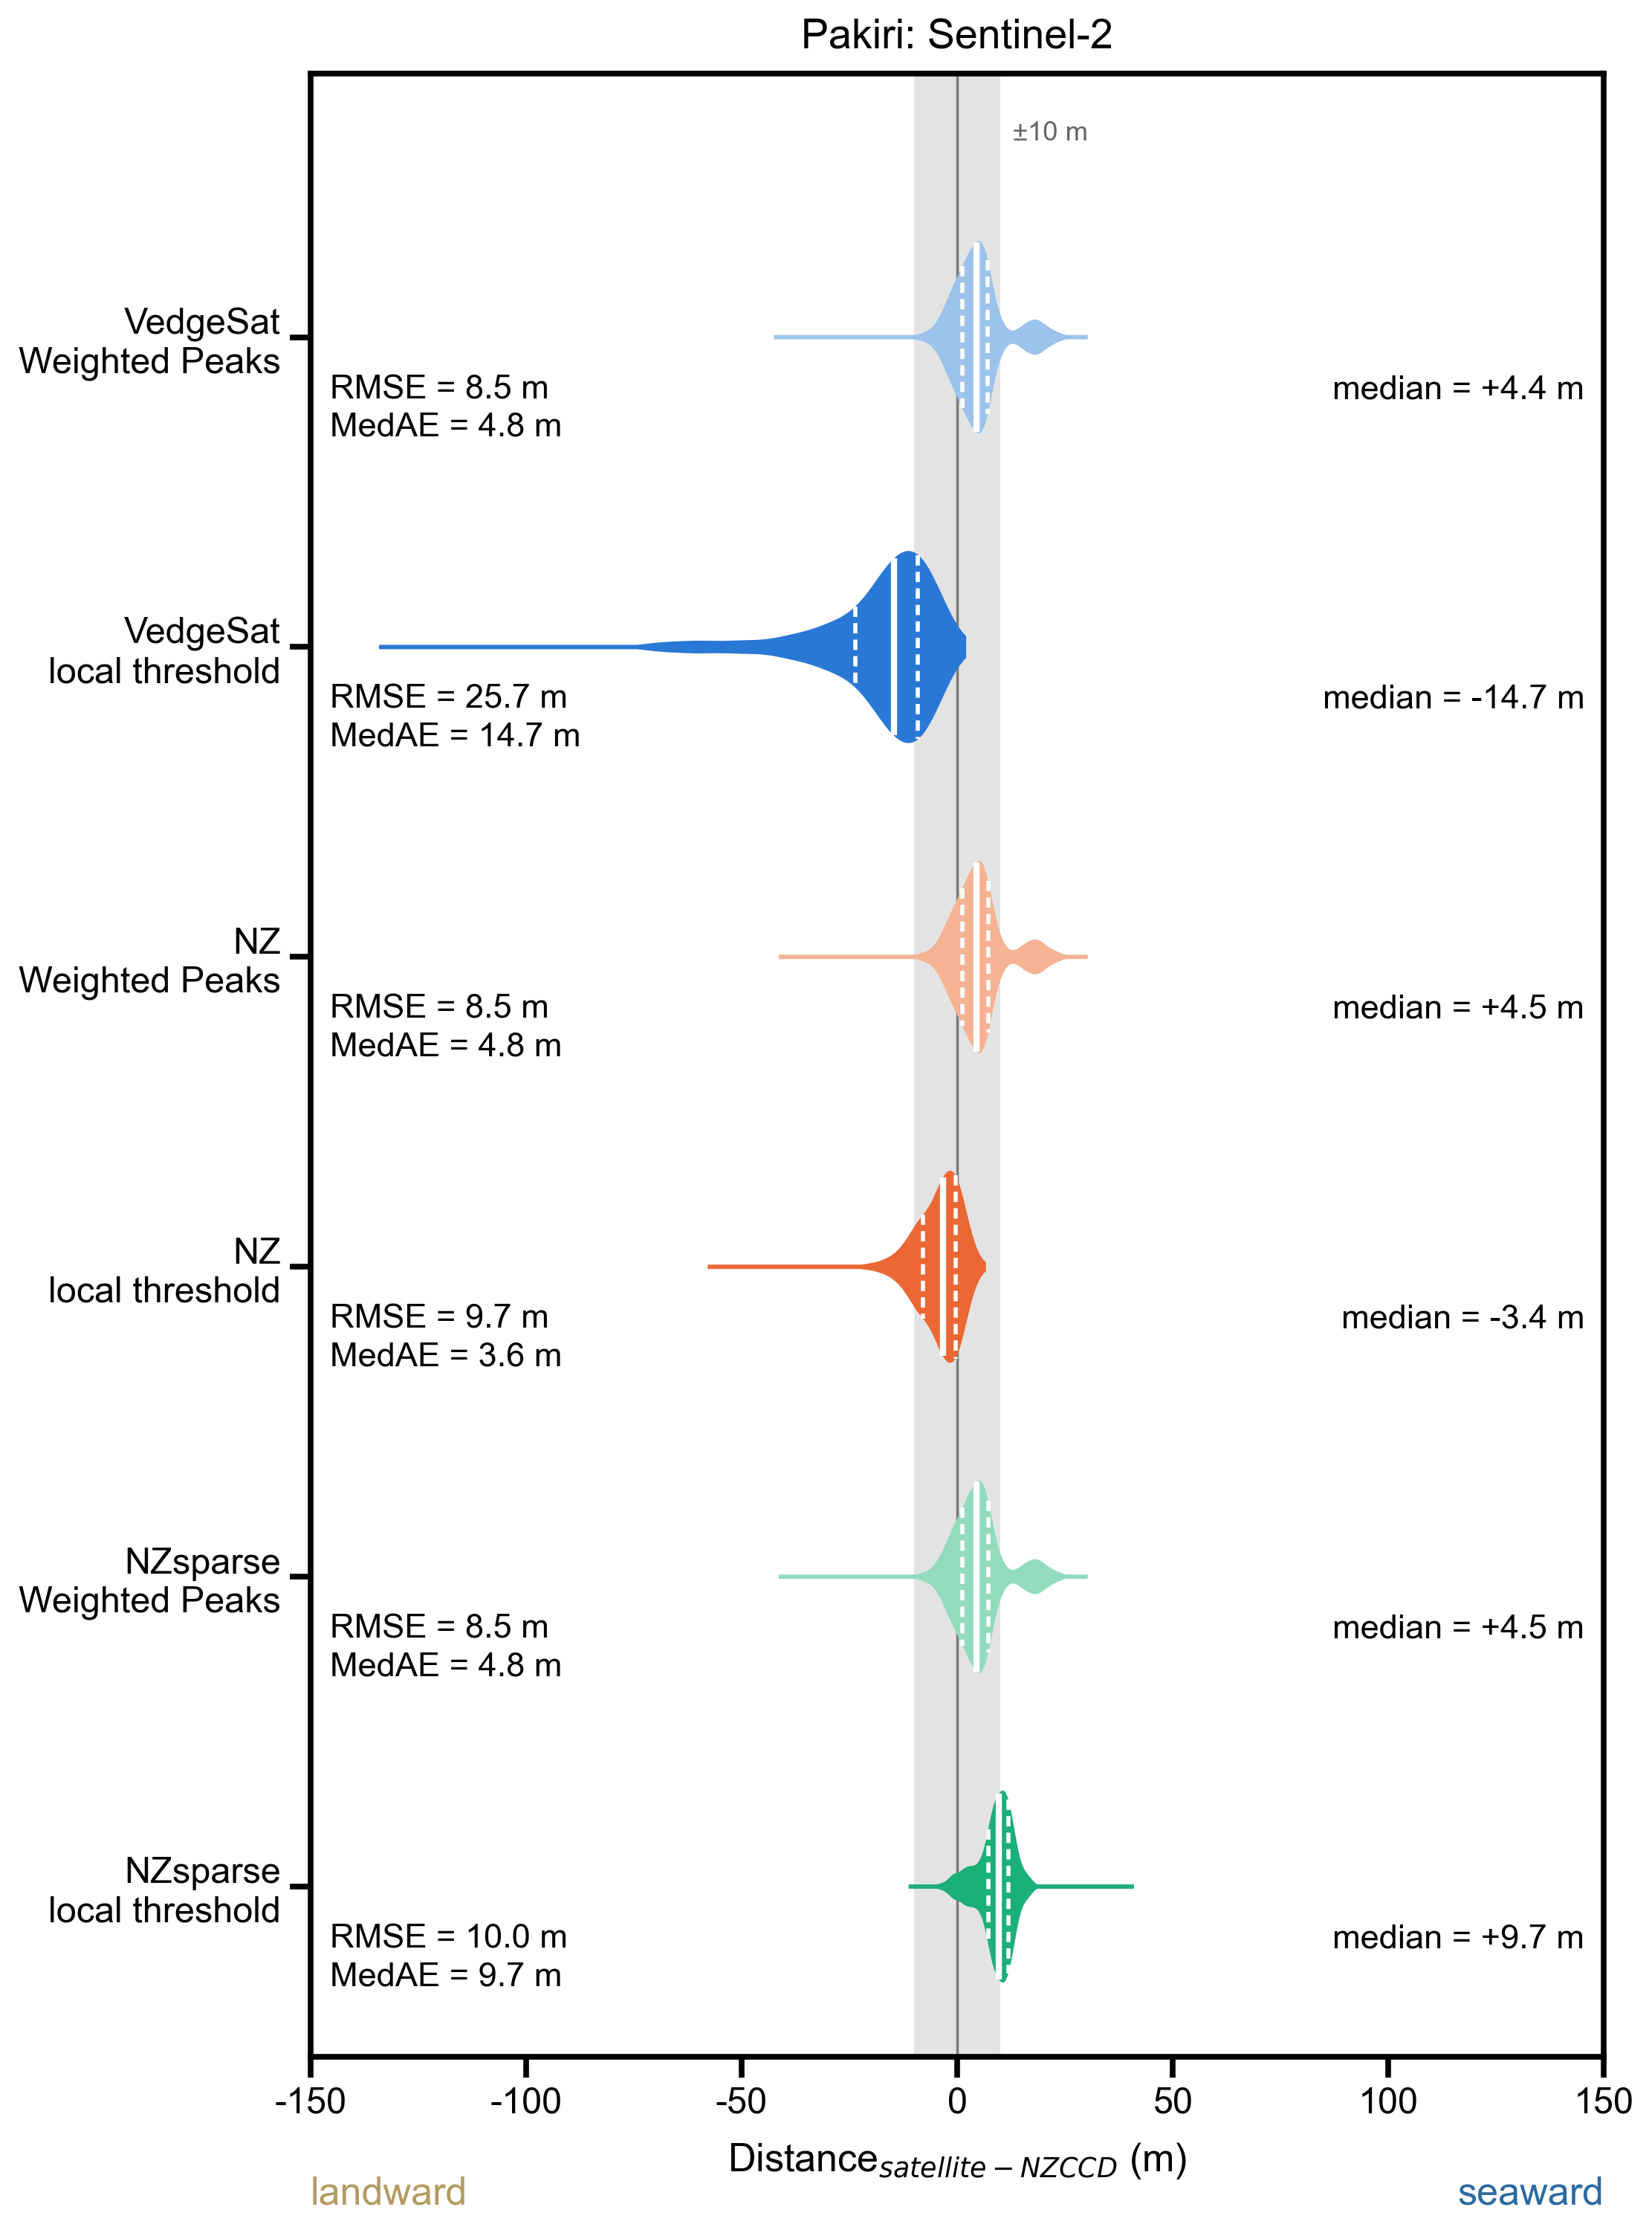

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\violins_Pakiri_S2.png


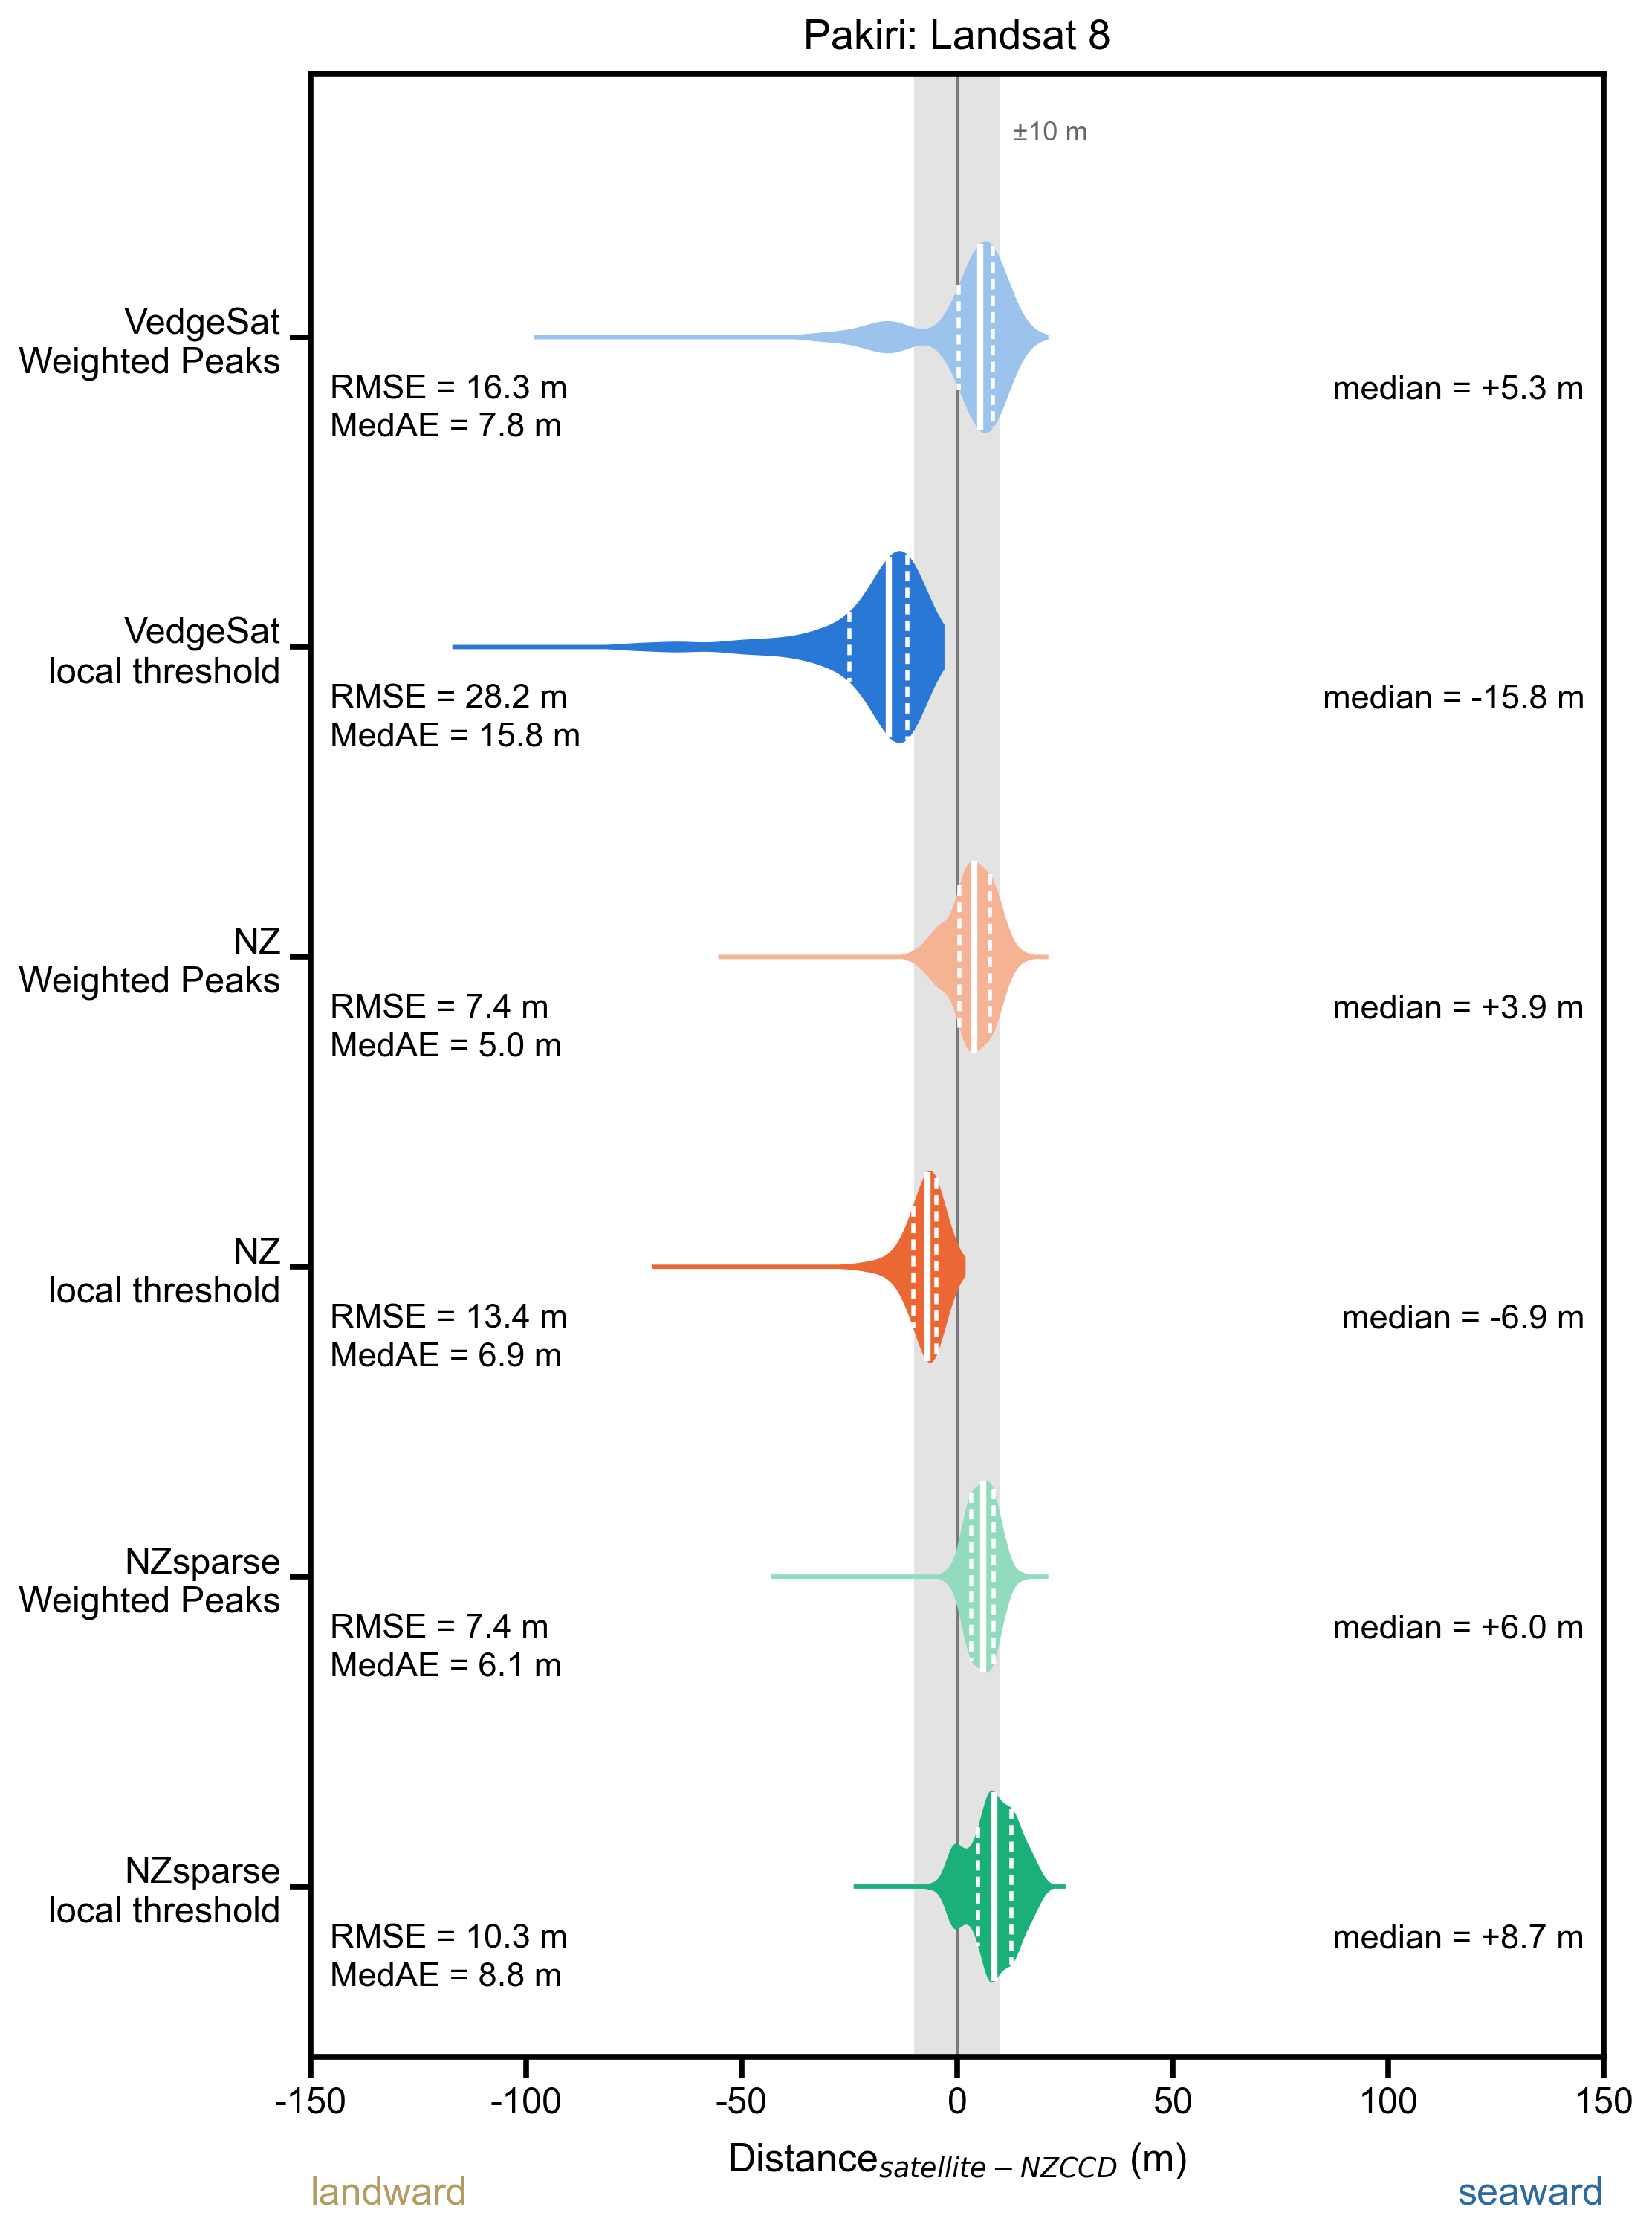

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\violins_Pakiri_L8.png


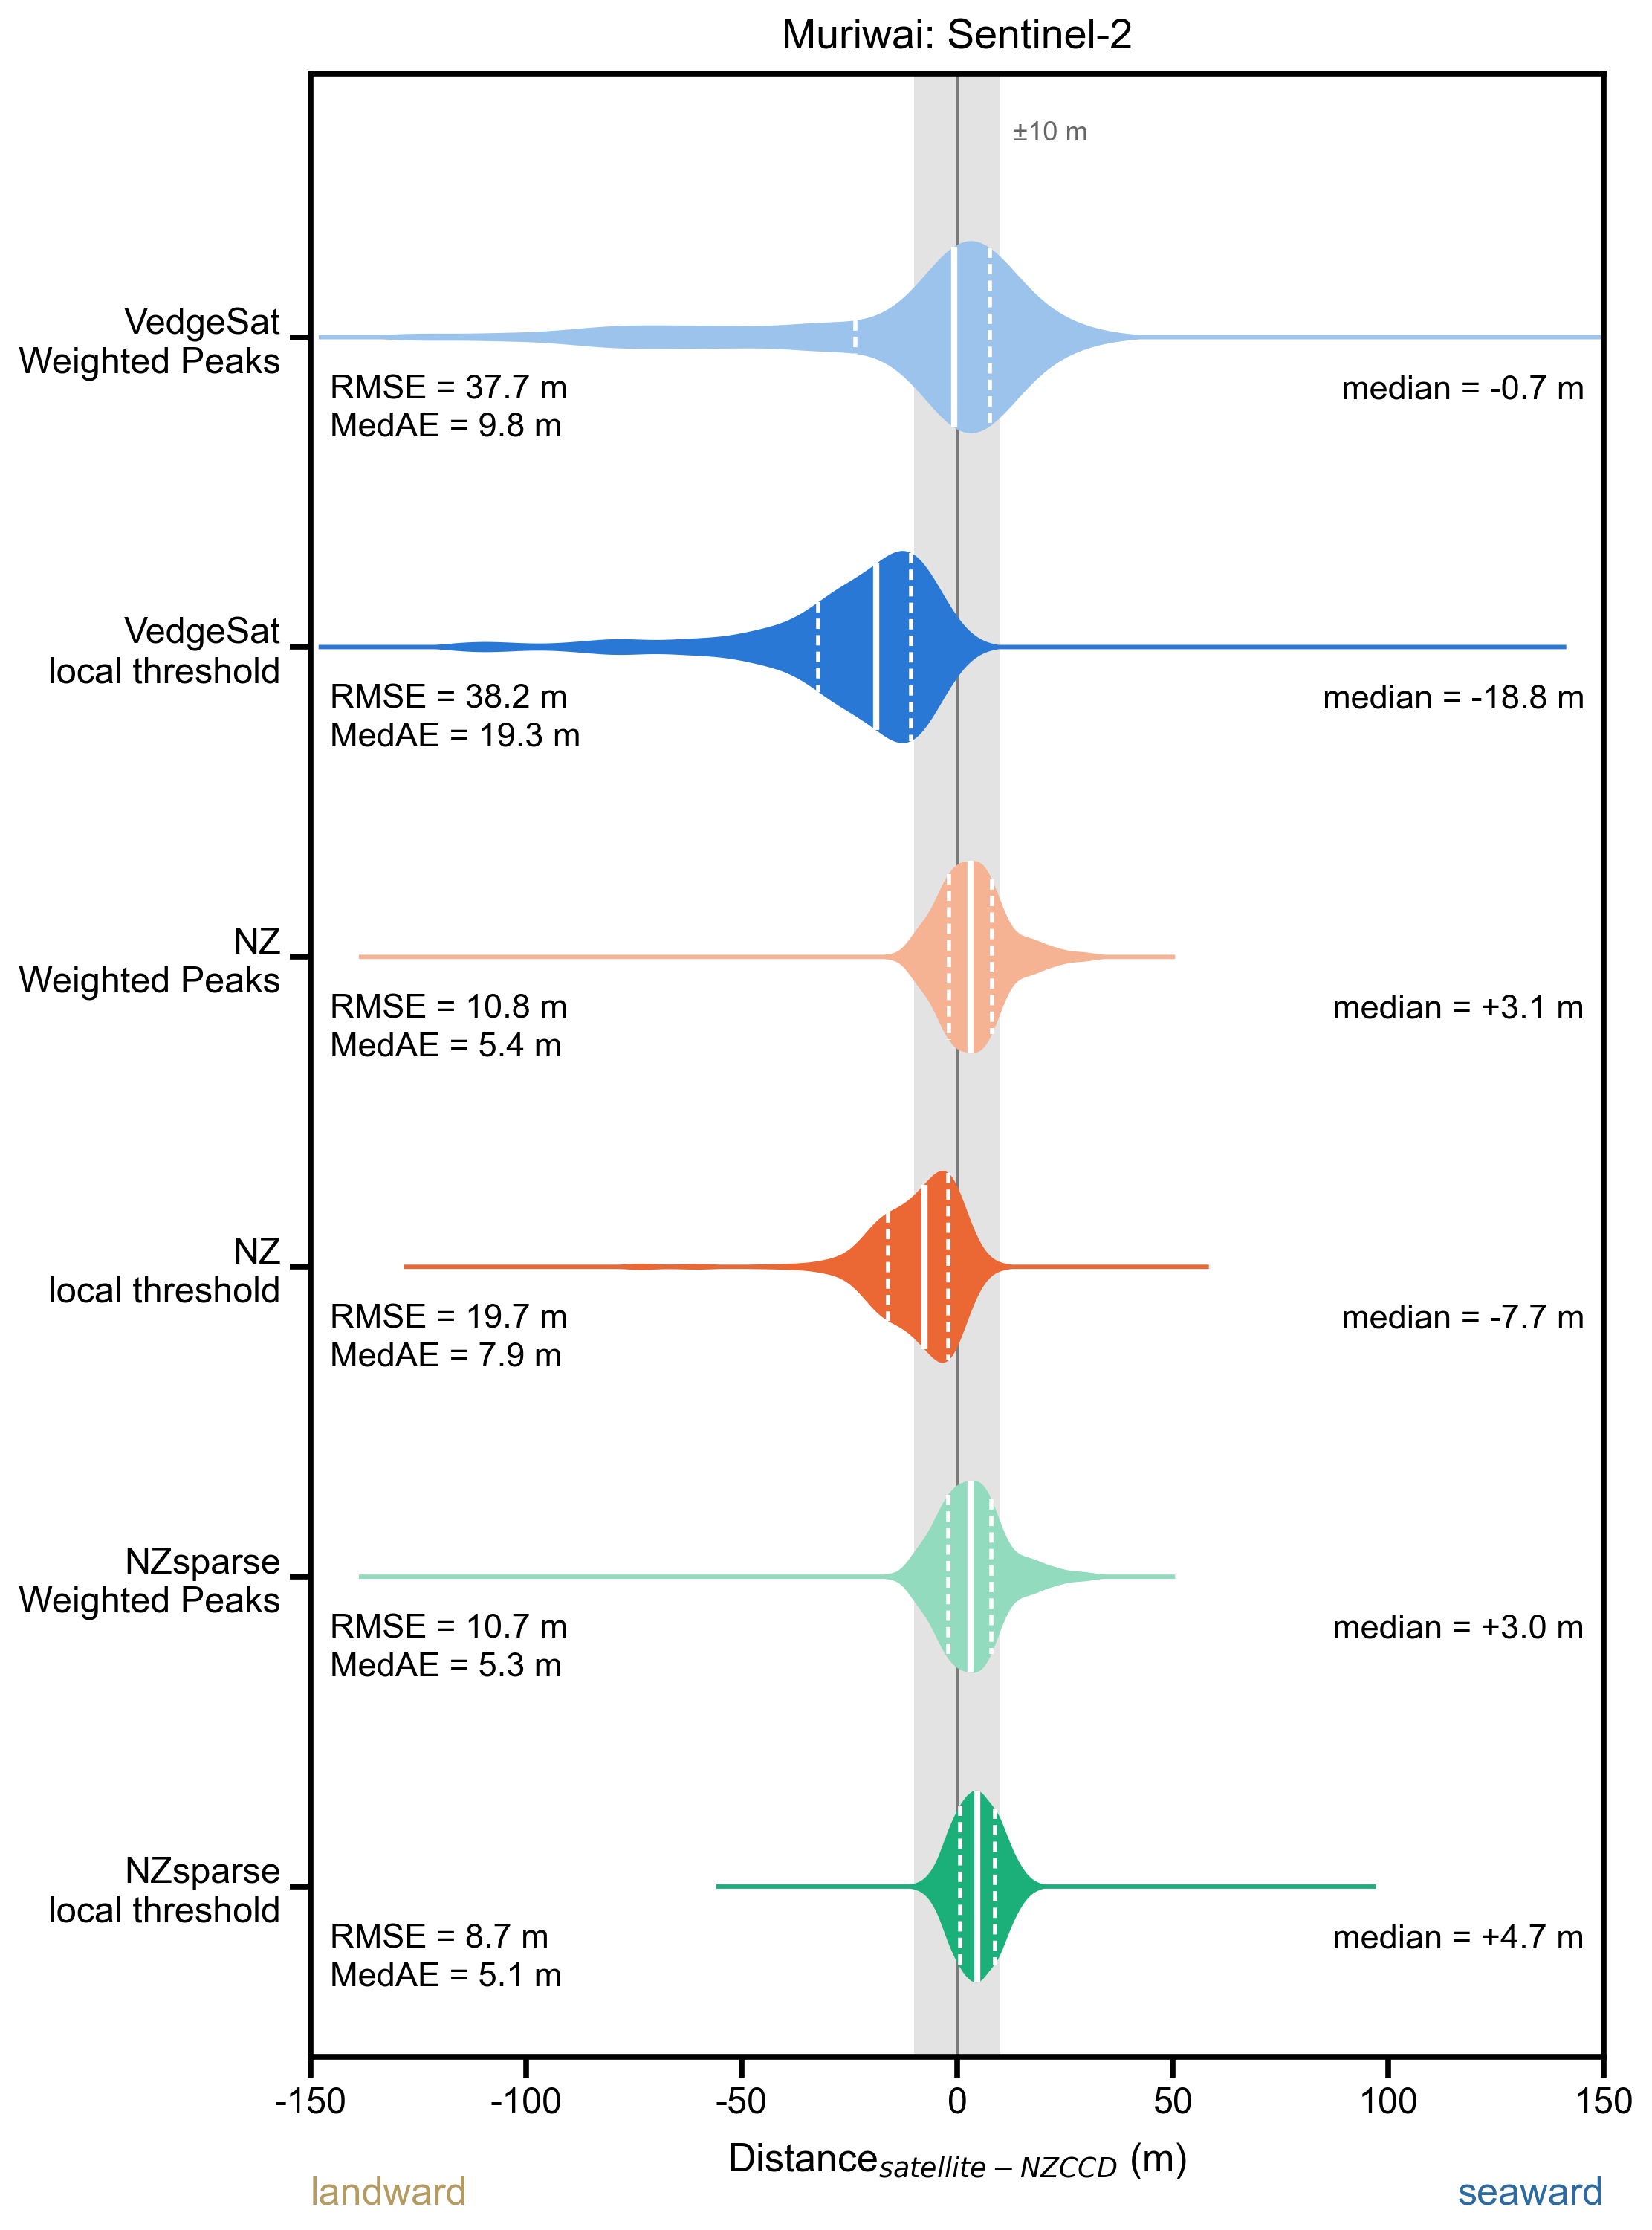

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\violins_Muriwai_S2.png


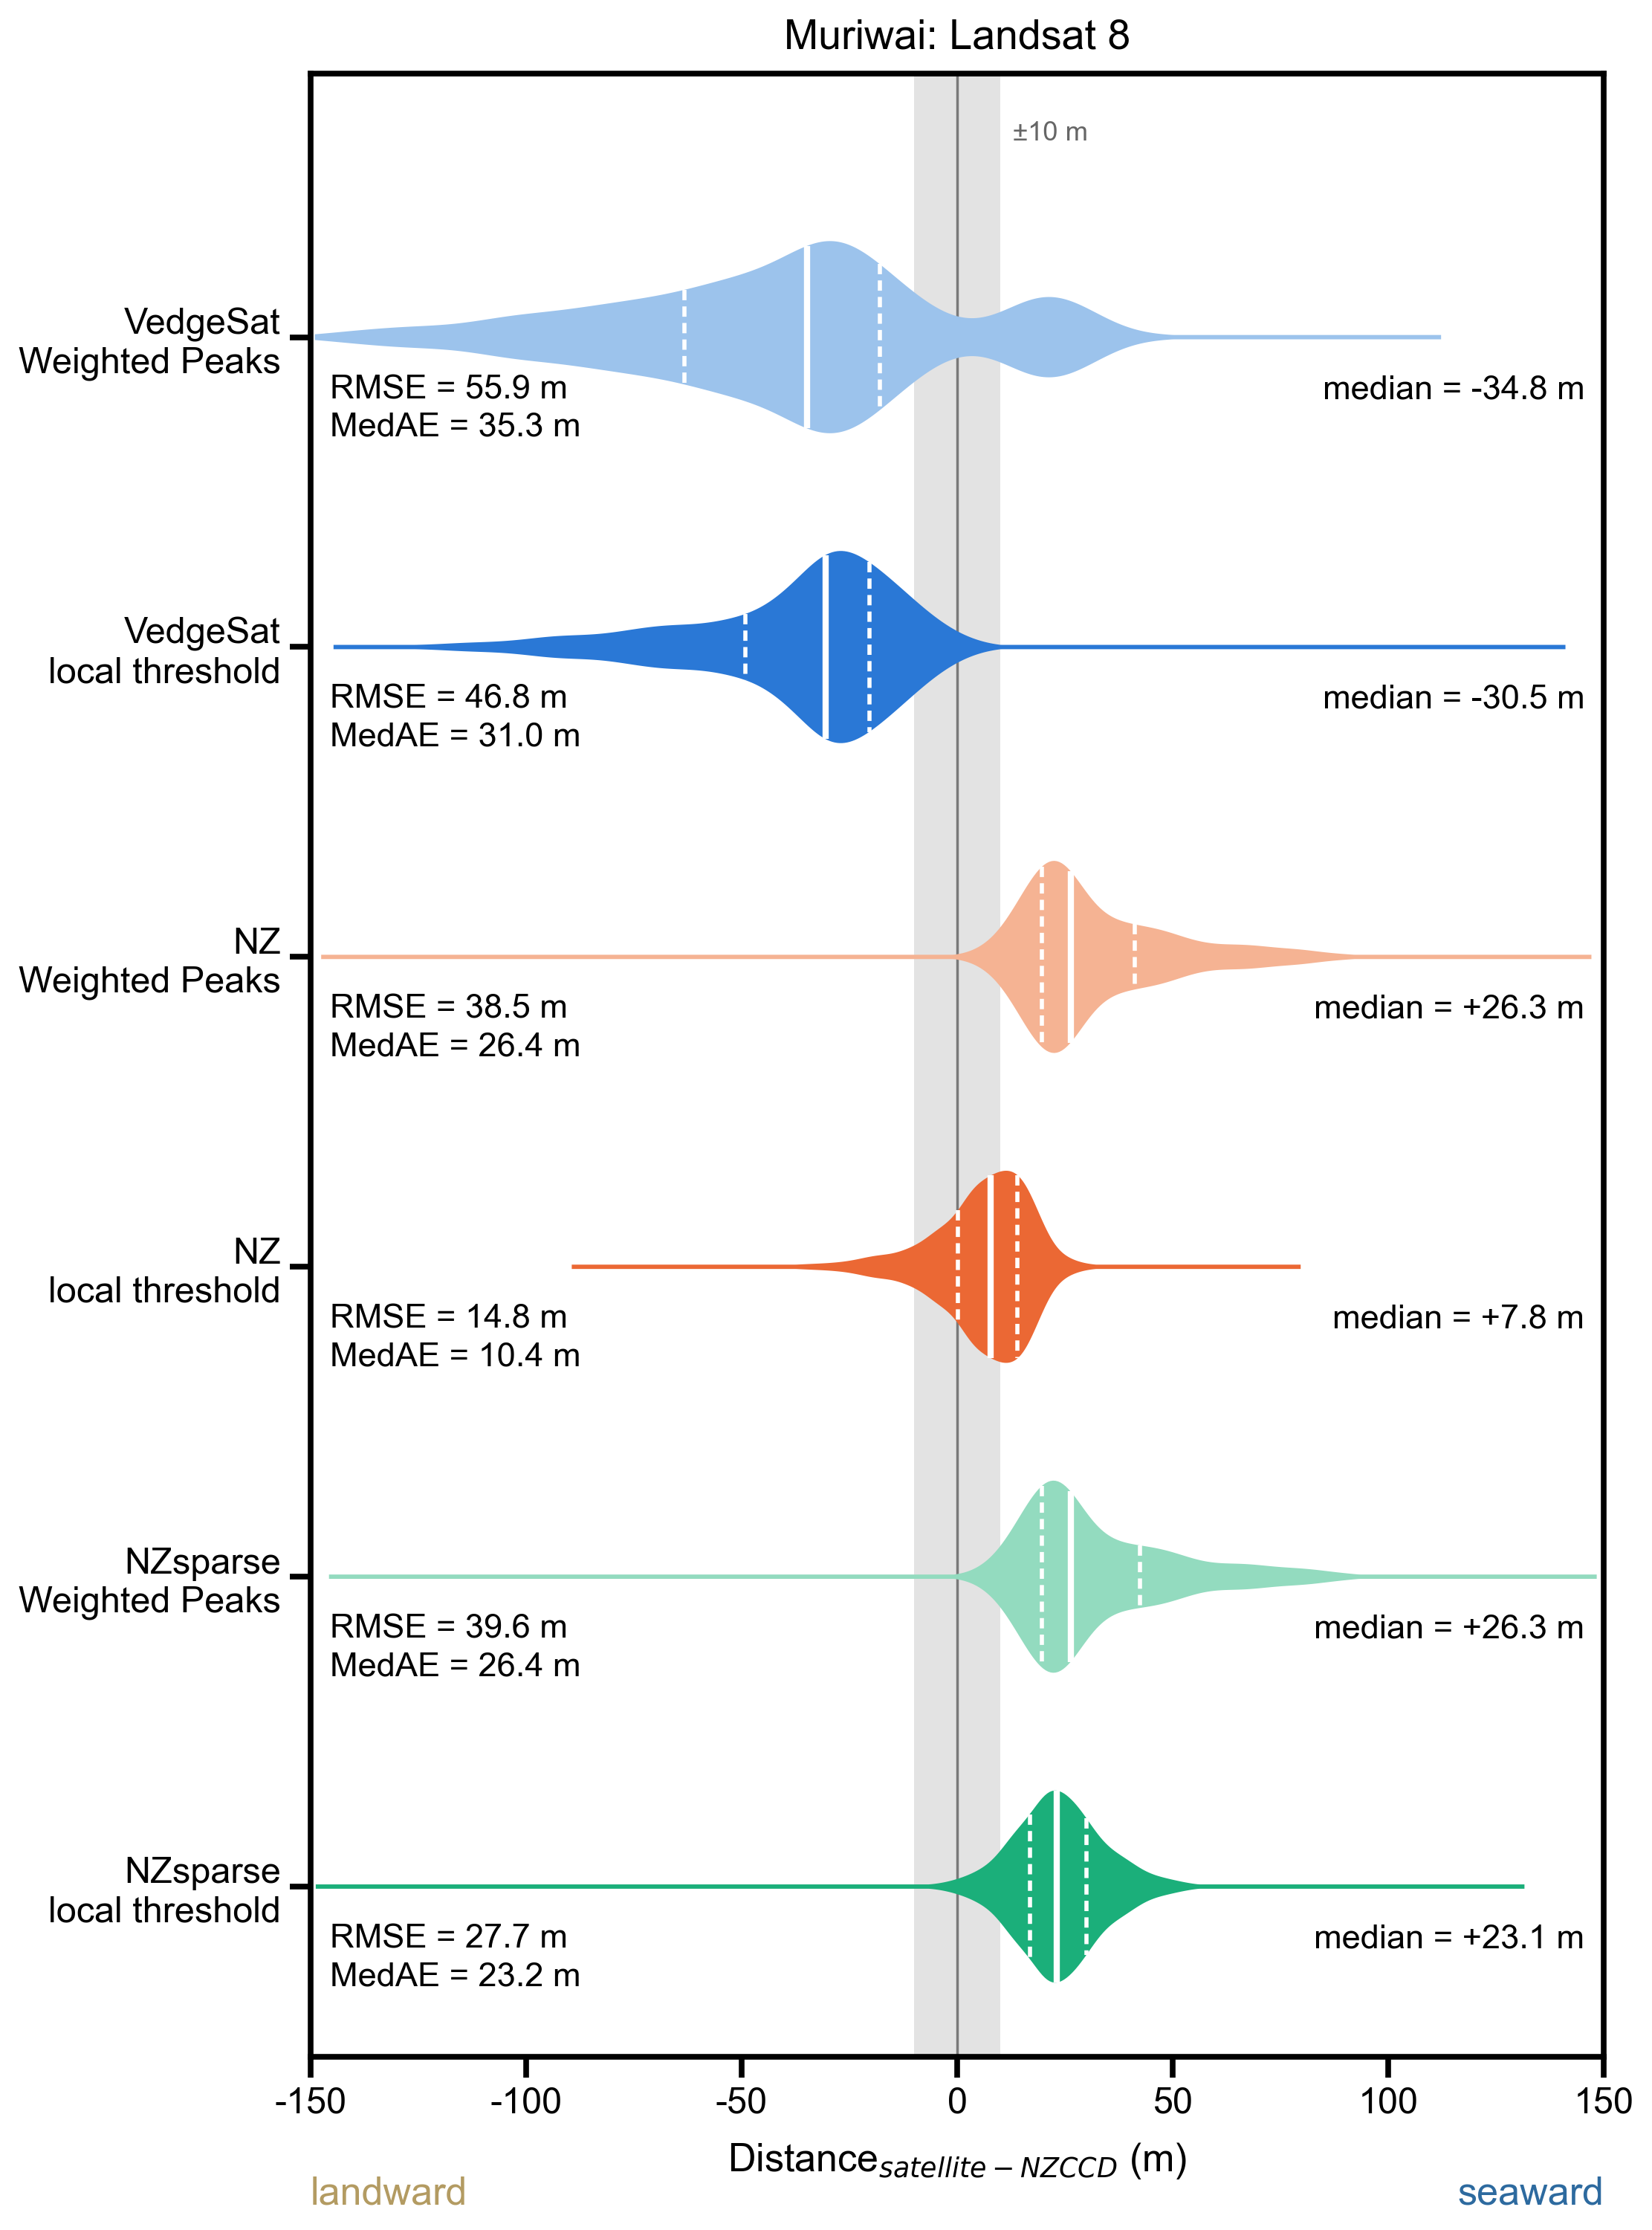

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\violins_Muriwai_L8.png

Combined S2: transects per site (first run) Muriwai 2327, Pakiri 1964


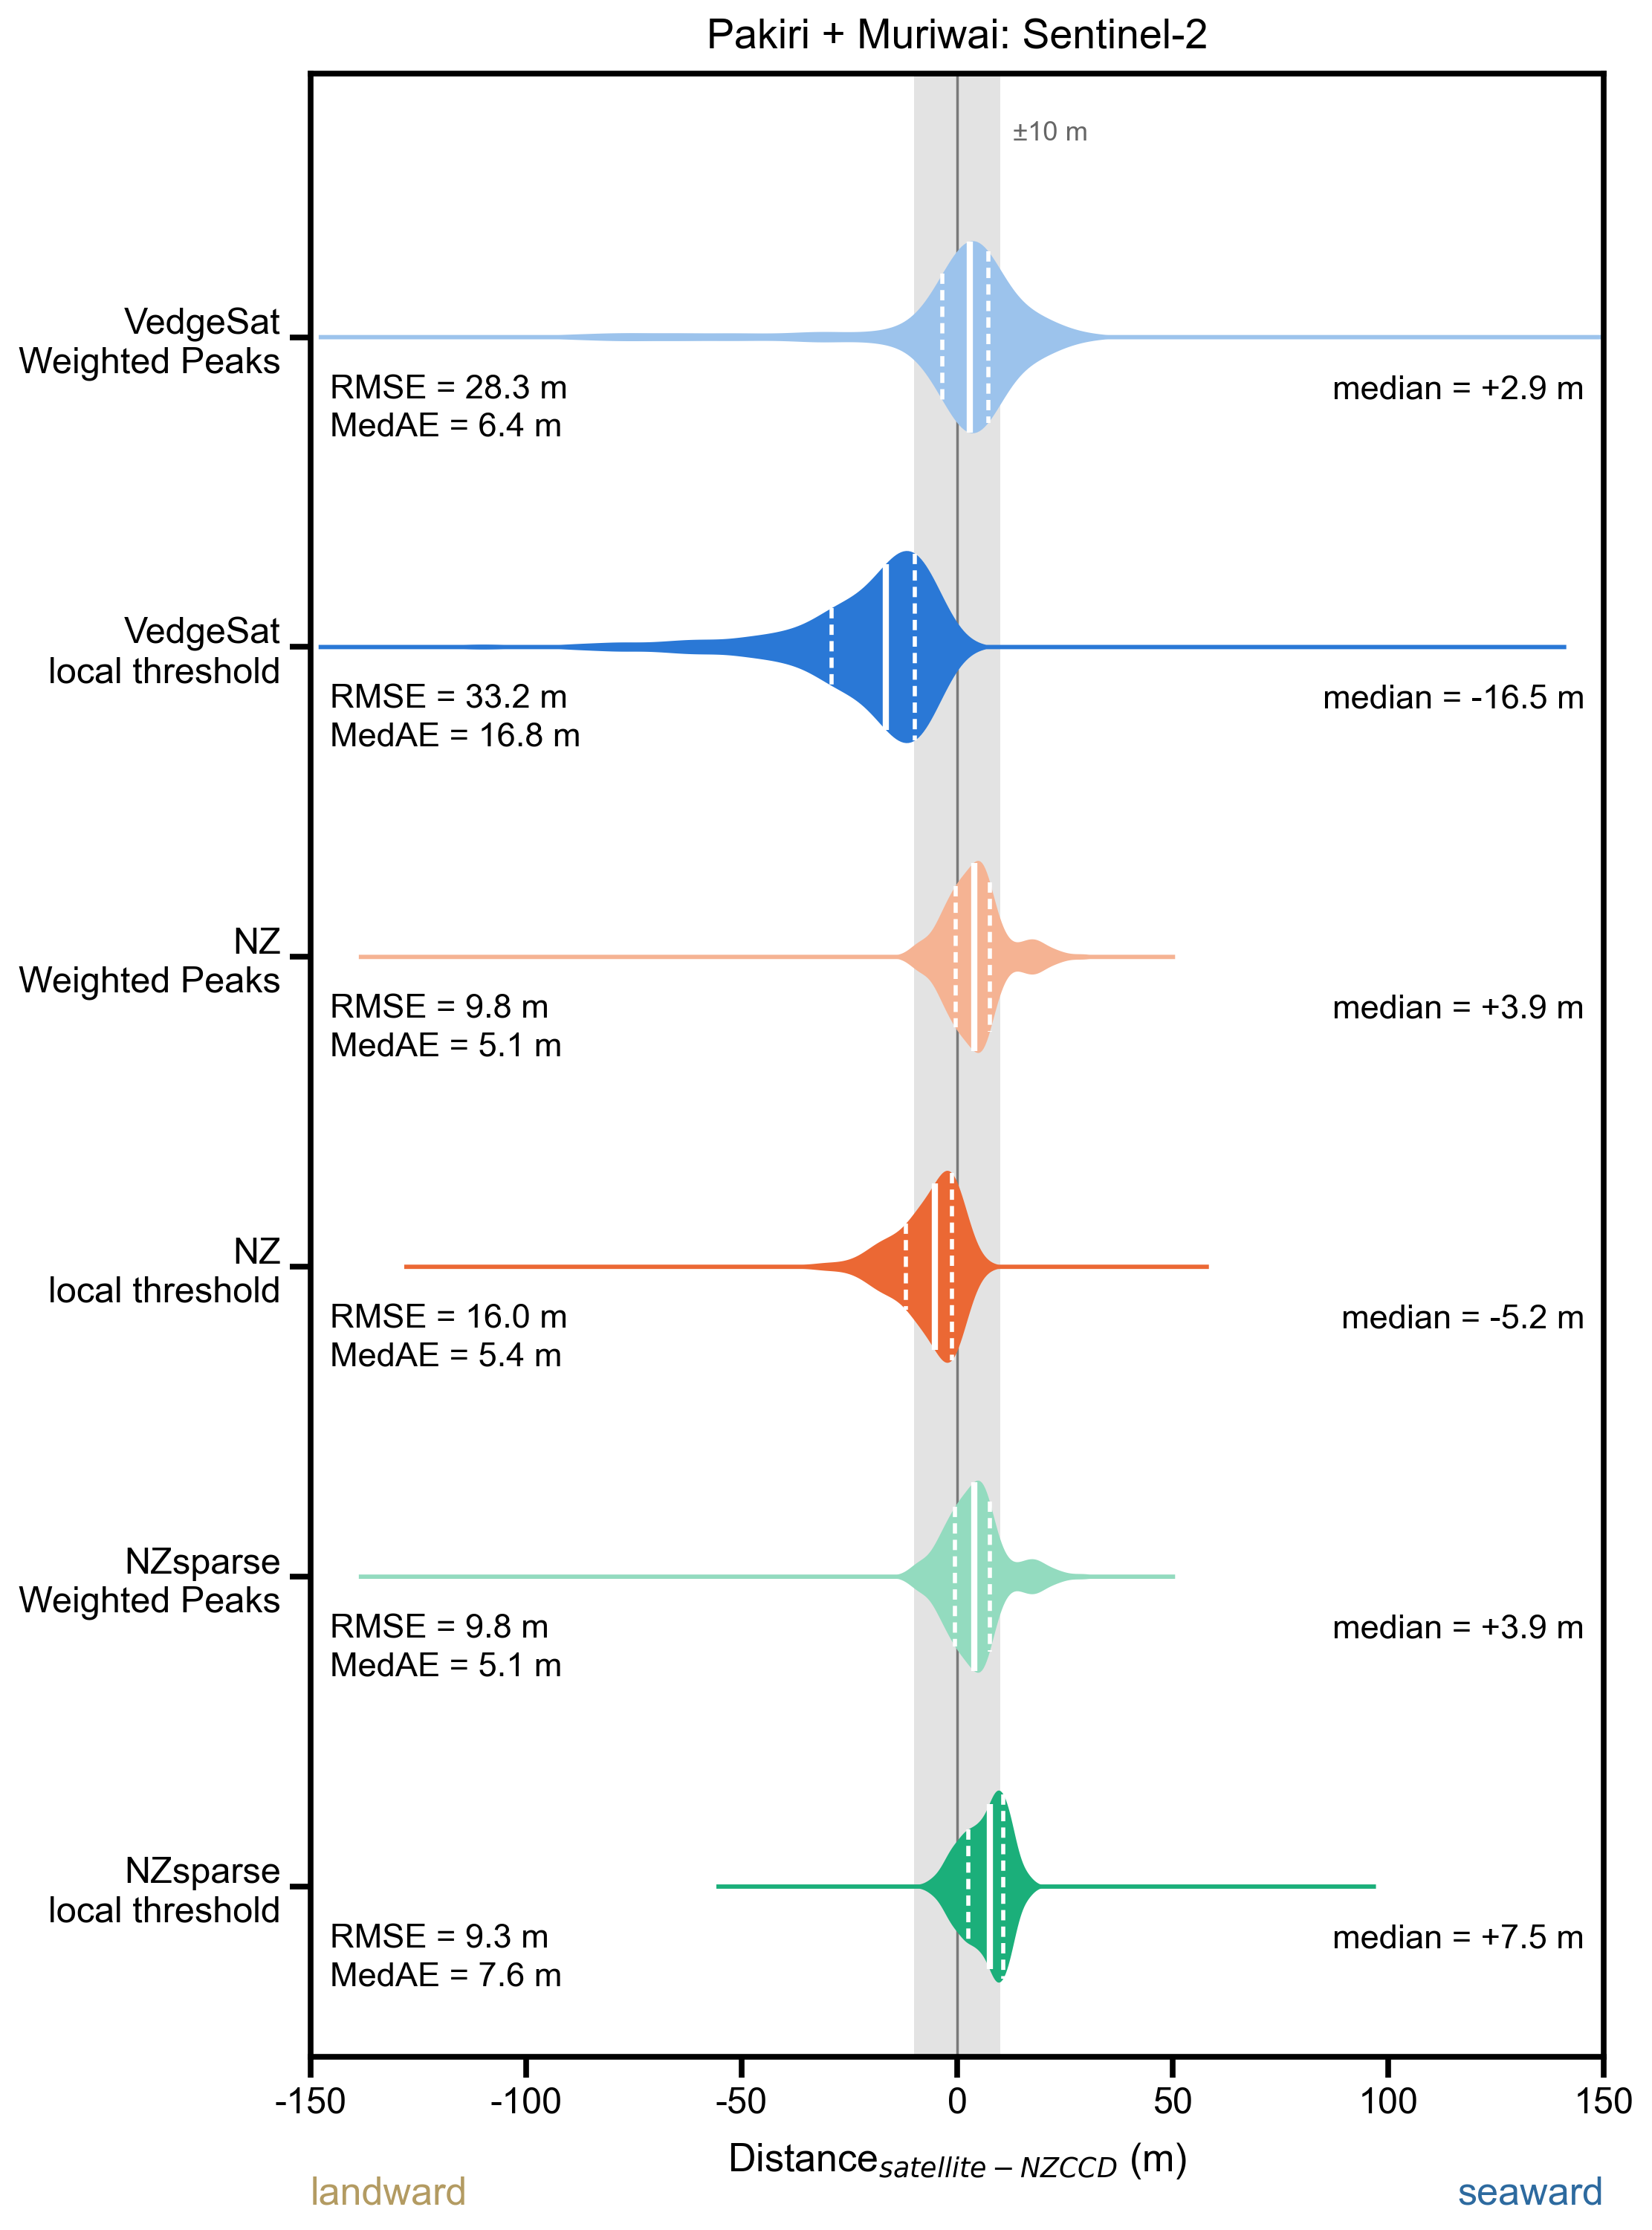

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\violins_Combined_S2.png

Combined L8: transects per site (first run) Muriwai 2666, Pakiri 1221


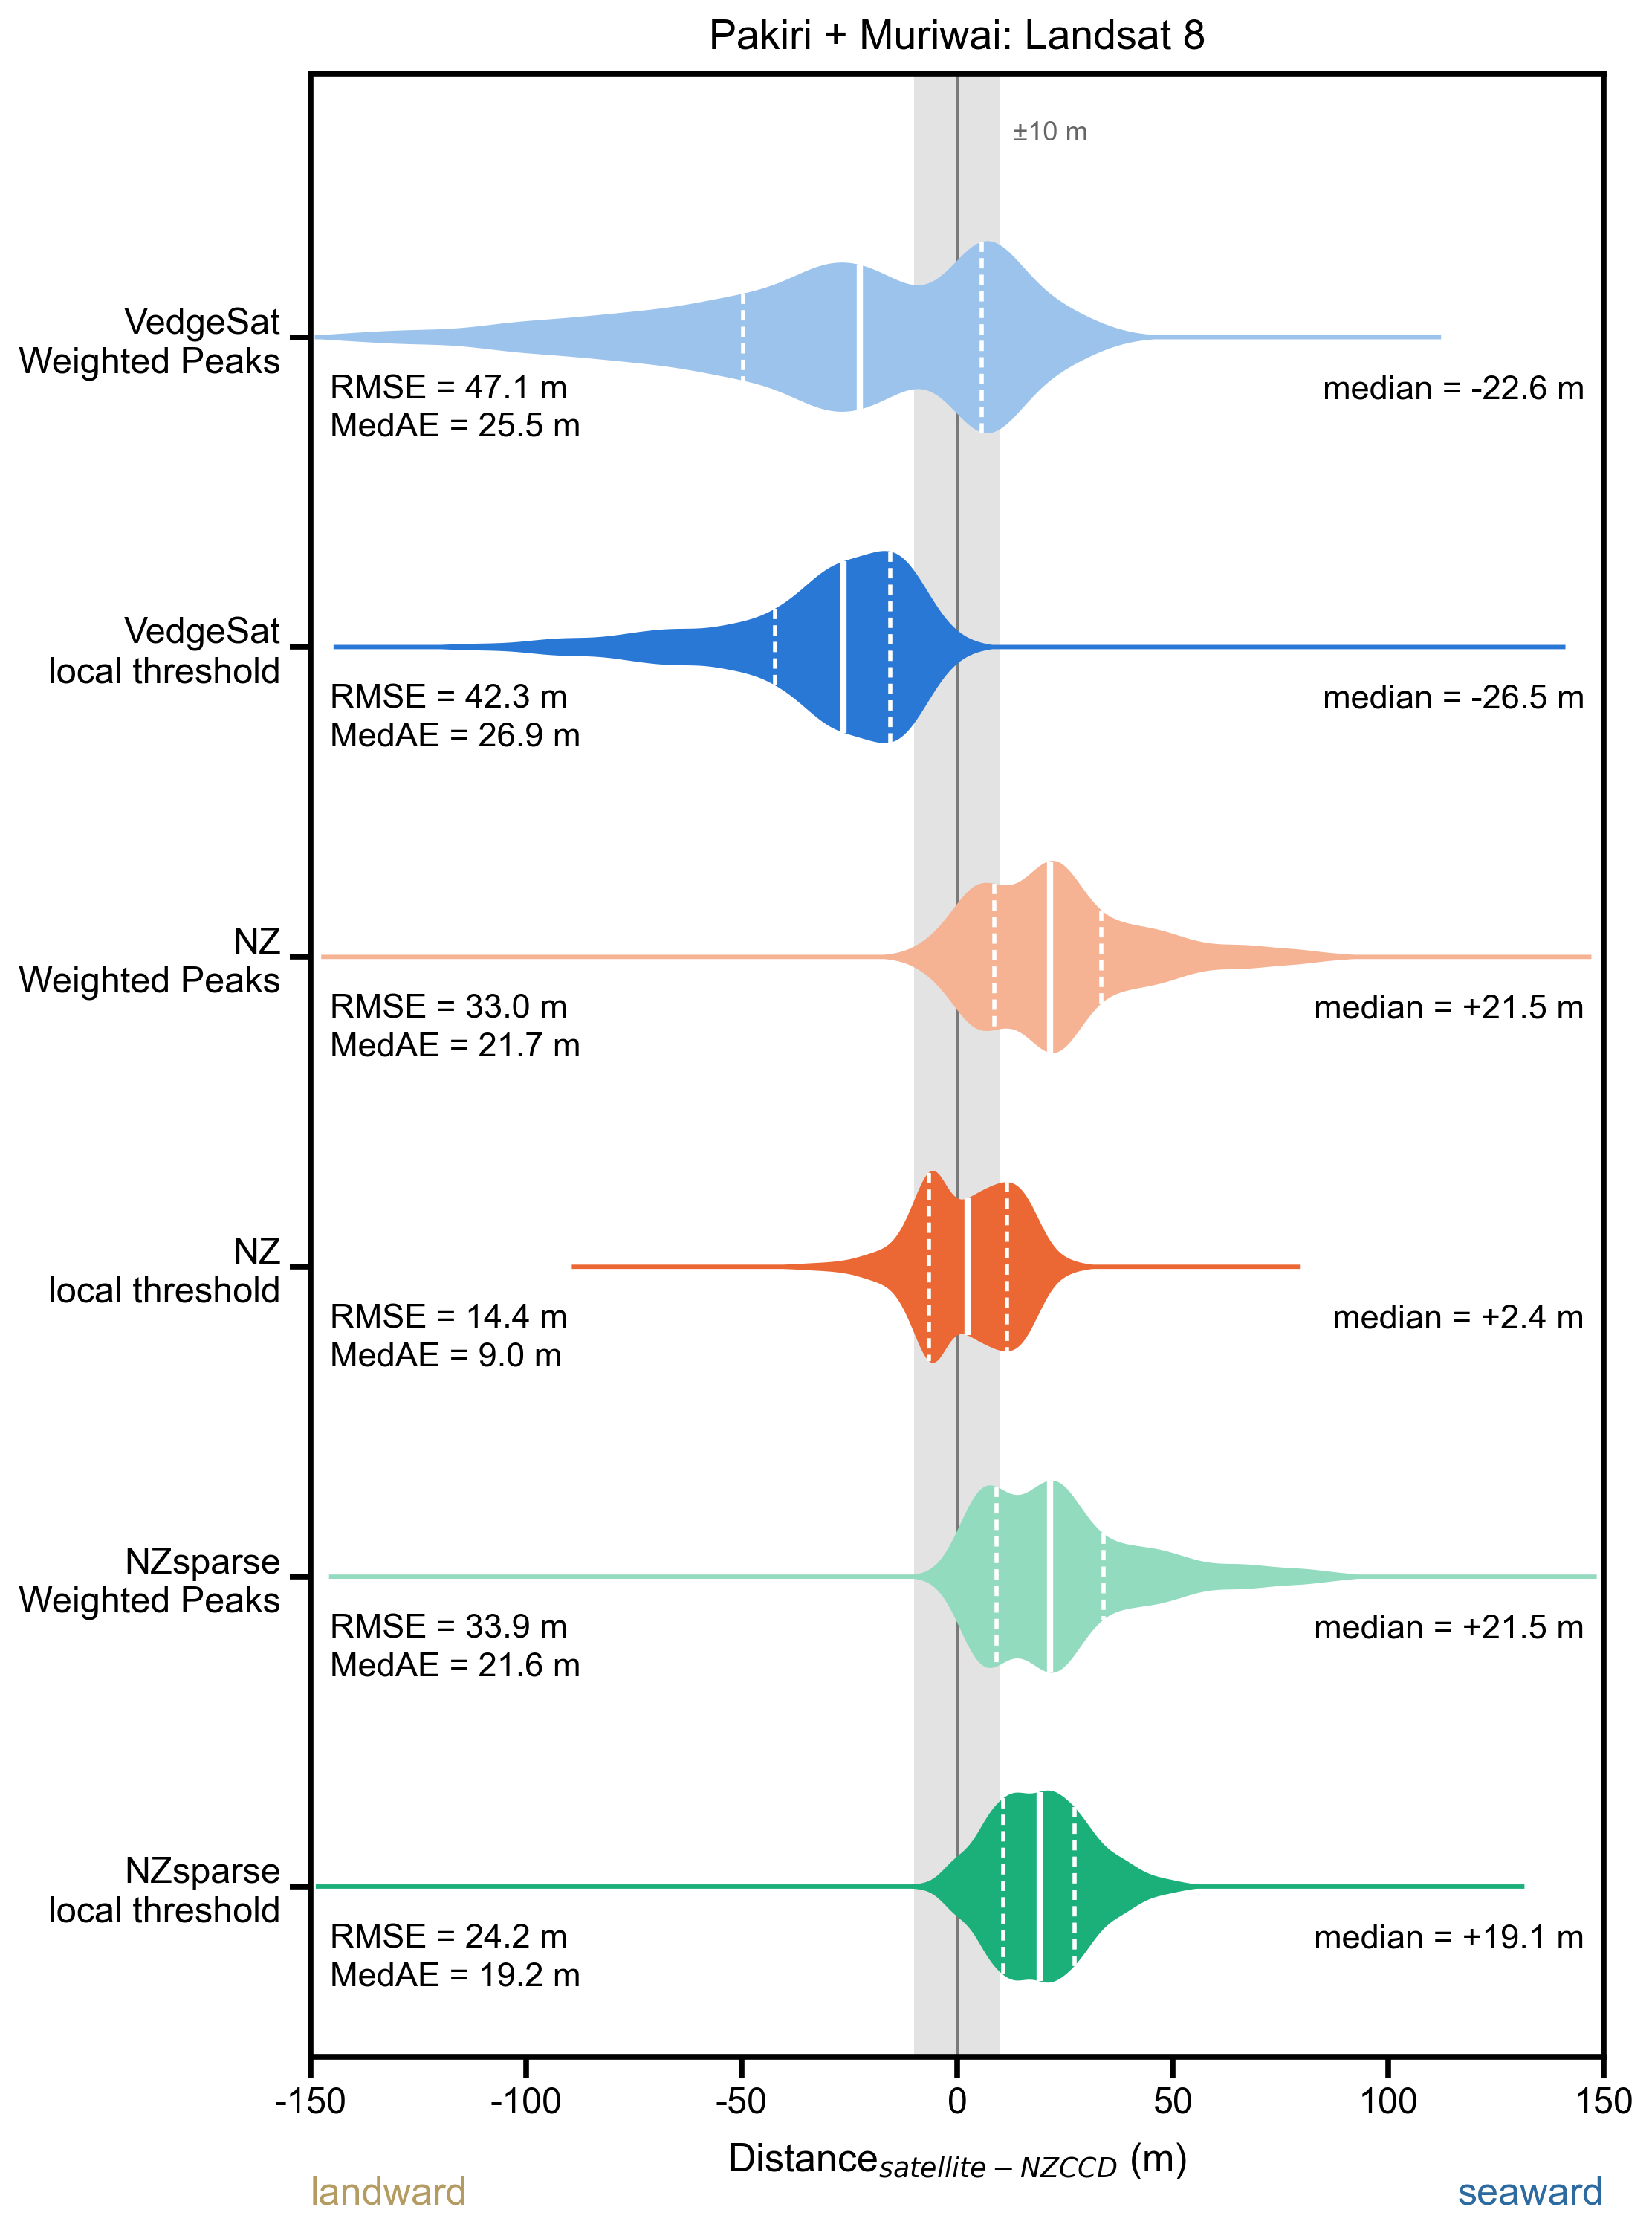

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\violins_Combined_L8.png


In [12]:
# =====================================================================================
# Edge error vs NZCCD: violins for the expanded validation (BatchS), styled after Muir et al. (2024)
# =====================================================================================
# Reads errors_all.csv saved by the batch comparison cell, so it redraws in seconds without
# recomputing transects. Uses only images every run of a site and satellite shares.
# One figure per site and satellite (4), plus one per satellite with both sites pooled (2).
# All six scenarios are drawn; delete a line from RUNS to drop a scenario from every figure.
# In each violin: white solid line = median, white dashed lines = 25th and 75th percentiles.
# Positive distance = satellite edge seaward of NZCCD. Saves violins_<site>_<sat>.png next to the CSV.

import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook, mlab, transforms
from IPython.display import Image, display

# ---------------- EDIT ME ----------------
CSV = r'C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\errors_all.csv'
OUT = os.path.dirname(CSV)
SITES = ['Pakiri', 'Muriwai']
SATS = ['S2', 'L8']
# run in errors_all.csv -> label on the plot (top to bottom); leave a run out to drop it
RUNS = {
    'Default (WP)':     'VedgeSat\nWeighted Peaks',
    'Default (local)':  'VedgeSat\nlocal threshold',
    'NZ (WP)':          'NZ\nWeighted Peaks',
    'NZ (local)':       'NZ\nlocal threshold',
    'NZsparse (WP)':    'NZsparse\nWeighted Peaks',
    'NZsparse (local)': 'NZsparse\nlocal threshold',
}
COLOUR = {'Default (WP)': '#9cc3ec', 'Default (local)': '#2a78d6',     # VedgeSat: light / full blue
          'NZ (WP)': '#f5b393', 'NZ (local)': '#eb6834',               # NZ: light / full orange
          'NZsparse (WP)': '#93dbbf', 'NZsparse (local)': '#1baf7a'}   # NZsparse: light / full green
EXTRA = ['MedAE']          # extra values printed under RMSE: any of 'MedAE', 'within', 'MAE'
XLIM = 150          # m either side of NZCCD = the full transect length, so every error is shown
CORE = 150          # m either side drawn at full scale (per site as a dict if ever needed)
OUTER = 1           # 1 = plain linear axis (no compression). Below 1: beyond ±CORE the axis is compressed to this fraction, so the tails fit without
                    # squeezing the main body (shaded and marked on the plot); 1 = plain linear axis
WITHIN = 10         # m, the accuracy target (grey band)
COMBINE = True      # also draw one figure per satellite with all sites pooled (transects pooled, so larger sites weigh more)
# ------------------------------------------

SAT_NAME = {'S2': 'Sentinel-2', 'L8': 'Landsat 8', 'L9': 'Landsat 9'}
WIDTH, TAIL = 0.62, 0.007   # violin height (row units) and minimum half-height so sparse tails stay visible

def common_only(E):
    keep = []
    E = E.assign(img=E.nzccd_date.astype(str) + '|' + E.date.astype(str))
    for (site, sat), g in E.groupby(['site', 'satname']):
        shared = set.intersection(*[set(gg.img) for _, gg in g[g.run.isin(RUNS)].groupby('run')])
        dropped = sorted(set(g.img) - shared)
        if dropped:
            print(f'{site} {sat}: images not in every run, left out: {dropped}')
        keep.append(g[g.img.isin(shared)])
    return pd.concat(keep)

def draw_violin(ax, e, y, colour, xl):
    kde = lambda X, coords: mlab.GaussianKDE(X, 'scott').evaluate(coords)
    st = cbook.violin_stats(np.clip(e, -xl, xl), kde, points=500)[0]
    xs, half = st['coords'], st['vals']
    half = np.maximum(0.5 * WIDTH * half / half.max(), TAIL)
    ax.fill_between(xs, y - half, y + half, facecolor=colour, edgecolor='none', zorder=2)
    for q, ls, lw in [(25, (0, (2.5, 1.5)), 1.6), (50, '-', 2.4), (75, (0, (2.5, 1.5)), 1.6)]:
        xq = np.percentile(e, q)
        if -xl < xq < xl:
            h = np.interp(xq, xs, half)
            ax.plot([xq, xq], [y - h, y + h], color='white', lw=lw, ls=ls, zorder=3, solid_capstyle='butt')
    return xs, half

def axis_scale(core):
    """Linear inside ±core, compressed by OUTER beyond it (a piecewise-linear axis)."""
    fwd = lambda x: np.where(np.abs(x) <= core, x, np.sign(x) * (core + (np.abs(x) - core) * OUTER))
    inv = lambda y: np.where(np.abs(y) <= core, y, np.sign(y) * (core + (np.abs(y) - core) / OUTER))
    return fwd, inv

def figure(E, site, sat, title=None):
    d = E[(E.site == site) & (E.satname == sat)]
    runs = [r for r in RUNS if (d.run == r).any()]
    fig, ax = plt.subplots(figsize=(9, 1.75 * len(runs) + 1.6))
    xl = XLIM.get(site, 300) if isinstance(XLIM, dict) else XLIM
    core = min(CORE.get(site, 100) if isinstance(CORE, dict) else CORE, xl)
    if OUTER < 1 and core < xl:
        ax.set_xscale('function', functions=axis_scale(core))
        for sgn in (-1, 1):                      # mark the compressed part of the axis
            ax.axvspan(sgn * core, sgn * xl, color='#f3f3f3', zorder=0, lw=0)
            ax.axvline(sgn * core, color='#bdbdbd', lw=1, ls=(0, (3, 2)), zorder=1)
    ax.axvspan(-WITHIN, WITHIN, color='#e3e3e3', zorder=0, lw=0)
    ax.axvline(0, color='#7a7a7a', lw=1, zorder=1)
    side = transforms.blended_transform_factory(ax.transAxes, ax.transData)   # x in axes fraction, y in rows
    for i, run in enumerate(runs):
        e = d[d.run == run].error_m.values
        draw_violin(ax, e, i, COLOUR[run], xl)
        med, rmse = np.median(e), np.sqrt(np.mean(e**2))
        # RMSE (and any extras) bottom-left of the row, just below the tail; median bottom-right
        lines = [f'RMSE = {rmse:.1f} m']
        for k in EXTRA:
            lines.append({'MedAE': f'MedAE = {np.median(np.abs(e)):.1f} m',
                          'MAE': f'MAE = {np.mean(np.abs(e)):.1f} m',
                          'within': f'{100*np.mean(np.abs(e) <= WITHIN):.0f}% within {WITHIN} m'}[k])
        ax.text(0.015, i + 0.12, '\n'.join(lines), fontsize=13, ha='left', va='top', linespacing=1.3, transform=side)
        ax.text(0.985, i + 0.12, f'median = {med:+.1f} m', fontsize=13, ha='right', va='top', transform=side)
        lo, hi = int(np.sum(e < -xl)), int(np.sum(e > xl))
        if lo:
            ax.text(0.01, i - 0.06, f'< {lo} beyond −{xl} m', fontsize=10, color='#555', va='bottom', transform=side)
        if hi:
            ax.text(0.99, i - 0.06, f'{hi} beyond {xl} m >', fontsize=10, color='#555', va='bottom', ha='right', transform=side)
    ax.text(WITHIN * 1.3, -0.62, f'±{WITHIN} m', fontsize=10.5, color='#666', ha='left', va='bottom')
    if OUTER < 1 and core < xl:
        ax.text(0.985, 0.985, f'axis compressed\nbeyond ±{core} m (shaded)', transform=ax.transAxes,
                fontsize=10, color='#777', ha='right', va='top')
    ax.set_yticks(range(len(runs)))
    ax.set_yticklabels([RUNS[r] for r in runs], fontsize=13)
    ax.set_ylim(len(runs) - 0.45, -0.85)   # inverted: first run at the top
    ax.set_xlim(-xl, xl)
    step = 25 if core <= 50 else 50
    ticks = list(np.arange(-core, core + 1, step))
    ticks = sorted(set(ticks + ([-xl, xl] if core < xl else [])))   # only the ends in the compressed part
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'{t:g}' for t in ticks])
    ax.tick_params(axis='both', labelsize=14, width=2.2, length=8)
    for sp in ax.spines.values():
        sp.set_linewidth(2.2)
    ax.set_xlabel('Distance$_{satellite-NZCCD}$ (m)', fontsize=15, labelpad=8)
    ax.annotate('landward', xy=(0, 0), xycoords='axes fraction', xytext=(0, -46), textcoords='offset points',
                color='#b39b62', fontsize=15, ha='left', va='top')
    ax.annotate('seaward', xy=(1, 0), xycoords='axes fraction', xytext=(0, -46), textcoords='offset points',
                color='#2d6a9f', fontsize=15, ha='right', va='top')
    ax.set_title(f'{title or site}: {SAT_NAME.get(sat, sat)}', fontsize=16, pad=10)
    fig.tight_layout()
    png = os.path.join(OUT, f'violins_{site}_{sat}.png')
    fig.savefig(png, dpi=250, bbox_inches='tight')
    plt.close(fig)                 # no plt.show(): with a window backend it waits until the window is closed
    display(Image(png, width=650))  # shown inline from the saved file instead
    print('saved', png)

E = common_only(pd.read_csv(CSV))
E = E[E.run.isin(RUNS)]
for site in SITES:
    for sat in SATS:
        if ((E.site == site) & (E.satname == sat)).any():
            figure(E, site, sat)

if COMBINE:
    for sat in SATS:
        C = E[(E.satname == sat) & E.site.isin(SITES)].copy()
        if C.empty:
            continue
        n = C[C.run == next(iter(RUNS))].groupby('site').size()
        print(f'\nCombined {sat}: transects per site (first run) ' + ', '.join(f'{k} {v}' for k, v in n.items()))
        C['site'] = 'Combined'
        figure(C, 'Combined', sat, title=' + '.join(SITES))

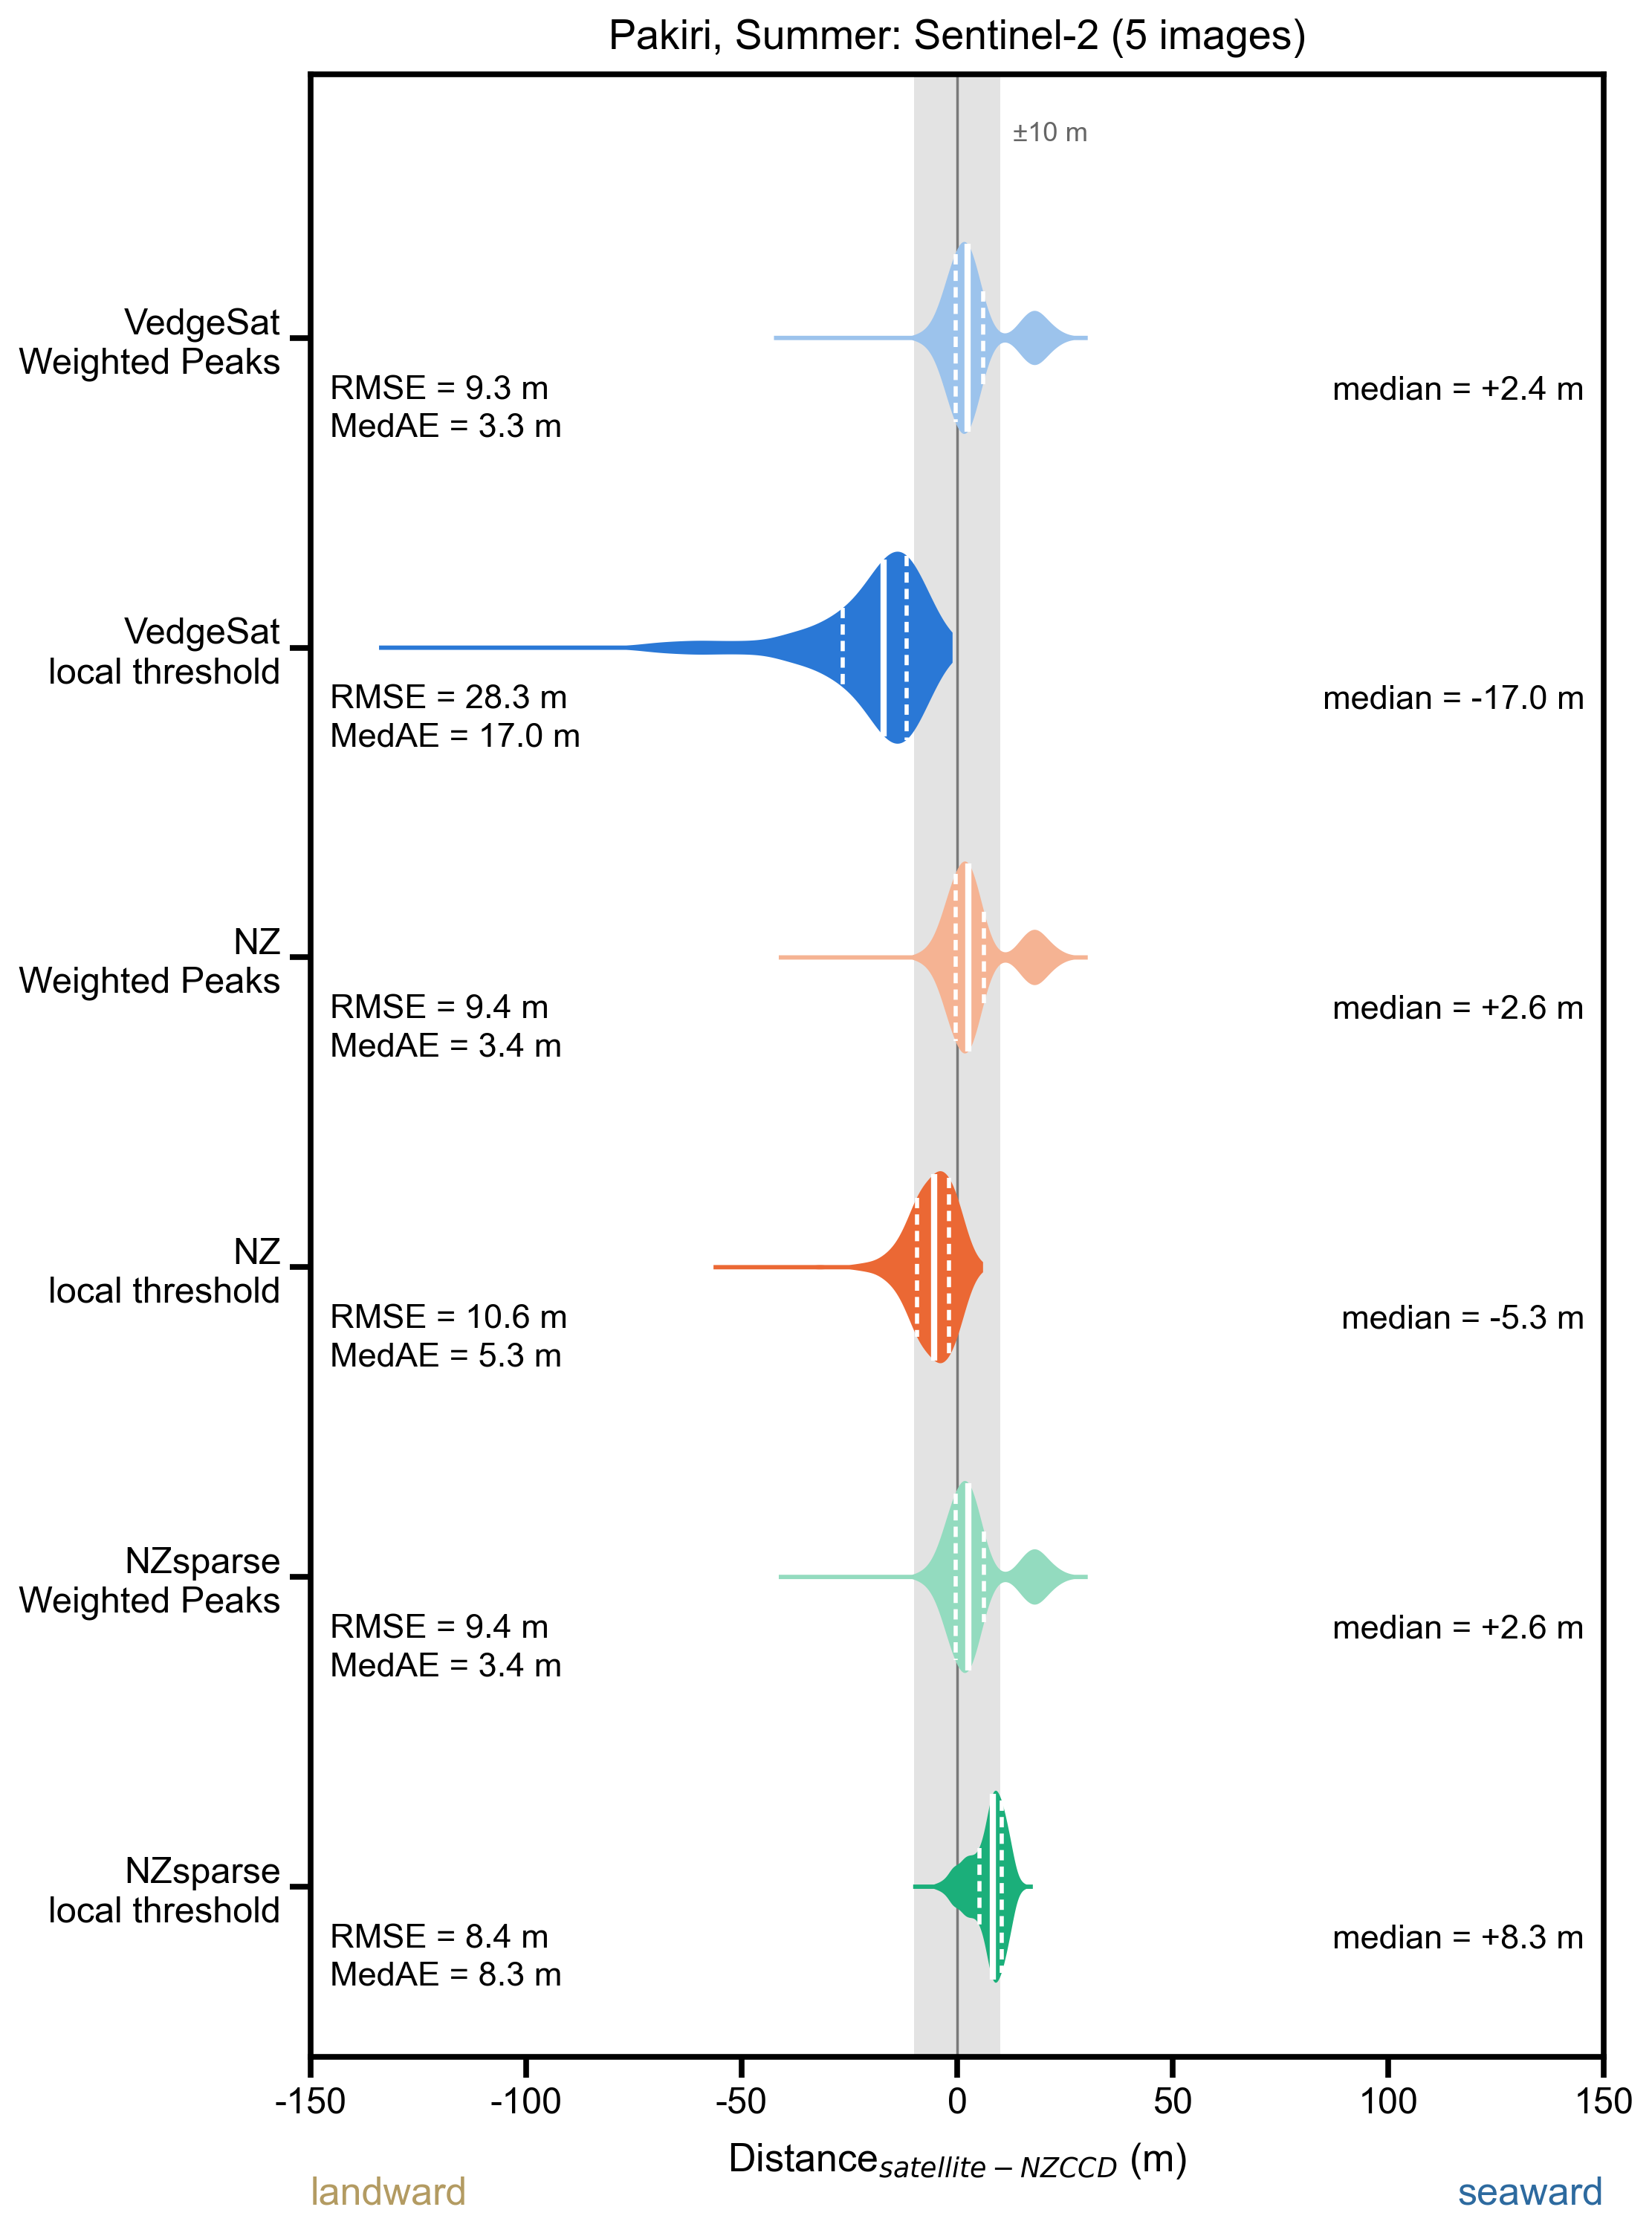

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\seasonal\violins_Pakiri_S2_Summer.png


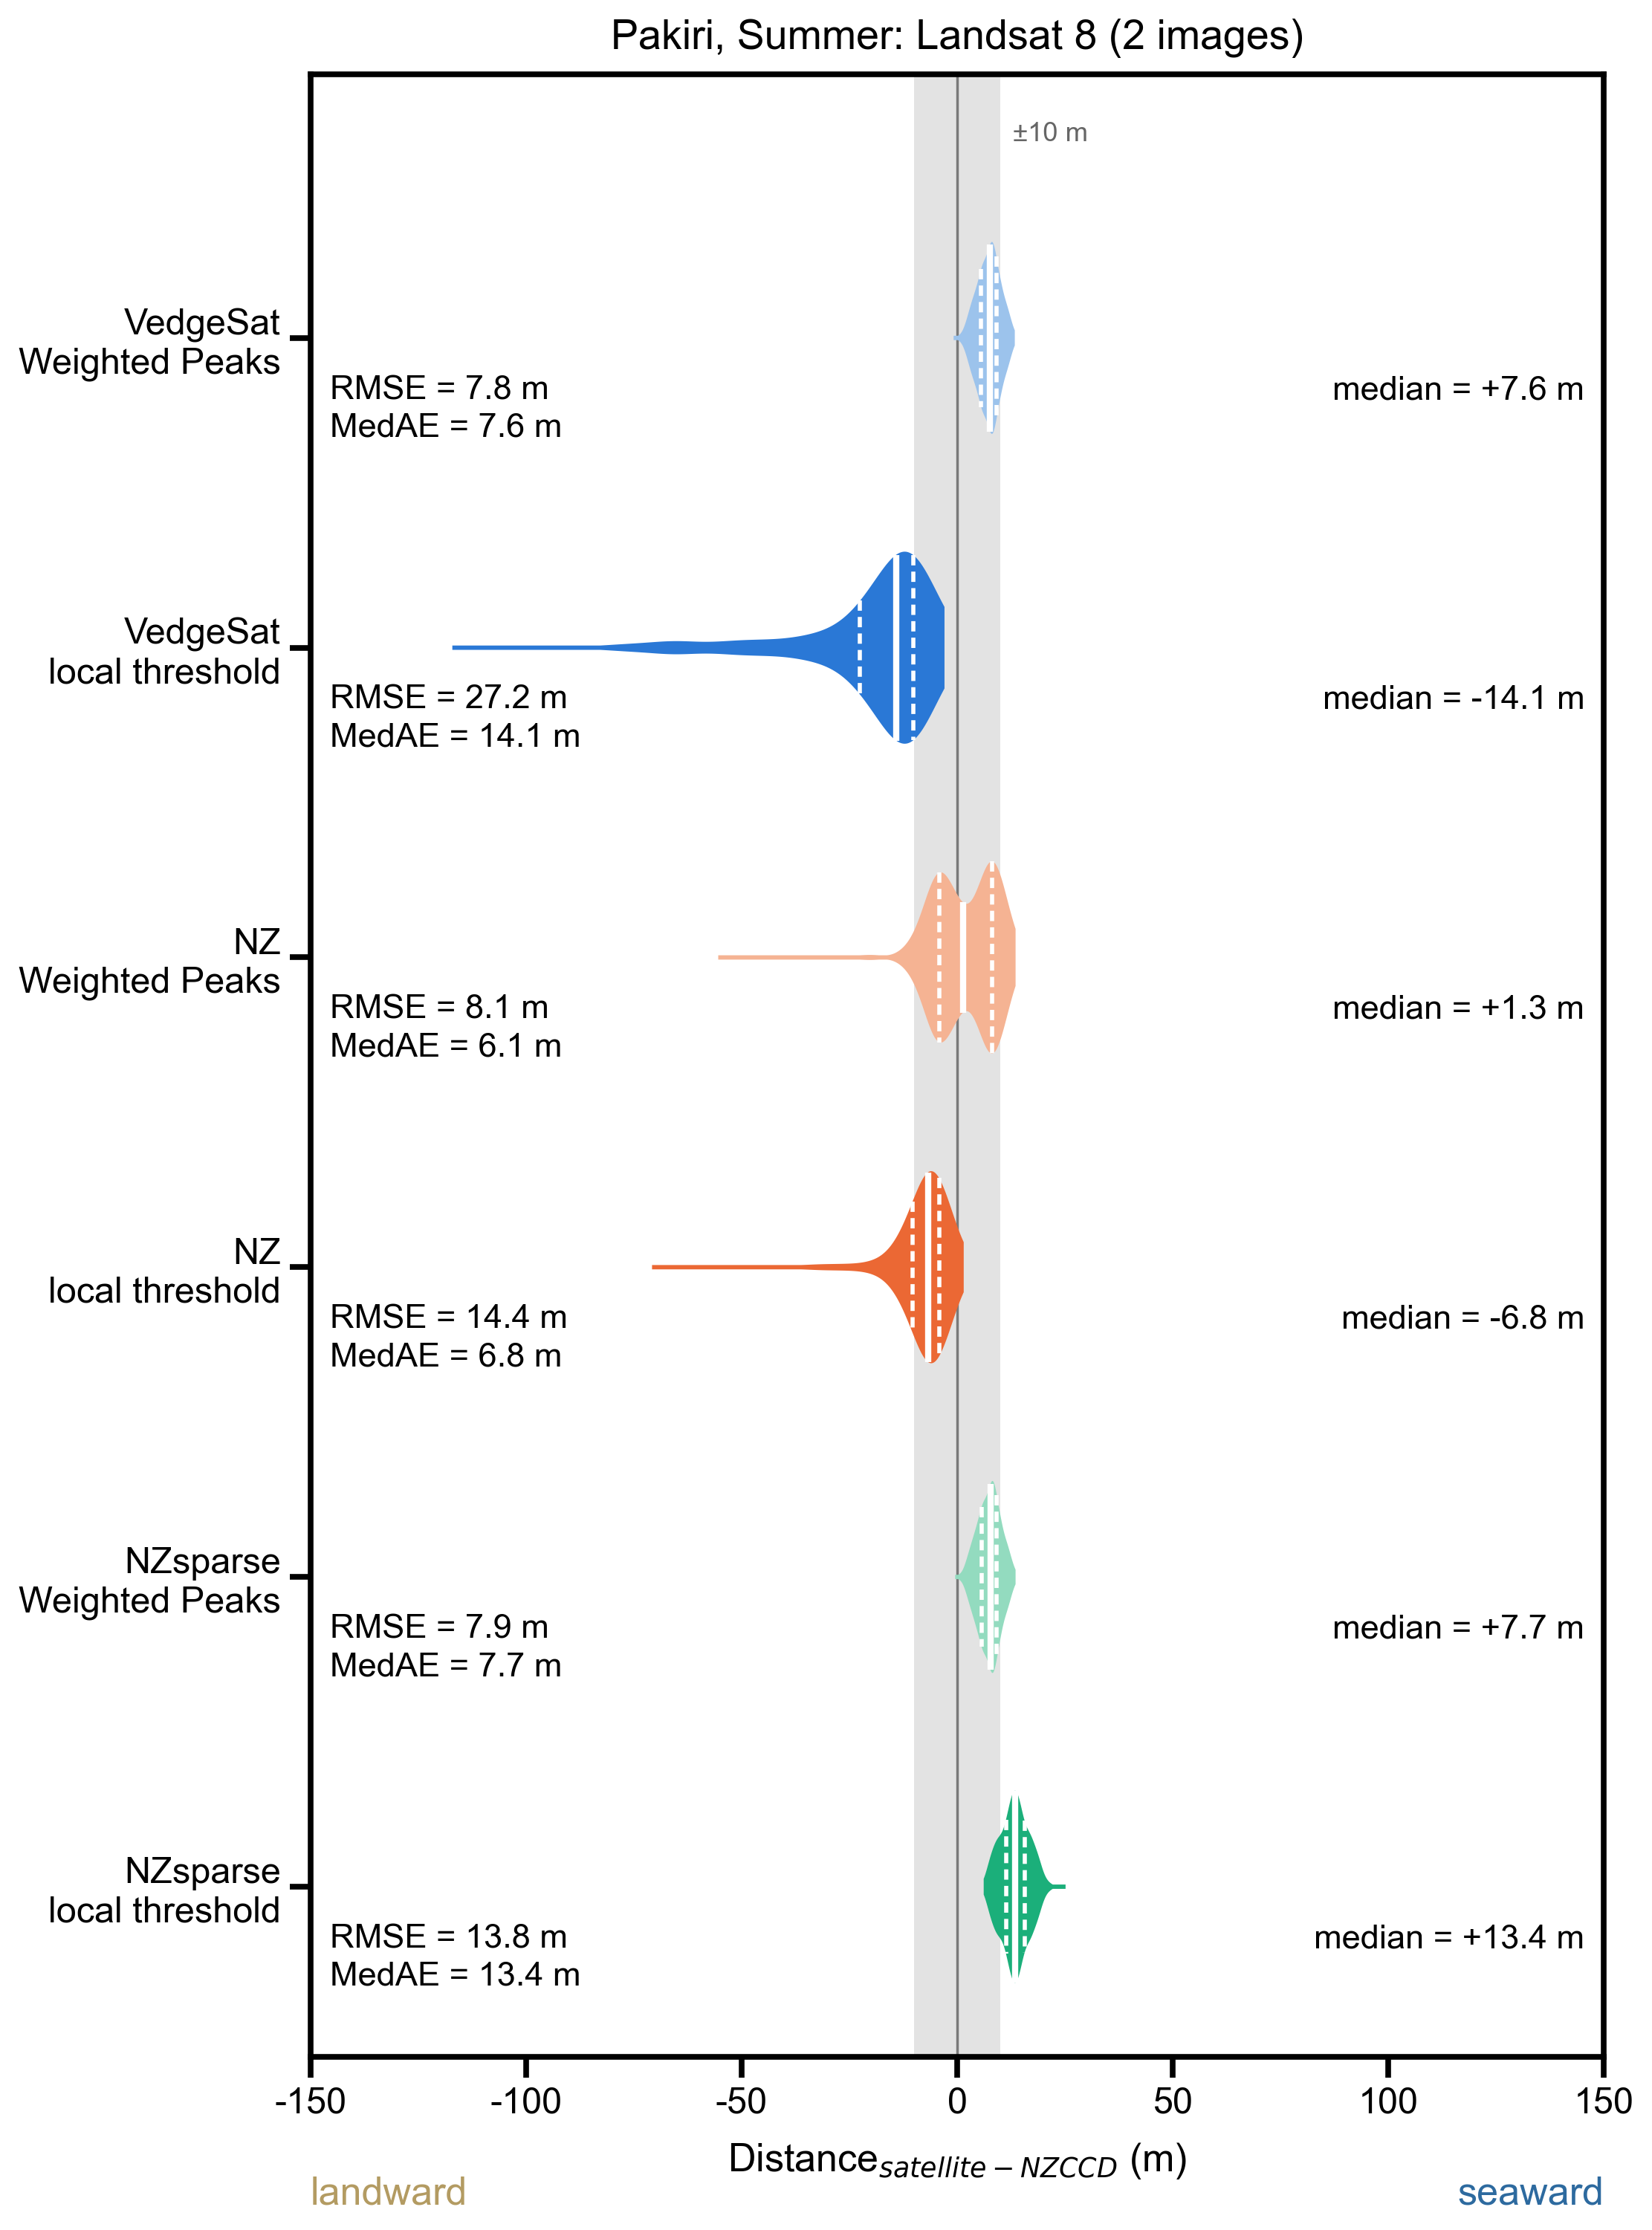

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\seasonal\violins_Pakiri_L8_Summer.png


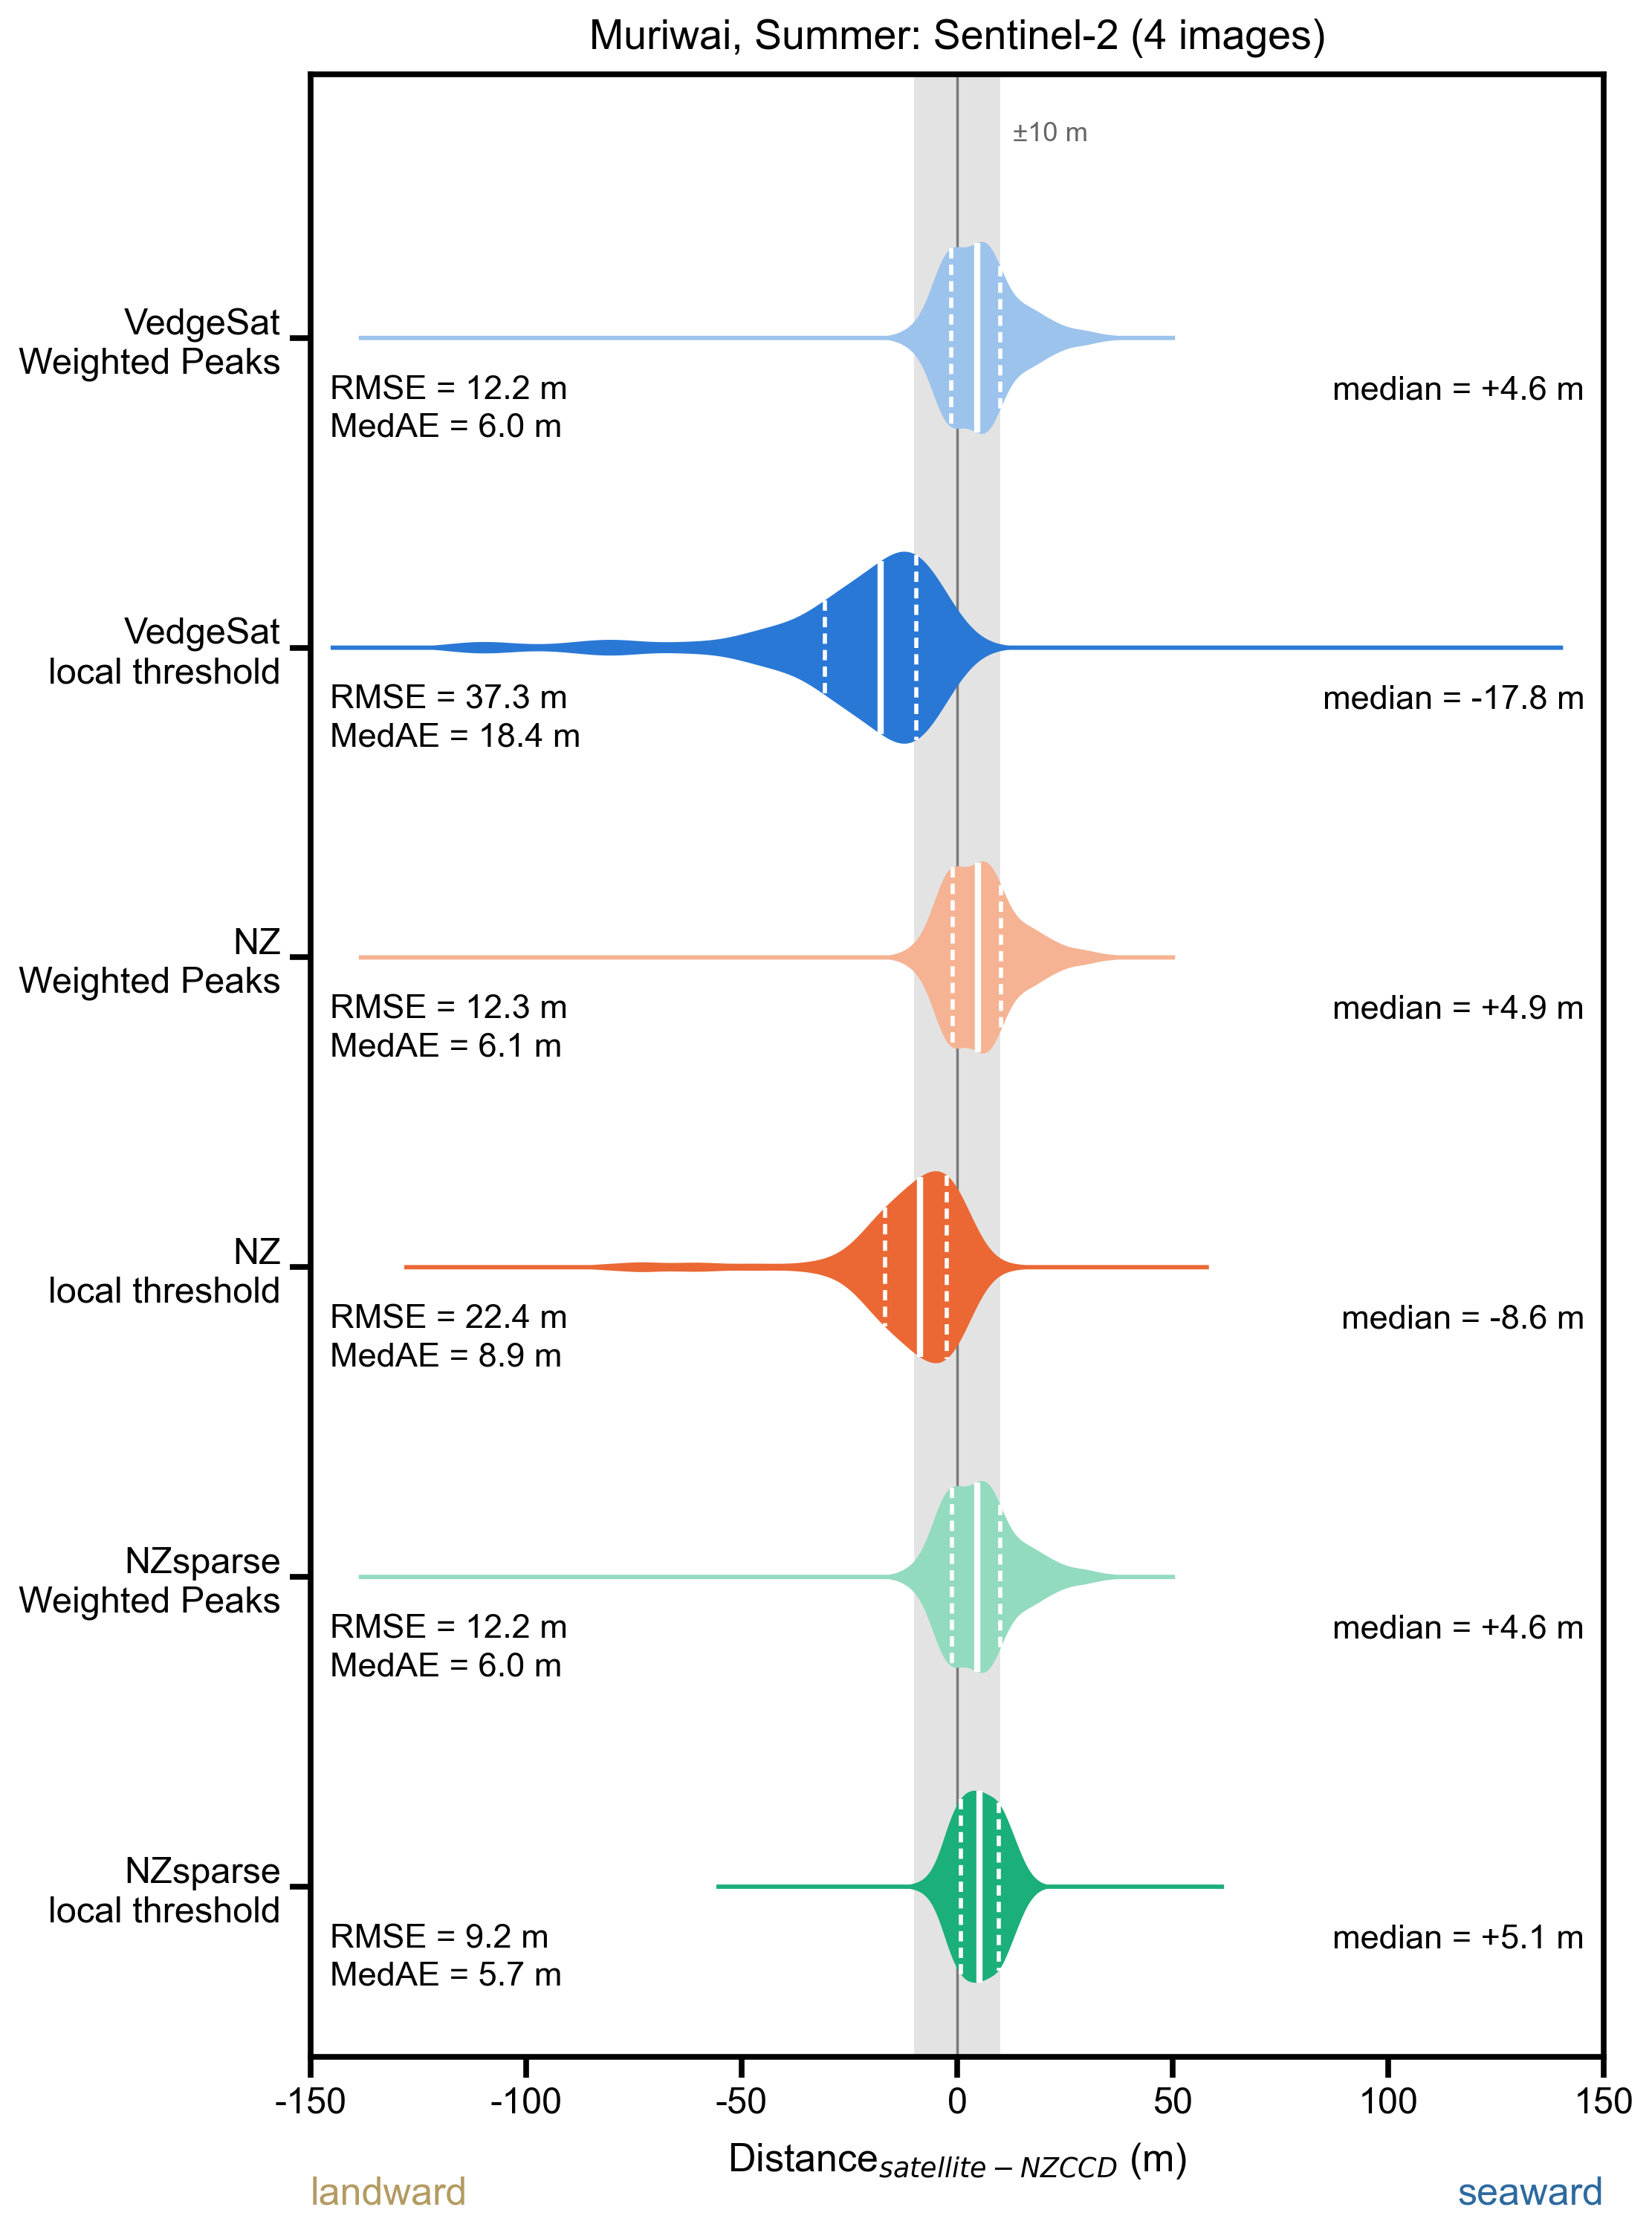

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\seasonal\violins_Muriwai_S2_Summer.png


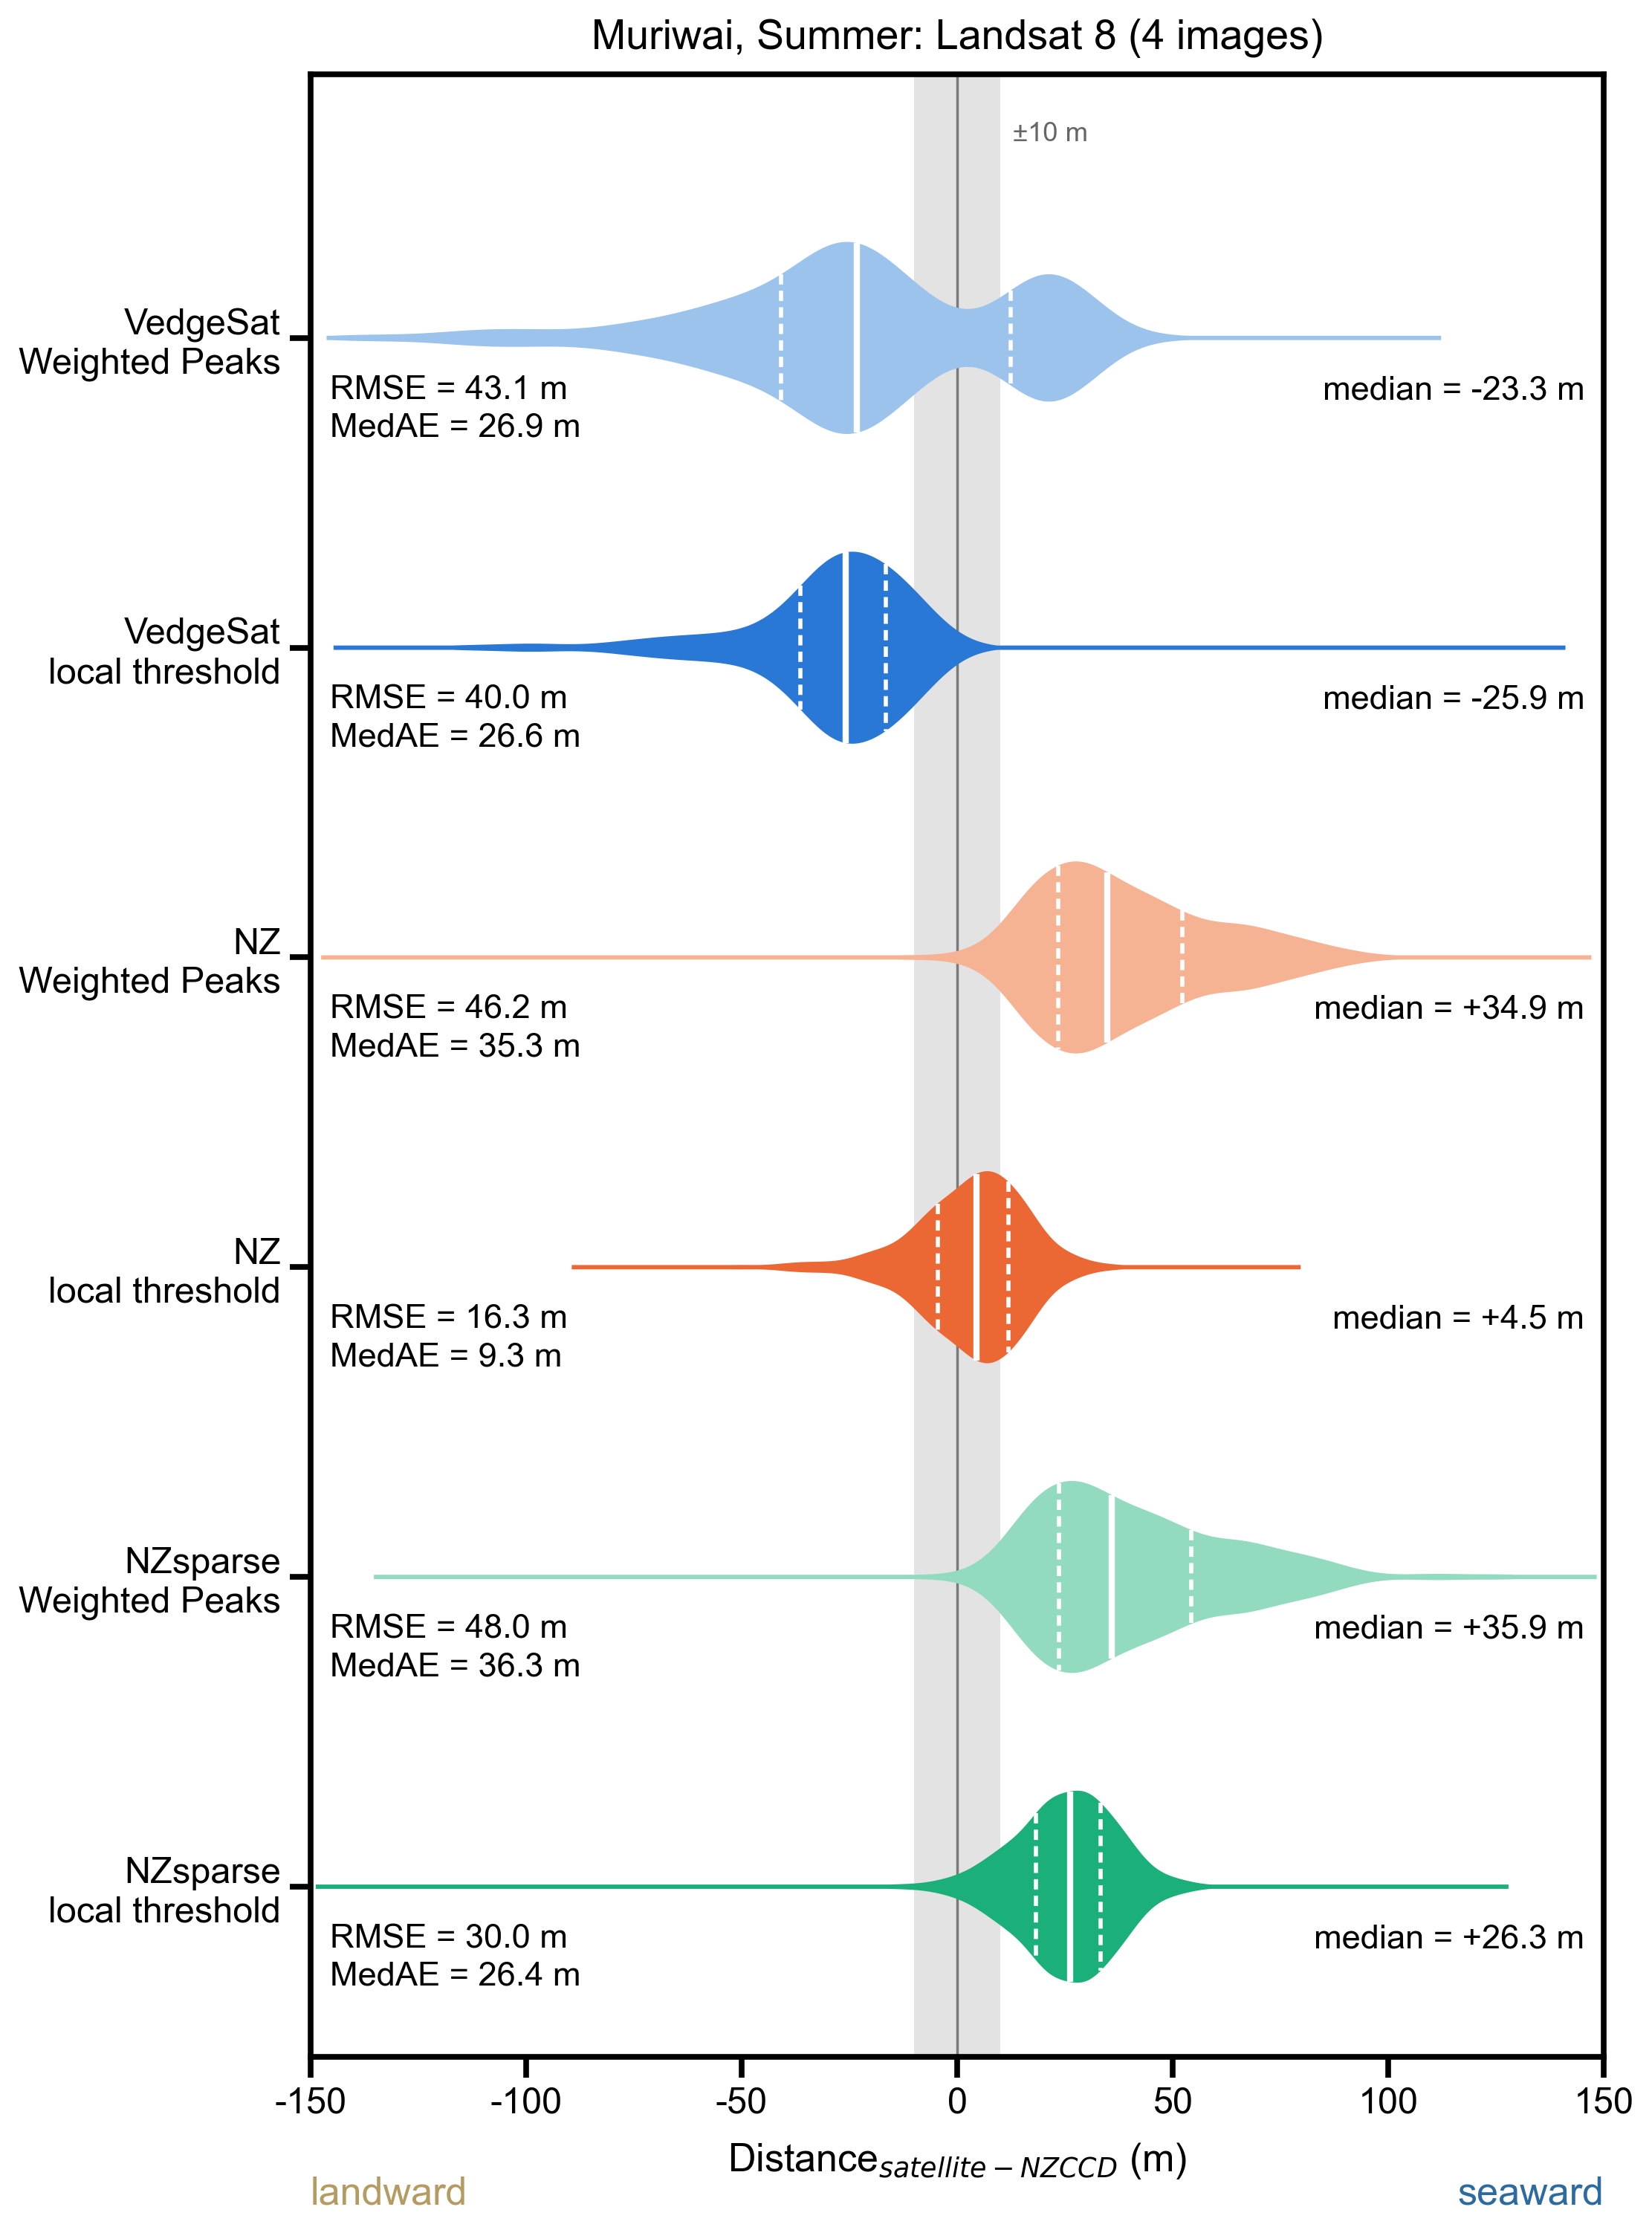

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\seasonal\violins_Muriwai_L8_Summer.png

Combined S2 Summer: transects per site (first run) Muriwai 1605, Pakiri 1219


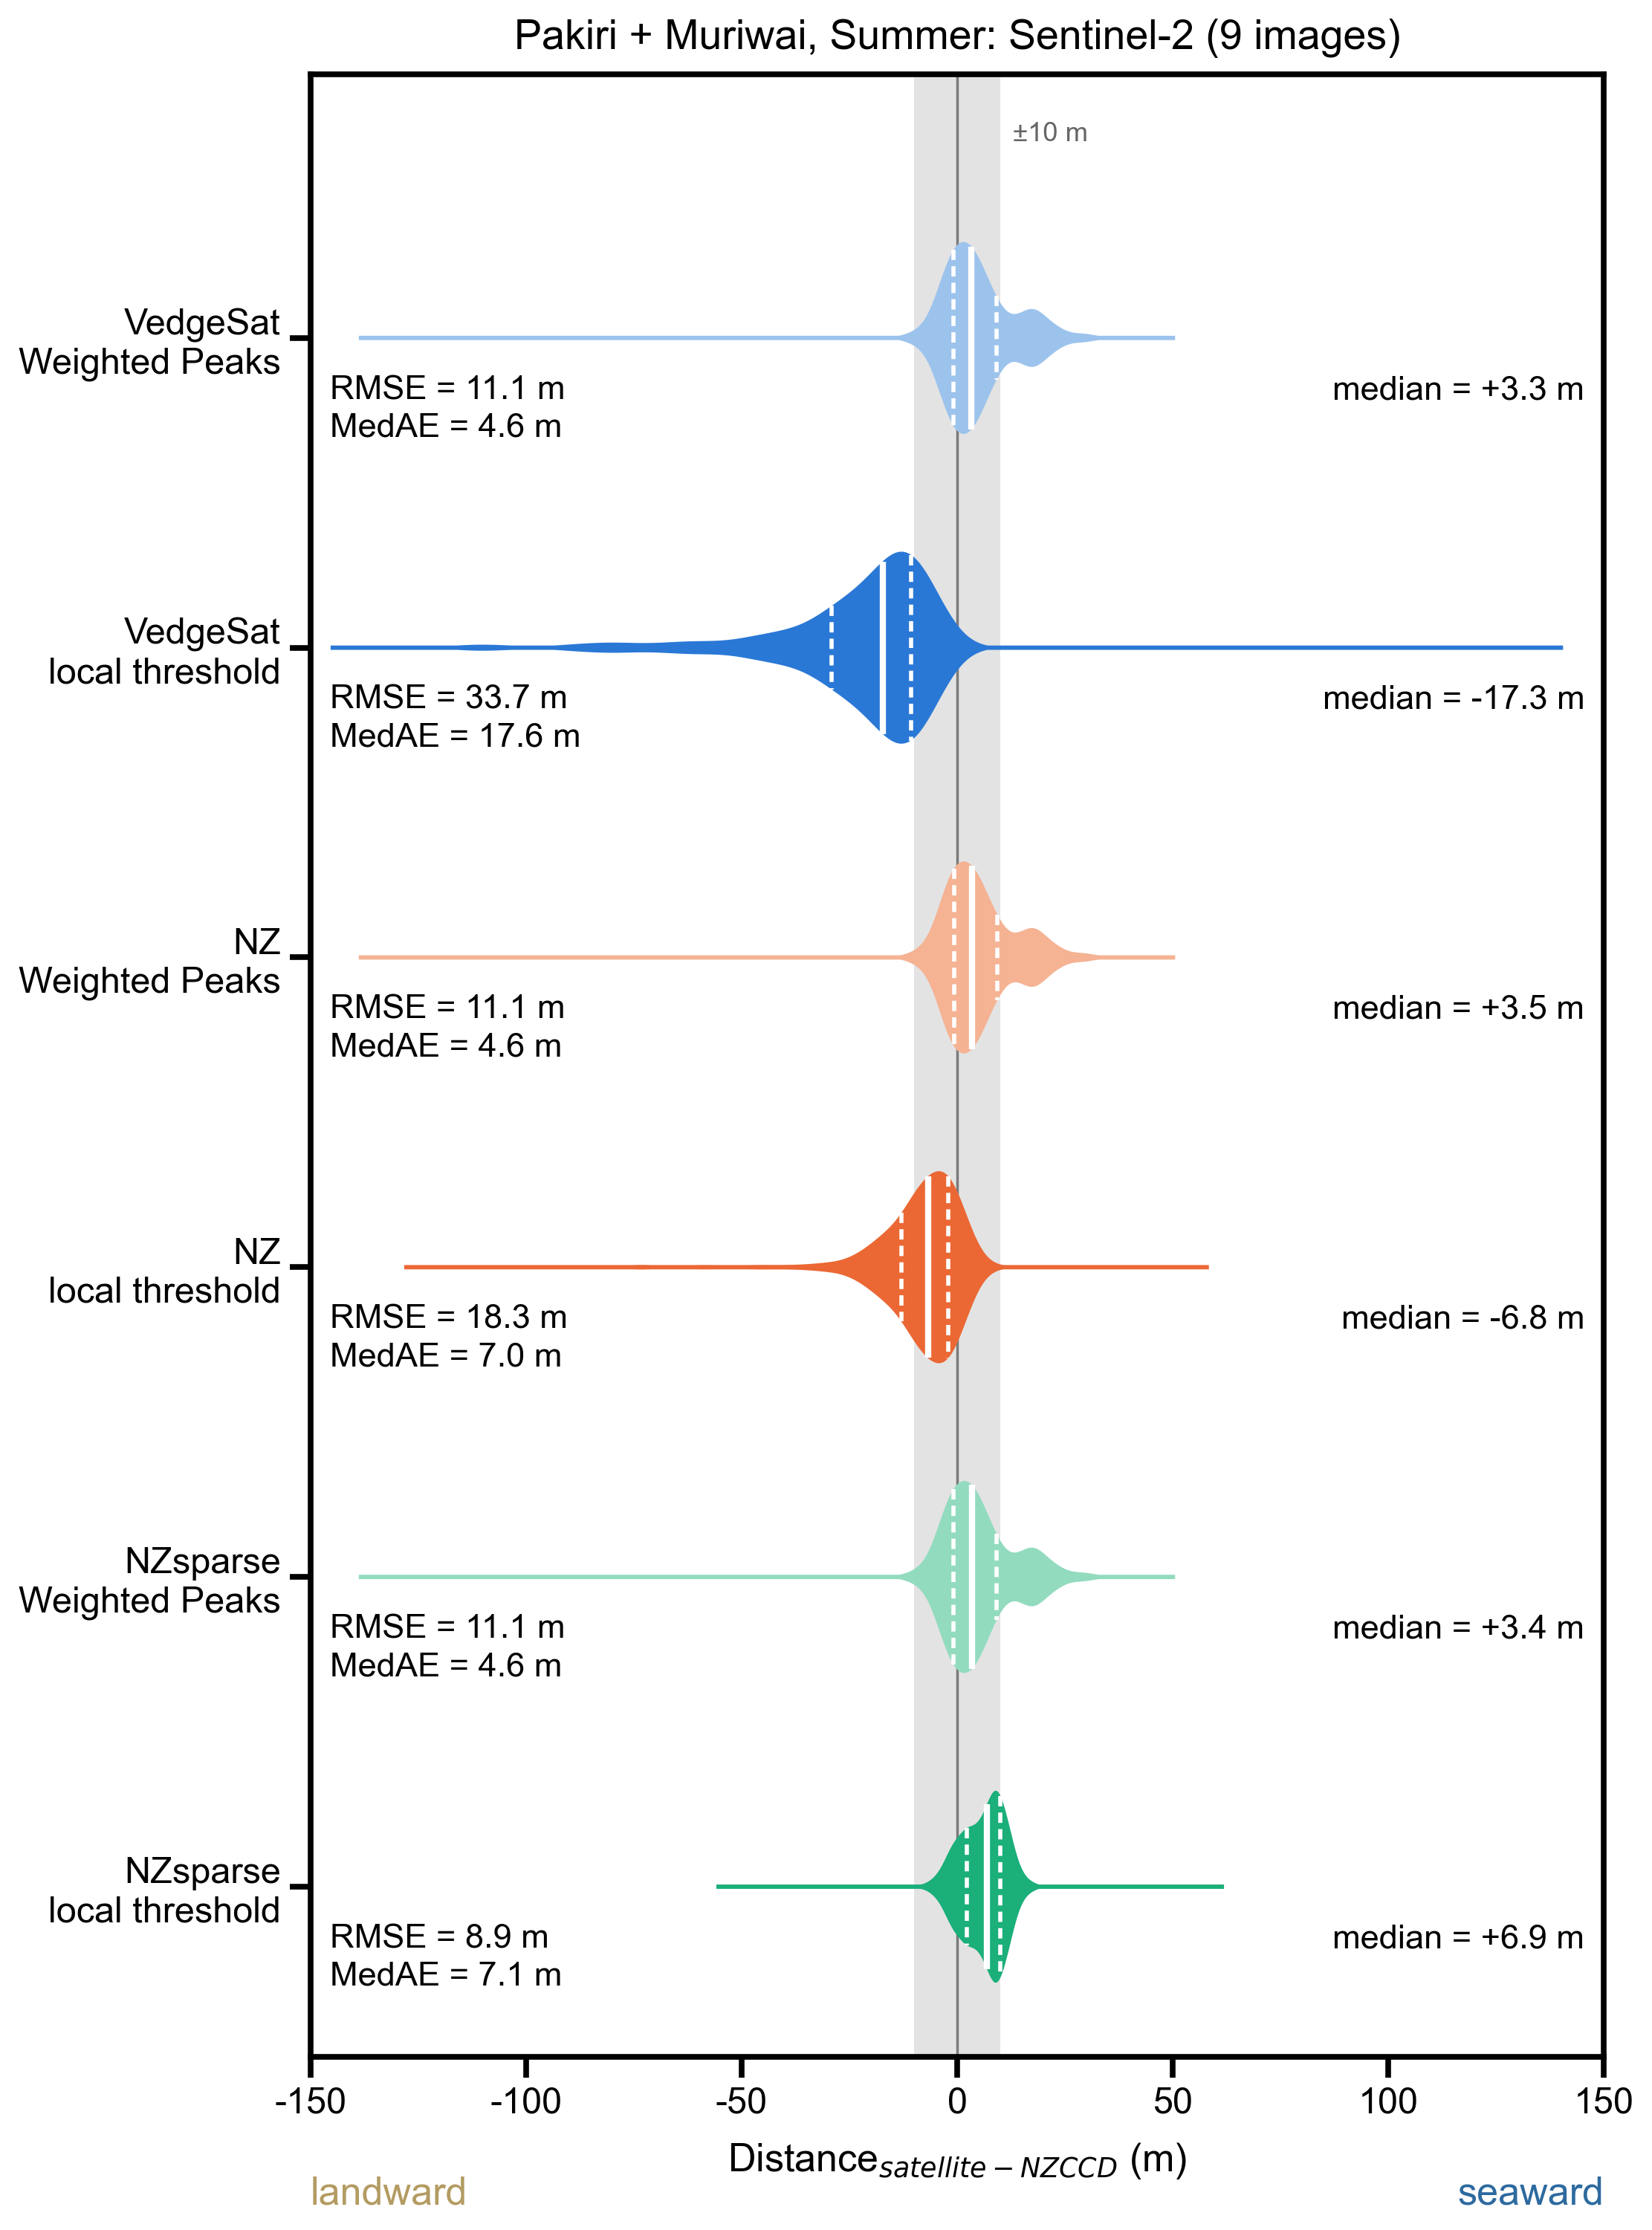

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\seasonal\violins_Combined_S2_Summer.png

Combined L8 Summer: transects per site (first run) Muriwai 1499, Pakiri 476


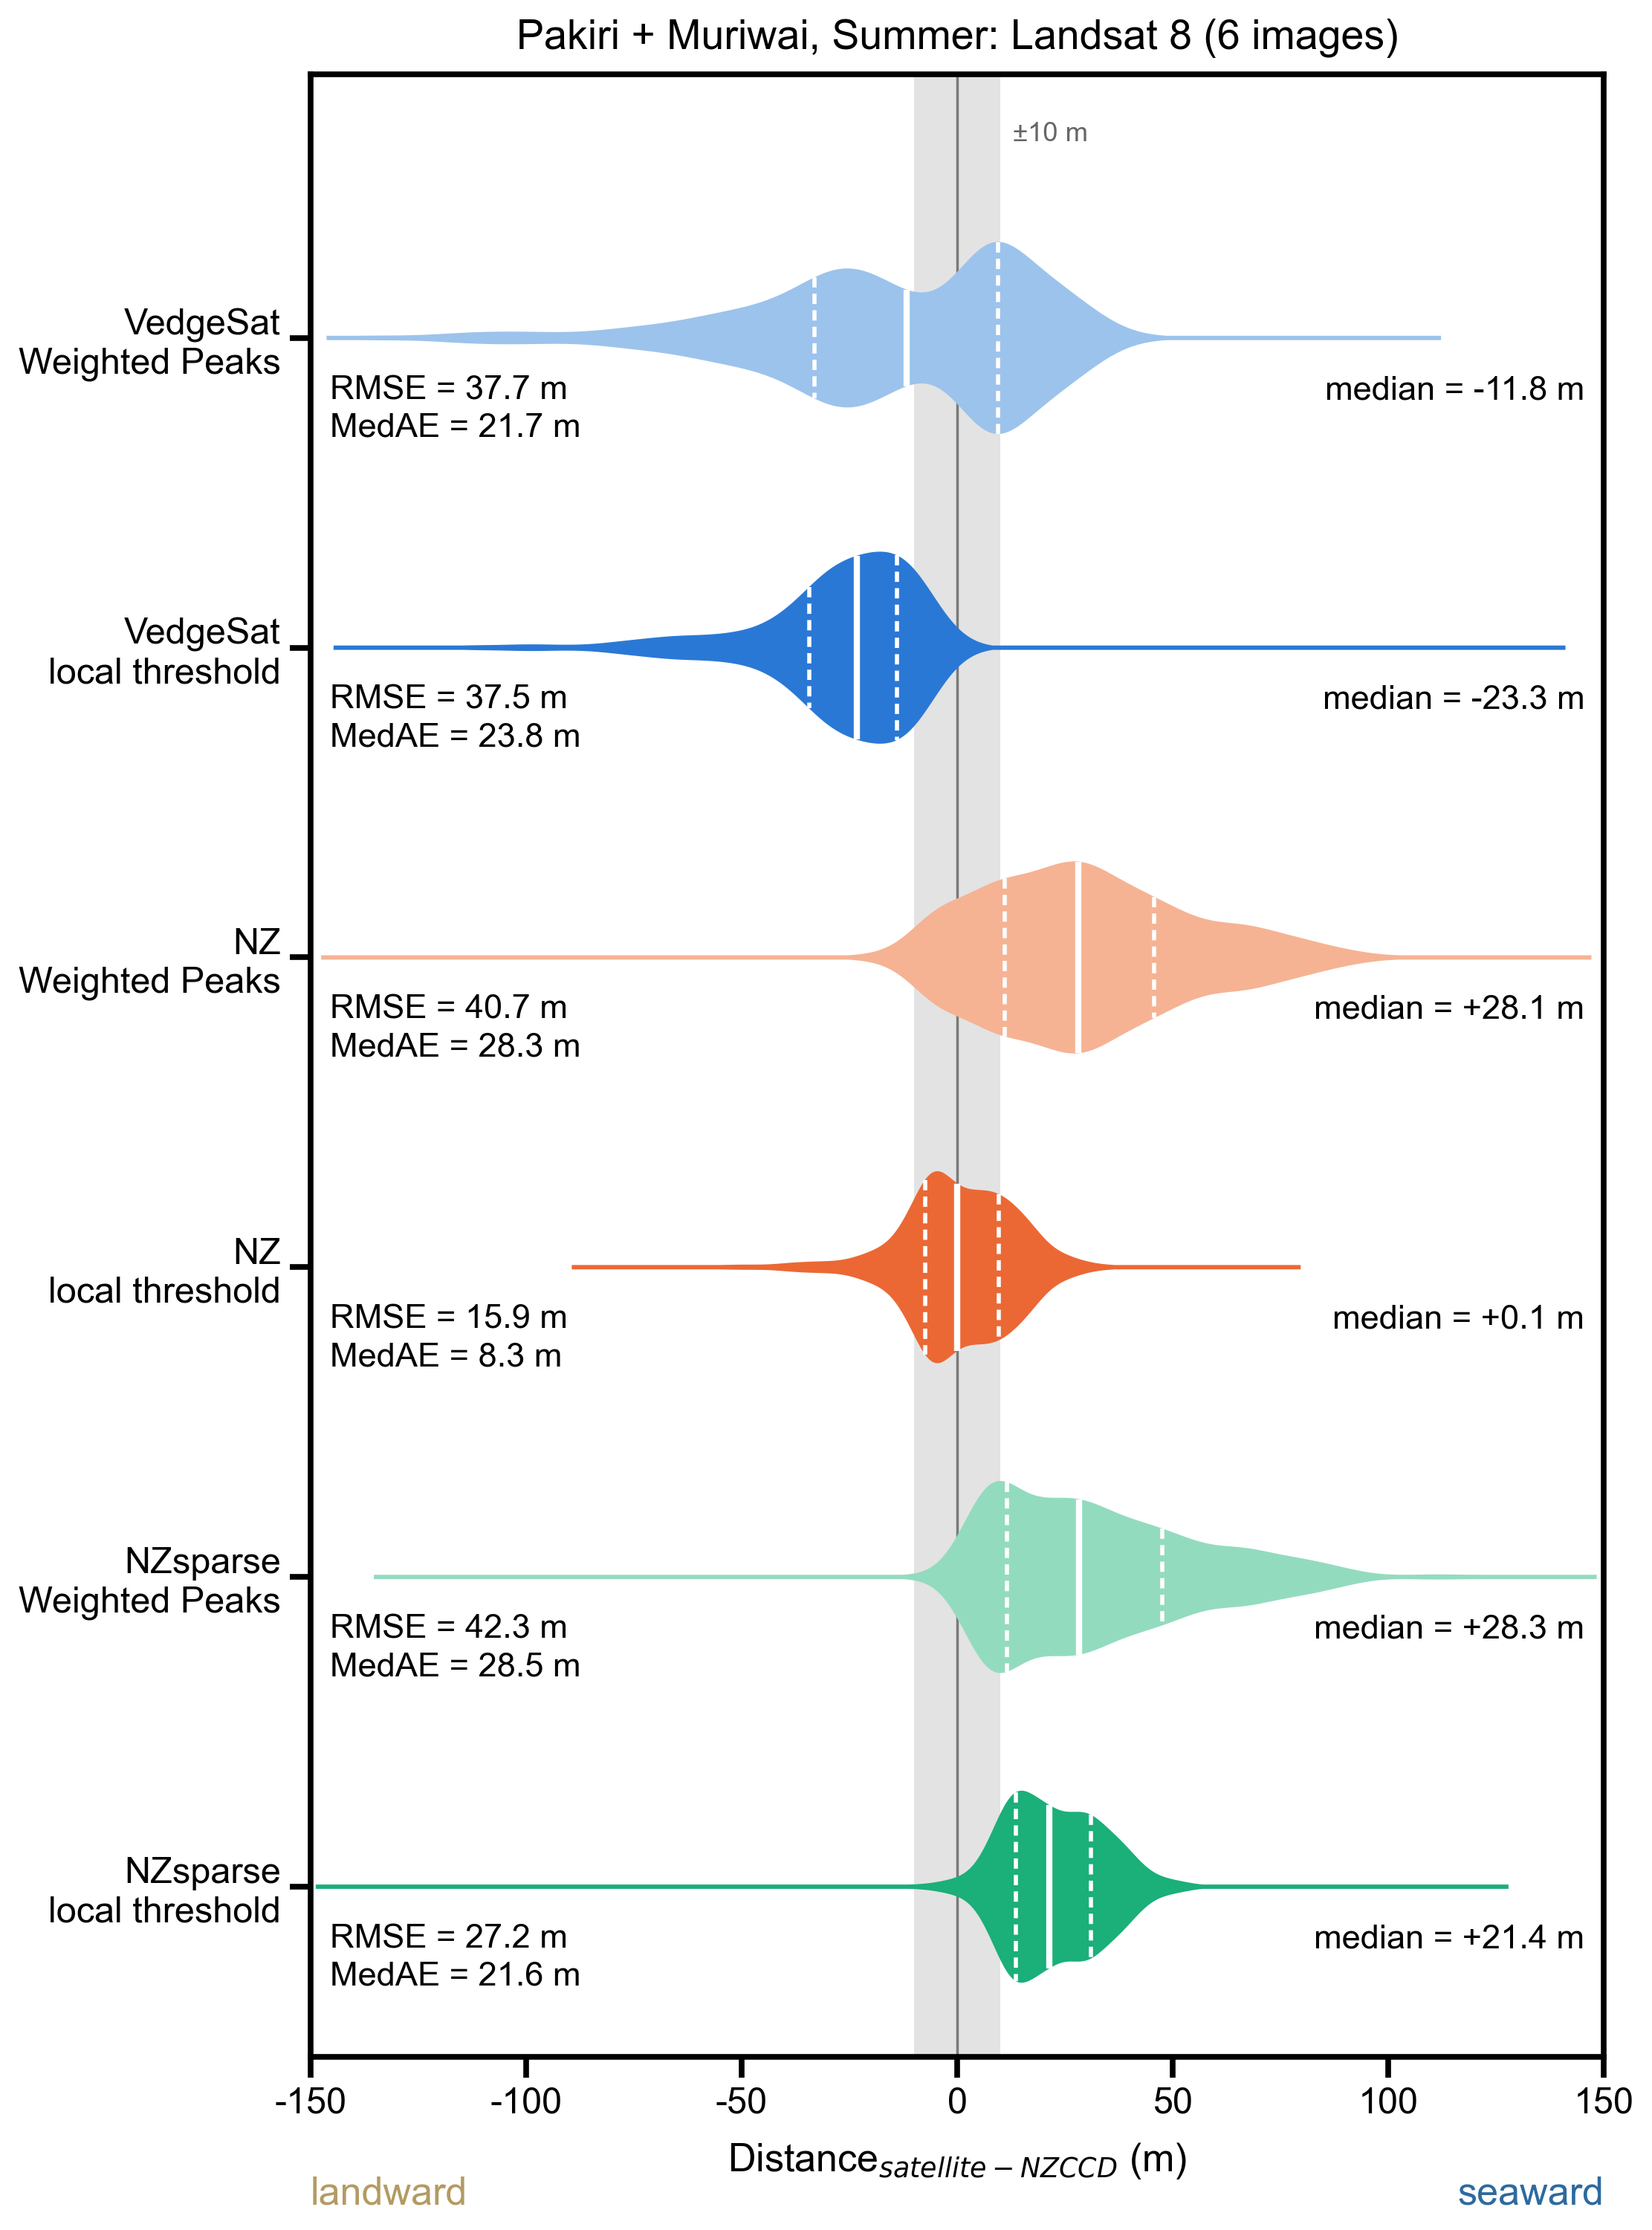

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\seasonal\violins_Combined_L8_Summer.png


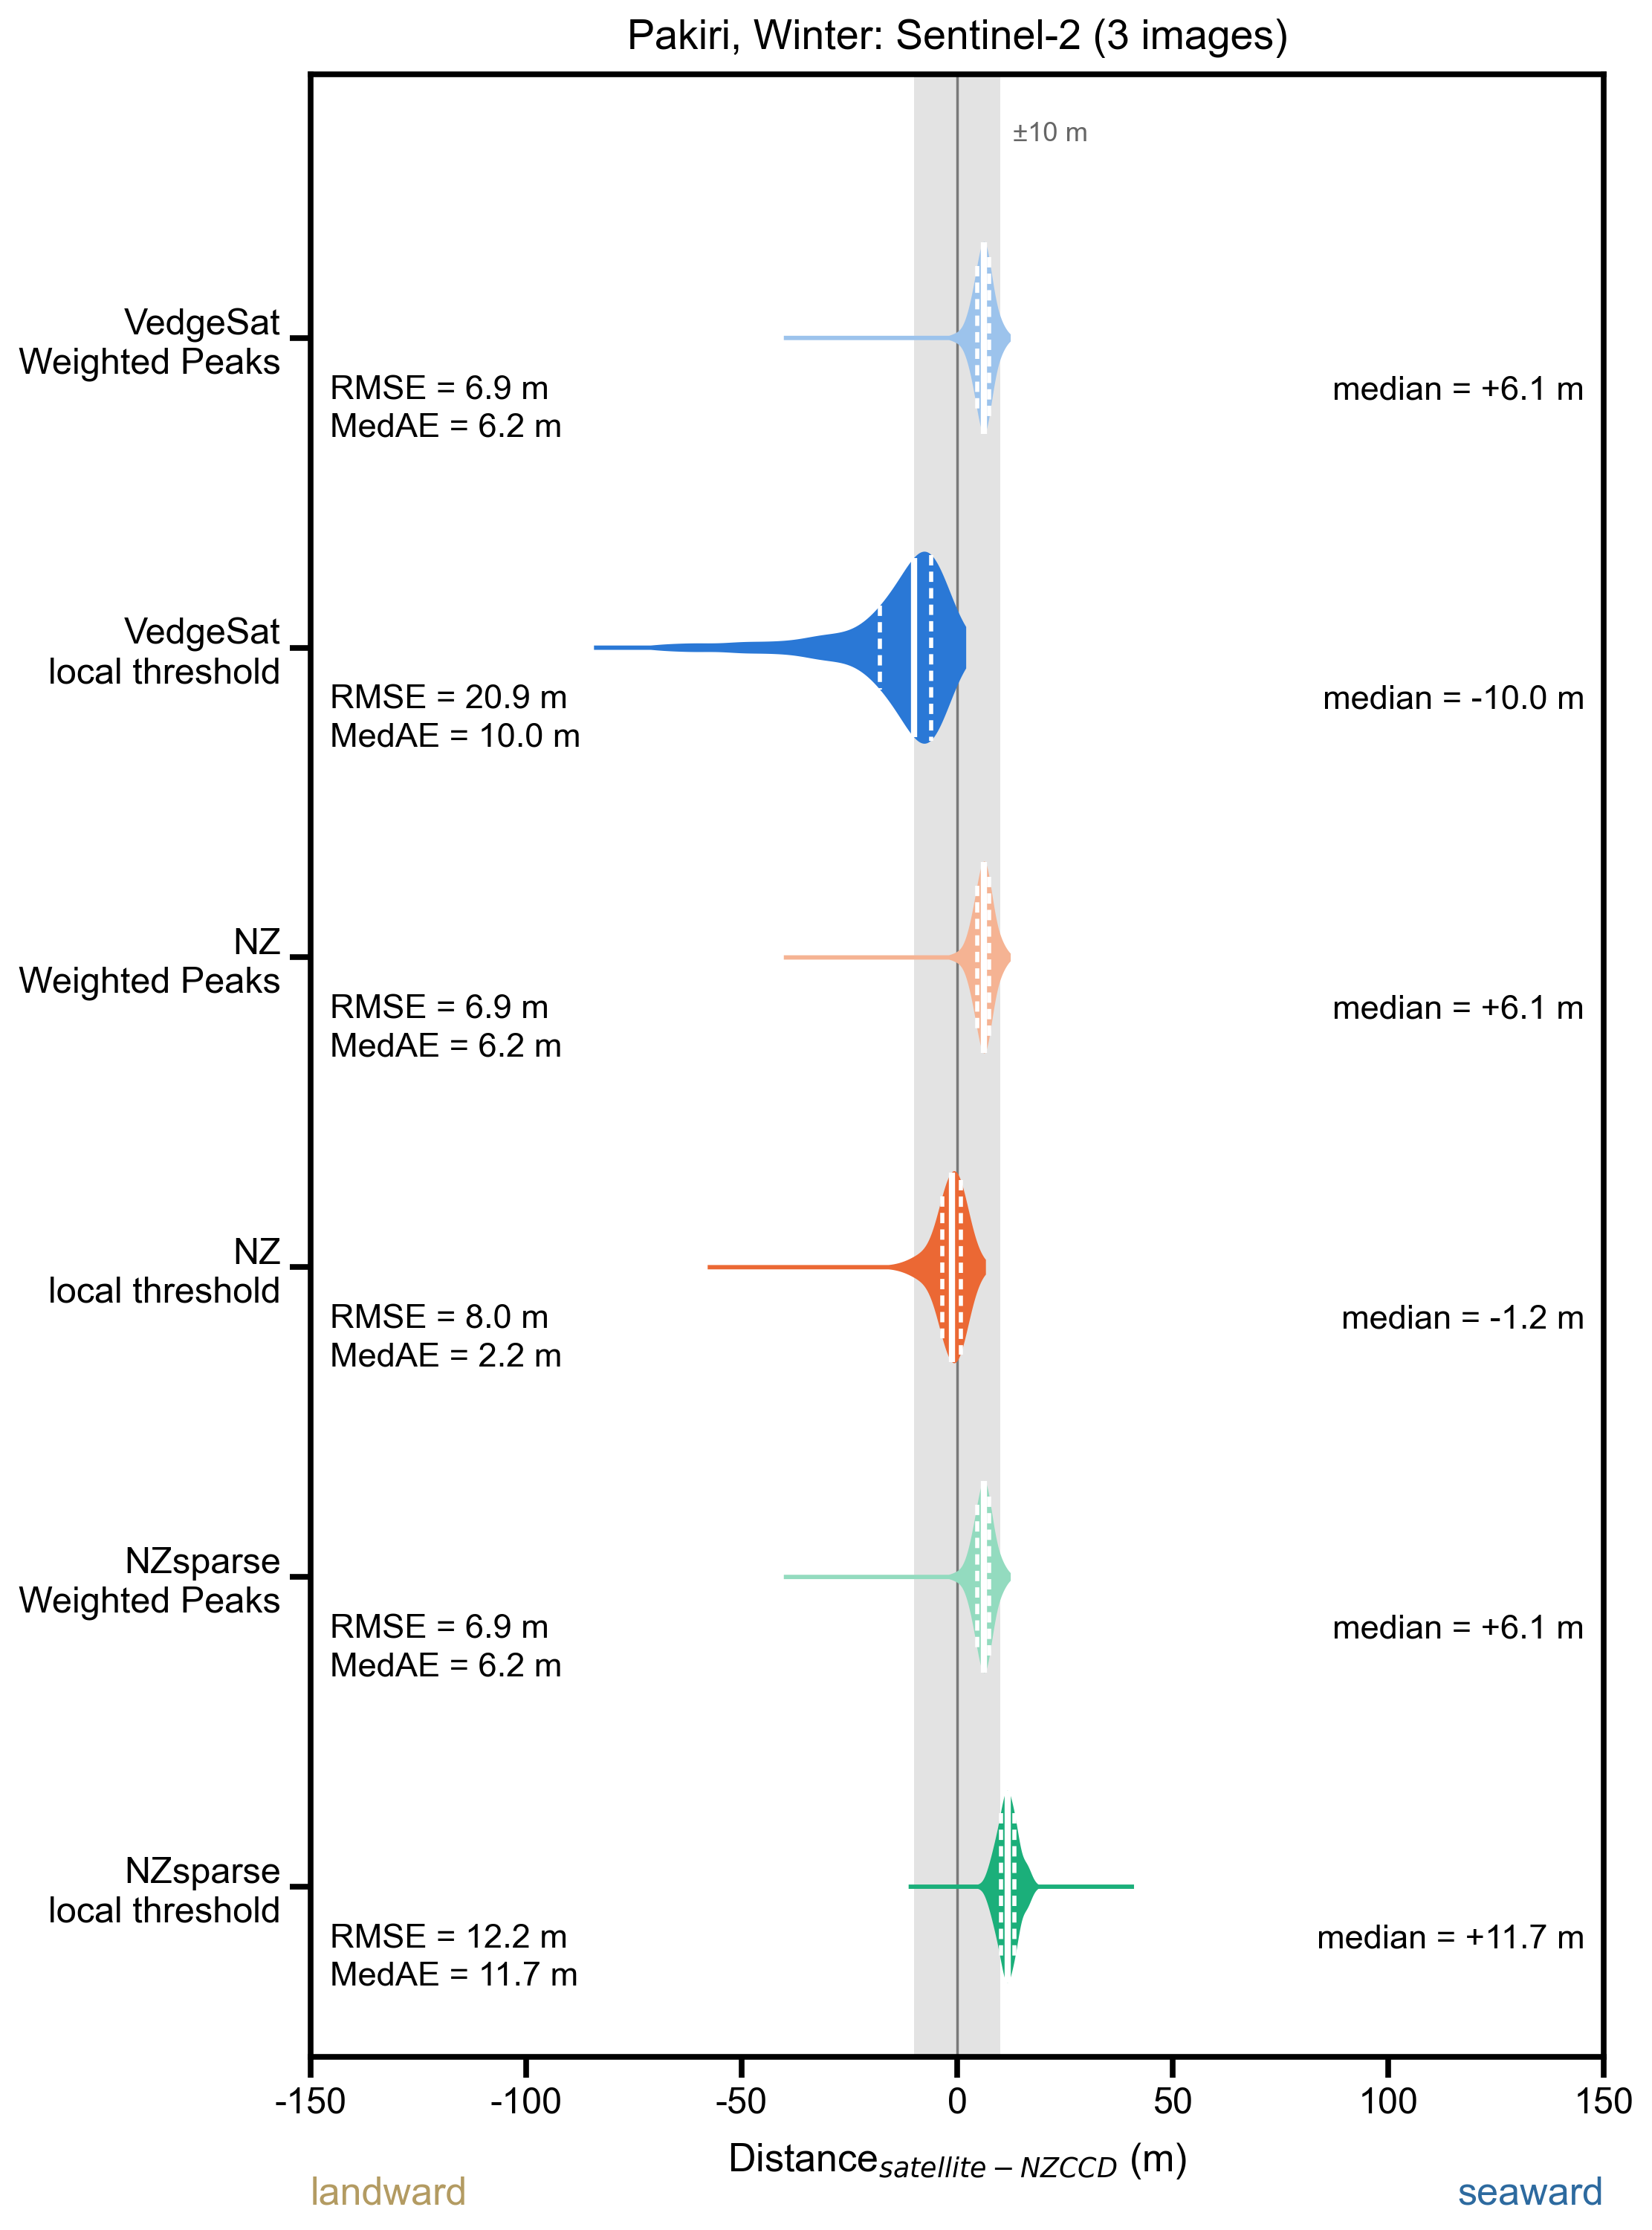

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\seasonal\violins_Pakiri_S2_Winter.png


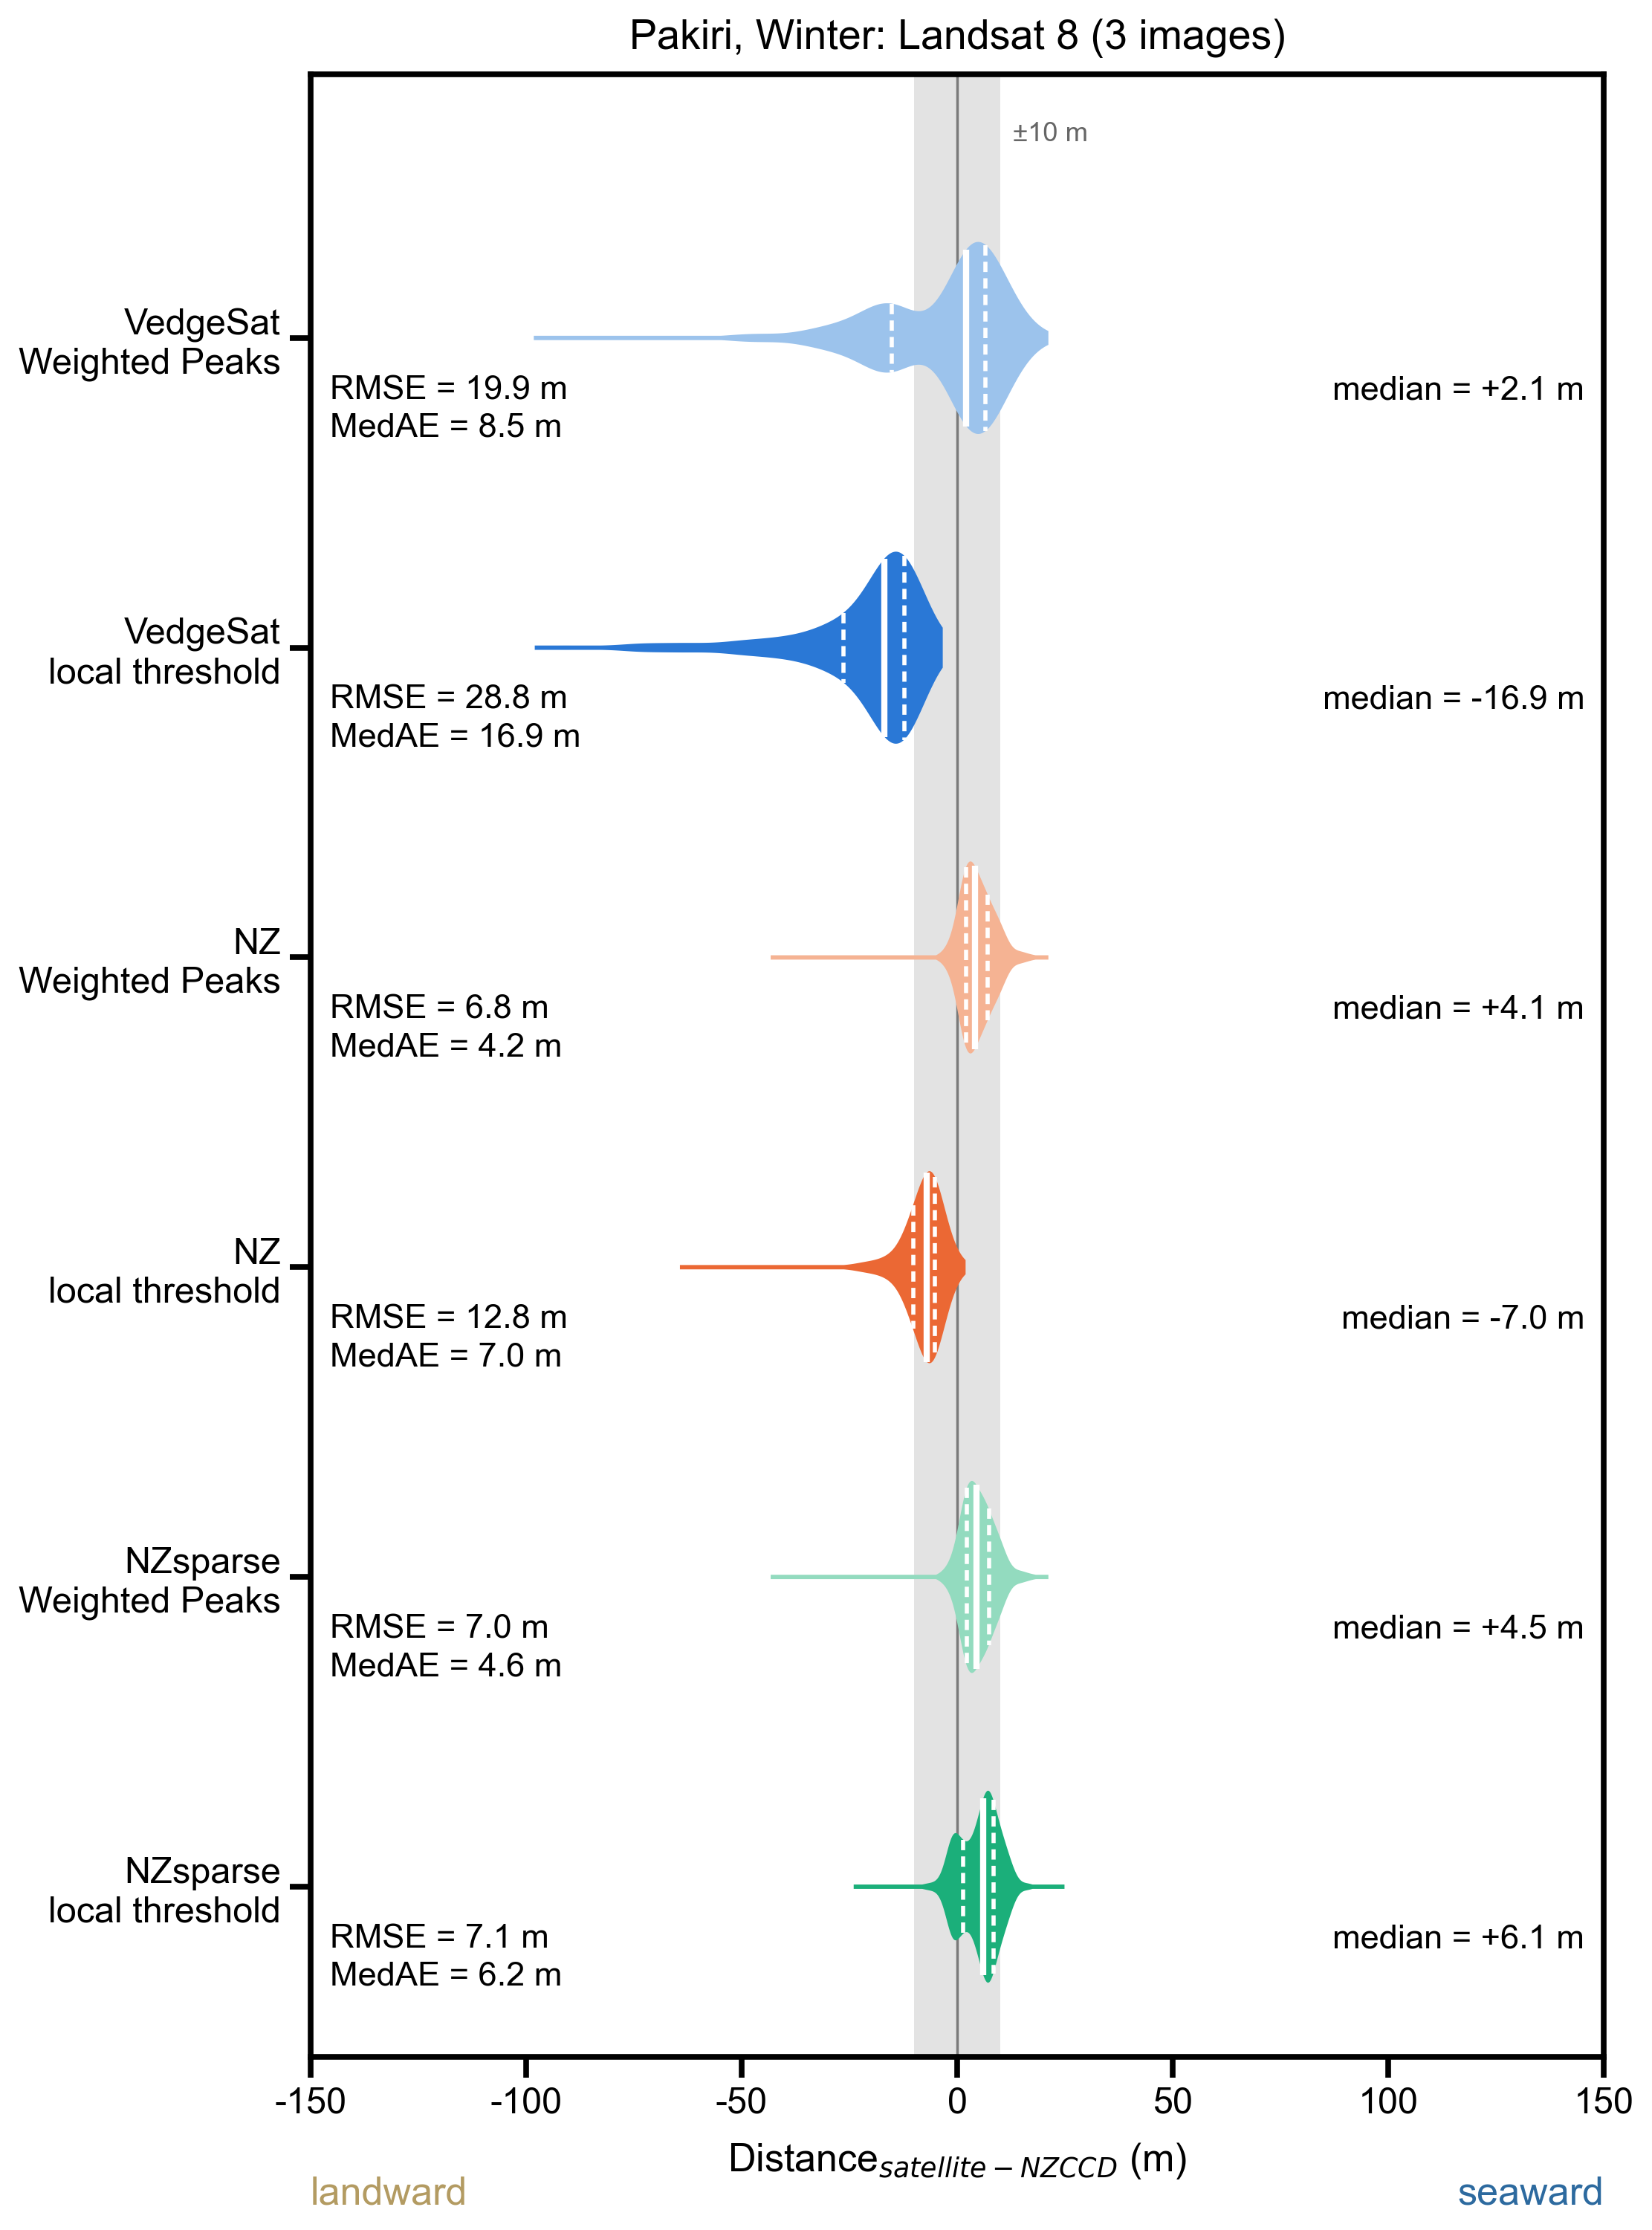

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\seasonal\violins_Pakiri_L8_Winter.png


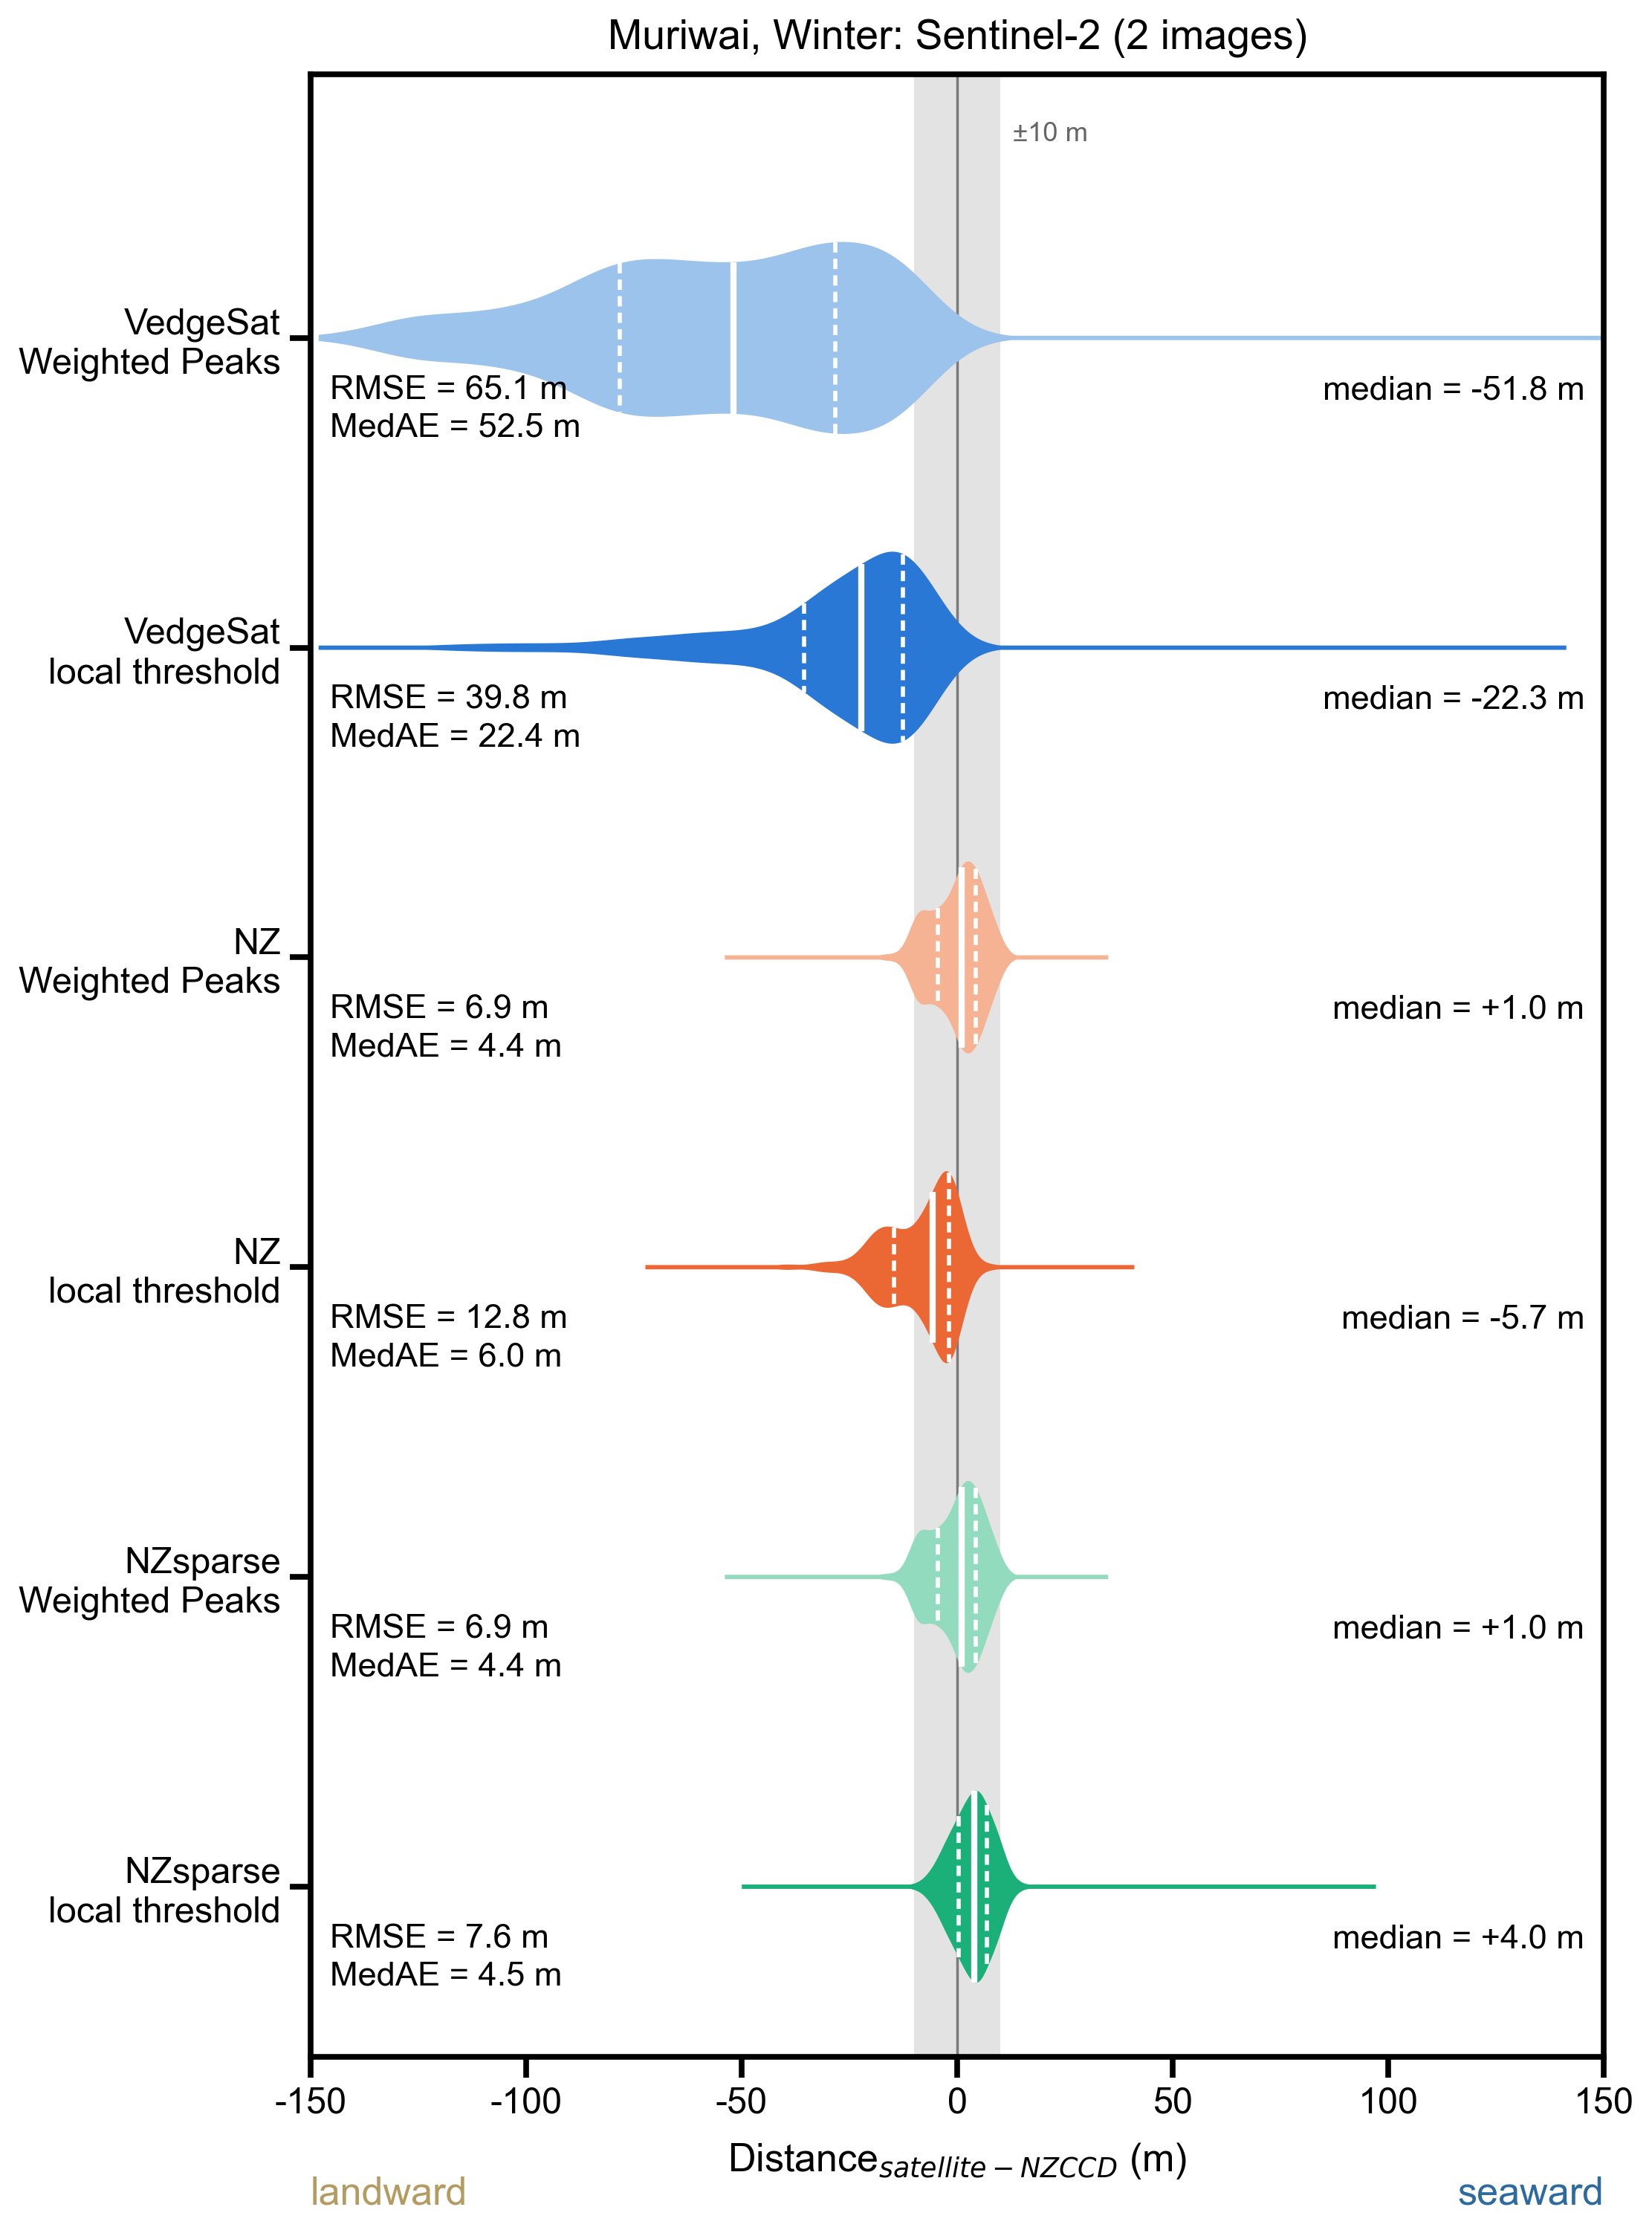

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\seasonal\violins_Muriwai_S2_Winter.png


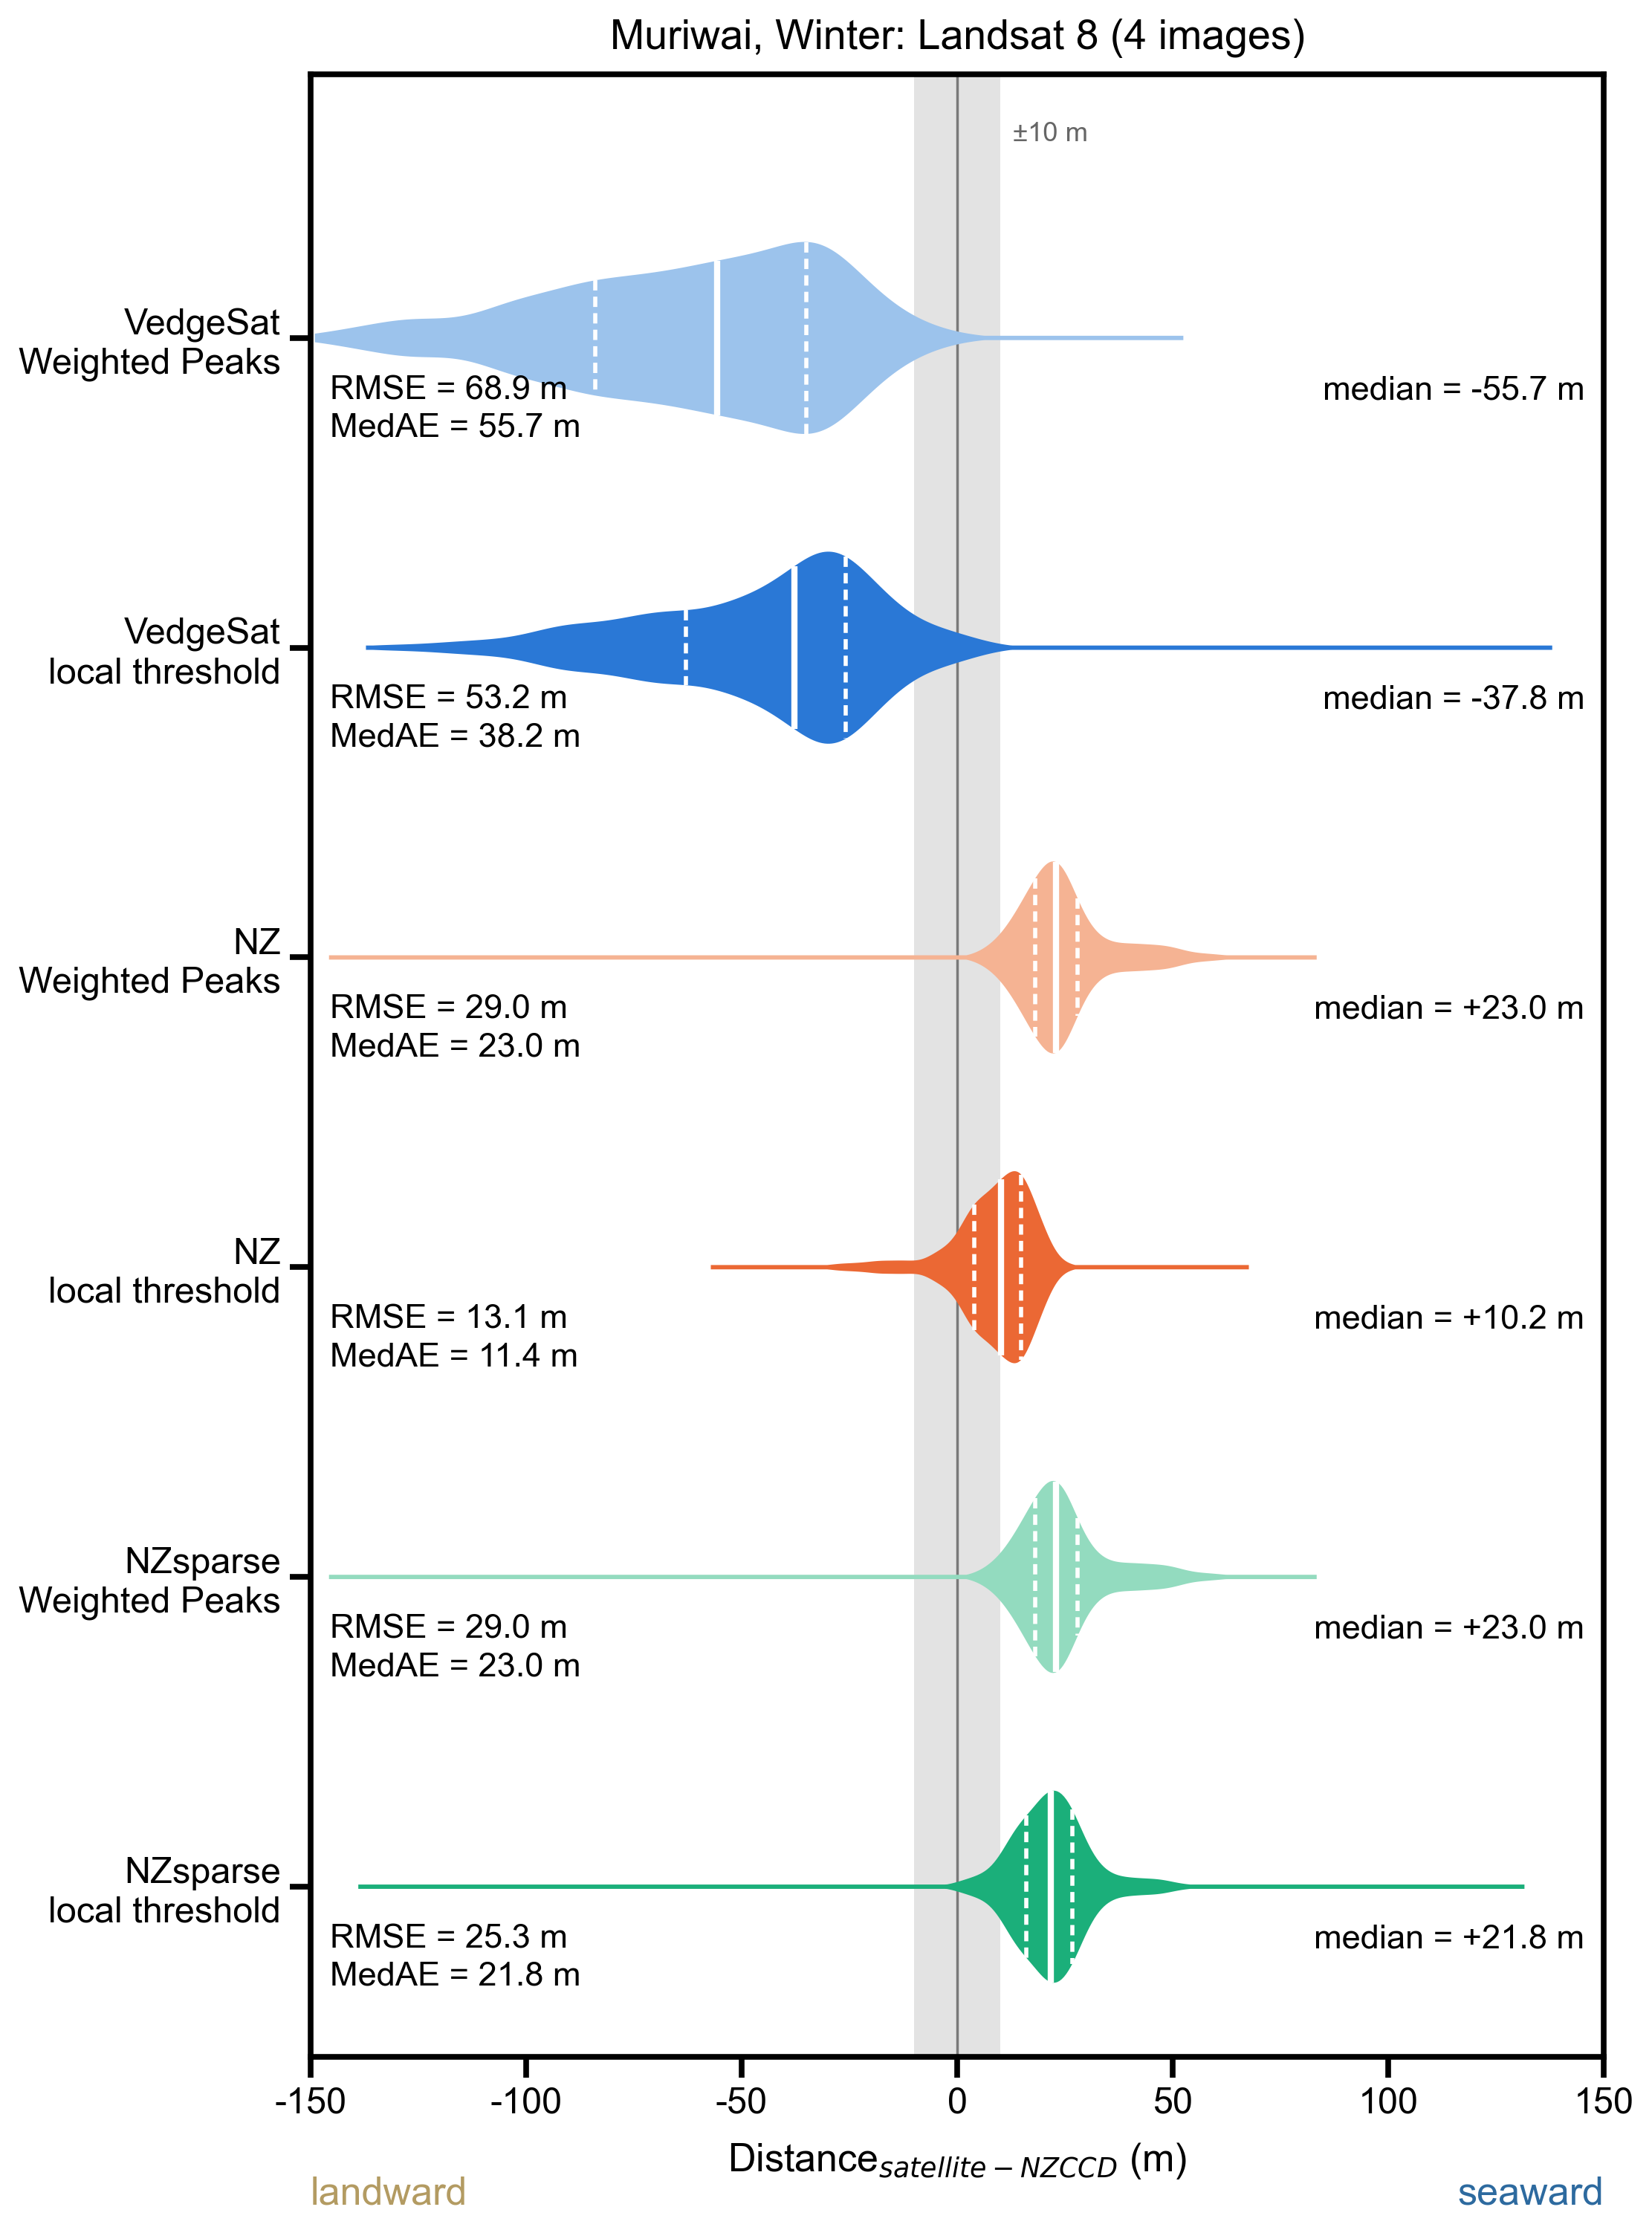

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\seasonal\violins_Muriwai_L8_Winter.png

Combined S2 Winter: transects per site (first run) Muriwai 722, Pakiri 745


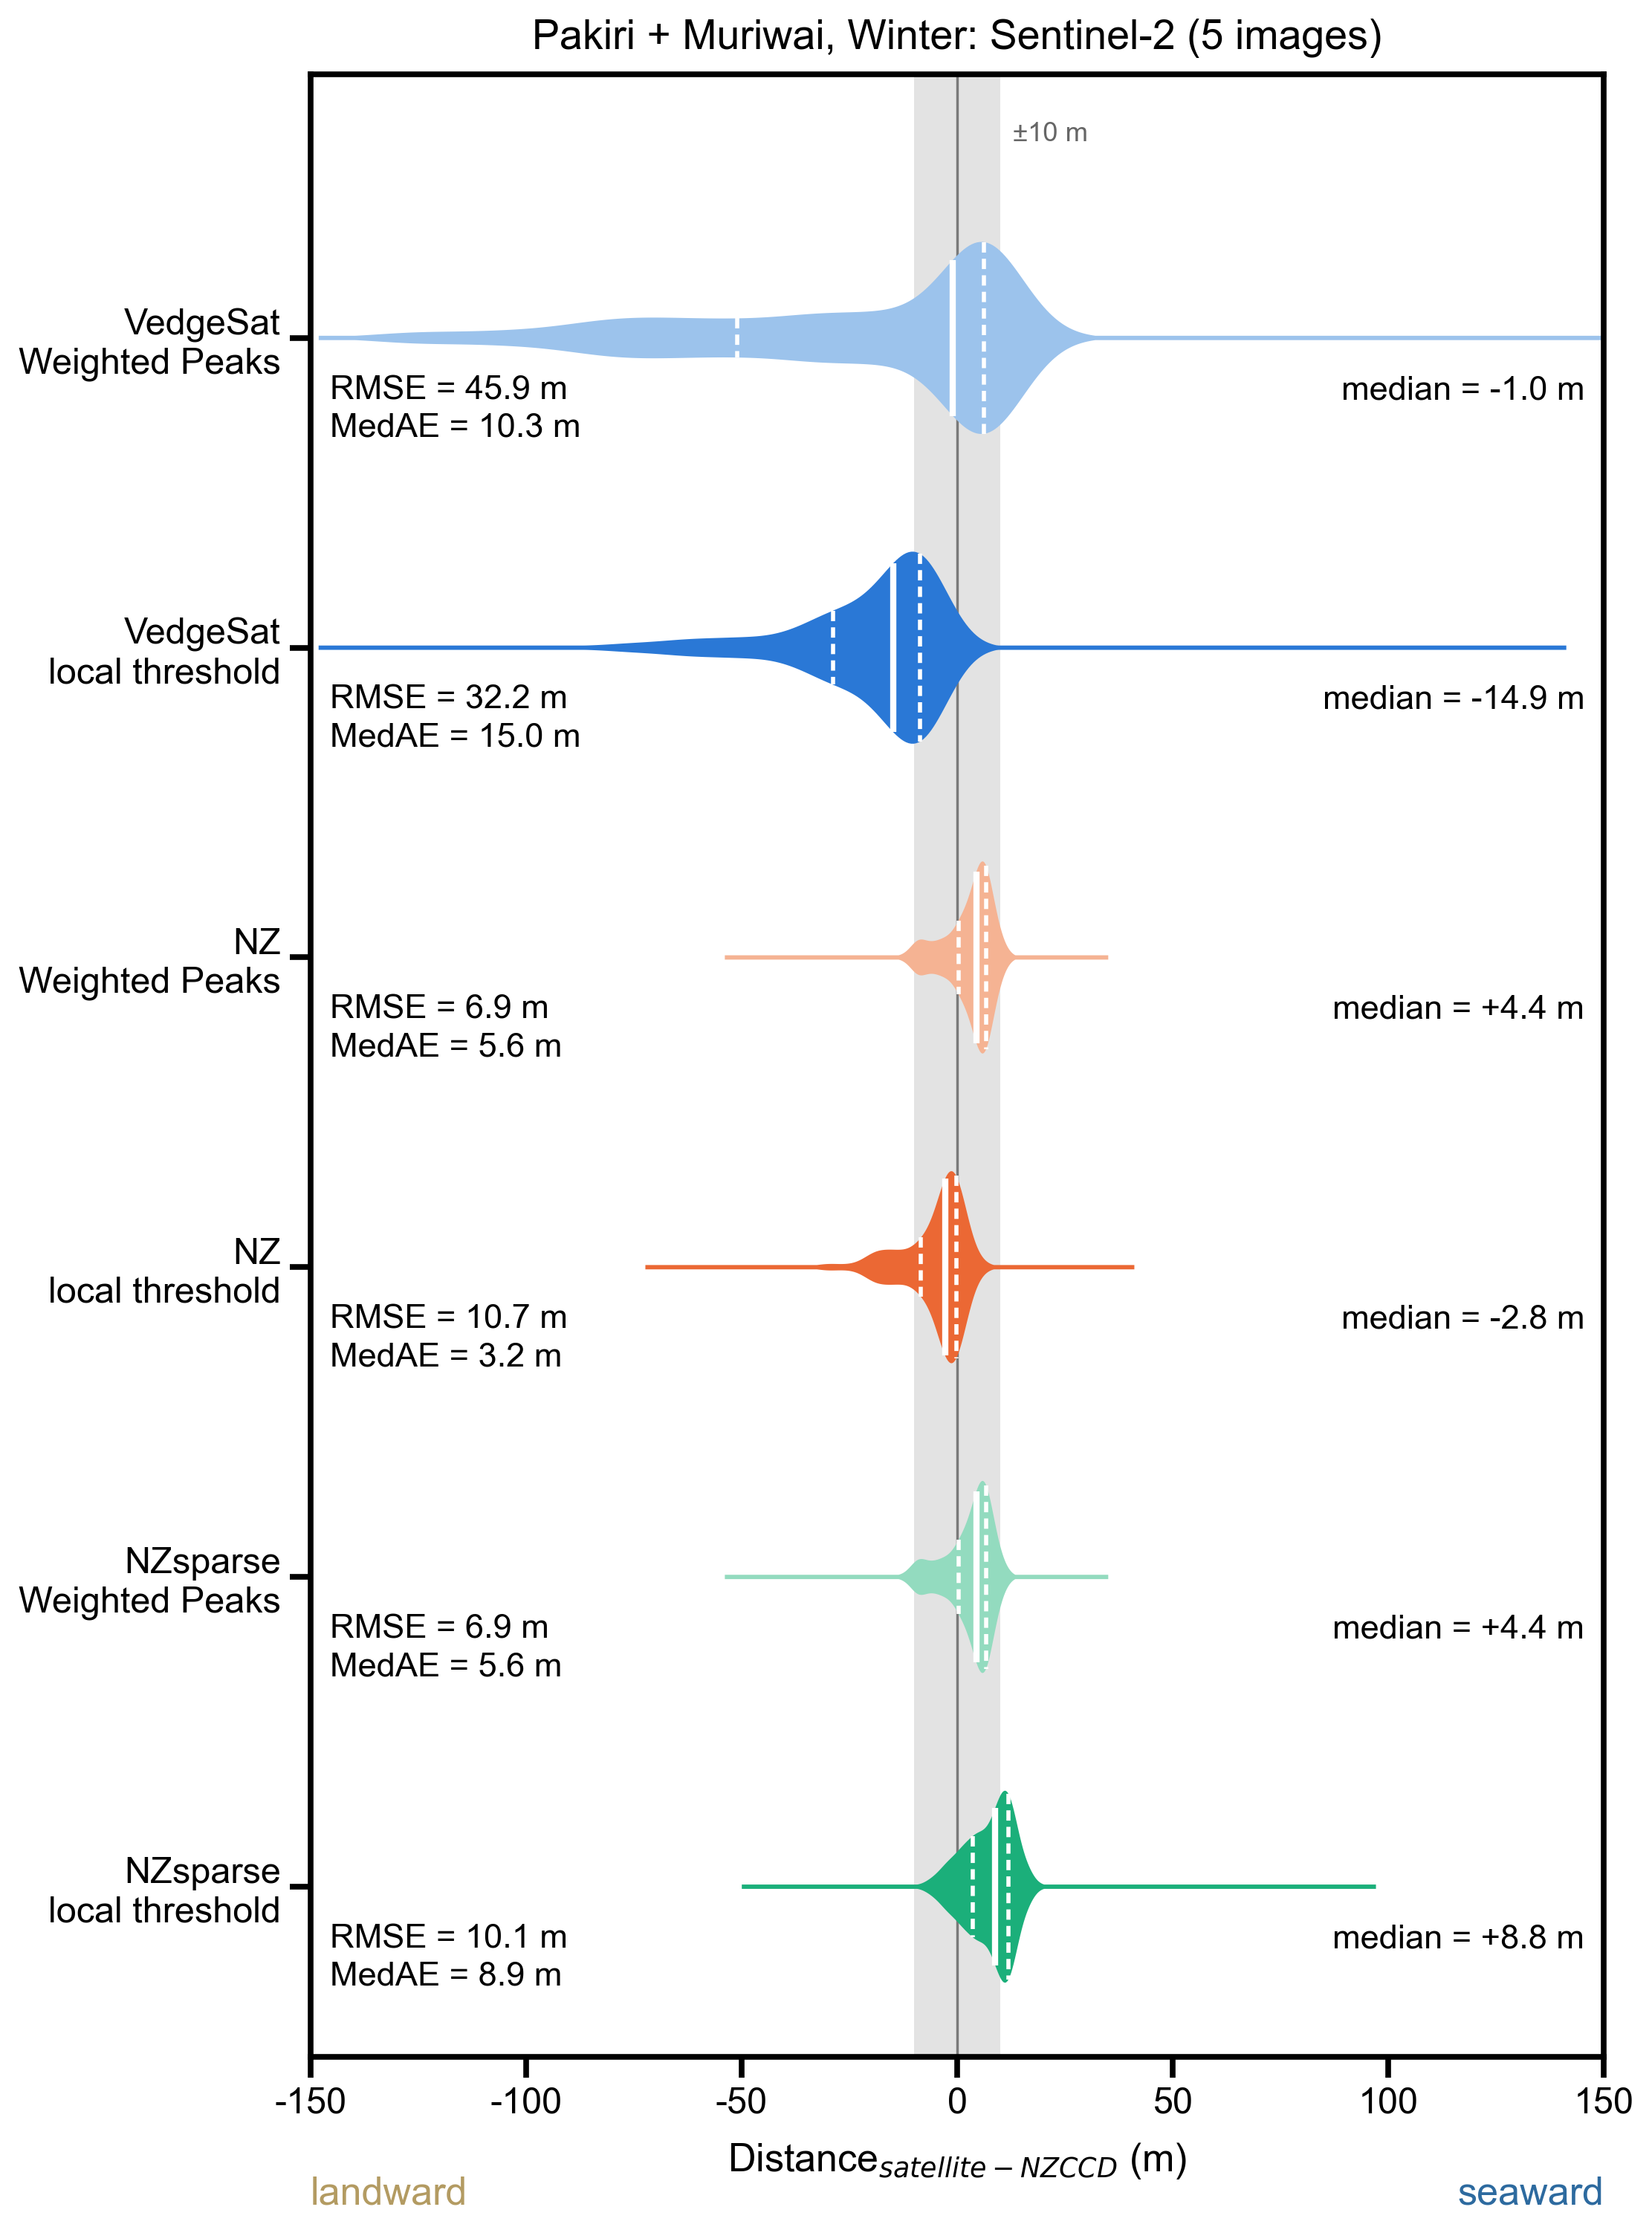

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\seasonal\violins_Combined_S2_Winter.png

Combined L8 Winter: transects per site (first run) Muriwai 1167, Pakiri 745


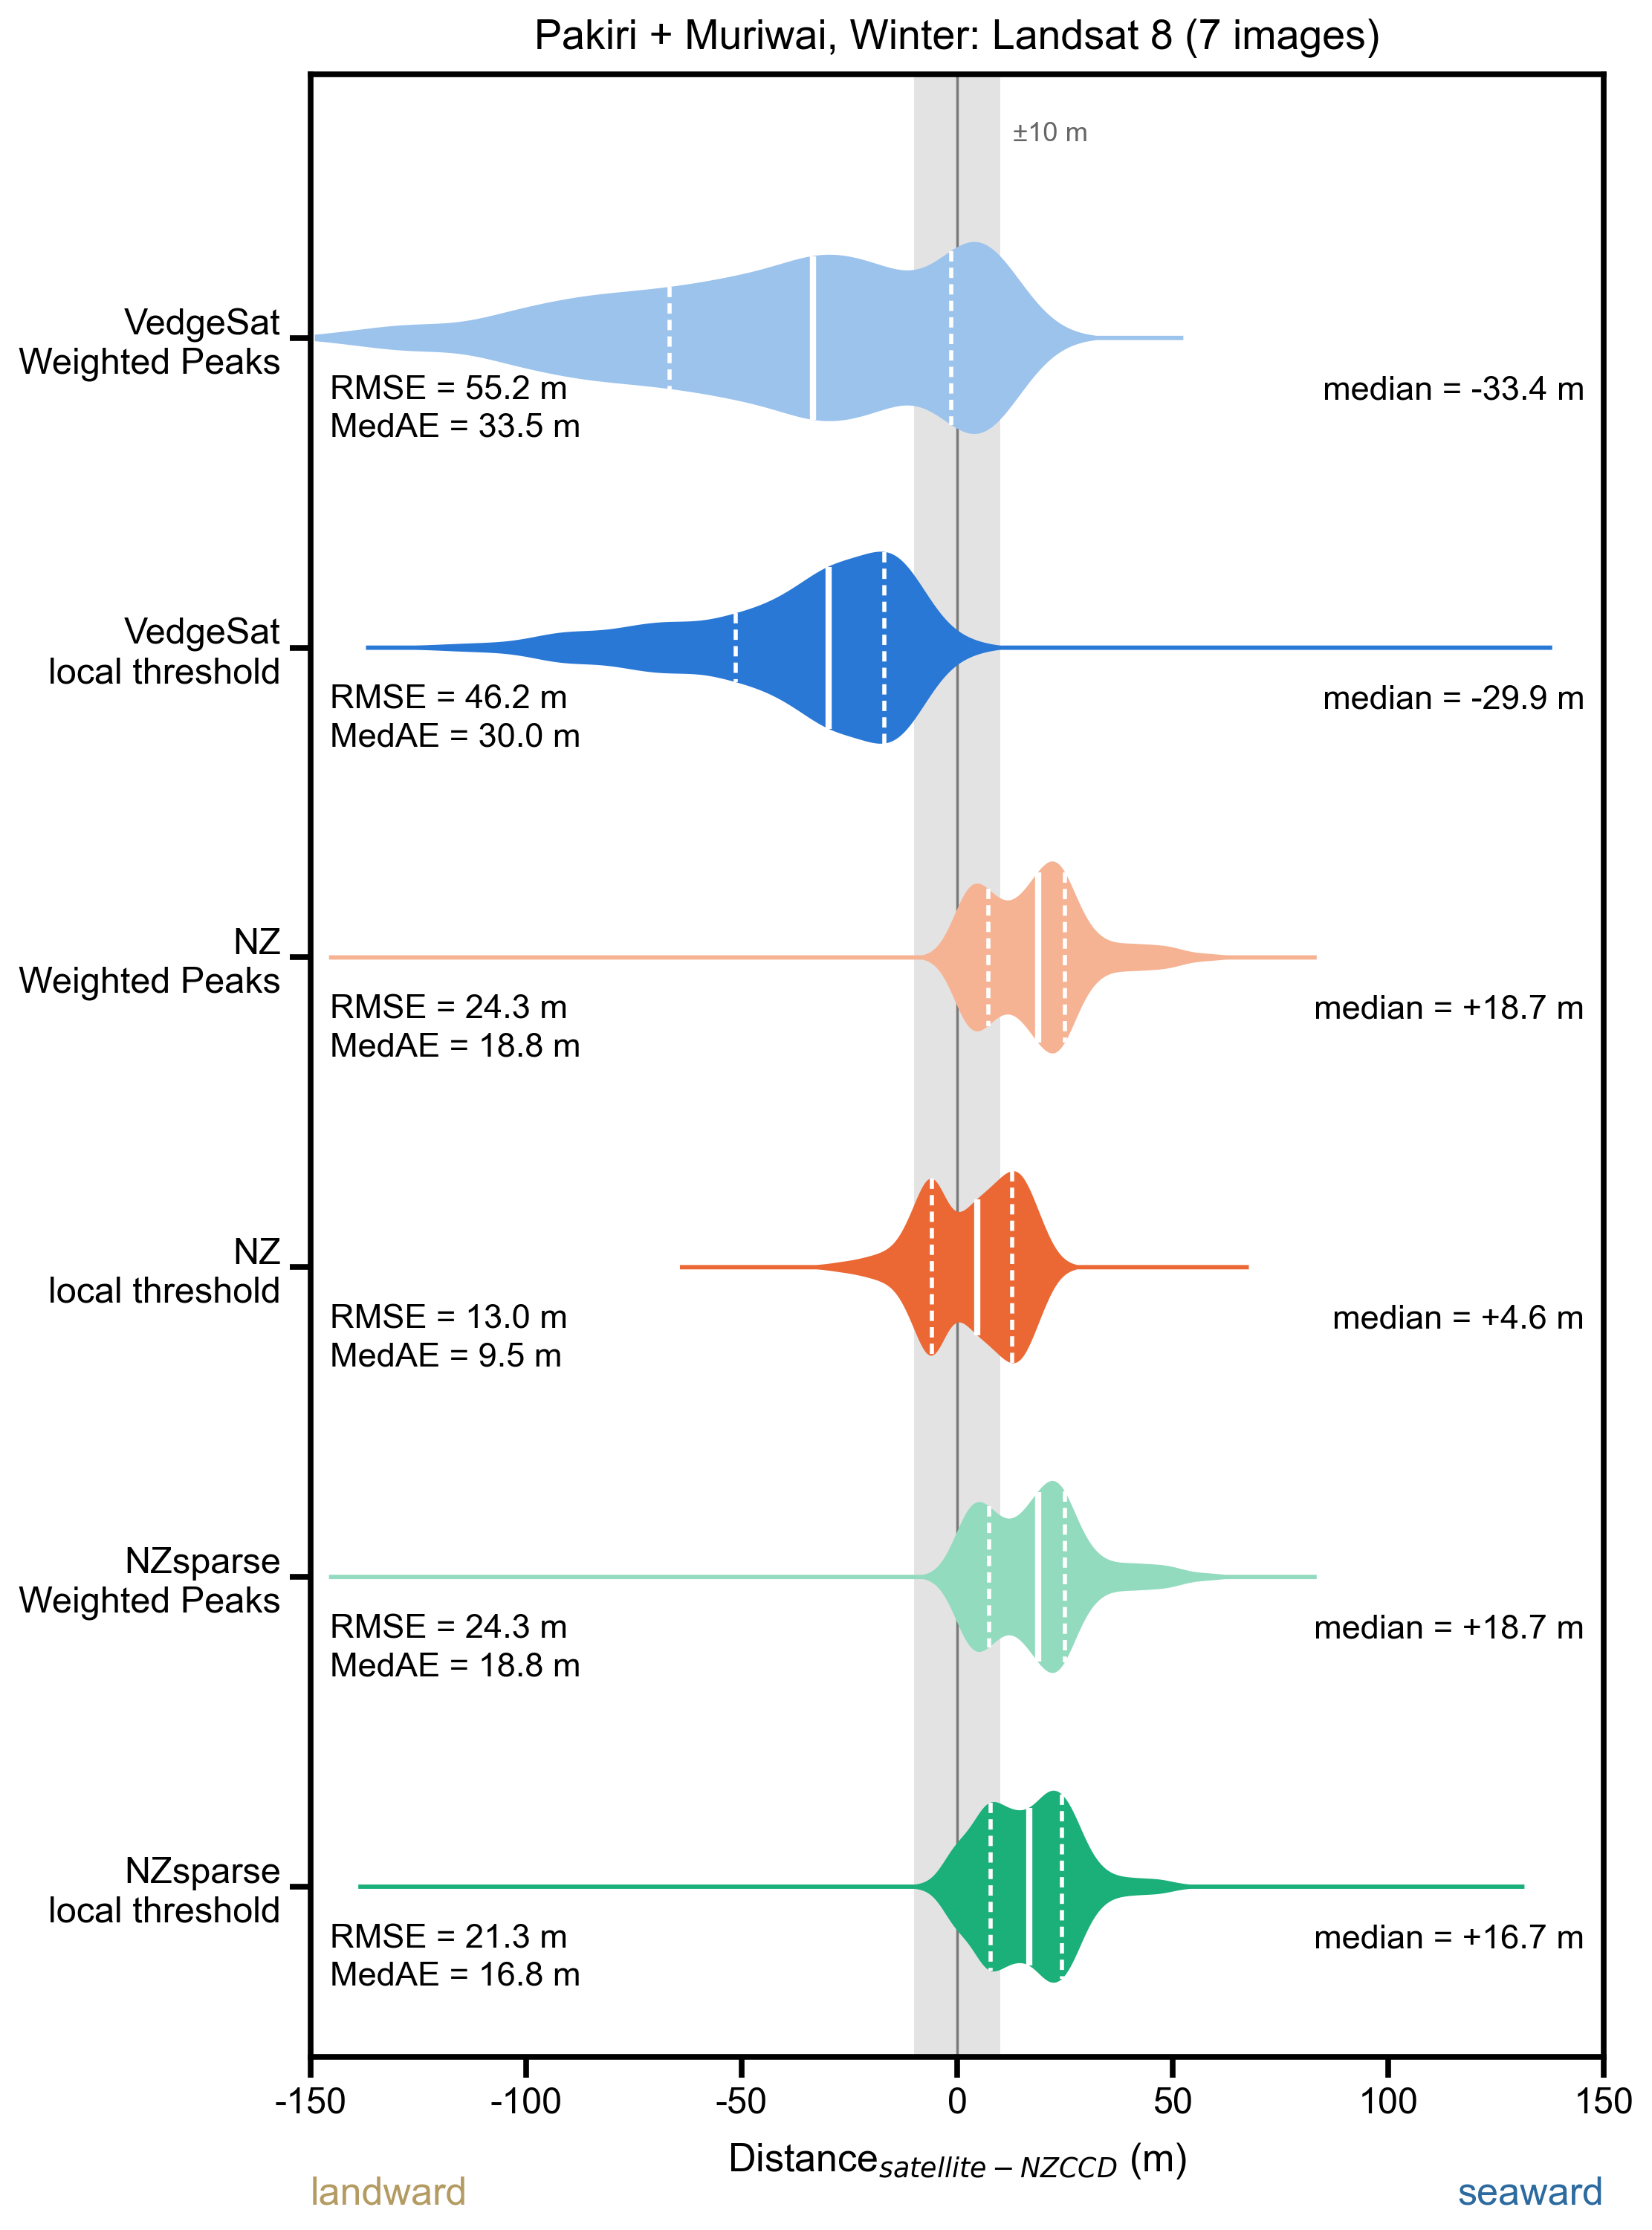

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\seasonal\violins_Combined_L8_Winter.png

season    site satname              run  images    n  median_bias_m  MedAE_m  RMSE_m  within_10m_%
Summer Muriwai      L8     Default (WP)       4 1499          -23.3     26.9    43.1           6.5
Summer Muriwai      L8  Default (local)       4 1535          -25.9     26.6    40.0           9.6
Summer Muriwai      L8          NZ (WP)       4 1594           34.9     35.3    46.2           2.8
Summer Muriwai      L8       NZ (local)       4 1602            4.5      9.3    16.3          53.6
Summer Muriwai      L8    NZsparse (WP)       4 1593           35.9     36.3    48.0           2.6
Summer Muriwai      L8 NZsparse (local)       4 1600           26.3     26.4    30.0           9.5
Summer Muriwai      S2     Default (WP)       4 1605            4.6      6.0    12.2          72.6
Summer Muriwai      S2  D

In [15]:
# =====================================================================================
# Edge error vs NZCCD by season: summer and winter violins for the expanded validation (BatchS)
# =====================================================================================
# Reads errors_all.csv saved by the batch comparison cell, so it redraws in seconds without
# recomputing transects. Uses only images every run of a site and satellite shares.
# For each season in SEASONS: one figure per site and satellite (4), plus one per satellite with both
# sites pooled (2). Saved in a 'seasonal' sub-folder next to the CSV, with metrics_by_season.csv.
# The all-image figures come from the regular violin cell.
# All six scenarios are drawn; delete a line from RUNS to drop a scenario from every figure.
# In each violin: white solid line = median, white dashed lines = 25th and 75th percentiles.
# Positive distance = satellite edge seaward of NZCCD. Saves violins_<site>_<sat>.png next to the CSV.

import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook, mlab, transforms
from IPython.display import Image, display

# ---------------- EDIT ME ----------------
CSV = r'C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_batch\errors_all.csv'
OUT = os.path.join(os.path.dirname(CSV), 'seasonal')   # kept apart from the regular figures
os.makedirs(OUT, exist_ok=True)
SITES = ['Pakiri', 'Muriwai']
SATS = ['S2', 'L8']
# run in errors_all.csv -> label on the plot (top to bottom); leave a run out to drop it
RUNS = {
    'Default (WP)':     'VedgeSat\nWeighted Peaks',
    'Default (local)':  'VedgeSat\nlocal threshold',
    'NZ (WP)':          'NZ\nWeighted Peaks',
    'NZ (local)':       'NZ\nlocal threshold',
    'NZsparse (WP)':    'NZsparse\nWeighted Peaks',
    'NZsparse (local)': 'NZsparse\nlocal threshold',
}
COLOUR = {'Default (WP)': '#9cc3ec', 'Default (local)': '#2a78d6',     # VedgeSat: light / full blue
          'NZ (WP)': '#f5b393', 'NZ (local)': '#eb6834',               # NZ: light / full orange
          'NZsparse (WP)': '#93dbbf', 'NZsparse (local)': '#1baf7a'}   # NZsparse: light / full green
EXTRA = ['MedAE']          # extra values printed under RMSE: any of 'MedAE', 'within', 'MAE'
XLIM = 150          # m either side of NZCCD = the full transect length, so every error is shown
CORE = 150          # m either side drawn at full scale (per site as a dict if ever needed)
OUTER = 1           # 1 = plain linear axis (no compression). Below 1: beyond ±CORE the axis is compressed to this fraction, so the tails fit without
                    # squeezing the main body (shaded and marked on the plot); 1 = plain linear axis
WITHIN = 10         # m, the accuracy target (grey band)
COMBINE = True      # also draw one figure per satellite with all sites pooled (transects pooled, so larger sites weigh more)
SEASONS = {          # season -> image months
    'Summer': [10, 11, 12, 1, 2, 3],   # Oct-Mar
    'Winter': [4, 5, 6, 7, 8, 9],      # Apr-Sep
}
# ------------------------------------------

SAT_NAME = {'S2': 'Sentinel-2', 'L8': 'Landsat 8', 'L9': 'Landsat 9'}
WIDTH, TAIL = 0.62, 0.007   # violin height (row units) and minimum half-height so sparse tails stay visible

def common_only(E):
    keep = []
    E = E.assign(img=E.nzccd_date.astype(str) + '|' + E.date.astype(str))
    for (site, sat), g in E.groupby(['site', 'satname']):
        shared = set.intersection(*[set(gg.img) for _, gg in g[g.run.isin(RUNS)].groupby('run')])
        dropped = sorted(set(g.img) - shared)
        if dropped:
            print(f'{site} {sat}: images not in every run, left out: {dropped}')
        keep.append(g[g.img.isin(shared)])
    return pd.concat(keep)

def draw_violin(ax, e, y, colour, xl):
    kde = lambda X, coords: mlab.GaussianKDE(X, 'scott').evaluate(coords)
    st = cbook.violin_stats(np.clip(e, -xl, xl), kde, points=500)[0]
    xs, half = st['coords'], st['vals']
    half = np.maximum(0.5 * WIDTH * half / half.max(), TAIL)
    ax.fill_between(xs, y - half, y + half, facecolor=colour, edgecolor='none', zorder=2)
    for q, ls, lw in [(25, (0, (2.5, 1.5)), 1.6), (50, '-', 2.4), (75, (0, (2.5, 1.5)), 1.6)]:
        xq = np.percentile(e, q)
        if -xl < xq < xl:
            h = np.interp(xq, xs, half)
            ax.plot([xq, xq], [y - h, y + h], color='white', lw=lw, ls=ls, zorder=3, solid_capstyle='butt')
    return xs, half

def axis_scale(core):
    """Linear inside ±core, compressed by OUTER beyond it (a piecewise-linear axis)."""
    fwd = lambda x: np.where(np.abs(x) <= core, x, np.sign(x) * (core + (np.abs(x) - core) * OUTER))
    inv = lambda y: np.where(np.abs(y) <= core, y, np.sign(y) * (core + (np.abs(y) - core) / OUTER))
    return fwd, inv

def figure(E, site, sat, title=None, tag=''):
    d = E[(E.site == site) & (E.satname == sat)]
    runs = [r for r in RUNS if (d.run == r).any()]
    fig, ax = plt.subplots(figsize=(9, 1.75 * len(runs) + 1.6))
    xl = XLIM.get(site, 300) if isinstance(XLIM, dict) else XLIM
    core = min(CORE.get(site, 100) if isinstance(CORE, dict) else CORE, xl)
    if OUTER < 1 and core < xl:
        ax.set_xscale('function', functions=axis_scale(core))
        for sgn in (-1, 1):                      # mark the compressed part of the axis
            ax.axvspan(sgn * core, sgn * xl, color='#f3f3f3', zorder=0, lw=0)
            ax.axvline(sgn * core, color='#bdbdbd', lw=1, ls=(0, (3, 2)), zorder=1)
    ax.axvspan(-WITHIN, WITHIN, color='#e3e3e3', zorder=0, lw=0)
    ax.axvline(0, color='#7a7a7a', lw=1, zorder=1)
    side = transforms.blended_transform_factory(ax.transAxes, ax.transData)   # x in axes fraction, y in rows
    for i, run in enumerate(runs):
        e = d[d.run == run].error_m.values
        draw_violin(ax, e, i, COLOUR[run], xl)
        med, rmse = np.median(e), np.sqrt(np.mean(e**2))
        # RMSE (and any extras) bottom-left of the row, just below the tail; median bottom-right
        lines = [f'RMSE = {rmse:.1f} m']
        for k in EXTRA:
            lines.append({'MedAE': f'MedAE = {np.median(np.abs(e)):.1f} m',
                          'MAE': f'MAE = {np.mean(np.abs(e)):.1f} m',
                          'within': f'{100*np.mean(np.abs(e) <= WITHIN):.0f}% within {WITHIN} m'}[k])
        ax.text(0.015, i + 0.12, '\n'.join(lines), fontsize=13, ha='left', va='top', linespacing=1.3, transform=side)
        ax.text(0.985, i + 0.12, f'median = {med:+.1f} m', fontsize=13, ha='right', va='top', transform=side)
        lo, hi = int(np.sum(e < -xl)), int(np.sum(e > xl))
        if lo:
            ax.text(0.01, i - 0.06, f'< {lo} beyond −{xl} m', fontsize=10, color='#555', va='bottom', transform=side)
        if hi:
            ax.text(0.99, i - 0.06, f'{hi} beyond {xl} m >', fontsize=10, color='#555', va='bottom', ha='right', transform=side)
    ax.text(WITHIN * 1.3, -0.62, f'±{WITHIN} m', fontsize=10.5, color='#666', ha='left', va='bottom')
    if OUTER < 1 and core < xl:
        ax.text(0.985, 0.985, f'axis compressed\nbeyond ±{core} m (shaded)', transform=ax.transAxes,
                fontsize=10, color='#777', ha='right', va='top')
    ax.set_yticks(range(len(runs)))
    ax.set_yticklabels([RUNS[r] for r in runs], fontsize=13)
    ax.set_ylim(len(runs) - 0.45, -0.85)   # inverted: first run at the top
    ax.set_xlim(-xl, xl)
    step = 25 if core <= 50 else 50
    ticks = list(np.arange(-core, core + 1, step))
    ticks = sorted(set(ticks + ([-xl, xl] if core < xl else [])))   # only the ends in the compressed part
    ax.set_xticks(ticks)
    ax.set_xticklabels([f'{t:g}' for t in ticks])
    ax.tick_params(axis='both', labelsize=14, width=2.2, length=8)
    for sp in ax.spines.values():
        sp.set_linewidth(2.2)
    ax.set_xlabel('Distance$_{satellite-NZCCD}$ (m)', fontsize=15, labelpad=8)
    ax.annotate('landward', xy=(0, 0), xycoords='axes fraction', xytext=(0, -46), textcoords='offset points',
                color='#b39b62', fontsize=15, ha='left', va='top')
    ax.annotate('seaward', xy=(1, 0), xycoords='axes fraction', xytext=(0, -46), textcoords='offset points',
                color='#2d6a9f', fontsize=15, ha='right', va='top')
    n_img = d[d.run == runs[0]][['nzccd_date', 'date']].drop_duplicates().shape[0]
    ax.set_title(f'{title or site}: {SAT_NAME.get(sat, sat)} ({n_img} image{"s" if n_img != 1 else ""})', fontsize=16, pad=10)
    fig.tight_layout()
    png = os.path.join(OUT, f'violins_{site}_{sat}{tag}.png')
    fig.savefig(png, dpi=250, bbox_inches='tight')
    plt.close(fig)                 # no plt.show(): with a window backend it waits until the window is closed
    display(Image(png, width=650))  # shown inline from the saved file instead
    print('saved', png)

E = common_only(pd.read_csv(CSV))
E = E[E.run.isin(RUNS)]
E['month'] = pd.to_datetime(E.date).dt.month

def draw_all(E, label=None):
    tag = f'_{label}' if label else ''
    for site in SITES:
        for sat in SATS:
            if ((E.site == site) & (E.satname == sat)).any():
                figure(E, site, sat, title=f'{site}, {label}' if label else None, tag=tag)
    if COMBINE:
        for sat in SATS:
            C = E[(E.satname == sat) & E.site.isin(SITES)].copy()
            if C.empty:
                continue
            n = C[C.run == next(iter(RUNS))].groupby('site').size()
            print(f'\nCombined {sat}{" " + label if label else ""}: transects per site (first run) '
                  + ', '.join(f'{k} {v}' for k, v in n.items()))
            C['site'] = 'Combined'
            figure(C, 'Combined', sat, title=' + '.join(SITES) + (f', {label}' if label else ''), tag=tag)

def summary(E, label):
    rows = []
    for (site, sat, run), g in E.groupby(['site', 'satname', 'run']):
        e = g.error_m.values
        rows.append({'season': label, 'site': site, 'satname': sat, 'run': run,
                     'images': g[['nzccd_date', 'date']].drop_duplicates().shape[0], 'n': len(e),
                     'median_bias_m': np.median(e), 'MedAE_m': np.median(np.abs(e)),
                     'RMSE_m': np.sqrt(np.mean(e**2)), f'within_{WITHIN}m_%': 100 * np.mean(np.abs(e) <= WITHIN)})
    return rows

rows = []
for label, months in SEASONS.items():
    Es = E[E.month.isin(months)]
    if Es.empty:
        continue
    draw_all(Es, label)
    rows += summary(Es, label)
S = pd.DataFrame(rows)
S['run'] = pd.Categorical(S.run, list(RUNS))
S = S.sort_values(['season', 'site', 'satname', 'run']).round(1)
S.to_csv(os.path.join(OUT, 'metrics_by_season.csv'), index=False)
print('\n' + S.to_string(index=False))
print('saved', os.path.join(OUT, 'metrics_by_season.csv'))

In [14]:
# =====================================================================================
# (NZ) Image check: is anything missing or odd in the images the default model misclassifies?
# =====================================================================================
# For each listed image, rebuilds the pixels exactly as the batch did and prints:
#   - scene metadata: scene-wide cloud cover (what VedgeSat's normal search filters on) and sun elevation
#   - each band inside the reference buffer: median value and % of pixels that are zero/empty
#     (missing data would show as many zeros)
#   - % of the buffer each classifier calls vegetation, and % of clearly vegetated pixels
#     (NDVI > 0.4) that it calls non-vegetation
# Compare the bad scenes (Muriwai 2017) with good ones (Muriwai 2022-02-22, 2020-02-17).
# Run after the batch cell in the same session (needs its settings, image lists and pixel cache).
import joblib
from collections import defaultdict

CHECK = [   # (site, NZCCD date, satellite, image date)
    ('Muriwai', '2017-07-15', 'L8', '2017-05-24'),
    ('Muriwai', '2017-07-15', 'L8', '2017-05-31'),
    ('Muriwai', '2017-07-15', 'S2', '2017-06-28'),
    ('Muriwai', '2022-01-17', 'L8', '2022-02-22'),
    ('Muriwai', '2020-01-25', 'L8', '2020-02-17'),
    ('Muriwai', '2020-01-25', 'S2', '2020-01-29'),
]
SITE_CFG = {'Muriwai': {'refline': 'Muriwai_refLine.shp', 'max_dist_ref': 200},   # as in the batch
            'Pakiri':  {'refline': 'PakiriMain_refLine.shp', 'max_dist_ref': 200}}
MODELS = {'default': 'MLPClassifier_Veg_L5L8S2.pkl', 'NZ': 'MLPClassifier_Veg_L8S2_NZ.pkl'}
BANDS = {'L8': ['blue', 'green', 'red', 'NIR', 'SWIR1'], 'S2': ['blue', 'green', 'red', 'NIR', 'SWIR1']}

def setup(site, nz_date):
    cfg, imgs = SITE_CFG[site], IMAGES[site][nz_date]
    sat_list = [s for s in ['L8', 'S2'] if imgs.get(s)]
    sitename = f'BatchS_{site}_{nz_date}_default_WP'
    d0 = datetime.strptime(nz_date, '%Y-%m-%d')
    dates = [(d0 - pd.Timedelta(days=WINDOW_DAYS)).strftime('%Y-%m-%d'), (d0 + pd.Timedelta(days=WINDOW_DAYS)).strftime('%Y-%m-%d')]
    filepath = Toolbox.CreateFileStructure(sitename, sat_list)
    refpath = os.path.join(filepath, 'referenceLines', cfg['refline'])
    polygon, *_ = Toolbox.AOIfromLine(refpath.replace('.shp', '_4326.shp'), cfg['max_dist_ref'], sitename)
    polygon = Toolbox.smallest_rectangle(polygon)
    inputs = {'polygon': polygon, 'dates': dates, 'daterange': 'yes', 'sat_list': list(sat_list),
              'sitename': sitename, 'filepath': filepath}
    metadata = Download.CollectMetadata(inputs, retrieve_images_by_id(inputs, {s: [i[0] for i in imgs[s]] for s in sat_list}))
    epsg, _ = Toolbox.FindUTM(polygon[0][0][1], polygon[0][0][0])
    settings = {'cloud_thresh': CLOUD_THRESH, 'output_epsg': epsg, 'wetdry': False, 'check_detection': False,
                'adjust_detection': False, 'save_figure': False, 'min_beach_area': 200, 'buffer_size': 250,
                'min_length_sl': 500, 'cloud_mask_issue': False, 'veg_clf_model': None, 'inputs': inputs,
                'projection_epsg': epsg, 'local_thresh': False, 'local_strip_m': LOCAL_STRIP_M}
    settings['reference_shoreline'], settings['ref_epsg'] = Toolbox.ProcessRefline(refpath, settings)
    settings['max_dist_ref'], settings['reference_coreg_im'] = cfg['max_dist_ref'], None
    return metadata, settings, polygon, dates

clfs = {k: joblib.load(os.path.join(os.getcwd(), 'Classification', 'models', f)) for k, f in MODELS.items()}
CURRENT['record'] = False
rows = []
for site, nz, sat, day in CHECK:
    metadata, settings, polygon, dates = setup(site, nz)
    md = metadata[sat]
    pixel_size, _, ImgColl, init_georef = Image_Processing.InitialiseImgs(metadata, settings, sat, [ee.Image(f) for f in md['filenames']])
    fn = md['dates'].index(day)
    im_ms, georef, cloud_mask, im_extra, im_QA, im_nodata, acqtime = Image_Processing.preprocess_single(
        ImgColl, init_georef, fn, md['dates'], md['filenames'], sat, settings, polygon, dates, defaultdict(list))
    buf = VegetationLine.BufferShoreline(settings, settings['reference_shoreline'], georef, cloud_mask) & ~cloud_mask
    ndvi = Toolbox.nd_index(im_ms[:, :, 3], im_ms[:, :, 2], cloud_mask)
    props = ee.Image(md['filenames'][fn]).getInfo()['properties']
    sun = props.get('SUN_ELEVATION', 90 - props['MEAN_SOLAR_ZENITH_ANGLE'] if 'MEAN_SOLAR_ZENITH_ANGLE' in props else np.nan)
    row = {'image': f'{site} {sat} {day}', 'scene_cloud_%': props.get('CLOUD_COVER', props.get('CLOUDY_PIXEL_PERCENTAGE')),
           'sun_elev_deg': round(float(sun), 1), 'AOI_cloud_%': round(100 * cloud_mask.mean(), 1)}
    for b, name in enumerate(BANDS[sat]):
        v = im_ms[:, :, b][buf]
        row[f'{name}_median'] = round(float(np.nanmedian(v)), 3)
        row[f'{name}_%zero'] = round(100 * float(np.mean((v == 0) | ~np.isfinite(v))), 1)
    green = buf & (ndvi > 0.4)
    for k, clf in clfs.items():
        _, lab = VegetationLine.classify_image_NN(im_ms, im_extra, cloud_mask, np.ceil(settings['min_beach_area'] / pixel_size**2), clf)
        row[f'{k}_veg_%'] = round(100 * float(lab[:, :, 0][buf].mean()), 1)
        row[f'{k}_NDVI>0.4_called_nonveg_%'] = round(100 * float((~lab[:, :, 0])[green].mean()), 1)
    rows.append(row)
    print(f'done {row["image"]}')

R = pd.DataFrame(rows).set_index('image')
pd.set_option('display.width', 250)
print('\nScene and data checks:')
print(R[['scene_cloud_%', 'sun_elev_deg', 'AOI_cloud_%'] + [c for c in R.columns if c.endswith('%zero')]].to_string())
print('\nBand medians inside the buffer (reflectance):')
print(R[[c for c in R.columns if c.endswith('_median')]].to_string())
print('\nClassification inside the buffer:')
print(R[[c for c in R.columns if c.startswith(tuple(MODELS))]].to_string())

L8: using 4 of 4 listed images
S2: using 1 of 1 listed images
Metadata already exists and was loaded
Using initial georef: [268252.5, 15, 0, 5925047.5, 0, -15]
L8: vegetation classifier = MLPClassifier_Veg_L5L8S2.pkl
done Muriwai L8 2017-05-24
L8: using 4 of 4 listed images
S2: using 1 of 1 listed images
Metadata already exists and was loaded
Using initial georef: [268252.5, 15, 0, 5925047.5, 0, -15]
L8: vegetation classifier = MLPClassifier_Veg_L5L8S2.pkl
done Muriwai L8 2017-05-31
L8: using 4 of 4 listed images
S2: using 1 of 1 listed images
Metadata already exists and was loaded
Using initial georef: [268260.0, 10, 0, 5925060.0, 0, -10]
S2: vegetation classifier = MLPClassifier_Veg_L5L8S2.pkl
done Muriwai S2 2017-06-28
L8: using 2 of 2 listed images
S2: using 2 of 2 listed images
Metadata already exists and was loaded
Using initial georef: [268252.5, 15, 0, 5925047.5, 0, -15]
L8: vegetation classifier = MLPClassifier_Veg_L5L8S2.pkl
done Muriwai L8 2022-02-22
L8: using 2 of 2 listed 

### <font color='red'>User requirements</font>
Edit these variables to set up your site of interest, including desired coordinate projections, site name and bounding box, satellite platforms (`L5` is Landsat 5, `L8` is Landsat 8, and `S2` is Sentinel 2) and date range of interest.

In [191]:
# (NZ) Run identity. Each run writes to its own folder: Data/<SITE>_<PERIOD>_<MODEL>
SITE = 'Results_Muriwai'       # site name; also used for the reference line file name below
PERIOD = '2023_local'        # a label for the date range below, e.g. '2015-2025' (no spaces)
MODEL = 'NZsparse'          # classifier for this run: 'default' (VedgeSat's), 'NZ' or 'NZsparse'
sitename = f'{SITE}_{PERIOD}_{MODEL}'

# Date range
dates = ['2022-01-01', '2022-03-01']
#Pakiri daterange = 2023-01-01, 2023-04-30
# Satellite missions
# Input a list of containing any/all of 'L5', 'L7', 'L8', 'L9', 'S2', 'PSScene4Band'
# L5: 1984-2013; L7: 1999-2017 (SLC error from 2003); L8: 2013-present; S2: 2014-present; L9: 2021-present
#S2 is always preferred for 2015-Present due to higher accuracy (finer spatial/spectral/temporal resolution). If imagery is unavailable, see following note.
sat_list = ['L8', 'S2'] 
#Note: For primary packages where optimal data is available - Using L5 for pre-2013 (excluding 1999-2003 LS7 pre-SLC error), 
# LS8 for 2013-2015, S2 for 2015-Present, L9 for 2021-Present Secondarily. Check specific dates within years for optimal data availability.

# Cloud threshold for screening out cloudy imagery (0.5 or 50% recommended)
cloud_thresh = 0.2 
#0.5 is original - Dependent on clear data availability. A higher threshold will allow more cloudy images but it may not be an issue depending 
# for total swath cloud cover and your particular AOI. A lower threshold will return less images but they will be less cloudy over the entire image.
# Look in the outputs for cloud cover, skip outputs with clear cloud impedence.

# Extract shoreline (wet-dry boundary) as well as veg edge
wetdry = False 
#Set to True or False to add waterline - Note: waterline addition can heavily alter output characteristics/image selection.

# Reference shoreline/veg line shapefile name (should be stored in a folder called referenceLines in Data)
# Line should be ONE CONTINUOUS linestring along the shore, stored as a shapefile in WGS84 coord system - Note: or converted into WGS84
referenceLineShp = 'Muriwai_refLine.shp' # Located in Data/referenceLines
# Maximum amount in metres by which to buffer the reference line for capturing veg edges within.
max_dist_ref = 200
#150 is original/standard. Adjust based on beach width.

### <font color='red'>Vegetation classifier (NZ)</font>
Chooses the classifier for this run from `MODEL`. VedgeSat picks its classifier inside `Image_Processing.InitialiseImgs`; this cell wraps that function in memory (no file is edited) so that `settings['veg_clf_model']` decides it for Landsat 8 and Sentinel-2. With `MODEL = 'default'` the wrapper changes nothing. Either way it prints the classifier used for each platform once, so you can confirm it during extraction. **Re-run this cell after restarting the kernel.**

In [192]:
VEG_MODELS = {
    'default':  None,                                   # VedgeSat default model: MLPClassifier_Veg_L5L8S2.pkl
    'NZ':       'MLPClassifier_Veg_L8S2_NZ.pkl',        # retrained, sparse_veg not counted as vegetation
    'NZsparse': 'MLPClassifier_Veg_L8S2_NZsparse.pkl',  # retrained, sparse_veg counted as vegetation
}
veg_clf_model = VEG_MODELS[MODEL]

if veg_clf_model is not None:
    model_path = os.path.join(os.getcwd(), 'Classification', 'models', veg_clf_model)
    assert os.path.isfile(model_path), (f'Model not found: {model_path}. Save it with Section 6 of the '
                                        'training notebook, and run this driver from the repo root.')
    other_sats = [s for s in sat_list if s not in ('L8', 'S2')]
    assert not other_sats, (f'The NZ models cover L8 and S2 only; remove {other_sats} from sat_list '
                            '(those images would silently use the default model).')

from Toolshed import Image_Processing
if not hasattr(Image_Processing, '_vedgesat_InitialiseImgs'):      # keep the original, even if this cell is re-run
    Image_Processing._vedgesat_InitialiseImgs = Image_Processing.InitialiseImgs
_reported = set()

def _init_with_chosen_model(metadata, settings, satname, imgs):
    pixel_size, clf_model, ImgColl, init_georef = Image_Processing._vedgesat_InitialiseImgs(metadata, settings, satname, imgs)
    if satname in ['L8', 'S2'] and settings.get('veg_clf_model'):
        clf_model = settings['veg_clf_model']
    if (satname, clf_model) not in _reported:
        print(f'{satname}: vegetation classifier = {clf_model}')
        _reported.add((satname, clf_model))
    return pixel_size, clf_model, ImgColl, init_georef

Image_Processing.InitialiseImgs = _init_with_chosen_model
print(f'Run folder: Data/{sitename}   classifier: {veg_clf_model or "VedgeSat default"}')


Run folder: Data/Results_Muriwai_2023_local_NZsparse   classifier: MLPClassifier_Veg_L8S2_NZsparse.pkl


### Set Up Site Directory
Make a series of directories for the new sitename.

In [193]:
# Directory where the data will be stored
filepath = Toolbox.CreateFileStructure(sitename, sat_list)

### Reference Shore Option 1: Define AOI from the bounding box of the <font color='red'>reference shoreline shapefile</font>
You shouldn't need to change anything here; the `referenceLineShp` comes from the <font color='red'>User requirements</font> cell

In [194]:
# Return AOI from reference line bounding box and save AOI folium map HTML in sitename directory
referenceLinePath = os.path.join(filepath, 'referenceLines', referenceLineShp)
referenceLineDF = gpd.read_file(referenceLinePath)

# Added - CRS conversion - for reference lines captured in 2193 or other.
referenceLineDF = referenceLineDF.to_crs(epsg=4326)

# Added - save conversion file back to drive (overwrites old file)
refLine4326 = referenceLinePath.replace('.shp', '_4326.shp')
referenceLineDF.to_file(refLine4326)

polygon, point, lonmin, lonmax, latmin, latmax = Toolbox.AOIfromLine(refLine4326, max_dist_ref, sitename)

# It's recommended to convert the polygon to the smallest rectangle (sides parallel to coordinate axes)       
polygon = Toolbox.smallest_rectangle(polygon)

### Reference Shore Option 2: <font color='red'>Draw desired AOI on map</font>
Use the polygon or rectangle tool in the Leaflet map window (that will appear below the next cell) to draw out your area of interest. Defining only one feature is valid at present. Once you are happy with your AOI, run the next cell to save the feature as your AOI for gathering satellite metadata within.

In [ ]:
# Run this cell to generate an interactive map
Map = geemap.Map(center=[0,0],zoom=2)
Map.add_basemap('HYBRID')
Map

In [ ]:
# Run this cell after defining your region of interest
roi = Map.user_roi.geometries().getInfo()[0]['coordinates']
polygon = [[roi[0][0],roi[0][3],roi[0][1],roi[0][2]]]
point = ee.Geometry.Point(roi[0][0])

polygon, point, BBoxGDF = Toolbox.AOIfromLeaflet(polygon, point, sitename)
NewBBox = BBoxGDF.to_json()


In [ ]:
NewBBox

### Reference Shore Option 3: Define AOI from <font color='red'>user defined coordinates</font> 
Make sure you get the latitude and longitude around the right way, and minimum and maximum correct (including any - signs)

In [ ]:
# EDIT THESE to define an AOI bounding box (minimum and maxiumum latitudes and longitudes)
lonmin, lonmax = -2.84869, -2.79878
latmin, latmax = 56.32641, 56.39814

# Return AOI after checking coords and saving folium map HTML in sitename directory
polygon, point = Toolbox.AOI(lonmin, lonmax, latmin, latmax, sitename)

# It's recommended to convert the polygon to the smallest rectangle (sides parallel to coordinate axes)       
polygon = Toolbox.smallest_rectangle(polygon)

### Compile Input Settings for Gathering Imagery

In [195]:
if len(dates)>2:
    daterange='no'
else:
    daterange='yes'
years = list(Toolbox.daterange(datetime.strptime(dates[0],'%Y-%m-%d'), datetime.strptime(dates[-1],'%Y-%m-%d')))

# Put all the inputs into a dictionary
inputs = {'polygon': polygon, 'dates': dates, 'daterange':daterange, 'sat_list': sat_list, 'sitename': sitename, 'filepath':filepath}

### Image Retrieval
Before downloading the images, check how many images are available for your inputs

In [196]:
inputs = Download.check_images_available(inputs)

Images available between 2022-01-01 and 2022-03-01:
- In Landsat Tier 1 & Sentinel-2 Level-1C:
  L8: 9 images
  S2: 20 images
  Total: 29 images
- In Landsat Tier 2:
  L8: 1 images
  Total: 1 images


### Image Download
Compile the metadata from the Google Earth Engine server

In [197]:
Sat = Download.RetrieveImages(inputs)
# (NZ) CollectMetadata pairs sat_list and Sat by position, and RetrieveImages returns
# Landsat before Sentinel-2. Check they line up before building the metadata.
LANDSAT_PREFIX = {'L5': 'LT05', 'L7': 'LE07', 'L8': 'LC08', 'L9': 'LC09'}
for sat, coll in zip(inputs['sat_list'], Sat):
    if coll.size().getInfo() == 0:
        continue
    first_id = coll.first().get('system:index').getInfo()
    is_landsat = first_id[:4] in LANDSAT_PREFIX.values()
    ok = first_id.startswith(LANDSAT_PREFIX[sat]) if sat in LANDSAT_PREFIX else not is_landsat
    assert ok, (f'sat_list order does not match the retrieved images: "{sat}" was paired with {first_id}. '
                'List Landsat platforms before S2, e.g. sat_list = ["L8", "S2"].')

metadata = Download.CollectMetadata(inputs, Sat)

retrieving image metadata...
making metadata dictionary...
L8 :  100 %   Done
S2 :  100 %   Done


### Local Image Retrieval (Planet)
For the time being, Planet API is very slow at downloading files (depending on the size of your area). You may want to use the [Planet online data](https://developers.planet.com/docs/apps/explorer/) download portal and move the files to local folders that will have been created at the Toolbox.CreateFileStructure() step. 
- Move the image TIFFs into 'Data/YOURSITENAME/local_images/PlanetScope';
- and the respective cloud masks into 'Data/YOURSITENAME/local_images/PlanetScope/cloudmasks'.
- You can move any leftover extra files into 'Data/YOURSITENAME/AuxiliaryImages'

In [198]:
# If you want to include Landsat 7 but DON'T want to include Scan Line Corrector affected images, set SLC=False
Sat = Download.RetrieveImages(inputs, SLC=False)
metadata = Download.CollectMetadata(inputs, Sat)

retrieving image metadata...
Metadata already exists and was loaded


### <font color='red'>Vegetation Edge Settings</font>
ONLY EDIT THESE IF ADJUSTMENTS ARE NEEDED; for example, if you are getting no/disjointed edges, or  if you want to adjust the threshold used for detection in each image.

In [199]:
BasePath = 'Data/' + sitename + '/lines'

if os.path.isdir(BasePath) is False:
    os.mkdir(BasePath)

projection_epsg, _ = Toolbox.FindUTM(polygon[0][0][1],polygon[0][0][0])

settings = {
    # general parameters:
    'cloud_thresh': cloud_thresh,        # threshold on maximum cloud cover
    'output_epsg': projection_epsg,     # epsg code of spatial reference system desired for the output   
    'wetdry': wetdry,              # extract wet-dry boundary as well as veg
    # quality control:
    'check_detection': True,    # if True, shows each shoreline detection to the user for validation
    'adjust_detection': False, # (NZ) keep False for model comparisons: manual threshold changes would mask the classifiers' differences
    'save_figure': True,        # if True, saves a figure showing the mapped shoreline for each image
    # [ONLY FOR ADVANCED USERS] shoreline detection parameters:
    'min_beach_area': 200,     # minimum area (in metres^2) for an object to be labelled as a beach
    'buffer_size': 250,         # radius (in metres) for buffer around sandy pixels considered in the shoreline detection
    'min_length_sl': 500,       # minimum length (in metres) of shoreline perimeter to be valid
    'cloud_mask_issue': False,  # switch this parameter to True if sand pixels are masked (in black) on many images  
    # (NZ) classifier for this run; None = VedgeSat's default. Saved with the run's settings.
    'veg_clf_model': veg_clf_model,
    # add the inputs defined previously
    'inputs': inputs,
    'projection_epsg': projection_epsg,
    'year_list': years,
    # Local thresholding settings (NZ)
    'local_thresh': True,     # refine the threshold in a strip around the first edge
    'local_strip_m': 100,     # strip half-width (m)
}


### <font color='red'>Tidal Information</font>
Compute tides from FES2014 or FES2022 data which is downloaded from the pyFES server. Only relevant for shoreline processing (as it is used to correct for the effects of tides on the cross-shore waterline position). 

(ONLY RUN IF YOU HAVE `pyfes` INSTALLED AND WANT TIDAL INFO SAVED. If you do, change `tidepath` to the path to your `aviso-fes` folder, see the README for details)

Note: FES2022 is more accurate than FES2014 but takes several minutes longer to compute.

In [ ]:
if wetdry is True:
    tidepath = "../aviso-fes/data/fes2014"
    tideoutpath = os.path.join(settings['inputs']['filepath'],'tides',
                            settings['inputs']['sitename']+'_tides_'+
                            settings['inputs']['dates'][0]+'_'+settings['inputs']['dates'][1]+'.csv')
    daterange = dates
    tidelatlon = [(latmin+latmax)/2, (lonmin+lonmax)/2] # centre of bounding box
    Toolbox.ComputeTides(settings,tidepath,tideoutpath,daterange,tidelatlon) 

### Vegetation Edge Reference Line Load-In
Read in a shapefile representing the rough edge of vegetation that you want to investigate along. Does not neet to be accurate as it is used to create a coastal buffer for constraining the edge extraction.

In [200]:
referenceLinePath = os.path.join(inputs['filepath'], 'referenceLines', referenceLineShp)
referenceLine, ref_epsg = Toolbox.ProcessRefline(referenceLinePath,settings)

settings['reference_shoreline'] = referenceLine
settings['ref_epsg'] = ref_epsg
# Distance to buffer reference line by (this is in metres)
settings['max_dist_ref'] = max_dist_ref

### <font color='red'>Reference Image for Coregistration</font>
You can now coregister your satellite images using AROSICS. If you want to try coregistering your images to improve timeseries accuracy, <font color='red'>provide a filepath to a reference RGB image.</font>

In [201]:
settings['reference_coreg_im'] = None # leave as None if no coregistration is to be performed

### Vegetation Line Extraction
**OPTION 1**: Run the extraction tool and return output veg edges as a dictionary of lines with associated image info attached.


In [202]:
output, output_latlon, output_proj = VegetationLine.extract_veglines(metadata, settings, polygon, dates)

Mapping veglines:
Using initial georef: [268252.5, 15, 0, 5925047.5, 0, -15]
L8: vegetation classifier = MLPClassifier_Veg_L8S2_NZsparse.pkl
L8:   11.111 %  - Skipped: cloud threshold exceeded (54.2%)
L8:   22.222 %  - Skipped: cloud threshold exceeded (27.4%)
L8:   33.333 %  - Skipped: cloud threshold exceeded (38.3%)
L8:   44.444 %  - Skipped: cloud threshold exceeded (82.5%)
L8:   55.556 %  - Skipped: empty/low quality raster
L8:   66.667 %  
saving LANDSAT/LC08/C02/T1_TOA/LC08_074085_20220222
 
saving classified LANDSAT/LC08/C02/T1_TOA/LC08_074085_20220222
 
saving transition zone of LANDSAT/LC08/C02/T1_TOA/LC08_074085_20220222
L8:   77.778 %  - Skipped: cloud threshold exceeded (48.9%)
L8:   88.889 %  - Skipped: empty/low quality raster
L8:   100.000 %  - Skipped: cloud threshold exceeded (22.0%)
No tide data exists - skipping GetWaterElevs.

Using initial georef: [268260.0, 10, 0, 5925060.0, 0, -10]
S2: vegetation classifier = MLPClassifier_Veg_L8S2_NZsparse.pkl
S2:   5.556 %  
s

### Vegetation Line Extraction Load-In
**OPTION 2**: Load in pre-existing output file generated from a previous run of the vegetation edge extraction tool.


In [ ]:
output, output_latlon, output_proj = Toolbox.ReadOutput(inputs)

# Remove Duplicate Lines
# For images taken on the same date by the same satellite, keep only the longest line
output = Toolbox.RemoveDuplicates(output) 

### Save Veglines as Local Shapefiles
You **DO NOT** need to run this again if you have already exported a previous run to a shapefile, especially not if you have then edited/tidied any unwanted lines for further analysis in an external GIS software (as rerunning this cell will overwrite your edits!).

In [203]:
# Save output veglines 
Toolbox.SaveConvShapefiles(output, BasePath, sitename, settings['output_epsg'])
# Save output shorelines if they were generated
if settings['wetdry'] == True:
    Toolbox.SaveConvShapefiles_Water(output, BasePath, sitename, settings['output_epsg'])

saving shapefile to Data/Results_Muriwai_2023_local_NZsparse/lines\Results_Muriwai_2023_local_NZsparse_2022-01-03_2022-02-22_veglines.shp


### Compare runs (NZ)
Run once the extraction and shapefile save are done for every model in `COMPARE`, with the same `SITE` and `PERIOD`. It:

1. checks the runs' settings are identical apart from the classifier and the folder name;
2. lists images with an edge in one run but not another (rejected in `check_detection`, or no edge found);
3. saves the images common to all runs to `Data/<SITE>_<PERIOD>_common_images.csv`. The transect cell below then keeps only those images in every run.

If an image is in one run only because you rejected it there for a problem with the image, the common list drops it from the other run too, which is what you want.

In [ ]:
COMPARE = ['default', 'NZ']     # models run for this SITE and PERIOD (add 'NZsparse' if you ran it)
runs = {m: f'{SITE}_{PERIOD}_{m}' for m in COMPARE}

# 1. Settings: only the classifier (and the folder name) should differ
def load_settings(name):
    path = os.path.join(filepath, name, name + '_settings.pkl')
    assert os.path.isfile(path), f'No settings found for {name}: has its extraction been run? ({path})'
    with open(path, 'rb') as f:
        return pickle.load(f)

def comparable(s):
    s = dict(s)
    s['inputs'] = {k: v for k, v in s.get('inputs', {}).items() if k != 'sitename'}
    s.pop('veg_clf_model', None)
    return s

base = comparable(load_settings(runs[COMPARE[0]]))
for m in COMPARE[1:]:
    other = comparable(load_settings(runs[m]))
    diffs = [k for k in sorted(set(base) | set(other)) if str(base.get(k)) != str(other.get(k))]
    if diffs:
        print(f'WARNING: {COMPARE[0]} and {m} runs differ in: {diffs}')
        for k in diffs:
            print(f'  {k}:\n    {COMPARE[0]}: {base.get(k)}\n    {m}: {other.get(k)}')
    else:
        print(f'OK: {COMPARE[0]} and {m} runs have identical settings apart from the classifier.')

# 2. Images with an edge in each run
def images(name):
    out, _, _ = Toolbox.ReadOutput(dict(inputs, sitename=name))
    dates = [str(d)[:10] for d in out['dates']]
    sats = out.get('satname', [''] * len(dates))
    return set(zip(dates, sats))

kept = {m: images(runs[m]) for m in COMPARE}
common = set.intersection(*kept.values())
print(f'\nImages with an edge: ' + ', '.join(f'{m} {len(v)}' for m, v in kept.items()) + f';  in all runs: {len(common)}')
for m, v in kept.items():
    only = sorted(v - common)
    if only:
        print(f'  not in every run, will be dropped from {m}: {only}')

# 3. Save the common images for the transect step
common_path = os.path.join(filepath, f'{SITE}_{PERIOD}_common_images.csv')
pd.DataFrame(sorted(common), columns=['dates', 'satname']).to_csv(common_path, index=False)
print(f'\nSaved {len(common)} common images to {common_path}')


### <font color='red'>Define Settings for Cross-shore Transects</font>
Edit me to define the characteristics of the cross-shore transects generated for intersecting with the extracted vegetation edges.

In [ ]:
# Note to self: Learn about these - look more into cross-shore transects
SmoothingWindowSize = 21 
NoSmooths = 100
TransectSpacing = 10
DistanceInland = 100
DistanceOffshore = 100

# Provide average beach slope (tanBeta) for site, for calculating corrected beach widths
# Set to 'None' if you want to use CoastSat.slope to calculate per-transect slopes for correcting with
beachslope = None

### Create Cross-shore Transects
Generate transects based on the above settings.

In [ ]:
VegBasePath = 'Data/' + sitename + '/lines'
VeglineShp = glob.glob(BasePath+'/*veglines.shp')
VeglineGDF = gpd.read_file(VeglineShp[0])
VeglineGDF = VeglineGDF.sort_values(by='dates') # sort GDF by dates to ensure transect intersects occur in chronological order
VeglineGDF = VeglineGDF.reset_index(drop=True) # reset GDF index after date sorting

# (NZ) Keep only images with an edge in every compared run (saved by Compare runs)
common_path = os.path.join(filepath, f'{SITE}_{PERIOD}_common_images.csv')
if os.path.isfile(common_path):
    common = pd.read_csv(common_path, dtype=str).fillna('')
    line_dates = VeglineGDF['dates'].astype(str).str[:10]
    if 'satname' in VeglineGDF.columns and common['satname'].str.len().gt(0).any():
        keys = set(zip(common['dates'], common['satname']))
        keep = [k in keys for k in zip(line_dates, VeglineGDF['satname'].astype(str))]
    else:
        keep = line_dates.isin(set(common['dates'])).tolist()
    print(f'Common images: keeping {sum(keep)} of {len(VeglineGDF)} veglines in {sitename}')
    VeglineGDF = VeglineGDF[keep].reset_index(drop=True)
else:
    print('No common-images file yet: using all veglines (run Compare runs first for a model comparison)')
if settings['wetdry'] == True:
    WaterlineShp = glob.glob(BasePath+'/*waterlines.shp')
    WaterlineGDF = gpd.read_file(WaterlineShp[0])
    WaterlineGDF = WaterlineGDF.sort_values(by='dates') # as above with VeglineGDF date sorting
    WaterlineGDF = WaterlineGDF.reset_index(drop=True)
# Produces Transects for the reference line
TransectSpec =  os.path.join(BasePath, sitename+'_Transects.shp')

# (NZ) Every model uses the default run's transects, so edges are measured along identical lines
default_name = f'{SITE}_{PERIOD}_default'
default_T = os.path.join('Data', default_name, 'lines', default_name + '_Transects.pkl')

# If transects already exist, load them in
if os.path.isfile(TransectSpec[:-3]+'pkl'):
    print('Transects already exist and were loaded')
    with open(TransectSpec[:-3]+'pkl', 'rb') as Tfile: 
        TransectGDF = pickle.load(Tfile)
elif MODEL != 'default' and os.path.isfile(default_T):
    print(f'Using the transects from {default_name}')
    with open(default_T, 'rb') as Tfile:
        TransectGDF = pickle.load(Tfile)
else:
    if MODEL != 'default':
        print('WARNING: no transects from the default run yet; making new ones. Run transects for the default model first.')
    TransectGDF = Transects.ProduceTransects(settings, SmoothingWindowSize, NoSmooths, TransectSpacing, DistanceInland, DistanceOffshore, VegBasePath, referenceLineShp)
    
# make new transect intersections folder
if os.path.isdir(os.path.join(filepath, sitename, 'intersections')) is False:
    os.mkdir(os.path.join(filepath, sitename, 'intersections'))

### Transect-Veg Intersections
Create (or load existing) a GeoDataFrame holding intersections with veg edges along each transect.

**(NZ)** If you ran this before saving the common images, delete `Data/<sitename>/intersections/<sitename>_transect_intersects.pkl` first, or the cached intersections (with all images) are loaded instead.


In [ ]:
if os.path.isfile(os.path.join(filepath, sitename, 'intersections', sitename + '_transect_intersects.pkl')):
    print('Transect Intersect GDF exists and was loaded')
    with open(os.path.join
              (filepath , sitename, 'intersections', sitename + '_transect_intersects.pkl'), 'rb') as f:
        TransectInterGDF = pickle.load(f)
else:
    # Get intersections
    TransectInterGDF = Transects.GetIntersections(BasePath, TransectGDF, VeglineGDF)
    # Save newly intersected transects as shapefile
    TransectInterGDF = Transects.SaveIntersections(TransectInterGDF, VeglineGDF, BasePath, sitename)
    # Repopulate dict with intersection distances along transects normalised to transect midpoints
    TransectInterGDF = Transects.CalculateChanges(TransectInterGDF)
    
    with open(os.path.join(filepath, sitename, 'intersections', sitename + '_transect_intersects.pkl'), 'wb') as f:
        pickle.dump(TransectInterGDF, f)

### Transect-Water Intersections
Create (or load existing) a GeoDataFrame holding intersections with waterlines along each transect. 

In [ ]:
if os.path.isfile(os.path.join(filepath, sitename, 'intersections', sitename + '_transect_water_intersects.pkl')):
    print('Transect Intersect + Water GDF exists and was loaded')
    with open(os.path.join
              (filepath , sitename, 'intersections', sitename + '_transect_water_intersects.pkl'), 'rb') as f:
        TransectInterGDFWater = pickle.load(f)
else:        
    if settings['wetdry'] == True:
        TransectInterGDFWater = Transects.GetWaterIntersections(BasePath, TransectGDF, TransectInterGDF, WaterlineGDF, settings, output)  
    
    with open(os.path.join(filepath, sitename, 'intersections', sitename + '_transect_water_intersects.pkl'), 'wb') as f:
        pickle.dump(TransectInterGDFWater, f)


### Transect-Waves Intersections
Create (or load existing) a GeoDataFrame holding intersections with topographic data along each transect. This is for comparing veg edge positions with nearshore wave conditions at the time the image was taken. NOTE: this requires you to have a Copernicus Marine Service (CMEMS) account with access to their hindcast model, as you will be asked for a username and password. This should also be run before the tidal corrections and beach with steps if you want to include runup in your corrections.

In [ ]:

if os.path.isfile(os.path.join(filepath, sitename, 'intersections', sitename + '_transect_wave_intersects.pkl')):
    print('Transect Intersect + Wave GDF exists and was loaded')
    with open(os.path.join
              (filepath , sitename, 'intersections', sitename + '_transect_wave_intersects.pkl'), 'rb') as f:
        TransectInterGDFWave = pickle.load(f)
else:
    TransectInterGDFWave = Transects.WavesIntersect(settings, TransectInterGDF, BasePath, output, lonmin, lonmax, latmin, latmax)
    
    with open(os.path.join(filepath, sitename, 'intersections', sitename + '_transect_wave_intersects.pkl'), 'wb') as f:
        pickle.dump(TransectInterGDFWave, f)

### Additional wave-based WL metrics
This is for comparing shoreline change with vegetation change, and for quantifying the beach width between the two for each image. If you would like to include runup in your waterline corrections, add `TransectInterGDFWave` to `GetWaterIntersections()`:

```TransectInterGDFWater = Transects.GetWaterIntersections(BasePath, TransectGDF, TransectInterGDF, WaterlineGDF, settings, output, TransectInterGDFWave, beachslope)```

If you want to include runup AND calculate slopes using CoastSat.slope (recommended), exclude the `beachslope` variable:

`TransectInterGDFWater = Transects.GetWaterIntersections(BasePath, TransectGDF, TransectInterGDF, WaterlineGDF, settings, output, TransectInterGDFWave)`

In [ ]:

if 'wlcorrdist' not in TransectInterGDFWater.columns:
    # Tidal correction to get corrected distances along transects
    TransectInterGDFWater = Transects.WLCorrections(settings, output, TransectInterGDFWater, TransectInterGDFWave)     
    # Calculate width between VE and corrected WL
    TransectInterGDFWater = Transects.CalcBeachWidth(settings, TransectGDF, TransectInterGDFWater)
    # Calculate rates of change on corrected WL and save as Transects shapefile
    TransectInterGDFWater = Transects.SaveWaterIntersections(TransectInterGDFWater, WaterlineGDF,  BasePath, sitename)
    with open(os.path.join(filepath, sitename, 'intersections', sitename + '_transect_water_intersects.pkl'), 'wb') as f:
        pickle.dump(TransectInterGDFWater, f)

### Transect-Topo Intersections
Create (or load existing) a GeoDataFrame holding intersections with topographic data along each transect. This is for comparing veg edge positions with dune slopes. <font color='red'>Edit the TIF filename</font> if you want to run this intersection process.

In [ ]:
# EDIT ME: Path to slope raster for extracting slope values
TIF = '/path/to/Slope_Raster.tif'

if os.path.isfile(os.path.join(filepath, sitename, 'intersections', sitename + '_transect_topo_intersects.pkl')):
    print('Transect Intersect + Topo GDF exists and was loaded')
    with open(os.path.join
              (filepath , sitename, 'intersections', sitename + '_transect_topo_intersects.pkl'), 'rb') as f:
        TransectInterGDFTopo = pickle.load(f)
else:
    # Update Transects with Transition Zone widths and slope if available
    TransectInterGDFTopo = Transects.TZIntersect(settings, TransectInterGDF, VeglineGDF, BasePath)
    TransectInterGDFTopo = Transects.SlopeIntersect(settings, TransectInterGDFTopo, VeglineGDF, BasePath, TIF)
    
    with open(os.path.join(filepath, sitename, 'intersections', sitename + '_transect_topo_intersects.pkl'), 'wb') as f:
        pickle.dump(TransectInterGDFTopo, f)

### <font color='red'>Plotting</font>
Edit the desired Transect IDs to plot timeseries of veg change and beach width change across 

In [ ]:
# Timeseries Plotting

# EDIT ME: Select transect ID to plot
# You can plot subplots within a list of plot IDs, e.g. [[sub1, sub2], plot2]
# You can also comment Line 1 out and uncomment Line 2 to create plots for ALL Transect IDs
# NOTE: If you want to plot ALL transects, it's recommended you switch ShowPlot=False

TransectIDs = [[25,30,35],50,75] # Line 1
# TransectIDs = list(TransectInterGDF['TransectID']) # Line 2

for TransectID in TransectIDs:
    # Plot timeseries of cross-shore veg position
    Plotting.VegTimeseries(sitename, TransectInterGDF, TransectID, Hemisphere='S', ShowPlot=True)
    # If plotting veg and water lines together
    if settings['wetdry']:
        Plotting.VegWaterTimeseries(sitename, TransectInterGDFWater, TransectID, Hemisphere='S', ShowPlot=True)


In [ ]:
# Beach Width Plotting

# Select transect ID to plot
TransectIDs = [[25,30,35],50,75]
for TransectID in TransectIDs:
    # Plot timeseries of cross-shore width between water edge and veg edge 
    Plotting.WidthTimeseries(sitename, TransectInterGDFWater, TransectID, Hemisphere='S')


## OPTIONAL: Validation
### <font color='red'>Validation Settings</font>
Most likely you won't need to validate your lines, but if you do, edit these parameters.

In [ ]:
# Name of date column in validation edges shapefile (case sensitive!) 
DatesCol = 'Date'
# (NZ) EDIT ME: your manually digitised vegetation edges for this site
ValidationShp = f'./Validation/{SITE}_manual_veglines.shp'
# EDIT ME: List of transect ID tuples (startID, finishID); default is every transect
TransectIDList = [(0, len(TransectGDF) - 1)]

In [ ]:
# Satellite Edges Validation
validpath = os.path.join(os.getcwd(), 'Data', sitename, 'validation')

if os.path.isfile(os.path.join(validpath, sitename + '_valid_intersects.pkl')):
    print('ValidDict exists and was loaded')
    with open(os.path.join(validpath, sitename + '_valid_intersects.pkl'), 'rb') as f:
        ValidInterGDF = pickle.load(f)
else:
    ValidInterGDF = Transects.ValidateSatIntersects(sitename, ValidationShp, DatesCol, TransectGDF, TransectInterGDF)
    with open(os.path.join(validpath, sitename + '_valid_intersects.pkl'), 'wb') as f:
        pickle.dump(ValidInterGDF, f)


# Quantify errors between validation and satellite derived lines
for TransectIDs in TransectIDList:
    Toolbox.QuantifyErrors(sitename, VeglineGDF,'dates',ValidInterGDF,TransectIDs)

### <font color='red'>Validation Plots</font>
Plot violin plots, probability density functions and regression lines of the cross-shore distance along each transect between each satellite-derived veg edge and validation veg edge.

In [ ]:
# EDIT ME: List of transect ID tuples (startID, finishID)
TransectIDList = [(0, len(TransectGDF) - 1)]

for TransectIDs in TransectIDList:
    PlotTitle = 'Accuracy of Transects ' + str(TransectIDs[0]) + ' to ' + str(TransectIDs[1])
    PlottingSeaborn.SatViolin(sitename,VeglineGDF,'dates',ValidInterGDF,TransectIDs, PlotTitle)
    PlottingSeaborn.SatPDF(sitename,VeglineGDF,'dates',ValidInterGDF,TransectIDs, PlotTitle)
    Plotting.SatRegress(sitename,VeglineGDF,'dates',ValidInterGDF,TransectIDs, PlotTitle)

### <font color='red'>Testing</font>
Various cells for testing.

In [205]:
# Rerun result outputs
# =====================================================================================
# Edge accuracy against NZCCD: 3 classifiers x 2 thresholds, every image, every transect
# =====================================================================================
# For each site, transects are cast every SPACING m along the NZCCD line. Each satellite edge
# is intersected with each transect, giving a signed cross-shore error (m) from NZCCD:
#   positive = satellite edge SEAWARD of NZCCD, negative = landward.
# Each NZCCD version in NZCCD_SETS is scored separately and saved to its own folder:
#   OUT/<version>/errors_all.csv        one row per site / run / satellite / image / transect
#   OUT/<version>/metrics_all.csv       RMSE, MAE, bias, % within 10 m, every run on all its images
#   OUT/<version>/metrics_common.csv    the same, only images every run of that site and satellite shares
#   OUT/<version>/violins_<all|common>_<site>.png      one figure per site, one panel per satellite
#   OUT/<version>/violins_common_<site>_S2.png         Sentinel-2 only, for slides
#   OUT/<version>/transects_<site>.shp  the transects (check in QGIS; note IDs to exclude)
# Paths are set in the EDIT ME block, so it can run from any notebook. Needs only the saved veglines shapefiles.

import os, glob, numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from shapely.geometry import LineString, Point, MultiLineString, box
from shapely.ops import linemerge, unary_union

# ---------------- EDIT ME ----------------
DATA = r'C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data'
NZL = os.path.join(DATA, 'NZCCD_Validation_Lines')

# NZCCD versions to score against; each is run separately and saved to OUT/<version>/
NZCCD_SETS = {
    'clipped': {      # main result: Pakiri restricted to the open dune stretch
        'Pakiri':  os.path.join(NZL, 'Pakiri', 'Pakiri_NZCCD_2023_clipped.shp'),
        'Muriwai': os.path.join(NZL, 'Muriwai', 'Muriwai_2022_NZCCD.shp'),
    },
    'fullbeach': {    # supplementary: the whole Pakiri NZCCD line (Muriwai is identical, so not repeated)
        'Pakiri':  os.path.join(NZL, 'Pakiri', 'Pakiri_NZCCD_2023_isolated.shp'),
    },
}
NZCCD_FILTER = None                         # optional, e.g. ('Proxy', 'Vegetation line') to keep one proxy only

# label -> run folder in Data/ (its *veglines*.shp is found automatically, e.g. in lines/)
RUNS = {
    'Pakiri': {
        'Default (WP)':     'Results_Pakiri_2023_weighted_default',
        'Default (local)':  'Results_Pakiri_2023_local_default',
        'NZ (WP)':          'Results_Pakiri_2023_weighted_NZ',
        'NZ (local)':       'Results_Pakiri_2023_local_NZ',
        'NZsparse (WP)':    'Results_Pakiri_2023_weighted_NZsparse',
        'NZsparse (local)': 'Results_Pakiri_2023_local_NZsparse',
    },
    'Muriwai': {      # folder names say 2023, but these runs used the 2022 dates
        'Default (WP)':     'Results_Muriwai_2023_weighted_default',
        'Default (local)':  'Results_Muriwai_2023_local_default',
        'NZ (WP)':          'Results_Muriwai_2023_weighted_NZ',
        'NZ (local)':       'Results_Muriwai_2023_local_NZ',
        'NZsparse (WP)':    'Results_Muriwai_2023_weighted_NZsparse',
        'NZsparse (local)': 'Results_Muriwai_2023_local_NZsparse',
    },
}
# a point well out at sea for each site (lat, lon), only used to tell which way is seaward
SEA_POINT = {'Pakiri': (-36.15, 174.80), 'Muriwai': (-36.80, 174.25)}
EXCLUDE = {'Pakiri': [], 'Muriwai': []}     # transect ID ranges to drop, e.g. [(120, 160)] for a river mouth
KEEP = {'Pakiri': None, 'Muriwai': None}    # keep only this transect ID range, e.g. (0, 450); None = all
DATE_RANGE = None                           # optional ('2022-01-01', '2023-12-31')
SPACING = 10        # m between transects
HALF_LEN = 150      # m either side of NZCCD
WITHIN = 10         # m, the accuracy target
YLIM = 60           # m, violin plot y-limit (points beyond are counted, not hidden from the metrics)
S2_ONLY_FIGURES = True                      # also save a Sentinel-2-only figure per site (shared images)
OUT = os.path.join(DATA, 'NZCCD_comparison_12runs')   # new folder, so earlier results are kept
# ------------------------------------------

CRS = 'EPSG:2193'   # NZTM, metres (edges and NZCCD are reprojected to it)
ORDER = ['Default (WP)', 'Default (local)', 'NZ (WP)', 'NZ (local)', 'NZsparse (WP)', 'NZsparse (local)']
COLOUR = {'Default': '#2a78d6', 'NZ': '#eb6834', 'NZsparse': '#1baf7a'}   # one colour per classifier
SAT_ORDER = ['S2', 'L8', 'L9', 'L7', 'L5']
os.makedirs(OUT, exist_ok=True)

def short_path(f):
    '''Paths over Windows' 260-character limit can't be opened directly; use the 8.3 short name
    (e.g. MURIWA~1.SHP) instead.'''
    if os.name == 'nt' and len(f) > 240:
        import ctypes
        buf = ctypes.create_unicode_buffer(1024)
        if ctypes.windll.kernel32.GetShortPathNameW('\\\\?\\' + f, buf, 1024):
            s = buf.value
            return s[4:] if s.startswith('\\\\?\\') else s
    return f

def find_veglines(run_folder):
    hits = [f for f in glob.glob(os.path.join(DATA, run_folder, '**', '*.shp'), recursive=True)
            if 'vegline' in os.path.basename(f).lower() and 'water' not in os.path.basename(f).lower()]
    if not hits:
        raise FileNotFoundError(f'No veglines shapefile under {os.path.join(DATA, run_folder)}')
    f = sorted(hits, key=len)[0]
    print(f'  {run_folder}: {os.path.basename(f)}')
    return short_path(f)

def load_runs(site):
    '''Read every run's edges for a site once, in NZTM, and print which images each run kept.'''
    print(f'\n{site}: edge files')
    lines = {}
    for lab in ORDER:
        if lab not in RUNS[site]:
            continue
        g = gpd.read_file(find_veglines(RUNS[site][lab])).to_crs(CRS)
        if DATE_RANGE:
            g = g[(g.dates.astype(str) >= DATE_RANGE[0]) & (g.dates.astype(str) <= DATE_RANGE[1])]
        lines[lab] = g
    print(f'{site}: images kept by each run')
    for lab, g in lines.items():
        kept = '; '.join(f'{s}: ' + ', '.join(sorted({str(d)[:10] for d in g[g.satname == s].dates}))
                         for s in SAT_ORDER if (g.satname == s).any())
        print(f'  {lab:17s} {len(g):3d} edges   {kept}')
    return lines

def make_transects(nzccd, sea_xy):
    '''Transects every SPACING m along each NZCCD piece; unit normal n points seaward.'''
    merged = linemerge(unary_union(list(nzccd.geometry)))
    parts = list(merged.geoms) if isinstance(merged, MultiLineString) else [merged]
    rows, tid = [], 0
    for part in parts:
        if part.length < 4 * SPACING:
            continue
        for s in np.arange(SPACING, part.length - SPACING, SPACING):
            p = np.array(part.interpolate(s).coords[0])
            a, b = np.array(part.interpolate(s - SPACING).coords[0]), np.array(part.interpolate(s + SPACING).coords[0])
            t = (b - a) / np.linalg.norm(b - a)
            n = np.array([-t[1], t[0]])
            if np.linalg.norm(p + n * HALF_LEN - sea_xy) > np.linalg.norm(p - n * HALF_LEN - sea_xy):
                n = -n
            rows.append({'TransectID': tid, 'px': p[0], 'py': p[1], 'nx': n[0], 'ny': n[1],
                         'geometry': LineString([p - n * HALF_LEN, p + n * HALF_LEN])})   # landward -> seaward
            tid += 1
    return rows

def chunks(geom, n=50):
    '''Split an edge into pieces of n vertices, so each transect is only tested against nearby pieces.'''
    out = []
    for p in getattr(geom, 'geoms', [geom]):
        if p.geom_type != 'LineString':
            continue
        c = np.asarray(p.coords)
        for i in range(0, len(c) - 1, n):
            if len(c[i:i + n + 1]) >= 2:
                out.append(LineString(c[i:i + n + 1]))
    return out

def signed_offsets(line, T):
    '''Median signed distance (m, + seaward) from NZCCD where an edge crosses each transect.'''
    ch = chunks(line)
    if not ch:
        return {}
    tree = gpd.GeoSeries(ch).sindex
    out = {}
    for tid, tr, px, py, nx, ny in zip(T.TransectID, T.geometry, T.px, T.py, T.nx, T.ny):
        pts = []
        for j in tree.query(tr, predicate='intersects'):
            x = tr.intersection(ch[j])
            pts += [g for g in getattr(x, 'geoms', [x]) if g.geom_type == 'Point']
        if pts:
            out[int(tid)] = float(np.median([(q.x - px) * nx + (q.y - py) * ny for q in pts]))
    return out

def site_errors(site, nz_path, lines, out):
    '''Transects along this NZCCD line, and every run's signed error on each one.'''
    b = np.array([g.total_bounds for g in lines.values() if len(g)])     # study area = all edges + 300 m
    extent = box(np.nanmin(b[:, 0]) - 300, np.nanmin(b[:, 1]) - 300, np.nanmax(b[:, 2]) + 300, np.nanmax(b[:, 3]) + 300)
    print(f'  {site}: reading {os.path.basename(nz_path)}...', flush=True)
    nz = gpd.read_file(short_path(nz_path)).to_crs(CRS)
    if NZCCD_FILTER:
        nz = nz[nz[NZCCD_FILTER[0]] == NZCCD_FILTER[1]]
    nz = gpd.clip(nz, extent)
    nz = nz[nz.geometry.notna() & ~nz.geometry.is_empty]
    sea = gpd.GeoSeries([Point(SEA_POINT[site][1], SEA_POINT[site][0])], crs=4326).to_crs(CRS).iloc[0]
    T = gpd.GeoDataFrame(make_transects(nz, np.array(sea.coords[0])), crs=CRS)
    if KEEP.get(site):
        T = T[T.TransectID.between(*KEEP[site])]
    for a, z in EXCLUDE.get(site, []):
        T = T[~T.TransectID.between(a, z)]
    T = T.reset_index(drop=True)
    T.to_file(os.path.join(out, f'transects_{site}.shp'))
    print(f'  {site}: {len(T)} transects along {nz.length.sum()/1000:.1f} km of NZCCD; '
          f'sea point {sea.distance(nz.unary_union)/1000:.1f} km offshore; intersecting...', flush=True)
    recs = []
    for lab, g in lines.items():
        for _, r in g.iterrows():
            if r.geometry is None or r.geometry.is_empty:
                continue
            for tid, e in signed_offsets(r.geometry, T).items():
                recs.append({'site': site, 'run': lab, 'satname': r.satname,
                             'date': str(r.dates)[:10], 'TransectID': tid, 'error_m': e})
    return recs

def common_only(E):
    '''Keep only the images that every run of a site and satellite has an edge for.'''
    keep = []
    for (site, sat), g in E.groupby(['site', 'satname']):
        shared = set.intersection(*[set(gg.date) for _, gg in g.groupby('run')])
        keep.append(g[g.date.isin(shared)])
    return pd.concat(keep) if keep else E.iloc[0:0]

def metrics(E):
    rows = []
    for (site, run, sat), g in E.groupby(['site', 'run', 'satname']):
        e = g.error_m.values
        rows.append({'site': site, 'run': run, 'satname': sat, 'images': g.date.nunique(), 'n': len(e),
                     'median_bias_m': np.median(e), 'mean_bias_m': e.mean(), 'MAE_m': np.abs(e).mean(),
                     'RMSE_m': np.sqrt(np.mean(e**2)), f'within_{WITHIN}m_%': 100 * np.mean(np.abs(e) <= WITHIN)})
    M = pd.DataFrame(rows)
    if len(M):
        M['run'] = pd.Categorical(M.run, ORDER, ordered=True)
        M = M.sort_values(['site', 'satname', 'run']).reset_index(drop=True)
        M['run'] = M.run.astype(str)
    return M.round(1)

# x positions: each classifier's Weighted Peaks and local violins side by side, a gap between classifiers
POS = {r: i + 0.6 * (i // 2) for i, r in enumerate(ORDER)}

def violins(E, M, site, sats, fname, title):
    fig, axes = plt.subplots(len(sats), 1, figsize=(9.5, 4.0 * len(sats)), squeeze=False, sharey=True)
    for i, sat in enumerate(sats):
        ax = axes[i, 0]
        ax.axhspan(-WITHIN, WITHIN, color='#e9e8e4', zorder=0)
        ax.axhline(0, color='#8a8984', lw=1, zorder=1)
        for run in ORDER:
            k = POS[run]
            e = E[(E.site == site) & (E.run == run) & (E.satname == sat)].error_m.values
            if len(e) == 0:
                ax.text(k, 0, 'no edge', ha='center', va='center', fontsize=8, color='#8a8984',
                        bbox=dict(facecolor='white', edgecolor='none', pad=2), zorder=4)
                continue
            vp = ax.violinplot(np.clip(e, -YLIM, YLIM), positions=[k], widths=0.8,
                               showextrema=False, showmedians=False)
            body = vp['bodies'][0]
            body.set_facecolor(COLOUR[run.split(' ')[0]]); body.set_edgecolor('#fcfcfb')
            body.set_linewidth(2); body.set_alpha(0.9)
            if '(WP)' in run:
                body.set_hatch('///')
            ax.plot([k - 0.18, k + 0.18], [np.median(e)] * 2, color='#1a1a19', lw=2, zorder=3)
            m = M[(M.site == site) & (M.run == run) & (M.satname == sat)].iloc[0]
            out = int(np.sum(np.abs(e) > YLIM))
            ax.text(k, YLIM * 1.42, f'RMSE {m.RMSE_m:.1f} m\n{m[f"within_{WITHIN}m_%"]:.0f}% ≤{WITHIN} m'
                    + (f'\n{out} beyond ±{YLIM}' if out else ''),
                    ha='center', va='top', fontsize=8, color='#3d3d3a')
        ax.set_xticks([POS[r] for r in ORDER])
        ax.set_xticklabels([r.replace(' (', '\n(') for r in ORDER], fontsize=9)
        ax.set_xlim(min(POS.values()) - 0.6, max(POS.values()) + 0.6)
        ax.set_ylim(-YLIM, YLIM * 1.45)                  # headroom above the violins for the labels
        ax.set_yticks(np.arange(-YLIM, YLIM + 1, 20))
        ax.set_title('Sentinel-2' if sat == 'S2' else f'Landsat {sat[1]}', fontsize=11)
        for sp in ['top', 'right']:
            ax.spines[sp].set_visible(False)
        ax.set_ylabel('Error vs NZCCD (m)\n← landward     seaward →')
    handles = [Patch(facecolor=c, label=l) for l, c in COLOUR.items()] + \
              [Patch(facecolor='white', edgecolor='#3d3d3a', hatch='///', label='Weighted Peaks'),
               Patch(facecolor='white', edgecolor='#3d3d3a', label='Local threshold'),
               Patch(facecolor='#e9e8e4', label=f'within ±{WITHIN} m')]
    fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False, fontsize=9)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout(rect=[0, 0.16 if len(sats) == 1 else 0.07, 1, 0.97])
    fig.savefig(fname, dpi=200)
    plt.show()

# ---------------- run ----------------
LINES = {site: load_runs(site) for site in RUNS}

for version, nz_paths in NZCCD_SETS.items():
    out = os.path.join(OUT, version)
    os.makedirs(out, exist_ok=True)
    print(f'\n################ NZCCD version: {version} ################')
    records = []
    for site, p in nz_paths.items():
        records += site_errors(site, p, LINES[site], out)
    E = pd.DataFrame(records)
    if E.empty:
        print('  no edges crossed any transect; check the NZCCD paths and SEA_POINT')
        continue
    # one value per run / image / transect (several edges on one date are averaged)
    E = E.groupby(['site', 'run', 'satname', 'date', 'TransectID'], as_index=False)['error_m'].median()
    E.to_csv(os.path.join(out, 'errors_all.csv'), index=False)

    print('\nTransects scored per image (a blank cell means that run has no edge for that image):')
    cov = E.pivot_table(index=['site', 'satname', 'date'], columns='run', values='TransectID', aggfunc='count')
    print(cov.reindex(columns=[r for r in ORDER if r in cov.columns]).to_string())

    for tag, data, title in [('all', E, 'all accepted images per run'),
                             ('common', common_only(E), 'images shared by every run')]:
        M = metrics(data)
        M.to_csv(os.path.join(out, f'metrics_{tag}.csv'), index=False)
        print(f'\n=== {version}: {title} ===')
        print(M.to_string(index=False))
        for site in [s for s in RUNS if s in set(data.site)]:
            d = data[data.site == site]
            sats = [s for s in SAT_ORDER if s in set(d.satname)]
            label = f'{site}: edge error vs NZCCD ({title}' + (', full NZCCD line)' if version == 'fullbeach' else ')')
            violins(d, M, site, sats, os.path.join(out, f'violins_{tag}_{site}.png'), label)
            if S2_ONLY_FIGURES and tag == 'common' and 'S2' in sats:
                violins(d, M, site, ['S2'], os.path.join(out, f'violins_{tag}_{site}_S2.png'), label)
    print(f'\nSaved to {out}')


Pakiri: edge files
  Results_Pakiri_2023_weighted_default: Results_Pakiri_2023_weighted_default_2023-01-13_2023-02-09_veglines.shp
  Results_Pakiri_2023_local_default: Results_Pakiri_2023_local_default_2023-01-13_2023-02-09_veglines.shp
  Results_Pakiri_2023_weighted_NZ: Results_Pakiri_2023_weighted_NZ_2023-01-13_2023-02-09_veglines.shp
  Results_Pakiri_2023_local_NZ: Results_Pakiri_2023_local_NZ_2023-01-13_2023-02-09_veglines.shp
  Results_Pakiri_2023_weighted_NZsparse: Results_Pakiri_2023_weighted_NZsparse_2023-01-13_2023-02-09_veglines.shp
  Results_Pakiri_2023_local_NZsparse: Results_Pakiri_2023_local_NZsparse_2023-01-13_2023-02-09_veglines.shp
Pakiri: images kept by each run
  Default (WP)        2 edges   S2: 2023-01-13; L8: 2023-02-09
  Default (local)     2 edges   S2: 2023-01-13; L8: 2023-02-09
  NZ (WP)             2 edges   S2: 2023-01-13; L8: 2023-02-09
  NZ (local)          2 edges   S2: 2023-01-13; L8: 2023-02-09
  NZsparse (WP)       2 edges   S2: 2023-01-13; L8: 2023-0

In [206]:
import numpy as np, pandas as pd
E = pd.read_csv(r'C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_12runs\clipped\errors_all.csv')
M = (E.groupby(['site', 'satname', 'run'])['error_m']
       .agg(MedAE_m=lambda e: np.median(np.abs(e)),
            RMSE_m=lambda e: np.sqrt(np.mean(e**2)),
            p90_abs_m=lambda e: np.percentile(np.abs(e), 90))
       .round(1))
print(M.to_string())

                                  MedAE_m  RMSE_m  p90_abs_m
site    satname run                                         
Muriwai L8      Default (WP)         20.8    24.0       30.8
                Default (local)      29.2    38.0       62.4
                NZ (WP)              19.2    22.1       28.3
                NZ (local)            8.6    10.8       15.7
                NZsparse (WP)        19.2    22.1       28.3
                NZsparse (local)     27.2    30.3       38.9
        S2      Default (WP)          4.9     6.5        9.3
                Default (local)      10.0    24.5       34.5
                NZ (WP)               4.9     6.5        9.3
                NZ (local)            4.2    14.1       17.1
                NZsparse (WP)         4.9     6.5        9.3
                NZsparse (local)      7.8     9.0       12.6
Pakiri  L8      Default (WP)         10.5    10.7       13.5
                Default (local)      15.7    26.2       48.5
                NZ (WP) 

In [211]:
# =====================================================================================
# Edge error vs NZCCD: presentation violins, styled after Muir et al. (2024)
# =====================================================================================
# Reads errors_all.csv saved by the NZCCD comparison cell (clipped NZCCD), so it redraws in seconds
# without recomputing transects. Uses only images every run of a site and satellite shares.
# One figure per site and satellite (4 in total), four runs per figure:
#   VedgeSat (default classifier) with Weighted Peaks and with the local threshold,
#   NZ and NZsparse with the local threshold.
#   (NZ and NZsparse with Weighted Peaks gave the same result as VedgeSat; state this on the slide.)
# In each violin: white solid line = median, white dashed lines = 25th and 75th percentiles.
# Positive distance = satellite edge seaward of NZCCD. Saves violins_<site>_<sat>.png.

import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook, mlab

# ---------------- EDIT ME ----------------
CSV = r'C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_12runs\clipped\errors_all.csv'
OUT = os.path.dirname(CSV)
SITES = ['Pakiri', 'Muriwai']
SATS = ['S2', 'L8']
# run in errors_all.csv -> label on the plot (top to bottom); leave a run out to drop it
RUNS = {
    'Default (WP)':     'VedgeSat\nWeighted Peaks',
    'Default (local)':  'VedgeSat\nlocal threshold',
    'NZ (local)':       'NZ\nlocal threshold',
    'NZsparse (local)': 'NZsparse\nlocal threshold',
}
COLOUR = {'Default (WP)': '#9cc3ec', 'Default (local)': '#2a78d6',   # VedgeSat: light / full blue
          'NZ (local)': '#eb6834', 'NZsparse (local)': '#1baf7a'}
EXTRA = ['MedAE']          # extra values printed under RMSE: any of 'MedAE', 'within', 'MAE'
XLIM = {'Pakiri': 100, 'Muriwai': 150}   # m either side of NZCCD per site (points beyond are counted, still in the stats)
WITHIN = 10         # m, the accuracy target (grey band)
COMBINE = True      # also draw one figure per satellite with all sites pooled (transects pooled, so larger sites weigh more)
# ------------------------------------------

SAT_NAME = {'S2': 'Sentinel-2', 'L8': 'Landsat 8', 'L9': 'Landsat 9'}
WIDTH, TAIL = 0.62, 0.007   # violin height (row units) and minimum half-height so sparse tails stay visible

def common_only(E):
    keep = []
    for (site, sat), g in E.groupby(['site', 'satname']):
        shared = set.intersection(*[set(gg.date) for _, gg in g.groupby('run')])
        keep.append(g[g.date.isin(shared)])
    return pd.concat(keep)

def draw_violin(ax, e, y, colour, xl):
    kde = lambda X, coords: mlab.GaussianKDE(X, 'scott').evaluate(coords)
    st = cbook.violin_stats(np.clip(e, -xl, xl), kde, points=500)[0]
    xs, half = st['coords'], st['vals']
    half = np.maximum(0.5 * WIDTH * half / half.max(), TAIL)
    ax.fill_between(xs, y - half, y + half, facecolor=colour, edgecolor='none', zorder=2)
    for q, ls, lw in [(25, (0, (2.5, 1.5)), 1.6), (50, '-', 2.4), (75, (0, (2.5, 1.5)), 1.6)]:
        xq = np.percentile(e, q)
        if -xl < xq < xl:
            h = np.interp(xq, xs, half)
            ax.plot([xq, xq], [y - h, y + h], color='white', lw=lw, ls=ls, zorder=3, solid_capstyle='butt')
    return xs, half

def figure(E, site, sat, title=None):
    d = E[(E.site == site) & (E.satname == sat)]
    runs = [r for r in RUNS if (d.run == r).any()]
    fig, ax = plt.subplots(figsize=(9, 1.75 * len(runs) + 1.6))
    ax.axvspan(-WITHIN, WITHIN, color='#e3e3e3', zorder=0, lw=0)
    ax.axvline(0, color='#7a7a7a', lw=1, zorder=1)
    xl = XLIM.get(site, 150) if isinstance(XLIM, dict) else XLIM
    for i, run in enumerate(runs):
        e = d[d.run == run].error_m.values
        draw_violin(ax, e, i, COLOUR[run], xl)
        med, rmse = np.median(e), np.sqrt(np.mean(e**2))
        # RMSE (and any extras) bottom-left of the row, just below the tail; median bottom-right
        lines = [f'RMSE = {rmse:.1f} m']
        for k in EXTRA:
            lines.append({'MedAE': f'MedAE = {np.median(np.abs(e)):.1f} m',
                          'MAE': f'MAE = {np.mean(np.abs(e)):.1f} m',
                          'within': f'{100*np.mean(np.abs(e) <= WITHIN):.0f}% within {WITHIN} m'}[k])
        ax.text(-xl + 0.03 * xl, i + 0.12, '\n'.join(lines), fontsize=13, ha='left', va='top', linespacing=1.3)
        ax.text(xl - 0.03 * xl, i + 0.12, f'median = {med:+.1f} m', fontsize=13, ha='right', va='top')
        lo, hi = int(np.sum(e < -xl)), int(np.sum(e > xl))
        if lo:
            ax.text(-xl + 0.02 * xl, i - 0.06, f'◂ {lo} beyond −{xl} m', fontsize=10, color='#555', va='bottom')
        if hi:
            ax.text(xl - 0.02 * xl, i - 0.06, f'{hi} beyond {xl} m ▸', fontsize=10, color='#555', va='bottom', ha='right')
    ax.text(WITHIN + 0.01 * xl, -0.62, f'±{WITHIN} m', fontsize=10.5, color='#666', ha='left', va='bottom')
    ax.set_yticks(range(len(runs)))
    ax.set_yticklabels([RUNS[r] for r in runs], fontsize=13)
    ax.set_ylim(len(runs) - 0.45, -0.85)   # inverted: first run at the top
    ax.set_xlim(-xl, xl)
    ax.set_xticks(np.arange(-xl, xl + 1, 50))
    ax.tick_params(axis='both', labelsize=14, width=2.2, length=8)
    for sp in ax.spines.values():
        sp.set_linewidth(2.2)
    ax.set_xlabel('Distance$_{satellite-NZCCD}$ (m)', fontsize=15, labelpad=8)
    ax.annotate('landward', xy=(0, 0), xycoords='axes fraction', xytext=(0, -46), textcoords='offset points',
                color='#b39b62', fontsize=15, ha='left', va='top')
    ax.annotate('seaward', xy=(1, 0), xycoords='axes fraction', xytext=(0, -46), textcoords='offset points',
                color='#2d6a9f', fontsize=15, ha='right', va='top')
    ax.set_title(f'{title or site}: {SAT_NAME.get(sat, sat)}', fontsize=16, pad=10)
    fig.tight_layout()
    png = os.path.join(OUT, f'violins_{site}_{sat}.png')
    fig.savefig(png, dpi=250, bbox_inches='tight')
    plt.show()
    print('saved', png)

E = common_only(pd.read_csv(CSV))
for site in SITES:
    for sat in SATS:
        if ((E.site == site) & (E.satname == sat)).any():
            figure(E, site, sat)

if COMBINE:
    for sat in SATS:
        C = E[(E.satname == sat) & E.site.isin(SITES)].copy()
        if C.empty:
            continue
        n = C[C.run == next(iter(RUNS))].groupby('site').size()
        print(f'\nCombined {sat}: transects per site (first run) ' + ', '.join(f'{k} {v}' for k, v in n.items()))
        C['site'] = 'Combined'
        figure(C, 'Combined', sat, title=' + '.join(SITES))

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_12runs\clipped\violins_Pakiri_S2.png
saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_12runs\clipped\violins_Pakiri_L8.png
saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_12runs\clipped\violins_Muriwai_S2.png
saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_12runs\clipped\violins_Muriwai_L8.png

Combined S2: transects per site (first run) Muriwai 399, Pakiri 253
saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_12runs\clipped\violins_Combined_S2.png

Combined L8: transects per site (first run) Muriwai 398, Paki

In [207]:
# =====================================================================================
# Edge error vs NZCCD: one horizontal violin figure per site (style after Muir et al., 2024)
# =====================================================================================
# Reads errors_all.csv saved by the NZCCD comparison cell, so it redraws in seconds without
# recomputing transects. Uses only images every run of a site and satellite shares.
# Each row is one run on one satellite; Sentinel-2 rows sit above Landsat rows.
#   violin       distribution of signed error (+ = satellite edge seaward of NZCCD)
#   solid line   median; dashed lines: 25th and 75th percentiles
#   grey band    ±WITHIN m (the accuracy target)
#   columns      summary statistics printed beside each row
# Saves violins_<site>.png in each NZCCD version folder (clipped/, fullbeach/).

import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook, mlab
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

# ---------------- EDIT ME ----------------
BASE = r'C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_12runs'
VERSIONS = ['clipped', 'fullbeach']       # sub-folders holding errors_all.csv; remove one to skip it
XLIM = 150          # m either side of NZCCD (points beyond are counted, and still in the statistics)
WITHIN = 10         # m, the accuracy target
COLUMNS = ['median', 'MedAE', 'RMSE', 'within']   # any of: median, MedAE, RMSE, MAE, within, n
SATS = ['S2', 'L8']                       # top to bottom
# ------------------------------------------

ORDER = ['Default (WP)', 'Default (local)', 'NZ (WP)', 'NZ (local)', 'NZsparse (WP)', 'NZsparse (local)']
COLOUR = {'Default': '#2a78d6', 'NZ': '#eb6834', 'NZsparse': '#1baf7a'}
SAT_NAME = {'S2': 'Sentinel-2', 'L8': 'Landsat 8', 'L9': 'Landsat 9', 'L7': 'Landsat 7', 'L5': 'Landsat 5'}
HEAD = {'median': 'Median', 'MedAE': 'MedAE', 'RMSE': 'RMSE', 'MAE': 'MAE',
        'within': f'≤{WITHIN} m', 'n': 'n'}
WIDTH = 0.8         # violin height in row units
TAIL = 0.025        # minimum half-height, so the full range of errors stays visible

def common_only(E):
    keep = []
    for (site, sat), g in E.groupby(['site', 'satname']):
        shared = set.intersection(*[set(gg.date) for _, gg in g.groupby('run')])
        keep.append(g[g.date.isin(shared)])
    return pd.concat(keep)

def stat_text(e, key):
    return {'median': f'{np.median(e):+.1f} m', 'MedAE': f'{np.median(np.abs(e)):.1f} m',
            'RMSE': f'{np.sqrt(np.mean(e**2)):.1f} m', 'MAE': f'{np.mean(np.abs(e)):.1f} m',
            'within': f'{100*np.mean(np.abs(e) <= WITHIN):.0f}%', 'n': f'{len(e)}'}[key]

def draw_violin(ax, e, y, colour, hatch):
    '''Horizontal violin at row y, with median and quartile lines clipped to its outline.'''
    stats = cbook.violin_stats(np.clip(e, -XLIM, XLIM), lambda X, coords: mlab.GaussianKDE(X, 'scott').evaluate(coords),
                               points=400)[0]
    xs, dens = stats['coords'], stats['vals']
    half = np.maximum(0.5 * WIDTH * dens / dens.max(), TAIL)   # thin sliver keeps sparse tails visible
    body = ax.fill_between(xs, y - half, y + half, facecolor=colour, edgecolor='#fcfcfb',
                           linewidth=1.2, alpha=0.95, zorder=2)
    if hatch:
        body.set_hatch('///')
    for q, ls, lw in [(25, (0, (3, 2)), 1.3), (50, '-', 2.2), (75, (0, (3, 2)), 1.3)]:
        xq = np.percentile(e, q)
        if -XLIM < xq < XLIM:
            h = np.interp(xq, xs, half)
            ax.plot([xq, xq], [y - h, y + h], color='white', lw=lw, ls=ls, zorder=3, solid_capstyle='butt')

def site_figure(E, site, version, out_png):
    d = E[E.site == site]
    sats = [s for s in SATS if s in set(d.satname)]
    rows, y = [], 0.0
    for sat in sats:                       # build rows top to bottom, with a header gap per satellite
        rows.append(('header', sat, y)); y += 0.9
        for run in ORDER:
            if ((d.satname == sat) & (d.run == run)).any():
                rows.append(('run', (sat, run), y)); y += 1.0
        y += 0.4
    height = 0.42 * y + 1.8
    fig, (ax, tx) = plt.subplots(1, 2, figsize=(12, height), sharey=True,
                                 gridspec_kw={'width_ratios': [3.2, 1.25], 'wspace': 0.04})
    ax.axvspan(-WITHIN, WITHIN, color='#e9e8e4', zorder=0)
    ax.axvline(0, color='#8a8984', lw=1, zorder=1)
    col_x = [(i + 0.5) / len(COLUMNS) for i in range(len(COLUMNS))]
    trt = blended_transform_factory(tx.transAxes, tx.transData)
    ticks, labels = [], []
    for kind, key, yy in rows:
        if kind == 'header':
            ax.text(-XLIM, yy, SAT_NAME.get(key, key), fontsize=11, fontweight='bold', va='center', ha='left')
            for cx, c in zip(col_x, COLUMNS):
                tx.text(cx, yy, HEAD[c], transform=trt, fontsize=9.5, fontweight='bold', va='center',
                        ha='center', color='#3d3d3a')
            continue
        sat, run = key
        e = d[(d.satname == sat) & (d.run == run)].error_m.values
        draw_violin(ax, e, yy, COLOUR[run.split(' ')[0]], '(WP)' in run)
        lo, hi = int(np.sum(e < -XLIM)), int(np.sum(e > XLIM))
        if lo:
            ax.text(-XLIM + 2, yy - 0.3, f'◂ {lo} beyond', fontsize=7.5, color='#3d3d3a', va='center')
        if hi:
            ax.text(XLIM - 2, yy - 0.3, f'{hi} beyond ▸', fontsize=7.5, color='#3d3d3a', va='center', ha='right')
        for cx, c in zip(col_x, COLUMNS):
            tx.text(cx, yy, stat_text(e, c), transform=trt, fontsize=9.5, va='center', ha='center', color='#1a1a19')
        ticks.append(yy); labels.append(run)
    ax.set_yticks(ticks); ax.set_yticklabels(labels, fontsize=9.5)
    ax.set_ylim(y - 0.2, -0.6)             # inverted: first row at the top
    ax.set_xlim(-XLIM, XLIM)
    ax.set_xticks(np.arange(-XLIM, XLIM + 1, 50))
    ax.tick_params(axis='y', length=0)
    for sp in ['top', 'right', 'left']:
        ax.spines[sp].set_visible(False)
    tx.axis('off')
    ax.set_xlabel('Distance from NZCCD (m)', fontsize=10)
    for x0, lab, col, ha in [(0, 'land', '#a08a55', 'left'), (1, 'sea', '#2d5f8a', 'right')]:
        ax.annotate(lab, xy=(x0, 0), xycoords='axes fraction', xytext=(0, -34), textcoords='offset points',
                    color=col, fontsize=11, ha=ha, va='top')
    handles = [Patch(facecolor=c, label=l) for l, c in COLOUR.items()] + \
              [Patch(facecolor='white', edgecolor='#3d3d3a', hatch='///', label='Weighted Peaks'),
               Patch(facecolor='white', edgecolor='#3d3d3a', label='Local threshold'),
               Patch(facecolor='#e9e8e4', label=f'±{WITHIN} m')]
    fig.legend(handles=handles, loc='lower center', ncol=6, frameon=False, fontsize=9,
               bbox_to_anchor=(0.5, 0.15 / height))
    extra = ', full NZCCD line' if version == 'fullbeach' else ''
    fig.suptitle(f'{site}: edge error vs NZCCD{extra}  (white line: median; dashed: 25th and 75th percentiles)',
                 fontsize=11.5)
    fig.subplots_adjust(left=0.13, right=0.99, top=1 - 0.5 / height, bottom=1.25 / height)
    fig.savefig(out_png, dpi=250, bbox_inches='tight')
    plt.show()

for version in VERSIONS:
    f = os.path.join(BASE, version, 'errors_all.csv')
    if not os.path.exists(f):
        print(f'skipping {version}: no {f}')
        continue
    E = common_only(pd.read_csv(f))
    for site in [s for s in ['Pakiri', 'Muriwai'] if s in set(E.site)]:
        png = os.path.join(BASE, version, f'violins_{site}.png')
        site_figure(E, site, version, png)
        print('saved', png)

saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_12runs\clipped\violins_Pakiri.png
saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_12runs\clipped\violins_Muriwai.png
saved C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison_12runs\fullbeach\violins_Pakiri.png


  Pakiri_2023_Validation_Vedgesat_default: Pakiri_2023_Validation_Vedgesat_default_2023-03-14_2023-04-23_veglines.shp
  Pakiri_2023_Validation_local_thresh_default: Pakiri_2023_Validation_local_thresh_default_2023-02-09_2023-04-23_veglines.shp
  Pakiri_2023_Validation_locthresh_NZ: Pakiri_2023_Validation_locthresh_NZ_2023-02-09_2023-04-23_veglines.shp
  Pakiri_2023_Validation_local_thresh_NZsparse: Pakiri_2023_Validation_local_thresh_NZsparse_2023-02-09_2023-04-23_veglines.shp
  edge files are in EPSG:32760; working in EPSG:2193
Pakiri   Default (WP)         6 edges   ['S2']
Pakiri   Default (local)      5 edges   ['L8', 'S2']
Pakiri   NZ (local)           7 edges   ['L8', 'S2']
Pakiri   NZsparse (local)     8 edges   ['L8', 'S2']
  reading NZCCD...
  NZCCD: 7 features, EPSG:2193, 288 vertices
  clipped NZCCD: 3.0 km; building transects...
Pakiri: 295 transects along 3.0 km of NZCCD; sea point 11.9 km offshore
  intersecting edges with transects...
    Default (WP) (6 edges)


C:\Users\bmcl980\AppData\Local\Temp\ipykernel_28840\1231296298.py:156: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  f'sea point {sea.distance(nz.unary_union)/1000:.1f} km offshore')


    Default (local) (5 edges)
    NZ (local) (7 edges)
    NZsparse (local) (8 edges)
  Muriwai_2022_Validation_Vedgesat_default: Muriwai_2022_Validation_Vedgesat_default_2022-01-03_2022-02-22_veglines.shp
  Muriwai_2022_Validation_NZ: Muriwai_2022_Validation_NZ_2022-01-03_2022-02-22_veglines.shp
  Muriwai_2022_Validation_localthresh_sparsemodel_NZsparse: Muriwai_2022_Validation_localthresh_sparsemodel_NZsparse_2022-01-03_2022-02-22_veglines.shp
  edge files are in EPSG:32760; working in EPSG:2193
Muriwai  Default (WP)         6 edges   ['L8', 'S2']
Muriwai  NZ (local)           3 edges   ['L8', 'S2']
Muriwai  NZsparse (local)     5 edges   ['L8', 'S2']
  reading NZCCD...
  NZCCD: 23 features, EPSG:2193, 660 vertices
  clipped NZCCD: 4.4 km; building transects...
Muriwai: 400 transects along 4.4 km of NZCCD; sea point 14.0 km offshore
  intersecting edges with transects...
    Default (WP) (6 edges)


C:\Users\bmcl980\AppData\Local\Temp\ipykernel_28840\1231296298.py:156: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  f'sea point {sea.distance(nz.unary_union)/1000:.1f} km offshore')


    NZ (local) (3 edges)
    NZsparse (local) (5 edges)

=== All accepted images per run ===
   site              run satname  images    n  median_bias_m  mean_bias_m  MAE_m  RMSE_m  within_10m_%
Muriwai     Default (WP)      L8       1  398           19.7         19.6   20.7    22.4           6.0
Muriwai     Default (WP)      S2       1  400            4.2          3.1    5.1     6.2          93.2
Muriwai       NZ (local)      L8       1  398           19.3         19.5   20.6    22.5           6.3
Muriwai       NZ (local)      S2       1  399            4.7          3.7    5.4     6.8          91.0
Muriwai NZsparse (local)      L8       1  398           27.3         27.2   28.6    30.3           0.3
Muriwai NZsparse (local)      S2       1  399            7.7          7.2    7.6     9.1          71.4
 Pakiri     Default (WP)      S2       5 1267            5.1          5.4    6.4    10.3          94.6
 Pakiri  Default (local)      L8       1  247          -15.7        -20.5   20.5   

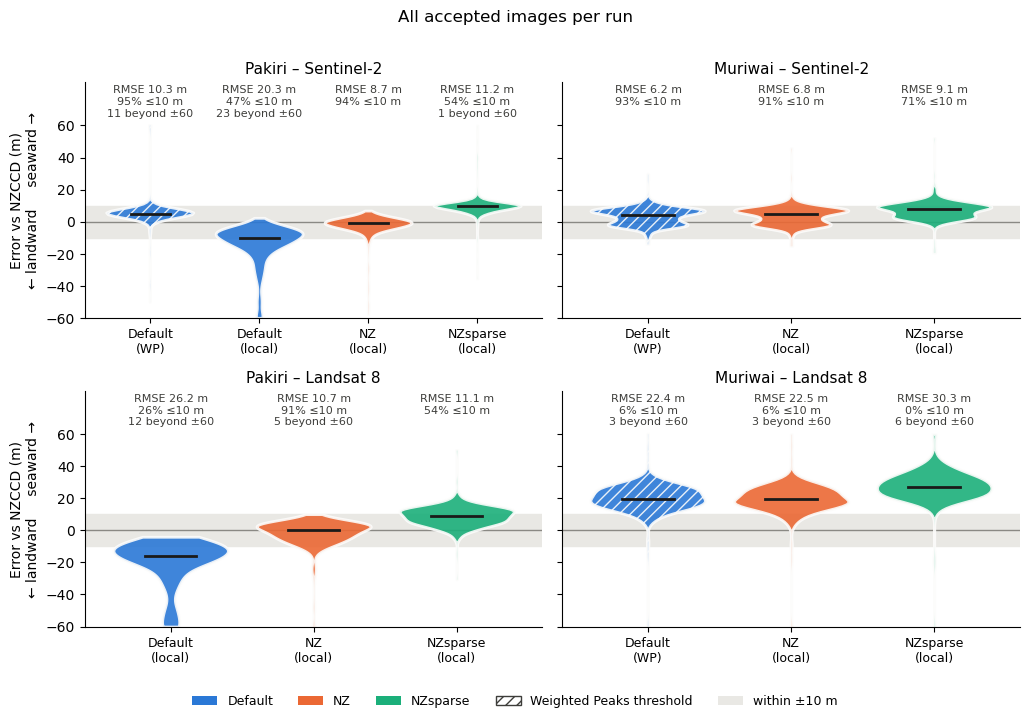


=== Images shared by every run (fairer comparison) ===
   site              run satname  images    n  median_bias_m  mean_bias_m  MAE_m  RMSE_m  within_10m_%
Muriwai     Default (WP)      L8       1  398           19.7         19.6   20.7    22.4           6.0
Muriwai     Default (WP)      S2       1  400            4.2          3.1    5.1     6.2          93.2
Muriwai       NZ (local)      L8       1  398           19.3         19.5   20.6    22.5           6.3
Muriwai       NZ (local)      S2       1  399            4.7          3.7    5.4     6.8          91.0
Muriwai NZsparse (local)      L8       1  398           27.3         27.2   28.6    30.3           0.3
Muriwai NZsparse (local)      S2       1  399            7.7          7.2    7.6     9.1          71.4
 Pakiri     Default (WP)      S2       4 1013            5.1          5.7    6.7    11.1          94.3
 Pakiri  Default (local)      L8       1  247          -15.7        -20.5   20.5    26.2          25.5
 Pakiri  Default 

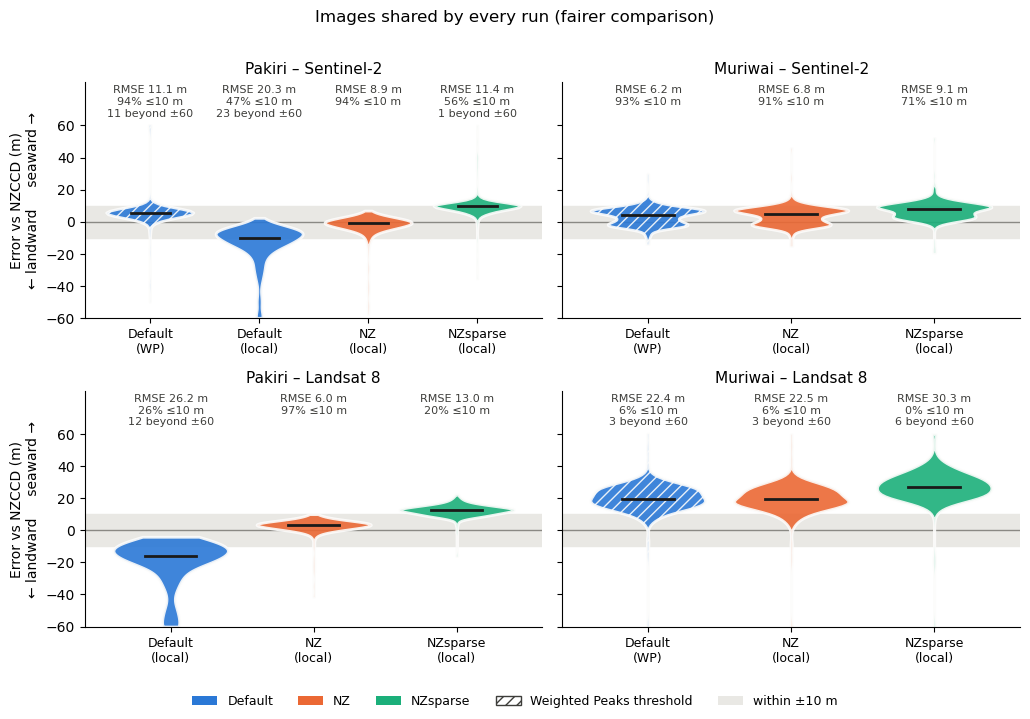


Saved to C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\NZCCD_comparison


In [3]:
# =====================================================================================
# Edge accuracy against NZCCD: every run, every image, every transect
# =====================================================================================
# For each site, transects are cast every SPACING m along the NZCCD line. Each satellite edge
# is intersected with each transect, giving a signed cross-shore error (m) from NZCCD:
#   positive = satellite edge SEAWARD of NZCCD, negative = landward.
# Outputs (in DATA/NZCCD_comparison/):
#   errors_all.csv          one row per site / run / satellite / image / transect
#   metrics_all.csv         RMSE, MAE, median bias, % within 10 m, for every run on all its images
#   metrics_common.csv      the same, using only images every run of that site and satellite shares
#   violins_all.png, violins_common.png
#   transects_<site>.shp    the transects (check the seaward end in QGIS; note IDs to exclude)
# Paths are set in the EDIT ME block, so it can run from any notebook. Needs only the saved veglines shapefiles.

import os, glob, time, numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from shapely.geometry import LineString, Point, MultiLineString, box
from shapely.ops import linemerge, unary_union

# ---------------- EDIT ME ----------------
DATA = r'C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data'

# NZCCD validation line for each site
NZCCD = {
    'Pakiri':  os.path.join(DATA, 'NZCCD_Validation_Lines', 'Pakiri', 'Pakiri_NZCCD_2023_clipped.shp'),
    'Muriwai': os.path.join(DATA, 'NZCCD_Validation_Lines', 'Muriwai', 'Muriwai_2022_NZCCD.shp'),
}
NZCCD_FILTER = None                         # optional, e.g. ('Proxy', 'Vegetation line') to keep one proxy only

# label -> run folder in Data/ (its *veglines*.shp is found automatically). Leave out runs you don't have.
RUNS = {
    'Pakiri': {
        'Default (WP)':     'Pakiri_2023_Validation_Vedgesat_default',
        'Default (local)':  'Pakiri_2023_Validation_local_thresh_default',
        'NZ (local)':       'Pakiri_2023_Validation_locthresh_NZ',
        'NZsparse (local)': 'Pakiri_2023_Validation_local_thresh_NZsparse',
    },
    'Muriwai': {
        'Default (WP)':     'Muriwai_2022_Validation_Vedgesat_default',
        'NZ (local)':       'Muriwai_2022_Validation_NZ',
        'NZsparse (local)': 'Muriwai_2022_Validation_localthresh_sparsemodel_NZsparse',
    },
}
# a point well out at sea for each site (lat, lon), only used to tell which way is seaward
SEA_POINT = {'Pakiri': (-36.15, 174.80), 'Muriwai': (-36.80, 174.25)}
EXCLUDE = {'Pakiri': [], 'Muriwai': []}     # transect ID ranges to drop, e.g. [(120, 160)] for a river mouth
KEEP = {'Pakiri': None, 'Muriwai': None}    # keep only this transect ID range, e.g. (0, 450); None = all
DATE_RANGE = None                           # optional ('2022-01-01', '2023-12-31')
SPACING = 10        # m between transects
HALF_LEN = 150      # m either side of NZCCD
WITHIN = 10         # m, the accuracy target
YLIM = 60           # m, violin plot y-limit (points beyond are counted, not hidden from the metrics)
# ------------------------------------------

OUT = os.path.join(DATA, 'NZCCD_comparison')
os.makedirs(OUT, exist_ok=True)

def find_veglines(run_folder):
    hits = [f for f in glob.glob(os.path.join(DATA, run_folder, '**', '*.shp'), recursive=True)
            if 'vegline' in os.path.basename(f).lower() and 'water' not in os.path.basename(f).lower()]
    if not hits:
        raise FileNotFoundError(f'No veglines shapefile under {os.path.join(DATA, run_folder)}')
    f = sorted(hits, key=len)[0]
    print(f'  {run_folder}: {os.path.basename(f)}')
    return short_path(f)

def short_path(f):
    '''Paths over Windows' 260-character limit can't be opened directly; use the 8.3 short name
    (e.g. MURIWA~1.SHP) instead.'''
    if os.name == 'nt' and len(f) > 240:
        import ctypes
        buf = ctypes.create_unicode_buffer(1024)
        if ctypes.windll.kernel32.GetShortPathNameW('\\\\?\\' + f, buf, 1024):
            s = buf.value
            return s[4:] if s.startswith('\\\\?\\') else s
    return f

def make_transects(nzccd, sea_xy):
    '''Transects every SPACING m along each NZCCD piece; unit normal n points seaward.'''
    merged = linemerge(unary_union(list(nzccd.geometry)))
    parts = list(merged.geoms) if isinstance(merged, MultiLineString) else [merged]
    rows, tid = [], 0
    for part in parts:
        if part.length < 4 * SPACING:
            continue
        for s in np.arange(SPACING, part.length - SPACING, SPACING):
            p = np.array(part.interpolate(s).coords[0])
            a, b = np.array(part.interpolate(s - SPACING).coords[0]), np.array(part.interpolate(s + SPACING).coords[0])
            t = (b - a) / np.linalg.norm(b - a)
            n = np.array([-t[1], t[0]])
            if np.linalg.norm(p + n * HALF_LEN - sea_xy) > np.linalg.norm(p - n * HALF_LEN - sea_xy):
                n = -n
            rows.append({'TransectID': tid, 'px': p[0], 'py': p[1], 'nx': n[0], 'ny': n[1],
                         'geometry': LineString([p - n * HALF_LEN, p + n * HALF_LEN])})   # landward -> seaward
            tid += 1
    return rows

def chunks(geom, n=50):
    '''Split an edge into pieces of n vertices, so each transect is only tested against nearby pieces.'''
    out = []
    for p in getattr(geom, 'geoms', [geom]):
        if p.geom_type != 'LineString':
            continue
        c = np.asarray(p.coords)
        for i in range(0, len(c) - 1, n):
            if len(c[i:i + n + 1]) >= 2:
                out.append(LineString(c[i:i + n + 1]))
    return out

def signed_offsets(line, T):
    '''Median signed distance (m, + seaward) from NZCCD where an edge crosses each transect.'''
    ch = chunks(line)
    if not ch:
        return {}
    tree = gpd.GeoSeries(ch).sindex
    out = {}
    for tid, tr, px, py, nx, ny in zip(T.TransectID, T.geometry, T.px, T.py, T.nx, T.ny):
        pts = []
        for j in tree.query(tr, predicate='intersects'):
            x = tr.intersection(ch[j])
            pts += [g for g in getattr(x, 'geoms', [x]) if g.geom_type == 'Point']
        if pts:
            out[int(tid)] = float(np.median([(q.x - px) * nx + (q.y - py) * ny for q in pts]))
    return out

records = []
for site, runs in RUNS.items():
    lines = {lab: gpd.read_file(find_veglines(sn)) for lab, sn in runs.items()}
    crs = 'EPSG:2193'                      # NZTM, metres (edges and NZCCD are reprojected to it)
    print(f'  edge files are in {next(iter(lines.values())).crs}; working in {crs}', flush=True)
    lines = {lab: g.to_crs(crs) for lab, g in lines.items()}
    for lab, g in lines.items():
        print(f'{site:8s} {lab:17s} {len(g):4d} edges   {sorted(g.satname.unique())}')
    b = np.array([g.total_bounds for g in lines.values()])          # study area = bounding box of all edges + 300 m
    extent = box(b[:, 0].min() - 300, b[:, 1].min() - 300, b[:, 2].max() + 300, b[:, 3].max() + 300)

    t0 = time.time(); print(f'  reading NZCCD...', flush=True)
    nz = gpd.read_file(NZCCD[site])
    print(f'  NZCCD: {len(nz)} features, {nz.crs}, {sum(len(g.coords) if g.geom_type == "LineString" else sum(len(p.coords) for p in g.geoms) for g in nz.geometry if g is not None)} vertices', flush=True)
    nz = nz.to_crs(crs)
    if NZCCD_FILTER:
        nz = nz[nz[NZCCD_FILTER[0]] == NZCCD_FILTER[1]]
    nz = gpd.clip(nz, extent)
    print(f'  clipped NZCCD: {nz.length.sum()/1000:.1f} km; building transects...', flush=True)
    nz = nz[nz.geometry.notna() & ~nz.geometry.is_empty]
    sea = gpd.GeoSeries([Point(SEA_POINT[site][1], SEA_POINT[site][0])], crs=4326).to_crs(crs).iloc[0]
    T = gpd.GeoDataFrame(make_transects(nz, np.array(sea.coords[0])), crs=crs)
    if KEEP.get(site):
        T = T[T.TransectID.between(*KEEP[site])]
    for a, b in EXCLUDE.get(site, []):
        T = T[~T.TransectID.between(a, b)]
    T = T.reset_index(drop=True)
    T.to_file(os.path.join(OUT, f'transects_{site}.shp'))
    print(f'{site}: {len(T)} transects along {nz.length.sum()/1000:.1f} km of NZCCD; '
          f'sea point {sea.distance(nz.unary_union)/1000:.1f} km offshore')

    print(f'  intersecting edges with transects...', flush=True)
    for lab, g in lines.items():
        print(f'    {lab} ({len(g)} edges)', flush=True)
        if DATE_RANGE:
            g = g[(g.dates.astype(str) >= DATE_RANGE[0]) & (g.dates.astype(str) <= DATE_RANGE[1])]
        for _, r in g.iterrows():
            if r.geometry is None or r.geometry.is_empty:
                continue
            for tid, e in signed_offsets(r.geometry, T).items():
                records.append({'site': site, 'run': lab, 'satname': r.satname,
                                'date': str(r.dates)[:10], 'TransectID': tid, 'error_m': e})

E = pd.DataFrame(records)
# one value per run / image / transect (several edges on one date are averaged)
E = E.groupby(['site', 'run', 'satname', 'date', 'TransectID'], as_index=False)['error_m'].median()
E.to_csv(os.path.join(OUT, 'errors_all.csv'), index=False)

def common_only(E):
    keep = []
    for (site, sat), g in E.groupby(['site', 'satname']):
        shared = set.intersection(*[set(gg.date) for _, gg in g.groupby('run')])
        keep.append(g[g.date.isin(shared)])
    return pd.concat(keep) if keep else E.iloc[0:0]

def metrics(E):
    rows = []
    for (site, run, sat), g in E.groupby(['site', 'run', 'satname']):
        e = g.error_m.values
        rows.append({'site': site, 'run': run, 'satname': sat, 'images': g.date.nunique(), 'n': len(e),
                     'median_bias_m': np.median(e), 'mean_bias_m': e.mean(), 'MAE_m': np.abs(e).mean(),
                     'RMSE_m': np.sqrt(np.mean(e**2)), f'within_{WITHIN}m_%': 100 * np.mean(np.abs(e) <= WITHIN)})
    return pd.DataFrame(rows).round(1)

# ---------------- violins ----------------
ORDER = ['Default (WP)', 'Default (local)', 'NZ (local)', 'NZsparse (local)']
COLOUR = {'Default': '#2a78d6', 'NZ': '#eb6834', 'NZsparse': '#1baf7a'}   # one colour per classifier
SATS = [s for s in ['S2', 'L8', 'L9', 'L7', 'L5'] if s in set(E.satname)]
SITES = list(RUNS)

def violins(E, M, fname, title):
    fig, axes = plt.subplots(len(SATS), len(SITES), figsize=(5.2 * len(SITES), 3.6 * len(SATS)),
                             squeeze=False, sharey=True)
    for i, sat in enumerate(SATS):
        for j, site in enumerate(SITES):
            ax = axes[i, j]
            ax.axhspan(-WITHIN, WITHIN, color='#e9e8e4', zorder=0)
            ax.axhline(0, color='#8a8984', lw=1, zorder=1)
            runs = [r for r in ORDER if ((E.site == site) & (E.run == r) & (E.satname == sat)).any()]
            for k, run in enumerate(runs):
                e = E[(E.site == site) & (E.run == run) & (E.satname == sat)].error_m.values
                vp = ax.violinplot(np.clip(e, -YLIM, YLIM), positions=[k], widths=0.8,
                                   showextrema=False, showmedians=False)
                body = vp['bodies'][0]
                body.set_facecolor(COLOUR[run.split(' ')[0]]); body.set_edgecolor('#fcfcfb')
                body.set_linewidth(2); body.set_alpha(0.9)
                if '(WP)' in run:
                    body.set_hatch('///')
                ax.plot([k - 0.18, k + 0.18], [np.median(e)] * 2, color='#1a1a19', lw=2, zorder=3)
                m = M[(M.site == site) & (M.run == run) & (M.satname == sat)].iloc[0]
                out = int(np.sum(np.abs(e) > YLIM))
                ax.text(k, YLIM * 1.42, f'RMSE {m.RMSE_m:.1f} m\n{m[f"within_{WITHIN}m_%"]:.0f}% ≤{WITHIN} m'
                        + (f'\n{out} beyond ±{YLIM}' if out else ''),
                        ha='center', va='top', fontsize=8, color='#3d3d3a')
            ax.set_xticks(range(len(runs)))
            ax.set_xticklabels([r.replace(' (', '\n(') for r in runs], fontsize=9)
            ax.set_xlim(-0.6, max(len(runs), 1) - 0.4)
            ax.set_ylim(-YLIM, YLIM * 1.45)                  # headroom above the violins for the labels
            ax.set_yticks(np.arange(-YLIM, YLIM + 1, 20))
            ax.set_title(f'{site} – {"Sentinel-2" if sat == "S2" else "Landsat " + sat[1]}', fontsize=11)
            for sp in ['top', 'right']:
                ax.spines[sp].set_visible(False)
            if j == 0:
                ax.set_ylabel('Error vs NZCCD (m)\n← landward     seaward →')
    handles = [Patch(facecolor=c, label=l) for l, c in COLOUR.items()] + \
              [Patch(facecolor='white', edgecolor='#3d3d3a', hatch='///', label='Weighted Peaks threshold'),
               Patch(facecolor='#e9e8e4', label=f'within ±{WITHIN} m')]
    fig.legend(handles=handles, loc='lower center', ncol=len(handles), frameon=False, fontsize=9)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout(rect=[0, 0.05, 1, 0.97])
    fig.savefig(os.path.join(OUT, fname), dpi=200)
    plt.show()

for tag, data, title in [('all', E, 'All accepted images per run'),
                         ('common', common_only(E), 'Images shared by every run (fairer comparison)')]:
    M = metrics(data)
    M.to_csv(os.path.join(OUT, f'metrics_{tag}.csv'), index=False)
    print(f'\n=== {title} ===')
    print(M.to_string(index=False))
    if len(data):
        violins(data, M, f'violins_{tag}.png', title)
print(f'\nSaved to {OUT}')

In [147]:
# ==== NIR resolution test ====
# Does coarse (30 m) NIR alone shift the edge seaward? Uses one Sentinel-2 image from this run,
# draws the edge from its native 10 m NIR and from NIR degraded to 30 m (then bilinearly resampled
# back to 10 m, as VedgeSat does for Landsat NIR), and measures the shift between the two edges.
# Same image, same georeference, same classification: any shift comes from the NIR resolution.
# Run after the driver's settings and reference-line cells (metadata, settings, polygon, dates set).
import os, numpy as np, ee, joblib
from skimage import transform, measure
from scipy import ndimage, spatial
from Toolshed import Image_Processing, VegetationLine, Toolbox

TEST_DATE = '2022-02-27'      # a clear Sentinel-2 date in this run's metadata (UTC date)

md = metadata['S2']
k = md['dates'].index(TEST_DATE)                       # first S2 image on that date
imgs = [ee.Image(f) for f in md['filenames']]
pixel_size, clf_model, ImgColl, init_georef = Image_Processing.InitialiseImgs(metadata, settings, 'S2', imgs)
ids = [f['id'] for f in ImgColl.getInfo()['features']]  # InitialiseImgs may drop very cloudy images
fn = ids.index(md['filenames'][k])
dl = [md['dates'][md['filenames'].index(i)] for i in ids]
skipped = {'cloudy': [], 'empty_poor': [], 'missing_mask': []}
im_ms, georef, cloud_mask, im_extra, im_QA, im_nodata, acqtime = Image_Processing.preprocess_single(
    ImgColl, init_georef, fn, dl, ids, 'S2', settings, polygon, dates, skipped)
assert im_ms is not None, f'Image skipped: {skipped}'
print(f'Image: {ids[fn]}   classifier: {clf_model}')

# classify (native bands) and build the reference-line buffer, as extract_veglines does
clf = joblib.load(os.path.join(os.getcwd(), 'Classification', 'models', clf_model))
min_beach = np.ceil(settings['min_beach_area'] / pixel_size**2)
im_classif, im_labels = VegetationLine.classify_image_NN(im_ms, im_extra, cloud_mask, min_beach, clf)
im_ref_buffer = VegetationLine.BufferShoreline(settings, settings['reference_shoreline'], georef, cloud_mask)

# crop to a multiple of 3 pixels (bottom/right only, so the georeference is unchanged)
r, c = (im_ms.shape[0] // 3) * 3, (im_ms.shape[1] // 3) * 3
im_ms, cloud_mask, im_labels, im_ref_buffer = im_ms[:r, :c], cloud_mask[:r, :c], im_labels[:r, :c], im_ref_buffer[:r, :c]

red, nir = im_ms[:, :, 2], im_ms[:, :, 3]
nir30 = transform.downscale_local_mean(nir, (3, 3))                                   # 30 m pixels
nir_blur = transform.resize(nir30, (r, c), order=1, preserve_range=True, mode='edge')  # back to 10 m, bilinear

ndvi = Toolbox.nd_index(nir, red, cloud_mask)
ndvi_blur = Toolbox.nd_index(nir_blur, red, cloud_mask)

np.random.seed(0)   # ClipIndexVec subsamples at random
cont_orig, t_orig = VegetationLine.FindShoreContours_WP(ndvi, im_labels, cloud_mask, im_ref_buffer)
np.random.seed(0)
cont_wp_blur, t_blur = VegetationLine.FindShoreContours_WP(ndvi_blur, im_labels, cloud_mask, im_ref_buffer)

def contours_at(nd, t):
    b = nd.copy(); b[~im_ref_buffer] = np.nan
    return VegetationLine.process_contours(measure.find_contours(b, t))

cont_same_t = contours_at(ndvi_blur, t_orig)

def long_points(conts):
    keep = [cc for cc in conts if np.sum(np.linalg.norm(np.diff(cc, axis=0), axis=1)) * pixel_size >= settings['min_length_sl']]
    return np.vstack(keep) if keep else np.empty((0, 2))

def offset(conts, max_m=60):
    '''Signed distance (m) from the native-NIR edge to each point of another edge;
    positive = on the non-vegetation (seaward) side of the native-NIR edge.'''
    ref, pts = long_points(cont_orig), long_points(conts)
    d, _ = spatial.cKDTree(ref).query(pts)
    side = ndimage.map_coordinates(ndvi, pts.T, order=1, mode='nearest') < t_orig
    s = np.where(side, d, -d) * pixel_size
    return s[np.abs(s) <= max_m]          # ignore points with no counterpart edge nearby

print(f'\nThresholds: native NIR {t_orig:.3f}   30 m NIR (Weighted Peaks recomputed) {t_blur:.3f}')
for name, conts in [('30 m NIR, same threshold', cont_same_t), ('30 m NIR, Weighted Peaks recomputed', cont_wp_blur)]:
    s = offset(conts)
    print(f'{name:38s} median {np.median(s):+6.1f} m   mean {s.mean():+6.1f} m   '
          f'seaward {100*np.mean(s > 0):4.0f}%   points {len(s)}')

# save the three edges for QGIS
out = os.path.join(settings['inputs']['filepath'], settings['inputs']['sitename'])
for name, conts in [('nir10', cont_orig), ('nir30_sameT', cont_same_t), ('nir30_WP', cont_wp_blur)]:
    lines, _, _ = VegetationLine.ProcessShoreline(conts, cloud_mask, georef, settings['projection_epsg'], settings)
    lines.to_file(os.path.join(out, f'NIRtest_{TEST_DATE}_{name}.shp'))
print(f'\nEdges saved to {out} (NIRtest_*.shp)')

Using initial georef: [247260.0, 10, 0, 5616480.0, 0, -10]
Image: COPERNICUS/S2_HARMONIZED/20220227T222551_20220227T222547_T59HQS   classifier: MLPClassifier_Veg_L5L8S2.pkl

Thresholds: native NIR 0.078   30 m NIR (Weighted Peaks recomputed) 0.054
30 m NIR, same threshold               median   +8.5 m   mean   +9.1 m   seaward   92%   points 970
30 m NIR, Weighted Peaks recomputed    median  +10.2 m   mean  +11.1 m   seaward   97%   points 966

Edges saved to C:\Users\bmcl980\OneDrive - The University of Auckland\Postgrad Papers\Project\COASTGUARD\COASTGUARD-master\Data\SouthTaranakiBight_2022_Validation_vedgesat_default (NIRtest_*.shp)


In [148]:
print('\nShift vs threshold (same image):')
for t in np.arange(0.05, 0.45, 0.05):
    cont_a = contours_at(ndvi, t)
    cont_b = contours_at(ndvi_blur, t)
    ref, pts = long_points(cont_a), long_points(cont_b)
    if len(ref) == 0 or len(pts) == 0:
        continue
    d, _ = spatial.cKDTree(ref).query(pts)
    side = ndimage.map_coordinates(ndvi, pts.T, order=1, mode='nearest') < t
    s = np.where(side, d, -d) * pixel_size
    s = s[np.abs(s) <= 60]
    print(f'  threshold {t:.2f}: median {np.median(s):+5.1f} m   seaward {100*np.mean(s > 0):3.0f}%')


Shift vs threshold (same image):
  threshold 0.05: median  +7.8 m   seaward  91%
  threshold 0.10: median  +8.1 m   seaward  92%
  threshold 0.15: median  +7.7 m   seaward  91%
  threshold 0.20: median  +7.3 m   seaward  89%
  threshold 0.25: median  +7.2 m   seaward  88%
  threshold 0.30: median  +7.3 m   seaward  84%
  threshold 0.35: median  +6.9 m   seaward  81%
  threshold 0.40: median  +5.8 m   seaward  78%


In [149]:
red30 = transform.downscale_local_mean(red, (3, 3))
red_blur = transform.resize(red30, (r, c), order=1, preserve_range=True, mode='edge')
ndvi_both = Toolbox.nd_index(nir_blur, red_blur, cloud_mask)

print('\nBoth bands at 30 m (matched resolution):')
for t in np.arange(0.05, 0.45, 0.05):
    pts, ref = long_points(contours_at(ndvi_both, t)), long_points(contours_at(ndvi, t))
    if len(ref) == 0 or len(pts) == 0:
        continue
    d, _ = spatial.cKDTree(ref).query(pts)
    side = ndimage.map_coordinates(ndvi, pts.T, order=1, mode='nearest') < t
    s = np.where(side, d, -d) * pixel_size
    s = s[np.abs(s) <= 60]
    print(f'  threshold {t:.2f}: median {np.median(s):+5.1f} m   seaward {100*np.mean(s > 0):3.0f}%')


Both bands at 30 m (matched resolution):
  threshold 0.05: median  +1.8 m   seaward  71%
  threshold 0.10: median  +2.8 m   seaward  79%
  threshold 0.15: median  +3.1 m   seaward  80%
  threshold 0.20: median  +3.2 m   seaward  81%
  threshold 0.25: median  +3.1 m   seaward  79%
  threshold 0.30: median  +3.1 m   seaward  73%
  threshold 0.35: median  +2.8 m   seaward  69%
  threshold 0.40: median  +2.3 m   seaward  64%
